In [ ]:
from google.colab import drive

!pip install scikit-learn==1.6.1
!pip install xgboost==3.2.0
!pip install optuna==4.8.0
!pip install openpyxl==3.1.5

drive.mount('/content/drive')

Mounted at /content/drive


# Lasso Classifier (LRC)

In [ ]:
import json
import os
import numpy as np
import optuna
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import  roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import joblib

def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()

    use_cat = [c for c in cat_cols if c in X_train_raw.columns]

    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)

    X_train_oh = pd.get_dummies(
        X_train_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = pd.get_dummies(
        X_test_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)

    X_train_oh = X_train_oh.astype(np.float32)
    X_test_oh = X_test_oh.astype(np.float32)

    return X_train_oh, X_test_oh


def save_results(rows, path):
    df_res = pd.DataFrame(rows)
    df_res = df_res.drop_duplicates(
        subset=["dataName", "seed","TW", "outer_fold"],
        keep="last"
    )
    df_res.to_excel(path, index=False)


def add_rate_features(df, tws):
    """Express count features per second: fixRate_{TW}, blinkRate_{TW}.
    TW 0 (hazard-visibility window) varies in length -> divide by its measured duration.
    TW 1-30 (pre-visibility windows) last exactly TW seconds -> divide by TW."""
    for tw in tws:
        if tw == 0:
            dur = pd.to_numeric(df[DUR_COL_TW0], errors="coerce")
            dur = dur.where(dur > 0)
        else:
            dur = float(tw)
        for count_col, rate_col in [("fixNumber", "fixRate"), ("blinkNumber", "blinkRate")]:
            df[f"{rate_col}_{tw}"] = pd.to_numeric(df[f"{count_col}_{tw}"], errors="coerce") / dur
    return df


# ---- Paths ----
# REV_DIR: repository root (this notebook sits in analysis/).
# In Google Colab, mount Drive first and set REV_DIR to the folder
# containing data/ and analysis/, e.g.
#   REV_DIR = "/content/drive/MyDrive/<your-folder>"
REV_DIR = ".."
dataName   = os.path.join(REV_DIR, "data", "Data.xlsx")
SEEDS_PATH = os.path.join(REV_DIR, "analysis", "seeds.xlsx")
DUR_COL_TW0 = "epochDuration_0_x"

inner_seeds = pd.read_excel(SEEDS_PATH)

for rs in [
        3558,
        6687,
          6836,
          7862, 11033,
          13285, 22075, 22163, 23858,
        30690
          ]:

  # TW_comb = [[0,x] for x in range(1,31)]
  # twType = "combineTW"

  TW_comb = [[x] for x in range(1,31)]
  twType = "singleTW"


  for TWs in TW_comb:

    print(TWs)

    if len(TWs)>1:

      targetTW = TWs[1]

    else:
      targetTW = TWs[0]

    df = pd.read_excel(dataName)
    df = add_rate_features(df, TWs)

    BASE_DIR = os.path.join(REV_DIR, "results", "LRC")
    os.makedirs(BASE_DIR, exist_ok=True)

    results_path = os.path.join(BASE_DIR, f"LRC_{twType}_rate.xlsx")
    modelDirectory = f"LRC_model_{twType}_rate"

    if os.path.exists(results_path):
        results_df = pd.read_excel(results_path)
        results_rows = results_df.to_dict('records')
        print(f"Resuming from existing file. Found {len(results_rows)} previous runs.")
    else:
        results_df = pd.DataFrame(columns=["seed", "TW"])
        results_rows = []

    if not results_df.empty:
        existing = (
            (results_df["seed"] == rs) &
            (results_df["TW"] == targetTW)
        )

        if existing.any():
            print(f"Skipping rs={rs}, targetTW={targetTW} because it already exists.")
            continue


    print(f"Running rs={rs}, targetTW={targetTW}")


    # Parameter
    outer_splits, inner_splits, n_trials = 5, 4, 100

    target_col = "RT"

    cat_names = ["Gender", "automation", "eventType"]

    TW_list = TWs

    feature_templates = [
        "Age",
        "License",
        "Mileage",
        "Gender",
        "automation", "eventType",
        "visibleSpeed",

        "pdMean_{TW}", "pdSd_{TW}",
        "blinkRate_{TW}",
        "avgBlinkDuration_{TW}",

        "fixRate_{TW}",
        "avgFixDuration_{TW}",

        "fixTE_{TW}", "fixSE_{TW}",
        "FixDisperX_{TW}", "FixDisperY_{TW}",
        "FixDisperE_{TW}",
        "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",

    ]

    feature_cols = []
    for c in feature_templates:
        feature_cols.extend([c.format(TW=tw) for tw in TW_list] if "{TW}" in c else [c])

    cont_names = [c for c in feature_cols if c not in cat_names]


    print(f'len(df)={len(df)}')

    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
    df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

    df["rt85_by_event"] = df.groupby("eventType")[target_col].transform(lambda x: x.quantile(0.85))
    df["RT85_cls"] = (df[target_col] >= df["rt85_by_event"]).astype(int)

    print(df[["eventType", "rt85_by_event"]].drop_duplicates().sort_values("eventType"))

    tww_cols = [f"perValid_{i}" for i in range(31)]

    pervalid_mean = df[tww_cols].mean(axis=1)

    abandon_mask = pervalid_mean < 74.5
    keep_mask = ~abandon_mask

    df = df[keep_mask].copy()

    X = df[feature_cols].copy()
    y = df["RT85_cls"].values.astype(int)

    groups = df["subNumber"].values

    y_strat = y.copy()


    outer_cv = StratifiedGroupKFold(
        n_splits=outer_splits,
        shuffle=True,
        random_state=rs
    )

    outer_AUC = []
    outer_best_params = []

    oof_fold = np.full(len(y), -1, dtype=int)
    oof_proba = np.full(len(y), np.nan)

    fold_rows = []

    for outer_fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y_strat, groups), start=1):


        X_out_train = X.iloc[train_idx].copy()
        y_out_train = y[train_idx]
        groups_out_tr = groups[train_idx]

        X_out_test = X.iloc[test_idx].copy()
        y_out_test = y[test_idx]

        print(f"\n=== Outer fold {outer_fold}/{outer_splits} ===")

        print("Class counts:")
        print(pd.Series(y_out_test).value_counts().sort_index())
        print("Class proportions:")
        print(pd.Series(y_out_test).value_counts(normalize=True).sort_index())

        to_drop_fold = []

        for col in cat_names:
            if col in X_out_train.columns:
                print(f"Fold {outer_fold} - {col} levels in train:",
                      X_out_train[col].unique())


        fold_vars = [c for c in feature_cols if c not in to_drop_fold]

        print(f"  > [TW-Filter] Dropped {len(to_drop_fold)} smaller windows. {len(fold_vars)} variables remain.")

        current_vars = fold_vars[:]
        best_vars = current_vars

        print(f"\nOuter fold {outer_fold}")
        print("Inner class counts:")
        print(pd.Series(y_out_train.copy()).value_counts().sort_index())
        print("Inner class proportions:")
        print(pd.Series(y_out_train.copy()).value_counts(normalize=True).sort_index())

        X_out_train_oh, X_out_test_oh = fit_outer_onehot(
            X_out_train[best_vars],
            X_out_test[best_vars],
            cat_names
        )
        lookup = inner_seeds[
            (inner_seeds["outer_seed"] == rs) &
            (inner_seeds["outer_fold_idx"] == (outer_fold - 1))
        ]

        if lookup.empty:
            raise ValueError(
                f"No accepted inner seed found for outer_seed={rs}, outer_fold_idx={outer_fold - 1}"
            )

        if len(lookup) > 1:
            raise ValueError(
                f"Multiple matching inner seeds found for outer_seed={rs}, outer_fold_idx={outer_fold - 1}"
            )

        selected_inner_seed = int(lookup["inner_seed"].iloc[0])

        print(
            f"Using accepted_inner_seed={selected_inner_seed} "
            f"for outer_seed={rs}, outer_fold={outer_fold}"
        )

        print("\nSelected inner seed:")
        print(selected_inner_seed)


        def objective(trial):

            C = trial.suggest_float("C", 1e-4, 10.0, log=True)

            cv_opt = StratifiedGroupKFold(
                n_splits=inner_splits,
                shuffle=True,
                random_state=selected_inner_seed
            )

            inner_scores = []

            for t_i, v_i in cv_opt.split(X_out_train_oh, y_out_train, groups_out_tr):


              X_tr = X_out_train_oh.iloc[t_i].copy()
              X_val = X_out_train_oh.iloc[v_i].copy()
              y_tr = y_out_train[t_i]
              y_val = y_out_train[v_i]

              # Impute (fit ONLY on train fold)
              imputer = SimpleImputer(strategy="median")
              X_tr = pd.DataFrame(
                  imputer.fit_transform(X_tr),
                  columns=X_tr.columns,
                  index=X_tr.index
              )
              X_val = pd.DataFrame(
                  imputer.transform(X_val),
                  columns=X_val.columns,
                  index=X_val.index
              )

              # Scale (fit ONLY on train fold)
              scaler = StandardScaler()
              X_tr = pd.DataFrame(
                  scaler.fit_transform(X_tr),
                  columns=X_tr.columns,
                  index=X_tr.index
              )
              X_val = pd.DataFrame(
                  scaler.transform(X_val),
                  columns=X_val.columns,
                  index=X_val.index
              )

              # Model
              model = LogisticRegression(
                  penalty="l1",
                  solver="liblinear",
                  C=C,
                  max_iter=1000,
                  class_weight="balanced",
                  random_state=42,
              )

              model.fit(X_tr, y_tr)

              y_prob = model.predict_proba(X_val)[:, 1]
              inner_scores.append(roc_auc_score(y_val, y_prob))

            return float(np.mean(inner_scores))


        sampler = optuna.samplers.TPESampler(seed=42)
        study = optuna.create_study(direction="maximize", sampler=sampler)
        study.optimize(objective, n_trials=n_trials)

        imputer = SimpleImputer(strategy="median")
        X_out_train_oh = pd.DataFrame(
            imputer.fit_transform(X_out_train_oh),
            columns=X_out_train_oh.columns,
            index=X_out_train_oh.index
        )
        X_out_test_oh = pd.DataFrame(
            imputer.transform(X_out_test_oh),
            columns=X_out_test_oh.columns,
            index=X_out_test_oh.index
        )

        scaler = StandardScaler()
        X_out_train_oh = pd.DataFrame(
            scaler.fit_transform(X_out_train_oh),
            columns=X_out_train_oh.columns,
            index=X_out_train_oh.index
        )
        X_out_test_oh = pd.DataFrame(
            scaler.transform(X_out_test_oh),
            columns=X_out_test_oh.columns,
            index=X_out_test_oh.index
        )
        final_p = {
            "penalty": "l1",
            "solver": "liblinear",
            "C": study.best_params["C"],
            "max_iter": 1000,
            "class_weight": "balanced",
            "random_state": 42,
        }

        # Final model
        final_model = LogisticRegression(
            **final_p
        )

        final_model.fit(X_out_train_oh, y_out_train)
        outer_best_params.append(final_p)


        y_prob = final_model.predict_proba(X_out_test_oh)[:, 1]

        oof_fold[test_idx] = outer_fold
        oof_proba[test_idx] = y_prob


        if np.unique(y_out_test).size == 2:
            outer_auc = roc_auc_score(y_out_test, y_prob)
        else:
            outer_auc = np.nan


        outer_AUC.append(outer_auc)
        event_auc_dict = {}
        event_test = df.iloc[test_idx]["eventType"].values

        for ev in np.unique(event_test):
            mask = event_test == ev

            y_true_ev = y_out_test[mask]
            y_prob_ev = y_prob[mask]

            # AUC
            if np.unique(y_true_ev).size == 2:
                ev_auc = roc_auc_score(y_true_ev, y_prob_ev)
            else:
                ev_auc = np.nan

            event_auc_dict[ev] = ev_auc


        fold_row = {
            "dataName": dataName,
            "seed": rs,
            "TW": float(targetTW),
            "outer_fold": int(outer_fold),
            "AUC": float(outer_auc),
            "n_test": int(len(test_idx)),
            "n_pos_test": int(np.sum(y_out_test == 1)),
            "n_neg_test": int(np.sum(y_out_test == 0)),
        }

        for ev, ev_auc in event_auc_dict.items():
            fold_row[f"AUC_event_{ev}"] = ev_auc

        fold_rows.append(fold_row)


        print(f"{dataName} | Outer fold {outer_fold}/5 AUC = {outer_auc:.4f}")


        MODEL_DIR = os.path.join(BASE_DIR, modelDirectory)
        os.makedirs(MODEL_DIR, exist_ok=True)

        model_path = os.path.join(MODEL_DIR, f"lr_seed_{rs:02d}_TW_{targetTW:02d}_outerfold_{outer_fold:02d}.joblib")
        joblib.dump(
            {
                "model": final_model,
                "imputer": imputer,
                "scaler": scaler,
                "feature_names": list(X_out_train_oh.columns)
            },
            model_path
        )
        print("Saved model:", model_path)


        meta = {
            "seed": rs,
            "TW": targetTW,
            "outer_fold": outer_fold,
            "best_params": final_p,
            "best_score_inner_cv": study.best_value,
            "selected_features": best_vars
        }

        meta_path = model_path.replace(".joblib", "_meta.json")

        with open(meta_path, "w") as f:
            json.dump(meta, f, indent=4)

        print("Saved metadata:", meta_path)


    print(f"\n===== FINAL RESULTS SUMMARY =====")
    print(f"Mean AUC (Outer CV): {np.mean(outer_AUC):.4f} (+/- {np.std(outer_AUC):.4f})")

    results_rows.extend(fold_rows)

    summary_row = {
        "dataName": dataName,
        "seed": rs,
        "TW": float(targetTW),
        "outer_fold": "SUMMARY",
        "AUC": float(np.mean(outer_AUC)),
        "std_AUC": float(np.std(outer_AUC)),
    }

    results_rows.append(summary_row)

    save_results(results_rows, results_path)
    print(f"Updated results: {results_path}")

# LASSO Regressor (LR)

In [ ]:
import json
import os
import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
import joblib

def save_results(rows, path):
    df_res = pd.DataFrame(rows)

    df_res = df_res.drop_duplicates(
        subset=["dataName", "seed","TW", "outer_fold"],
        keep="last"
    )
    df_res.to_excel(path, index=False)

def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):

    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()

    use_cat = [c for c in cat_cols if c in X_train_raw.columns]

    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)

    X_train_oh = pd.get_dummies(
        X_train_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = pd.get_dummies(
        X_test_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)

    X_train_oh = X_train_oh.astype(np.float32)
    X_test_oh = X_test_oh.astype(np.float32)

    return X_train_oh, X_test_oh


def add_rate_features(df, tws):
    """Express count features per second: fixRate_{TW}, blinkRate_{TW}.
    TW 0 (hazard-visibility window) varies in length -> divide by its measured duration.
    TW 1-30 (pre-visibility windows) last exactly TW seconds -> divide by TW."""
    for tw in tws:
        if tw == 0:
            dur = pd.to_numeric(df[DUR_COL_TW0], errors="coerce")
            dur = dur.where(dur > 0)
        else:
            dur = float(tw)
        for count_col, rate_col in [("fixNumber", "fixRate"), ("blinkNumber", "blinkRate")]:
            df[f"{rate_col}_{tw}"] = pd.to_numeric(df[f"{count_col}_{tw}"], errors="coerce") / dur
    return df


# ---- Paths----
REV_DIR = ".."
dataName   = os.path.join(REV_DIR, "data", "Data.xlsx")
DUR_COL_TW0 = "epochDuration_0_x"

for rs in [
    261,452,285,966,
           786, 1423, 3789, 5602, 8741, 11905
            ]:

    TW_comb = [[0,x] for x in range(1,31)]
    twType = "combineTW"

    # TW_comb = [[x] for x in range(1,31)]
    # twType = "singleTW"

    for TWs in TW_comb:

      print(TWs)

      if len(TWs)>1:

        targetTW = TWs[1]

      else:
        targetTW = TWs[0]

      df = pd.read_excel(dataName)
      df = add_rate_features(df, TWs)

      BASE_DIR = os.path.join(REV_DIR, "results", "LRR")
      os.makedirs(BASE_DIR, exist_ok=True)

      results_path = os.path.join(BASE_DIR, f"LRR_{twType}_rate.xlsx")
      modelDirectory = f"LR_model_{twType}_rate"

      if os.path.exists(results_path):
            results_df = pd.read_excel(results_path)
            results_rows = results_df.to_dict('records')
            print(f"Resuming from existing file. Found {len(results_rows)} previous runs.")
      else:
            results_df = pd.DataFrame(columns=["seed", "TW"])
            results_rows = []


      outer_splits, inner_splits, n_trials = 5, 4, 100

      target_col = "RT"

      cat_names = ["Gender", "automation", "eventType"]

      TW_list = TWs

      feature_templates = [
          "Age",
          "License",
          "Mileage",
          "Gender",
          "automation", "eventType",
          "visibleSpeed",

          "pdMean_{TW}", "pdSd_{TW}",
          "blinkRate_{TW}",
          "avgBlinkDuration_{TW}",

          "fixRate_{TW}",

          "avgFixDuration_{TW}",

          "fixTE_{TW}", "fixSE_{TW}",
          "FixDisperX_{TW}", "FixDisperY_{TW}",
          "FixDisperE_{TW}",
          "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",

      ]

      feature_cols = []
      for c in feature_templates:
          feature_cols.extend([c.format(TW=tw) for tw in TW_list] if "{TW}" in c else [c])

      cont_names = [c for c in feature_cols if c not in cat_names]


      tww_cols = [f"perValid_{i}" for i in range(31)]

      pervalid_mean = df[tww_cols].mean(axis=1)

      abandon_mask = pervalid_mean < 74.5
      keep_mask = ~abandon_mask

      df = df[keep_mask].copy()

      X = df[feature_cols].copy()
      y = pd.to_numeric(df[target_col], errors="coerce").values.astype(float)
      groups = df["subNumber"].values

      outer_cv = GroupKFold(
          n_splits=outer_splits,
          shuffle=True,
          random_state=rs
      )

      outer_scores = []
      outer_RMSE = []
      oof_pred = np.full_like(y, fill_value=-1)
      oof_fold = np.full(len(y), -1, dtype=int)
      oof_proba = np.full(len(y), np.nan)


      outer_best_params = []
      outer_R2 = []
      fold_rows = []

      print(f'len(df)={len(df)}')

      for outer_fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y, groups), start=1):


          print(f"\n=== Outer fold {outer_fold}/{outer_splits} ===")

          X_out_train = X.iloc[train_idx].copy()
          y_out_train = y[train_idx]
          groups_out_tr = groups[train_idx]

          X_out_test = X.iloc[test_idx].copy()
          y_out_test = y[test_idx]

          to_drop_fold = []

          for col in cat_names:
              if col in X_out_train.columns:
                  print(f"Fold {outer_fold} - {col} levels in train:",
                        X_out_train[col].unique())


          fold_vars = [c for c in feature_cols if c not in to_drop_fold]

          print(f"  > [TW-Filter] Dropped {len(to_drop_fold)} smaller windows. {len(fold_vars)} variables remain.")

          current_vars = fold_vars[:]
          best_vars = current_vars

          X_out_train_oh, X_out_test_oh = fit_outer_onehot(
              X_out_train[best_vars],
              X_out_test[best_vars],
              cat_names
          )


          def objective(trial):

              alpha = trial.suggest_float("alpha", 1e-4, 10.0, log=True)
              cv_opt = GroupKFold(
                  n_splits=inner_splits,
                  shuffle=True,
                  random_state=123
              )
              scores = []

              for t_i, v_i in cv_opt.split(X_out_train_oh, y_out_train, groups_out_tr):


                X_tr = X_out_train_oh.iloc[t_i].copy()
                X_val = X_out_train_oh.iloc[v_i].copy()
                y_tr = y_out_train[t_i]
                y_val = y_out_train[v_i]

                imputer = SimpleImputer(strategy="median")
                X_tr = pd.DataFrame(
                    imputer.fit_transform(X_tr),
                    columns=X_tr.columns,
                    index=X_tr.index
                )
                X_val = pd.DataFrame(
                    imputer.transform(X_val),
                    columns=X_val.columns,
                    index=X_val.index
                )

                scaler = StandardScaler()
                X_tr = pd.DataFrame(
                    scaler.fit_transform(X_tr),
                    columns=X_tr.columns,
                    index=X_tr.index
                )
                X_val = pd.DataFrame(
                    scaler.transform(X_val),
                    columns=X_val.columns,
                    index=X_val.index
                )

                model = Lasso(
                  alpha=alpha,
                  max_iter=5000,
                  random_state=42
                )

                model.fit(X_tr, y_tr)

                y_pred = model.predict(X_val)

                scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))

              return float(np.mean(scores))


          sampler = optuna.samplers.TPESampler(seed=42)
          study = optuna.create_study(direction="minimize", sampler=sampler)
          study.optimize(objective, n_trials=n_trials)

          imputer = SimpleImputer(strategy="median")
          X_out_train_oh = pd.DataFrame(
              imputer.fit_transform(X_out_train_oh),
              columns=X_out_train_oh.columns,
              index=X_out_train_oh.index
          )
          X_out_test_oh = pd.DataFrame(
              imputer.transform(X_out_test_oh),
              columns=X_out_test_oh.columns,
              index=X_out_test_oh.index
          )

          scaler = StandardScaler()
          X_out_train_oh = pd.DataFrame(
              scaler.fit_transform(X_out_train_oh),
              columns=X_out_train_oh.columns,
              index=X_out_train_oh.index
          )
          X_out_test_oh = pd.DataFrame(
              scaler.transform(X_out_test_oh),
              columns=X_out_test_oh.columns,
              index=X_out_test_oh.index
          )

          final_p = {
              "alpha": study.best_params["alpha"],
              "max_iter": 5000,
              "random_state": 42
          }

          final_model = Lasso(
              **final_p
          )

          outer_best_params.append(final_p)

          final_model.fit(X_out_train_oh, y_out_train)
          y_pred = final_model.predict(X_out_test_oh)


          outer_rmse = np.sqrt(mean_squared_error(y_out_test, y_pred))

          r2   = r2_score(y_out_test, y_pred)

          fold_rows.append({
              "dataName": dataName,
              "seed": rs,
              "TW": float(targetTW),
              "outer_fold": int(outer_fold),
              "RMSE": float(outer_rmse),
              "R2": float(r2),
          })

          plt.figure(figsize=(5, 5))
          plt.scatter(y_out_test, y_pred, alpha=0.6)
          outer_R2.append(r2)

          outer_scores.append(outer_rmse)

          print(f"{dataName} | Outer fold {outer_fold}/5 RMSE = {outer_rmse:.4f} R2 = {r2:.4f}")

          lims = [
              min(y_out_test.min(), y_pred.min()),
              max(y_out_test.max(), y_pred.max())
          ]
          plt.plot(lims, lims)
          plt.xlim(lims)
          plt.ylim(lims)

          plt.xlabel("Observed")
          plt.ylabel("Predicted")
          plt.title(
              f"Outer fold {outer_fold}\n"
              f"RMSE = {outer_rmse:.3f}, R² = {r2:.3f}"
          )

          plt.tight_layout()
          plt.show()

          MODEL_DIR = os.path.join(BASE_DIR, modelDirectory)
          os.makedirs(MODEL_DIR, exist_ok=True)

          model_path = os.path.join(MODEL_DIR, f"lr_seed_{rs:02d}_TW_{targetTW:02d}_outerfold_{outer_fold:02d}.joblib")
          joblib.dump(
              {
                  "model": final_model,
                  "imputer": imputer,
                  "scaler": scaler,
                  "feature_names": list(X_out_train_oh.columns)
              },
              model_path
          )
          print("Saved model:", model_path)


          meta = {
              "seed": rs,
              "TW": targetTW,
              "outer_fold": outer_fold,
              "best_params": final_p,
              "best_score_inner_cv": study.best_value,
              "selected_features": best_vars
          }

          meta_path = model_path.replace(".joblib", "_meta.json")

          with open(meta_path, "w") as f:
              json.dump(meta, f, indent=4)

          print("Saved metadata:", meta_path)

      print(f"\n===== FINAL RESULTS SUMMARY =====")
      print(f"Mean RMSE (Outer CV): {np.mean(outer_scores):.4f} (+/- {np.std(outer_scores):.4f})")
      print(f"Mean R2 (Outer CV): {np.mean(outer_R2):.4f} (+/- {np.std(outer_R2):.4f})")


      results_rows.extend(fold_rows)

      summary_row = {
          "dataName": dataName,
          "seed": rs,
          "TW": float(targetTW),
          "outer_fold": "SUMMARY",
          "RMSE": float(np.mean(outer_scores)),
          "R2": float(np.mean(outer_R2)),
          "std_RMSE": float(np.std(outer_scores)),
          "std_R2": float(np.std(outer_R2)),
      }
      results_rows.append(summary_row)

      save_results(results_rows, results_path)
      print(f"Updated results: {results_path}")

# XGBoost Classifier (XGBC)

In [ ]:
import json
import os
import numpy as np
import pandas as pd
import optuna
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

def save_results(rows, path):
    df_res = pd.DataFrame(rows)
    df_res = df_res.drop_duplicates(
        subset=["dataName", "seed", "TW", "outer_fold"],
        keep="last"
    )
    df_res.to_excel(path, index=False)

def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df = test_df.copy()

    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col] = test_df[col].astype(dtype)

    return train_df, test_df


def add_rate_features(df, tws):
    """Express count features per second: fixRate_{TW}, blinkRate_{TW}.
    TW 0 (hazard-visibility window) varies in length -> divide by its measured duration.
    TW 1-30 (pre-visibility windows) last exactly TW seconds -> divide by TW."""
    for tw in tws:
        if tw == 0:
            dur = pd.to_numeric(df[DUR_COL_TW0], errors="coerce")
            dur = dur.where(dur > 0)
        else:
            dur = float(tw)
        for count_col, rate_col in [("fixNumber", "fixRate"), ("blinkNumber", "blinkRate")]:
            df[f"{rate_col}_{tw}"] = pd.to_numeric(df[f"{count_col}_{tw}"], errors="coerce") / dur
    return df


# ---- Paths----
REV_DIR = ".."
dataName   = os.path.join(REV_DIR, "data", "Data.xlsx")
SEEDS_PATH = os.path.join(REV_DIR, "analysis", "seeds.xlsx")
DUR_COL_TW0 = "epochDuration_0_x"

inner_seeds = pd.read_excel(SEEDS_PATH)


for rs in [
            3558,
            6687,6836,
            7862, 11033,
            13285,
            22075,
            22163,
            23858,
            30690
            ]:

    TW_comb = [[0,x] for x in range(1,31)]
    twType = "combineTW"

    # twType = "singleTW"
    # TW_comb = [[x] for x in range(1,31)]

    for TWs in TW_comb:

      print(TWs)

      if len(TWs)>1:

        targetTW = TWs[1]

      else:
        targetTW = TWs[0]


      df = pd.read_excel(dataName)
      df = add_rate_features(df, TWs)

      BASE_DIR = os.path.join(REV_DIR, "results2", "XGBC")
      os.makedirs(BASE_DIR, exist_ok=True)

      results_path = os.path.join(BASE_DIR, f"XGBC_{twType}_rate.xlsx")
      modelDirectory = f"XGB_model_{twType}_rate"

      if os.path.exists(results_path):
          results_df = pd.read_excel(results_path)
          results_rows = results_df.to_dict('records')
          print(f"Resuming from existing file. Found {len(results_rows)} previous runs.")
      else:
          results_df = pd.DataFrame(columns=["seed", "TW"])
          results_rows = []

      if not results_df.empty:
          existing = (
              (results_df["seed"] == rs) &
              (results_df["TW"] == targetTW)
          )

          if existing.any():
              print(f"Skipping rs={rs}, targetTW={targetTW} because it already exists.")
              continue

      print(f"Running rs={rs}, targetTW={targetTW}")

      outer_splits, inner_splits, n_trials = 5, 4, 100
      target_col = "RT"
      cat_names = ["Gender", "automation", "eventType"]
      TW_list = TWs
      feature_templates = [
          "Age",
          "License",
          "Mileage",
          "Gender",
          "automation", "eventType",
          "visibleSpeed",

          "pdMean_{TW}", "pdSd_{TW}",
          "blinkRate_{TW}",
          "avgBlinkDuration_{TW}",

          "fixRate_{TW}",
          "avgFixDuration_{TW}",


          "fixTE_{TW}", "fixSE_{TW}",
          "FixDisperX_{TW}", "FixDisperY_{TW}",
          "FixDisperE_{TW}",
          "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",

      ]

      feature_cols = []
      for c in feature_templates:
          feature_cols.extend([c.format(TW=tw) for tw in TW_list] if "{TW}" in c else [c])

      cont_names = [c for c in feature_cols if c not in cat_names]


      print(f'len(df)={len(df)}')

      df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
      df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

      df["rt85_by_event"] = df.groupby("eventType")[target_col].transform(lambda x: x.quantile(0.85))
      df["RT85_cls"] = (df[target_col] >= df["rt85_by_event"]).astype(int)

      print(df[["eventType", "rt85_by_event"]].drop_duplicates().sort_values("eventType"))

      tww_cols = [f"perValid_{i}" for i in range(31)]

      pervalid_mean = df[tww_cols].mean(axis=1)

      abandon_mask = pervalid_mean < 74.5
      keep_mask = ~abandon_mask

      df = df[keep_mask].copy()

      X = df[feature_cols].copy()
      y = df["RT85_cls"].values.astype(int)

      groups = df["subNumber"].values

      y_strat = y.copy()


      outer_cv = StratifiedGroupKFold(
          n_splits=outer_splits,
          shuffle=True,
          random_state=rs
      )

      outer_AUC = []
      outer_best_params = []
      fold_rows = []
      oof_fold = np.full(len(y), -1, dtype=int)
      oof_proba = np.full(len(y), np.nan)

      for outer_fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y_strat, groups), start=1):


          X_out_train = X.iloc[train_idx].copy()
          y_out_train = y[train_idx]
          groups_out_tr = groups[train_idx]

          X_out_test = X.iloc[test_idx].copy()
          y_out_test = y[test_idx]

          print(f"\n=== Outer fold {outer_fold}/{outer_splits} ===")

          print("Class counts:")
          print(pd.Series(y_out_test).value_counts().sort_index())
          print("Class proportions:")
          print(pd.Series(y_out_test).value_counts(normalize=True).sort_index())

          to_drop_fold = []

          for col in cat_names:
              if col in X_out_train.columns:
                  print(f"Fold {outer_fold} - {col} levels in train:",
                        X_out_train[col].unique())


          fold_vars = [c for c in feature_cols if c not in to_drop_fold]

          print(f"  > [TW-Filter] Dropped {len(to_drop_fold)} smaller windows. {len(fold_vars)} variables remain.")

          current_vars = fold_vars[:]
          best_vars = current_vars

          n_pos = np.sum(y_out_train == 1)
          n_neg = np.sum(y_out_train == 0)
          scale_pos_weight = n_neg / n_pos if n_pos > 0 else 1.0

          print(f"Scale pos weight: {scale_pos_weight}")

          print(f"\nOuter fold {outer_fold}")
          print("Inner class counts:")
          print(pd.Series(y_out_train.copy()).value_counts().sort_index())
          print("Inner class proportions:")
          print(pd.Series(y_out_train.copy()).value_counts(normalize=True).sort_index())

          X_out_train_oh, X_out_test_oh = ensure_categorical_dtype_from_train(
              X_out_train[best_vars],
              X_out_test[best_vars],
              cat_names
          )

          lookup = inner_seeds[
              (inner_seeds["outer_seed"] == rs) &
              (inner_seeds["outer_fold_idx"] == (outer_fold - 1))
          ]

          if lookup.empty:
              raise ValueError(
                  f"No accepted inner seed found for outer_seed={rs}, outer_fold_idx={outer_fold - 1}"
              )

          if len(lookup) > 1:
              raise ValueError(
                  f"Multiple matching inner seeds found for outer_seed={rs}, outer_fold_idx={outer_fold - 1}"
              )

          seed_col = "accepted_inner_seed" if "accepted_inner_seed" in lookup.columns else "inner_seed"
          selected_inner_seed = int(lookup[seed_col].iloc[0])

          print(
              f"Using accepted_inner_seed={selected_inner_seed} "
              f"for outer_seed={rs}, outer_fold={outer_fold}"
          )

          print("\nSelected inner seed:")
          print(selected_inner_seed)

          def objective(trial):

              p = {
                  "n_estimators": 200,

                  "max_depth": trial.suggest_int("max_depth", 2, 7),
                  "learning_rate": trial.suggest_float("learning_rate", 0.025, 0.3),

                  "gamma": trial.suggest_float("gamma", 0.0, 2.0),
                  "subsample": trial.suggest_float("subsample", 0.5, 1.0),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.25, 1.0),
                  "tree_method": "hist",
                  "random_state": 42,
                  "n_jobs": -1,
                  "enable_categorical": True,
                  "scale_pos_weight": scale_pos_weight,
                  "objective": "binary:logistic",
              }


              cv_opt = StratifiedGroupKFold(
                  n_splits=inner_splits,
                  shuffle=True,
                  random_state=selected_inner_seed
              )

              inner_scores=[]

              for t_i, v_i in cv_opt.split(X_out_train_oh, y_out_train, groups_out_tr):


                  X_tr_opt = X_out_train_oh.iloc[t_i].copy()
                  X_val_opt = X_out_train_oh.iloc[v_i].copy()

                  y_tr = y_out_train[t_i]
                  y_val = y_out_train[v_i]

                  m = XGBClassifier(**p)
                  m.fit(X_tr_opt, y_tr, verbose=False)

                  y_prob = m.predict_proba(X_val_opt)[:, 1]
                  inner_scores.append(roc_auc_score(y_val, y_prob))

              best_score = np.mean(inner_scores)

              return float(best_score)


          sampler = optuna.samplers.TPESampler(seed=42)
          study = optuna.create_study(direction="maximize", sampler=sampler)
          study.optimize(objective, n_trials=n_trials)

          final_p = {
              **study.best_params,
              "n_estimators": 200,
              "tree_method": "hist",
              "random_state": 42,
              "n_jobs": -1,
              "scale_pos_weight": scale_pos_weight,
              "objective": "binary:logistic",
              "enable_categorical": True,

          }

          final_model = XGBClassifier(**final_p)
          outer_best_params.append(final_p)

          final_model.fit(X_out_train_oh, y_out_train)

          y_prob = final_model.predict_proba(X_out_test_oh)[:, 1]

          oof_fold[test_idx] = outer_fold
          oof_proba[test_idx] = y_prob


          if np.unique(y_out_test).size == 2:
              outer_auc = roc_auc_score(y_out_test, y_prob)
          else:
              outer_auc = np.nan


          outer_AUC.append(outer_auc)

          event_auc_dict = {}
          event_test = df.iloc[test_idx]["eventType"].values

          for ev in np.unique(event_test):
              mask = event_test == ev

              y_true_ev = y_out_test[mask]
              y_prob_ev = y_prob[mask]

              if np.unique(y_true_ev).size == 2:
                  ev_auc = roc_auc_score(y_true_ev, y_prob_ev)
              else:
                  ev_auc = np.nan

              event_auc_dict[ev] = ev_auc

          fold_row = {
              "dataName": dataName,
              "seed": rs,
              "TW": float(targetTW),
              "outer_fold": int(outer_fold),
              "AUC": float(outer_auc),
              "n_test": int(len(test_idx)),
              "n_pos_test": int(np.sum(y_out_test == 1)),
              "n_neg_test": int(np.sum(y_out_test == 0)),
          }
          for ev, ev_auc in event_auc_dict.items():
              fold_row[f"AUC_event_{ev}"] = ev_auc
          fold_rows.append(fold_row)


          print(f"{dataName} | Outer fold {outer_fold}/5 AUC = {outer_auc:.4f}")


          MODEL_DIR = os.path.join(BASE_DIR, modelDirectory)
          os.makedirs(MODEL_DIR, exist_ok=True)

          model_path = os.path.join(MODEL_DIR, f"xgb_seed_{rs:02d}_TW_{targetTW:02d}_outerfold_{outer_fold:02d}.json")
          final_model.get_booster().save_model(model_path)
          print("Saved model:", model_path)


          meta = {
              "seed": rs,
              "TW": targetTW,
              "outer_fold": outer_fold,
              "best_params": final_p,
              "best_score_inner_cv": study.best_value,
              "selected_features": best_vars
          }

          meta_path = model_path.replace(".json", "_meta.json")

          with open(meta_path, "w") as f:
              json.dump(meta, f, indent=4)

          print("Saved metadata:", meta_path)


      print(f"\n===== FINAL RESULTS SUMMARY =====")
      print(f"Mean AUC (Outer CV): {np.mean(outer_AUC):.4f} (+/- {np.std(outer_AUC):.4f})")

      results_rows.extend(fold_rows)

      fold_df = pd.DataFrame(fold_rows)

      event_auc_cols = [c for c in fold_df.columns if c.startswith("AUC_event_")]
      event_auc_summary = {f"mean_{c}": fold_df[c].mean(skipna=True) for c in event_auc_cols}
      event_auc_summary.update({f"std_{c}": fold_df[c].std(skipna=True) for c in event_auc_cols})


      summary_row = {
          "dataName": dataName,
          "seed": rs,
          "TW": float(targetTW),
          "outer_fold": "SUMMARY",
          "AUC": float(np.mean(outer_AUC)),
          "std_AUC": float(np.std(outer_AUC)),
      }

      results_rows.append(summary_row)

      save_results(results_rows, results_path)
      print(f"Updated results: {results_path}")

# XGBoost Regressor (XGBR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[0, 1]
Resuming from existing file. Found 474 previous runs.
Skipping rs=285, targetTW=1 because it already exists.
[0, 2]
Resuming from existing file. Found 474 previous runs.
Skipping rs=285, targetTW=2 because it already exists.
[0, 3]
Resuming from existing file. Found 474 previous runs.
Skipping rs=285, targetTW=3 because it already exists.
[0, 4]
Resuming from existing file. Found 474 previous runs.
Skipping rs=285, targetTW=4 because it already exists.
[0, 5]
Resuming from existing file. Found 474 previous runs.
Skipping rs=285, targetTW=5 because it already exists.
[0, 6]
Resuming from existing file. Found 474 previous runs.
Skipping rs=285, targetTW=6 because it already exists.
[0, 7]
Resuming from existing file. Found 474 previous runs.
Skipping rs=285, targetTW=7 because it already exists.
[0, 8]
Resuming from existing file. Found 474 previous runs

[I 2026-10-23 23:44:03,213] A new study created in memory with name: no-name-101a3643-247a-4c43-8ec4-5fdedf521254


Resuming from existing file. Found 474 previous runs.
Running rs=285, targetTW=20
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:44:03,563] Trial 0 finished with value: 0.9319124715812779 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9319124715812779.
[I 2026-10-23 23:44:04,118] Trial 1 finished with value: 0.9940309879217906 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9319124715812779.
[I 2026-10-23 23:44:04,452] Trial 2 finished with value: 0.9492640419636946 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9319124715812779.
[I 2026-10-23 23:44:04,930] Trial 3 finished with value: 0.9518721269905909 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.8897 R2 = 0.3050


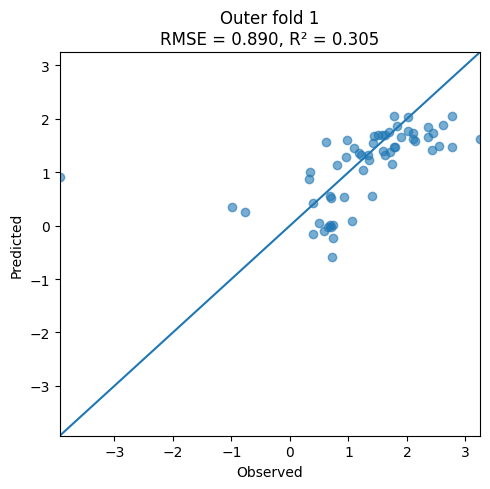

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_20_outerfold_01.json


[I 2026-10-23 23:45:21,765] A new study created in memory with name: no-name-7cd2f45c-1576-480e-9e34-43bc45ac803d


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_20_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:45:22,093] Trial 0 finished with value: 0.9113706955060166 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9113706955060166.
[I 2026-10-23 23:45:22,604] Trial 1 finished with value: 0.9917366719947389 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9113706955060166.
[I 2026-10-23 23:45:22,927] Trial 2 finished with value: 0.9518794183653346 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9113706955060166.
[I 2026-10-23 23:45:23,375] Trial 3 finished with value: 0.9256662191693277 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9712 R2 = 0.3747


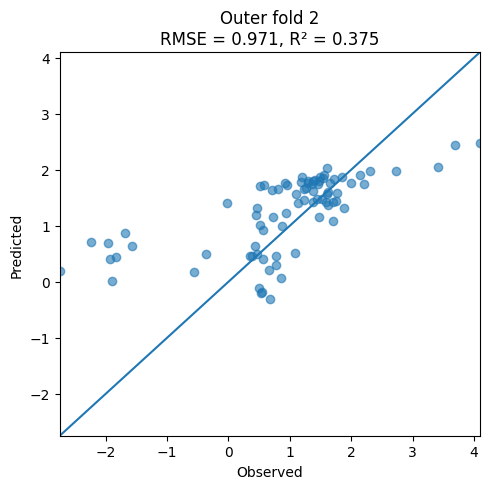

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_20_outerfold_02.json


[I 2026-10-23 23:46:51,125] A new study created in memory with name: no-name-8e847711-8cff-4bbf-817b-c3e5234f47f3


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_20_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:46:51,528] Trial 0 finished with value: 0.940095942401064 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.940095942401064.
[I 2026-10-23 23:46:52,031] Trial 1 finished with value: 0.942738728853338 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.940095942401064.
[I 2026-10-23 23:46:52,416] Trial 2 finished with value: 0.9346248692470924 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9346248692470924.
[I 2026-10-23 23:46:52,833] Trial 3 finished with value: 0.9819114195385664 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.8927 R2 = 0.3608


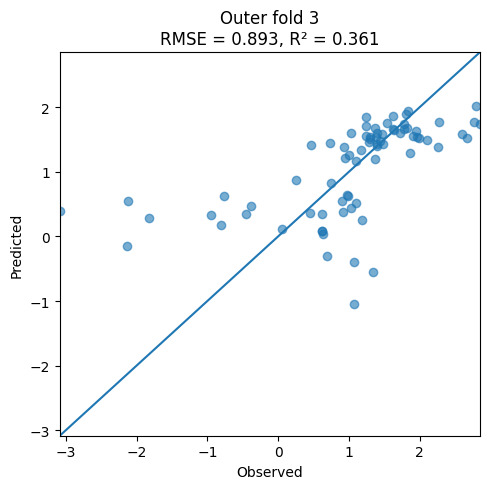

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_20_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_20_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:48:10,376] A new study created in memory with name: no-name-d8511ff8-c998-462a-8844-af5d4dde5fc4
[I 2026-10-23 23:48:10,769] Trial 0 finished with value: 0.8710873952365816 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8710873952365816.
[I 2026-10-23 23:48:11,261] Trial 1 finished with value: 0.8914434511870977 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8710873952365816.
[I 2026-10-23 23:48:11,588] Trial 2 finished with value: 0.9264358571824778 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.87108739

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9830 R2 = 0.3711


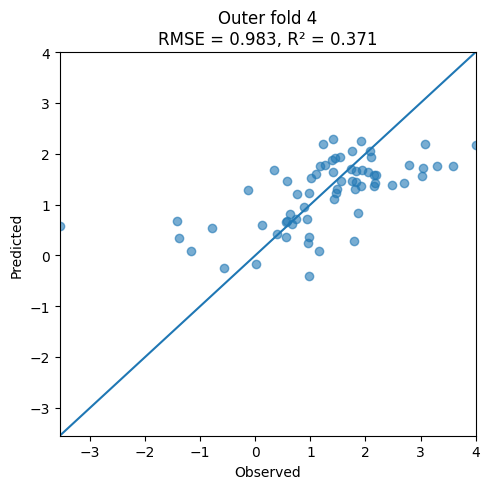

[I 2026-10-23 23:49:28,604] A new study created in memory with name: no-name-6fdd0b22-9c29-4fa0-b708-aa3cb3747ee0


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_20_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_20_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:49:30,790] Trial 0 finished with value: 0.946274539902376 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.946274539902376.
[I 2026-10-23 23:49:32,528] Trial 1 finished with value: 0.9966121570018017 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.946274539902376.
[I 2026-10-23 23:49:32,859] Trial 2 finished with value: 0.9514989517326675 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.946274539902376.
[I 2026-10-23 23:49:33,308] Trial 3 finished with value: 0.9929646698456752 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8514 R2 = 0.1912


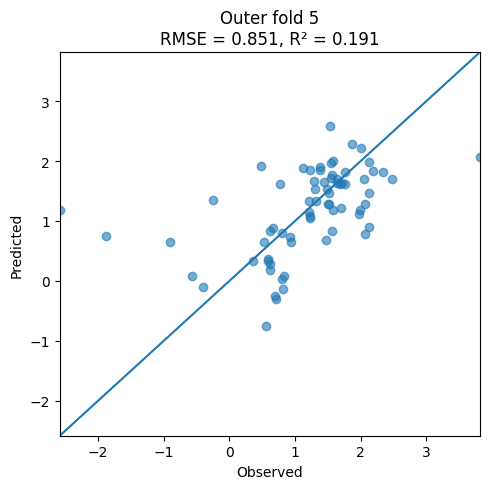

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_20_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_20_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9176 (+/- 0.0509)
Mean R2 (Outer CV): 0.3205 (+/- 0.0694)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 21]


[I 2026-10-23 23:50:51,634] A new study created in memory with name: no-name-0c85787c-8230-4b71-91ca-9ec4ec43a732


Resuming from existing file. Found 480 previous runs.
Running rs=285, targetTW=21
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:50:52,024] Trial 0 finished with value: 0.9701823430815958 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9701823430815958.
[I 2026-10-23 23:50:52,620] Trial 1 finished with value: 1.0045733168019233 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9701823430815958.
[I 2026-10-23 23:50:52,989] Trial 2 finished with value: 0.9604207921363331 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9604207921363331.
[I 2026-10-23 23:50:53,625] Trial 3 finished with value: 0.9732961301955199 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.8340 R2 = 0.3892


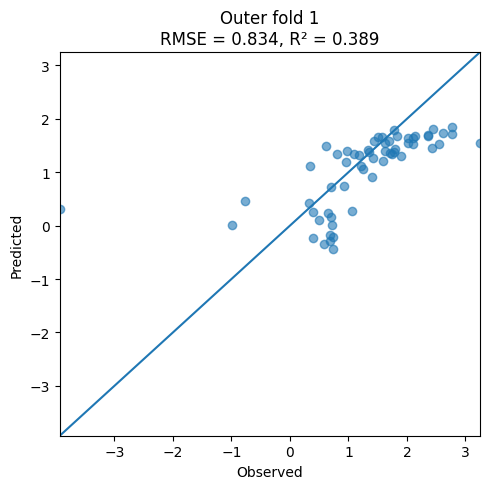

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_21_outerfold_01.json


[I 2026-10-23 23:52:14,910] A new study created in memory with name: no-name-be8a637c-5229-47d8-9aae-81b9a495bc20


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_21_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:52:15,253] Trial 0 finished with value: 0.8860891313184779 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8860891313184779.
[I 2026-10-23 23:52:15,792] Trial 1 finished with value: 0.9490143586910607 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8860891313184779.
[I 2026-10-23 23:52:16,120] Trial 2 finished with value: 0.9554993353916175 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8860891313184779.
[I 2026-10-23 23:52:16,536] Trial 3 finished with value: 0.9296698740723052 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9437 R2 = 0.4096


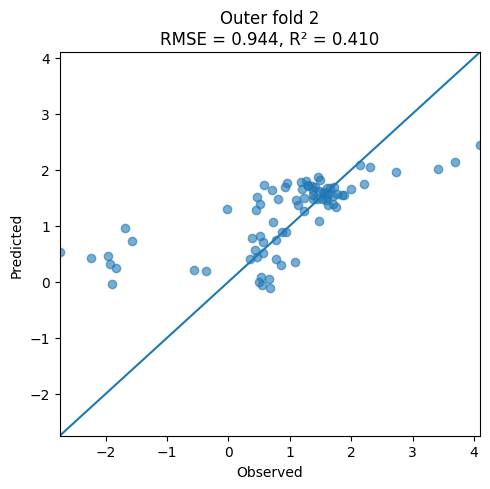

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_21_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_21_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:53:38,452] A new study created in memory with name: no-name-38162a45-75cb-48d7-912c-cf3119274552
[I 2026-10-23 23:53:38,840] Trial 0 finished with value: 0.923867764861521 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.923867764861521.
[I 2026-10-23 23:53:39,364] Trial 1 finished with value: 0.9350623965253981 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.923867764861521.
[I 2026-10-23 23:53:39,732] Trial 2 finished with value: 0.9475371188834314 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.92386776486

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.8776 R2 = 0.3823


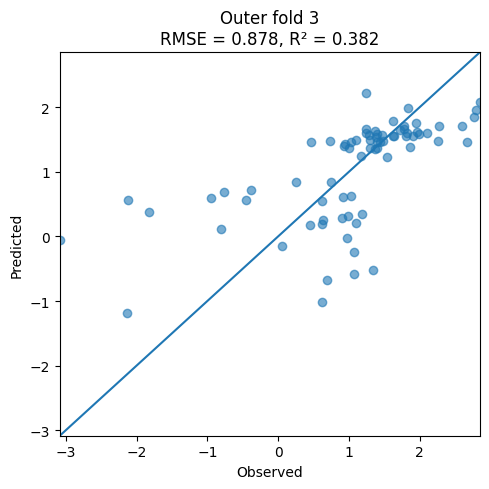

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_21_outerfold_03.json


[I 2026-10-23 23:55:03,049] A new study created in memory with name: no-name-d469c1b2-a171-4687-a90e-d07e192dba0a


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_21_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:55:03,454] Trial 0 finished with value: 0.834366966586089 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.834366966586089.
[I 2026-10-23 23:55:03,967] Trial 1 finished with value: 0.9191608385404824 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.834366966586089.
[I 2026-10-23 23:55:04,336] Trial 2 finished with value: 0.9252485826725325 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.834366966586089.
[I 2026-10-23 23:55:04,810] Trial 3 finished with value: 0.8968138998808781 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9531 R2 = 0.4087


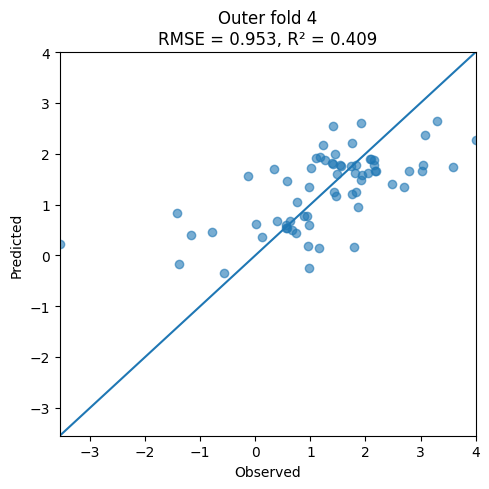

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_21_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_21_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:56:17,474] A new study created in memory with name: no-name-a10c989b-c4cd-4187-b938-eea2d61f2087
[I 2026-10-23 23:56:17,856] Trial 0 finished with value: 0.9544990189733463 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9544990189733463.
[I 2026-10-23 23:56:18,359] Trial 1 finished with value: 0.9746187773980584 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9544990189733463.
[I 2026-10-23 23:56:18,693] Trial 2 finished with value: 0.9860527798819997 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.95449901

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.7517 R2 = 0.3694


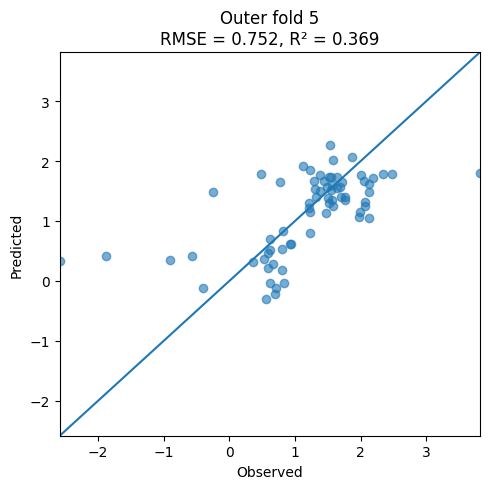

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_21_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_21_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8720 (+/- 0.0744)
Mean R2 (Outer CV): 0.3919 (+/- 0.0155)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 22]


[I 2026-10-23 23:57:41,543] A new study created in memory with name: no-name-aeb441b0-82ef-4132-8ce5-733d6bdbcb3a


Resuming from existing file. Found 486 previous runs.
Running rs=285, targetTW=22
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:57:41,908] Trial 0 finished with value: 0.9738761757050692 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9738761757050692.
[I 2026-10-23 23:57:42,441] Trial 1 finished with value: 1.013641713437111 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9738761757050692.
[I 2026-10-23 23:57:42,820] Trial 2 finished with value: 0.9937645656159586 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9738761757050692.
[I 2026-10-23 23:57:43,283] Trial 3 finished with value: 0.9533457388595743 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.7751 R2 = 0.4724


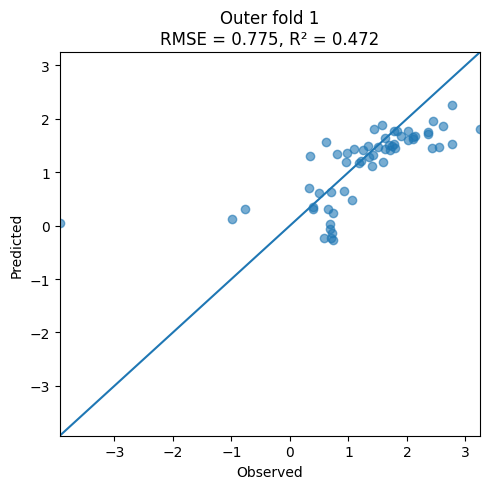

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_22_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_22_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-23 23:59:14,477] A new study created in memory with name: no-name-cdb6b526-cb34-492d-85d1-719129729aab
[I 2026-10-23 23:59:14,829] Trial 0 finished with value: 0.9274815447229895 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9274815447229895.
[I 2026-10-23 23:59:15,374] Trial 1 finished with value: 0.956418658805795 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9274815447229895.
[I 2026-10-23 23:59:15,704] Trial 2 finished with value: 0.9817272073525823 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.927481544

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9196 R2 = 0.4394


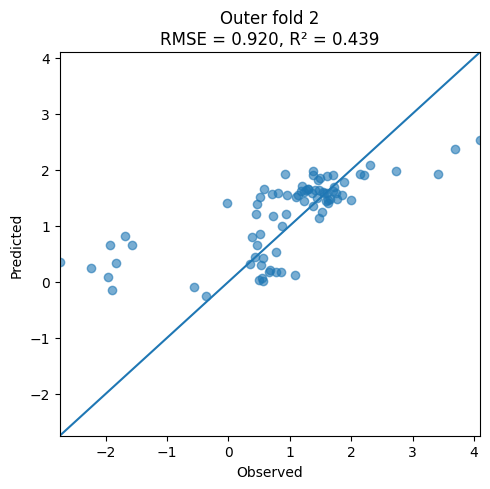

[I 2026-10-24 00:00:25,191] A new study created in memory with name: no-name-5934d7fa-4fea-4ee8-979d-1bed9946484d


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_22_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_22_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:00:25,596] Trial 0 finished with value: 0.9495426828577065 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9495426828577065.
[I 2026-10-24 00:00:26,106] Trial 1 finished with value: 0.9588012539086307 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9495426828577065.
[I 2026-10-24 00:00:26,459] Trial 2 finished with value: 0.9906938602253559 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9495426828577065.
[I 2026-10-24 00:00:26,911] Trial 3 finished with value: 0.9284955885184398 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.8652 R2 = 0.3996


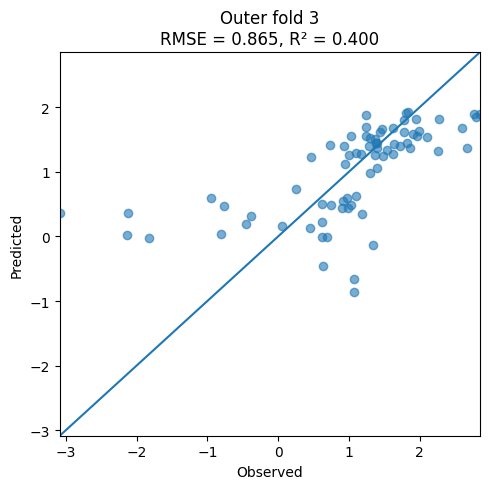

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_22_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_22_outerfold_03_meta.json

=== Outer fold 4/5 ===


[I 2026-10-24 00:01:39,969] A new study created in memory with name: no-name-6f2b9bc5-ad45-4359-bf1a-f73d431de3ca


Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:01:40,368] Trial 0 finished with value: 0.8983867641061585 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8983867641061585.
[I 2026-10-24 00:01:40,900] Trial 1 finished with value: 0.9404253121385886 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8983867641061585.
[I 2026-10-24 00:01:41,329] Trial 2 finished with value: 0.9417854276977324 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8983867641061585.
[I 2026-10-24 00:01:41,826] Trial 3 finished with value: 0.9035423525722727 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9625 R2 = 0.3970


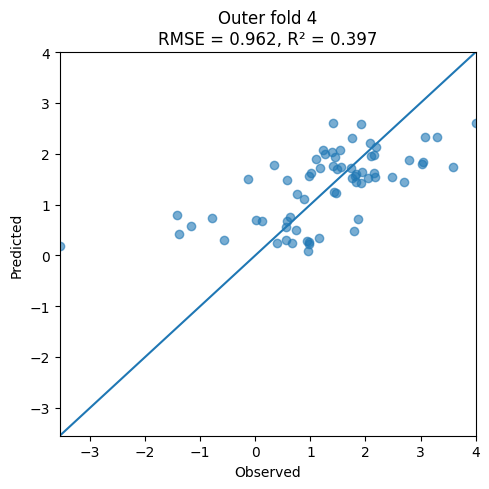

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_22_outerfold_04.json


[I 2026-10-24 00:02:57,007] A new study created in memory with name: no-name-834288e7-8ecd-4d80-909d-f578542cbd05


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_22_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:02:57,412] Trial 0 finished with value: 0.960189014014291 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.960189014014291.
[I 2026-10-24 00:02:58,341] Trial 1 finished with value: 1.0060129088612921 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.960189014014291.
[I 2026-10-24 00:02:59,836] Trial 2 finished with value: 0.9907851529184978 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.960189014014291.
[I 2026-10-24 00:03:01,863] Trial 3 finished with value: 0.9510116246266567 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8282 R2 = 0.2346


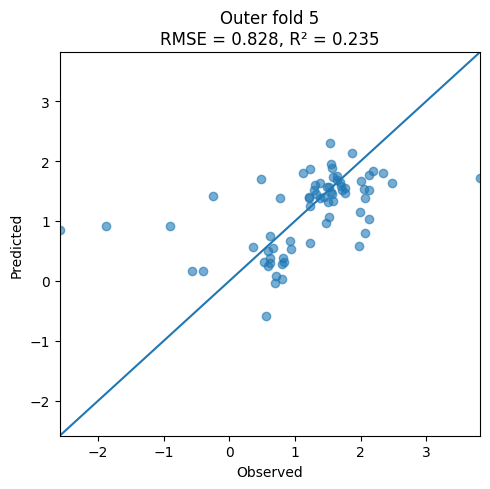

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_22_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_22_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8701 (+/- 0.0660)
Mean R2 (Outer CV): 0.3886 (+/- 0.0819)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 23]


[I 2026-10-24 00:04:36,600] A new study created in memory with name: no-name-af1d4548-62ae-409f-bcbe-e480e96a8361


Resuming from existing file. Found 492 previous runs.
Running rs=285, targetTW=23
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:04:37,024] Trial 0 finished with value: 0.9463396584535267 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9463396584535267.
[I 2026-10-24 00:04:37,603] Trial 1 finished with value: 1.012466362955919 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9463396584535267.
[I 2026-10-24 00:04:37,992] Trial 2 finished with value: 0.9821067830047137 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9463396584535267.
[I 2026-10-24 00:04:38,797] Trial 3 finished with value: 0.9628171329261441 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.7827 R2 = 0.4621


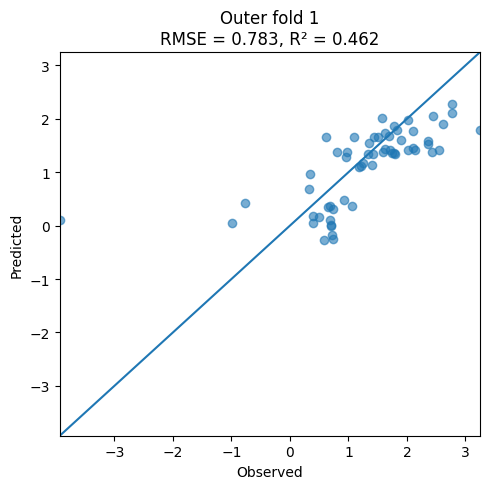

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_23_outerfold_01.json


[I 2026-10-24 00:06:37,126] A new study created in memory with name: no-name-e9732a5f-38f1-4954-abc6-a506feb8a562


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_23_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:06:37,545] Trial 0 finished with value: 0.9159141976628188 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9159141976628188.
[I 2026-10-24 00:06:38,043] Trial 1 finished with value: 0.9483738490089367 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9159141976628188.
[I 2026-10-24 00:06:38,417] Trial 2 finished with value: 0.9449740743811532 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9159141976628188.
[I 2026-10-24 00:06:38,832] Trial 3 finished with value: 0.9337456718085219 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9591 R2 = 0.3902


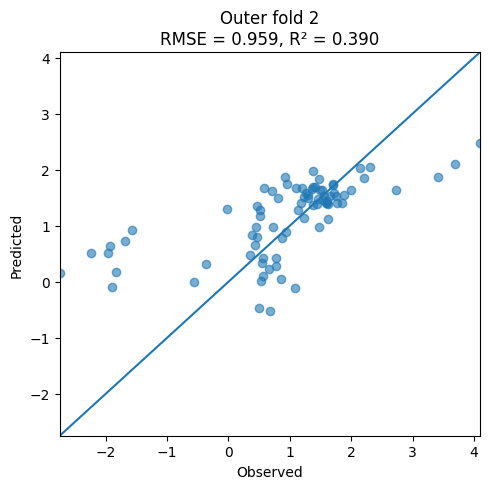

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_23_outerfold_02.json


[I 2026-10-24 00:07:41,155] A new study created in memory with name: no-name-ff29df33-497d-4e55-b6ba-bce199eca440


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_23_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:07:41,555] Trial 0 finished with value: 0.9432886116265096 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9432886116265096.
[I 2026-10-24 00:07:42,111] Trial 1 finished with value: 0.9616739636491511 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9432886116265096.
[I 2026-10-24 00:07:43,617] Trial 2 finished with value: 0.9720806001037007 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9432886116265096.
[I 2026-10-24 00:07:45,841] Trial 3 finished with value: 0.9363181592884087 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.8734 R2 = 0.3880


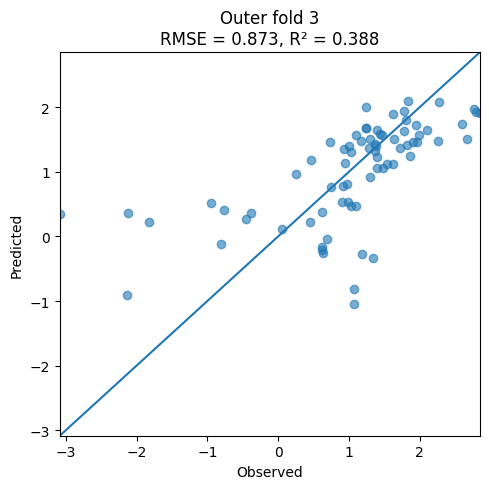

[I 2026-10-24 00:09:10,805] A new study created in memory with name: no-name-fb4e3284-6658-47e0-be76-72114d243b9c


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_23_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_23_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:09:12,209] Trial 0 finished with value: 0.9178823218163248 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9178823218163248.
[I 2026-10-24 00:09:12,792] Trial 1 finished with value: 0.9624612613375457 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9178823218163248.
[I 2026-10-24 00:09:13,146] Trial 2 finished with value: 0.9917114969735544 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9178823218163248.
[I 2026-10-24 00:09:13,649] Trial 3 finished with value: 0.8915052650022979 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9452 R2 = 0.4185


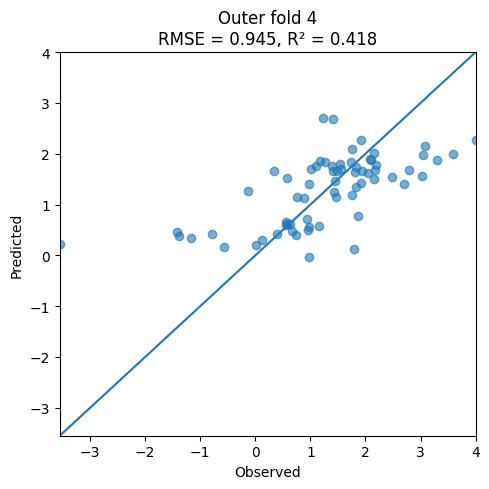

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_23_outerfold_04.json


[I 2026-10-24 00:10:26,476] A new study created in memory with name: no-name-2e401815-18d6-49b9-9a3e-1a7aea4225c4


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_23_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:10:26,838] Trial 0 finished with value: 0.9643586779326021 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9643586779326021.
[I 2026-10-24 00:10:27,395] Trial 1 finished with value: 0.9788379395409447 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9643586779326021.
[I 2026-10-24 00:10:27,754] Trial 2 finished with value: 0.9621422425171295 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9621422425171295.
[I 2026-10-24 00:10:28,236] Trial 3 finished with value: 0.9350392474834635 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8245 R2 = 0.2415


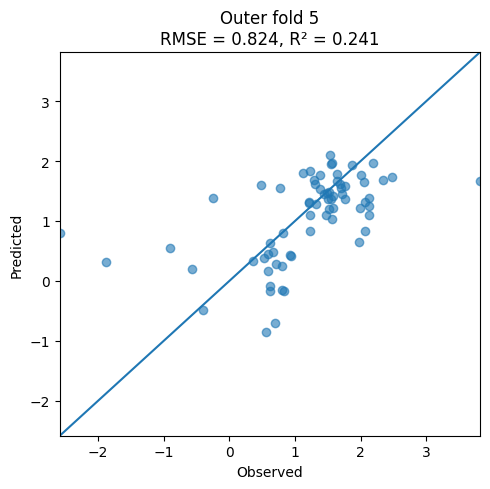

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_23_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_23_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8770 (+/- 0.0679)
Mean R2 (Outer CV): 0.3801 (+/- 0.0743)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 24]


[I 2026-10-24 00:11:53,929] A new study created in memory with name: no-name-e87cf7a3-4a9d-4f3e-a9ab-234c9fa17bb0


Resuming from existing file. Found 498 previous runs.
Running rs=285, targetTW=24
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:11:54,394] Trial 0 finished with value: 0.9598110901950201 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9598110901950201.
[I 2026-10-24 00:11:55,520] Trial 1 finished with value: 1.0193501450397449 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9598110901950201.
[I 2026-10-24 00:11:56,356] Trial 2 finished with value: 0.994737593972569 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9598110901950201.
[I 2026-10-24 00:11:56,986] Trial 3 finished with value: 0.9538621102217602 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.8624 R2 = 0.3470


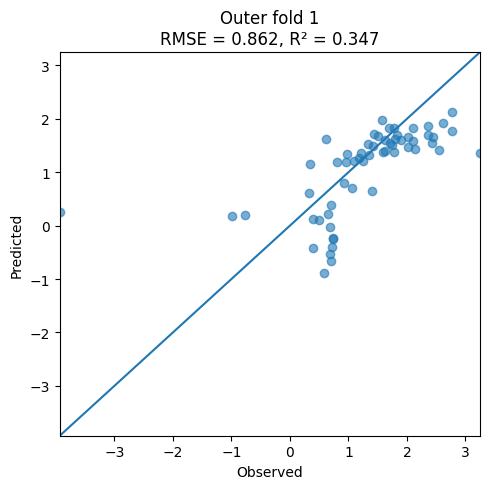

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_24_outerfold_01.json


[I 2026-10-24 00:13:21,881] A new study created in memory with name: no-name-36a8a7b9-99d8-4571-a8ec-72ffe8c350ff


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_24_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:13:22,288] Trial 0 finished with value: 0.9064754712555152 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9064754712555152.
[I 2026-10-24 00:13:22,846] Trial 1 finished with value: 0.9749152801290871 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9064754712555152.
[I 2026-10-24 00:13:23,188] Trial 2 finished with value: 0.9488827242291027 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9064754712555152.
[I 2026-10-24 00:13:23,895] Trial 3 finished with value: 0.954109230516198 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9509 R2 = 0.4005


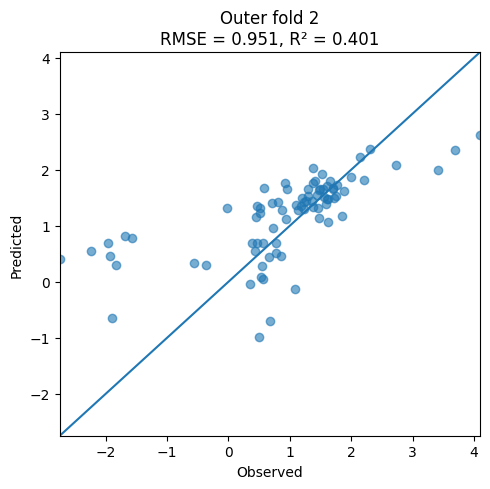

[I 2026-10-24 00:14:25,776] A new study created in memory with name: no-name-4ddf1467-020b-4832-9136-1ec34b975173


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_24_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_24_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:14:26,151] Trial 0 finished with value: 0.9526615375020939 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9526615375020939.
[I 2026-10-24 00:14:26,704] Trial 1 finished with value: 0.9675664390711757 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9526615375020939.
[I 2026-10-24 00:14:27,094] Trial 2 finished with value: 0.9612024064622884 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9526615375020939.
[I 2026-10-24 00:14:27,593] Trial 3 finished with value: 0.9528631843112718 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.8627 R2 = 0.4031


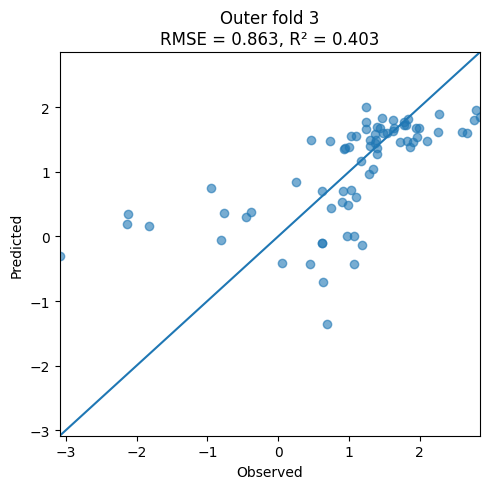

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_24_outerfold_03.json


[I 2026-10-24 00:15:40,878] A new study created in memory with name: no-name-9cfd0435-c245-4b0d-a571-76e31c3f16a2


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_24_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:15:41,316] Trial 0 finished with value: 0.9227316088061406 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9227316088061406.
[I 2026-10-24 00:15:41,933] Trial 1 finished with value: 0.9603625998217344 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9227316088061406.
[I 2026-10-24 00:15:42,325] Trial 2 finished with value: 0.94814534103259 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9227316088061406.
[I 2026-10-24 00:15:42,818] Trial 3 finished with value: 0.9028647901993474 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9354 R2 = 0.4306


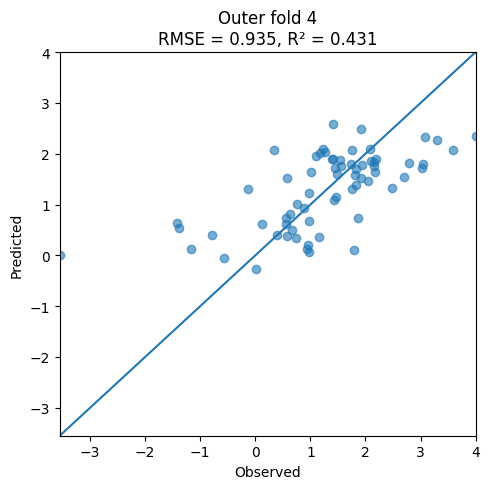

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_24_outerfold_04.json


[I 2026-10-24 00:17:10,220] A new study created in memory with name: no-name-1cd5bd67-1057-49fd-8cd0-aa74129b5de9


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_24_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:17:10,630] Trial 0 finished with value: 0.9394332211852996 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9394332211852996.
[I 2026-10-24 00:17:11,180] Trial 1 finished with value: 0.9991492213511454 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9394332211852996.
[I 2026-10-24 00:17:11,524] Trial 2 finished with value: 0.9722641643185875 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9394332211852996.
[I 2026-10-24 00:17:11,959] Trial 3 finished with value: 0.9204349990953978 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.7937 R2 = 0.2970


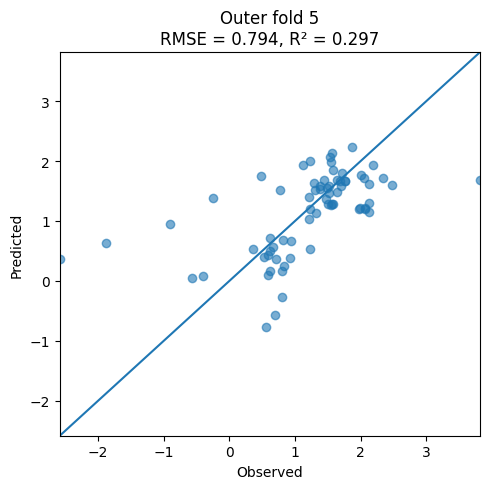

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_24_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_24_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8810 (+/- 0.0568)
Mean R2 (Outer CV): 0.3756 (+/- 0.0477)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 25]


[I 2026-10-24 00:18:37,757] A new study created in memory with name: no-name-a36f9f21-844d-4857-8ec4-d55fb8b5a815


Resuming from existing file. Found 504 previous runs.
Running rs=285, targetTW=25
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:18:38,240] Trial 0 finished with value: 0.9379960305042414 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9379960305042414.
[I 2026-10-24 00:18:40,255] Trial 1 finished with value: 1.0314003043202407 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9379960305042414.
[I 2026-10-24 00:18:42,317] Trial 2 finished with value: 0.9774478492510839 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9379960305042414.
[I 2026-10-24 00:18:42,817] Trial 3 finished with value: 0.9634959898554547 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.8125 R2 = 0.4203


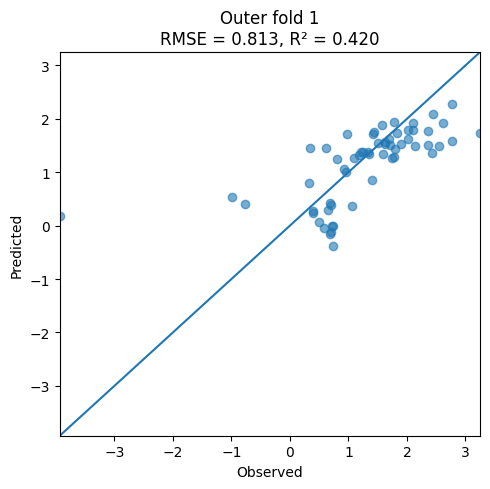

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_25_outerfold_01.json


[I 2026-10-24 00:19:55,485] A new study created in memory with name: no-name-1de3765e-8b7c-48de-a4e9-9a3c3e5ca86e


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_25_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:19:55,945] Trial 0 finished with value: 0.9220938670680767 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9220938670680767.
[I 2026-10-24 00:19:56,447] Trial 1 finished with value: 1.0592969084780268 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9220938670680767.
[I 2026-10-24 00:19:56,795] Trial 2 finished with value: 0.9643547265926304 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9220938670680767.
[I 2026-10-24 00:19:57,246] Trial 3 finished with value: 0.9630031309989964 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9887 R2 = 0.3520


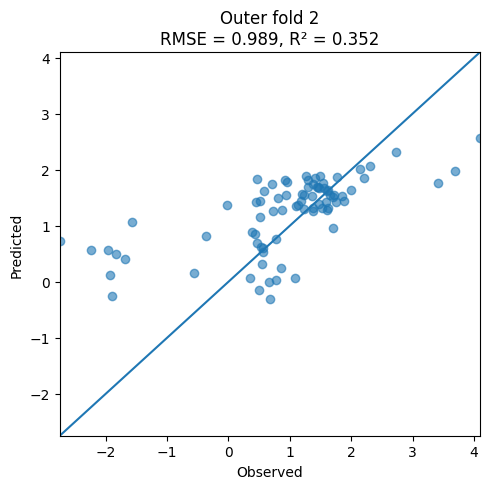

[I 2026-10-24 00:20:57,413] A new study created in memory with name: no-name-44d70348-974b-4e94-8aac-e92d8fd47327


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_25_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_25_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:20:57,822] Trial 0 finished with value: 0.9758714293576398 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9758714293576398.
[I 2026-10-24 00:20:58,362] Trial 1 finished with value: 0.9868019921645029 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9758714293576398.
[I 2026-10-24 00:20:58,711] Trial 2 finished with value: 0.9915242987923656 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9758714293576398.
[I 2026-10-24 00:20:59,157] Trial 3 finished with value: 1.0012298836970919 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9356 R2 = 0.2979


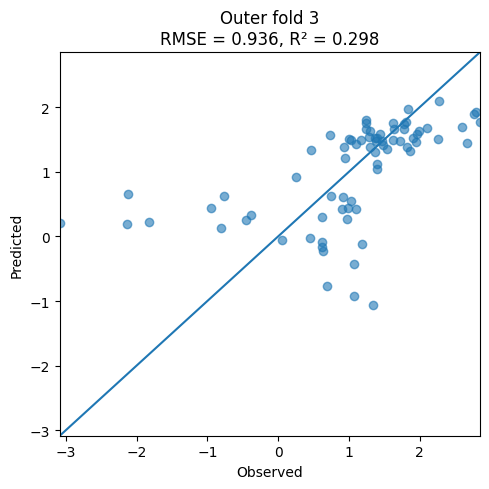

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_25_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_25_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:22:30,355] A new study created in memory with name: no-name-3e75886d-fb18-4040-ac23-d8dd6129fdcd
[I 2026-10-24 00:22:30,775] Trial 0 finished with value: 0.9257633278473152 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9257633278473152.
[I 2026-10-24 00:22:31,317] Trial 1 finished with value: 0.957445549587173 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9257633278473152.
[I 2026-10-24 00:22:31,687] Trial 2 finished with value: 0.9326768285251047 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.925763327

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9645 R2 = 0.3945


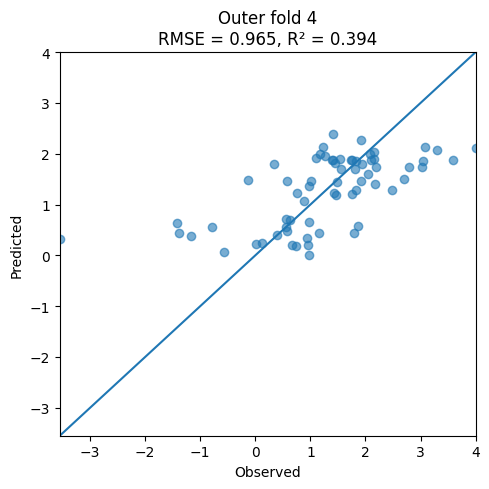

[I 2026-10-24 00:24:08,208] A new study created in memory with name: no-name-30fbfb0a-ae1d-4a99-b2c3-0e557467aa39


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_25_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_25_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:24:08,638] Trial 0 finished with value: 0.9435595943098143 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9435595943098143.
[I 2026-10-24 00:24:09,223] Trial 1 finished with value: 1.0096053716848483 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9435595943098143.
[I 2026-10-24 00:24:09,563] Trial 2 finished with value: 0.9772748956539543 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9435595943098143.
[I 2026-10-24 00:24:10,044] Trial 3 finished with value: 0.9552535671393064 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8482 R2 = 0.1972


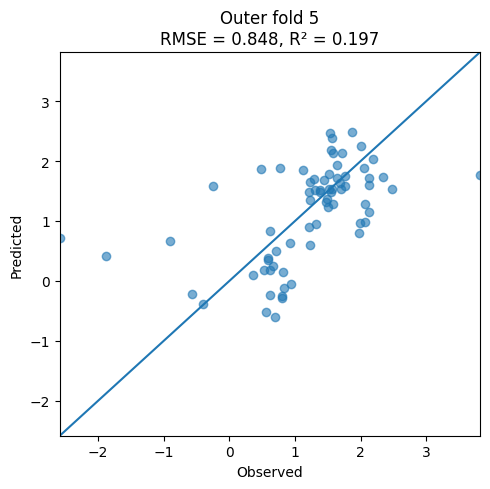

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_25_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_25_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9099 (+/- 0.0680)
Mean R2 (Outer CV): 0.3324 (+/- 0.0793)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 26]


[I 2026-10-24 00:25:23,644] A new study created in memory with name: no-name-8c68b450-c7ae-4235-ae44-3144606f84ac


Resuming from existing file. Found 510 previous runs.
Running rs=285, targetTW=26
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:25:24,065] Trial 0 finished with value: 0.9589349981404103 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9589349981404103.
[I 2026-10-24 00:25:24,663] Trial 1 finished with value: 1.0182616782799179 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9589349981404103.
[I 2026-10-24 00:25:25,040] Trial 2 finished with value: 0.9986130763430979 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9589349981404103.
[I 2026-10-24 00:25:25,502] Trial 3 finished with value: 0.9609579029318943 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.8647 R2 = 0.3435


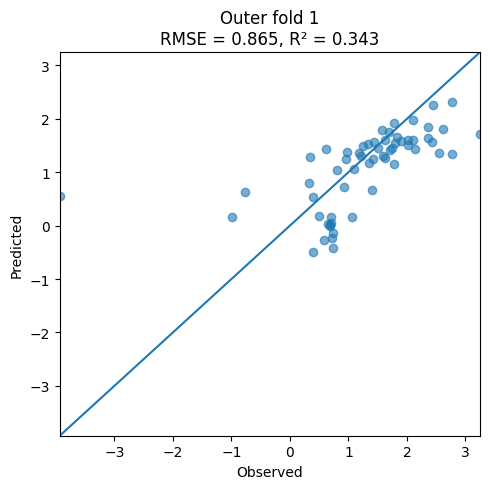

[I 2026-10-24 00:26:40,470] A new study created in memory with name: no-name-b5646e2b-e4f1-4d36-af51-6a81db794748


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_26_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_26_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:26:41,804] Trial 0 finished with value: 0.9233197606848378 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9233197606848378.
[I 2026-10-24 00:26:44,265] Trial 1 finished with value: 1.0136704092569864 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9233197606848378.
[I 2026-10-24 00:26:44,824] Trial 2 finished with value: 0.9972077325199301 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9233197606848378.
[I 2026-10-24 00:26:45,274] Trial 3 finished with value: 0.9596346592363251 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9511 R2 = 0.4003


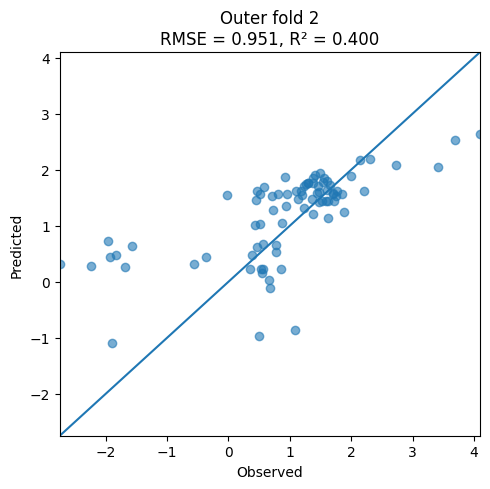

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_26_outerfold_02.json


[I 2026-10-24 00:27:41,568] A new study created in memory with name: no-name-027bb061-c78f-4366-b878-93c907e18c89


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_26_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:27:42,032] Trial 0 finished with value: 0.9419282873205208 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9419282873205208.
[I 2026-10-24 00:27:42,555] Trial 1 finished with value: 0.985619538943743 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9419282873205208.
[I 2026-10-24 00:27:42,935] Trial 2 finished with value: 0.997443346345589 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9419282873205208.
[I 2026-10-24 00:27:43,374] Trial 3 finished with value: 0.9602594510700975 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9288 R2 = 0.3081


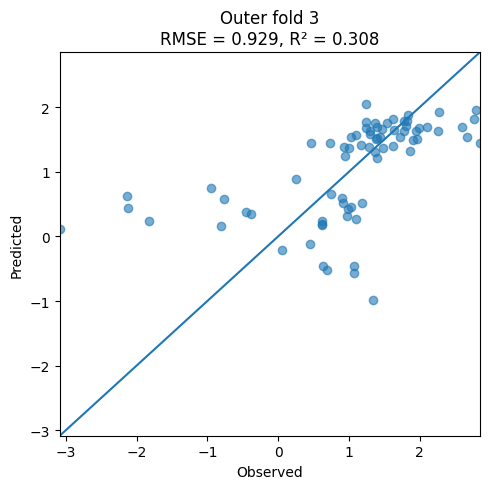

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_26_outerfold_03.json


[I 2026-10-24 00:28:53,380] A new study created in memory with name: no-name-0346e956-e9a9-4287-9291-2b43aaece624


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_26_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:28:53,822] Trial 0 finished with value: 0.8825329529464878 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8825329529464878.
[I 2026-10-24 00:28:54,370] Trial 1 finished with value: 0.9622015756017598 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8825329529464878.
[I 2026-10-24 00:28:54,737] Trial 2 finished with value: 0.9145847944866513 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8825329529464878.
[I 2026-10-24 00:28:55,259] Trial 3 finished with value: 0.9082545900639685 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9815 R2 = 0.3730


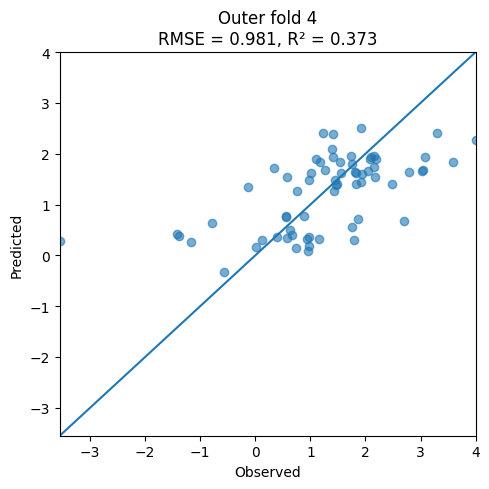

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_26_outerfold_04.json


[I 2026-10-24 00:30:34,835] A new study created in memory with name: no-name-a396326c-b06d-4323-8546-d7ffac130699


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_26_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:30:35,298] Trial 0 finished with value: 0.9524563409158622 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9524563409158622.
[I 2026-10-24 00:30:35,836] Trial 1 finished with value: 0.9997454049174767 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9524563409158622.
[I 2026-10-24 00:30:36,229] Trial 2 finished with value: 1.0003859916175704 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9524563409158622.
[I 2026-10-24 00:30:36,669] Trial 3 finished with value: 0.9654185482051949 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8472 R2 = 0.1990


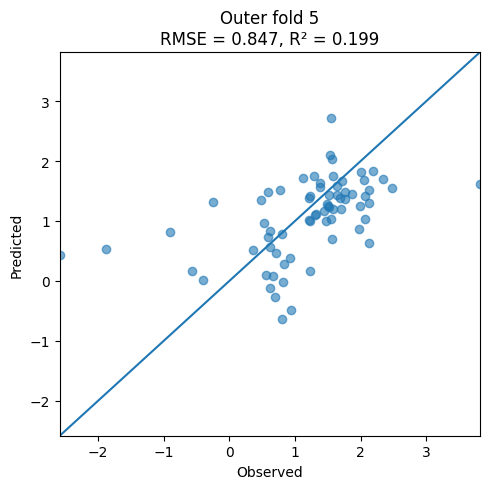

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_26_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_26_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9147 (+/- 0.0511)
Mean R2 (Outer CV): 0.3248 (+/- 0.0700)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 27]


[I 2026-10-24 00:31:54,508] A new study created in memory with name: no-name-179a7393-082e-4430-9849-bd36f19c7718


Resuming from existing file. Found 516 previous runs.
Running rs=285, targetTW=27
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:31:56,668] Trial 0 finished with value: 0.9323199483298736 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9323199483298736.
[I 2026-10-24 00:31:57,424] Trial 1 finished with value: 1.0307131200253945 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9323199483298736.
[I 2026-10-24 00:31:57,800] Trial 2 finished with value: 0.995960080385985 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9323199483298736.
[I 2026-10-24 00:31:58,309] Trial 3 finished with value: 0.9346704671077386 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.8821 R2 = 0.3168


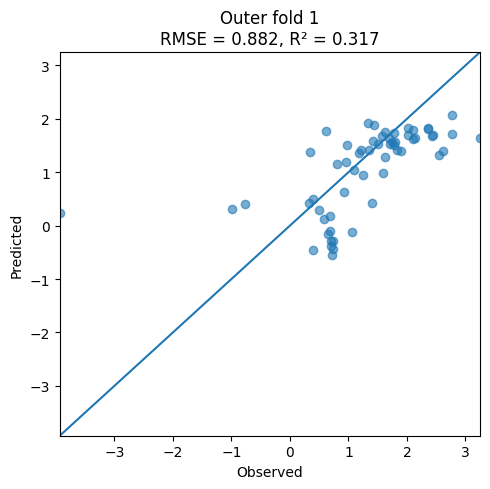

[I 2026-10-24 00:33:11,311] A new study created in memory with name: no-name-5b3d9c65-08dd-4d66-a114-9e09a047a39d


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_27_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_27_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:33:11,699] Trial 0 finished with value: 0.9513243710260397 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9513243710260397.
[I 2026-10-24 00:33:12,207] Trial 1 finished with value: 1.039086634862971 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9513243710260397.
[I 2026-10-24 00:33:12,611] Trial 2 finished with value: 0.991851190322284 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9513243710260397.
[I 2026-10-24 00:33:13,061] Trial 3 finished with value: 0.9588231298656714 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9756 R2 = 0.3691


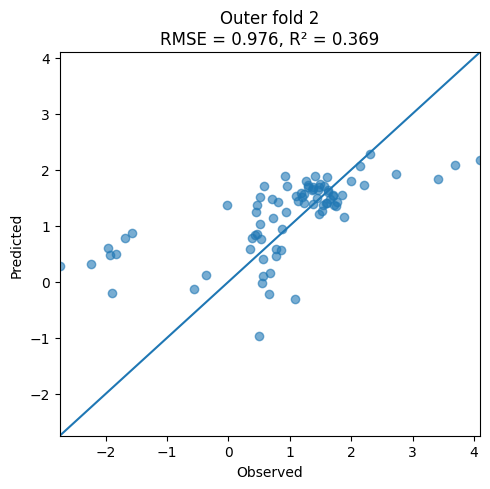

[I 2026-10-24 00:34:14,554] A new study created in memory with name: no-name-d542ad7c-f1cb-46b3-a4d1-f3dc71959ec6


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_27_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_27_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:34:16,122] Trial 0 finished with value: 0.9881811538440478 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9881811538440478.
[I 2026-10-24 00:34:18,658] Trial 1 finished with value: 0.9750934343586559 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9750934343586559.
[I 2026-10-24 00:34:19,093] Trial 2 finished with value: 0.9967416482379728 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9750934343586559.
[I 2026-10-24 00:34:19,567] Trial 3 finished with value: 0.9438377197884144 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9128 R2 = 0.3317


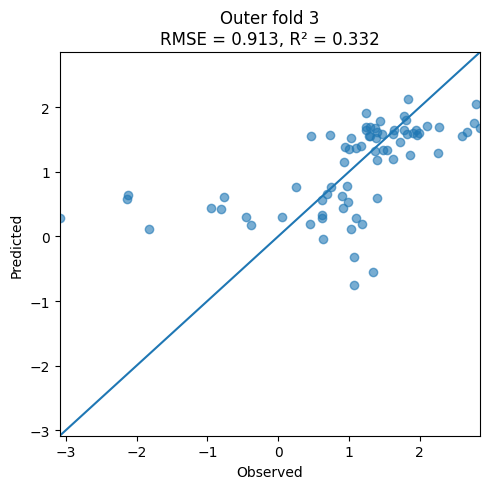

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_27_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_27_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:35:44,996] A new study created in memory with name: no-name-f03486a8-5cbc-4085-943d-0a38fee8c3f8
[I 2026-10-24 00:35:45,451] Trial 0 finished with value: 0.9152852336086201 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9152852336086201.
[I 2026-10-24 00:35:45,977] Trial 1 finished with value: 0.9352661939268677 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9152852336086201.
[I 2026-10-24 00:35:46,360] Trial 2 finished with value: 0.9308573626782484 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.91528523

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9243 R2 = 0.4440


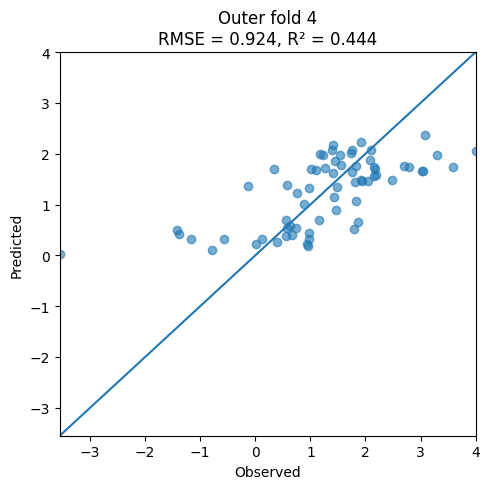

[I 2026-10-24 00:37:05,818] A new study created in memory with name: no-name-4a886066-e272-49bf-ab06-8be65a91acf6


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_27_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_27_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:37:07,144] Trial 0 finished with value: 0.9355058949847257 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9355058949847257.
[I 2026-10-24 00:37:09,098] Trial 1 finished with value: 0.9927153009815373 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9355058949847257.
[I 2026-10-24 00:37:09,487] Trial 2 finished with value: 1.0030799863529165 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9355058949847257.
[I 2026-10-24 00:37:09,959] Trial 3 finished with value: 0.9640567599904599 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.9077 R2 = 0.0807


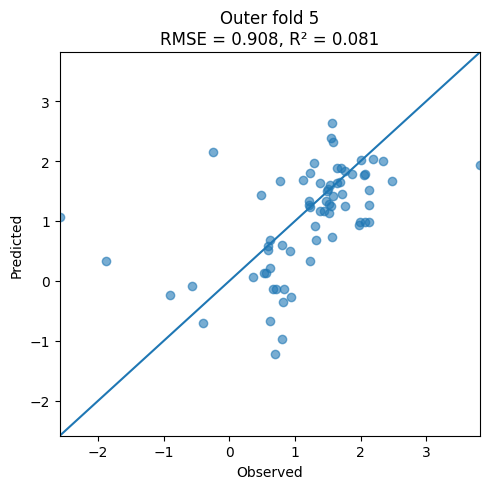

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_27_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_27_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9205 (+/- 0.0308)
Mean R2 (Outer CV): 0.3084 (+/- 0.1221)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 28]


[I 2026-10-24 00:38:29,675] A new study created in memory with name: no-name-aecf30bd-9ed1-4324-a050-3e471c15d3f8


Resuming from existing file. Found 522 previous runs.
Running rs=285, targetTW=28
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:38:31,565] Trial 0 finished with value: 0.970944992793999 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.970944992793999.
[I 2026-10-24 00:38:33,447] Trial 1 finished with value: 1.0271049949278417 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.970944992793999.
[I 2026-10-24 00:38:33,834] Trial 2 finished with value: 1.0102585777667166 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.970944992793999.
[I 2026-10-24 00:38:34,311] Trial 3 finished with value: 0.9691483984445404 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.8799 R2 = 0.3201


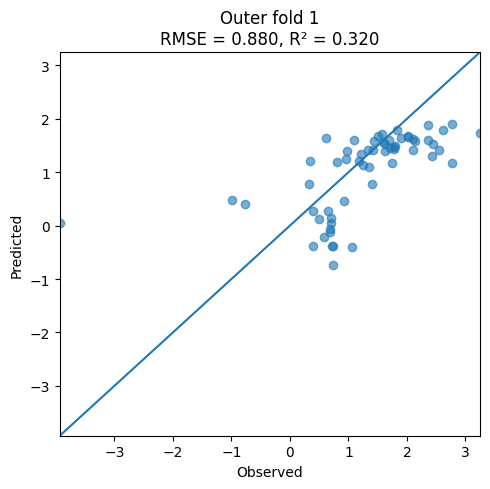

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_28_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_28_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:40:04,221] A new study created in memory with name: no-name-aebd35ad-fcf9-4bac-b064-cb4e4ba9a9f6
[I 2026-10-24 00:40:04,662] Trial 0 finished with value: 0.925120126816116 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.925120126816116.
[I 2026-10-24 00:40:05,213] Trial 1 finished with value: 0.9970885224215453 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.925120126816116.
[I 2026-10-24 00:40:05,573] Trial 2 finished with value: 1.0011919759077794 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.92512012681

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9587 R2 = 0.3907


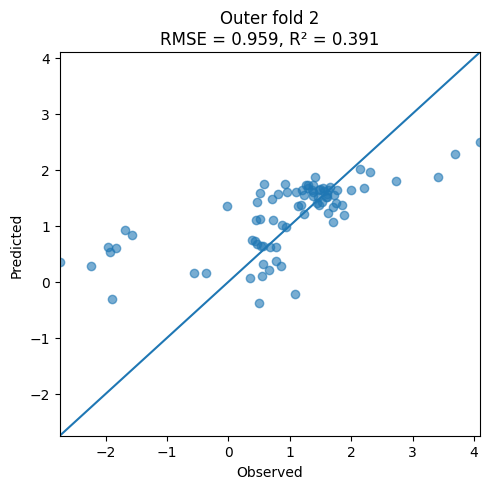

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_28_outerfold_02.json


[I 2026-10-24 00:41:12,983] A new study created in memory with name: no-name-bb4a431c-6dc7-4833-bd74-809021d7dbb4


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_28_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:41:13,460] Trial 0 finished with value: 0.9671165475115386 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9671165475115386.
[I 2026-10-24 00:41:14,065] Trial 1 finished with value: 0.9679484906048255 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9671165475115386.
[I 2026-10-24 00:41:14,427] Trial 2 finished with value: 0.9921696174744479 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9671165475115386.
[I 2026-10-24 00:41:14,910] Trial 3 finished with value: 0.9386537767116847 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.8983 R2 = 0.3527


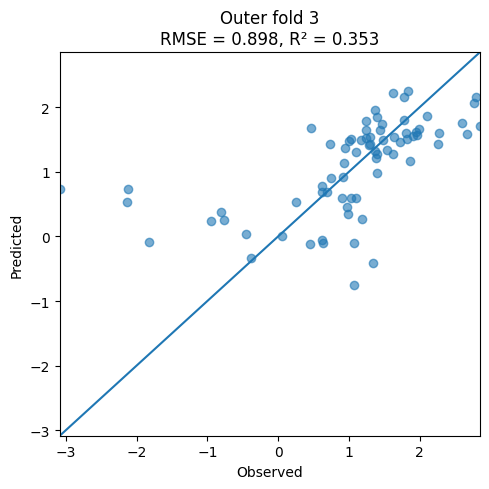

[I 2026-10-24 00:42:28,043] A new study created in memory with name: no-name-5a6d5048-a011-436a-85e3-466d84ef557b


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_28_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_28_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:42:28,606] Trial 0 finished with value: 0.9150150063202671 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9150150063202671.
[I 2026-10-24 00:42:29,183] Trial 1 finished with value: 0.9189266284225613 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9150150063202671.
[I 2026-10-24 00:42:29,600] Trial 2 finished with value: 0.9524369511107524 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9150150063202671.
[I 2026-10-24 00:42:31,280] Trial 3 finished with value: 0.9531109458896851 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9977 R2 = 0.3522


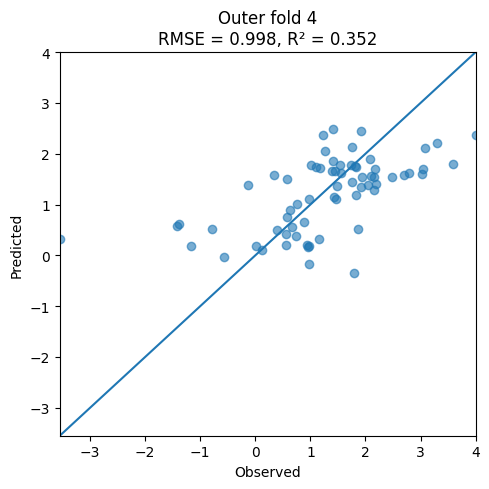

[I 2026-10-24 00:43:43,406] A new study created in memory with name: no-name-ec8fe5ad-d37f-431f-8663-a01a300e5b6b


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_28_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_28_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:43:44,875] Trial 0 finished with value: 0.9386246996313307 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9386246996313307.
[I 2026-10-24 00:43:45,590] Trial 1 finished with value: 0.9748128680694238 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9386246996313307.
[I 2026-10-24 00:43:45,978] Trial 2 finished with value: 0.9843149506256462 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9386246996313307.
[I 2026-10-24 00:43:46,490] Trial 3 finished with value: 0.948342603600011 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8919 R2 = 0.1123


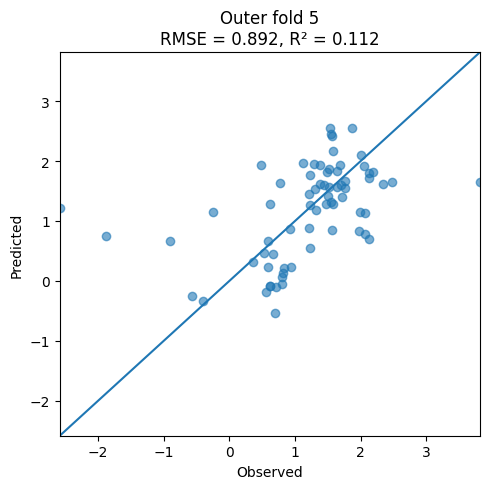

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_28_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_28_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9253 (+/- 0.0453)
Mean R2 (Outer CV): 0.3056 (+/- 0.0992)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 29]


[I 2026-10-24 00:44:48,889] A new study created in memory with name: no-name-60fe1788-4c40-41ac-9c63-cefbf7cc708e


Resuming from existing file. Found 528 previous runs.
Running rs=285, targetTW=29
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:44:49,394] Trial 0 finished with value: 0.9768835211753709 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9768835211753709.
[I 2026-10-24 00:44:49,975] Trial 1 finished with value: 1.0509598742281416 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9768835211753709.
[I 2026-10-24 00:44:50,387] Trial 2 finished with value: 0.9756925068716883 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9756925068716883.
[I 2026-10-24 00:44:50,862] Trial 3 finished with value: 0.9431115669761395 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.8608 R2 = 0.3494


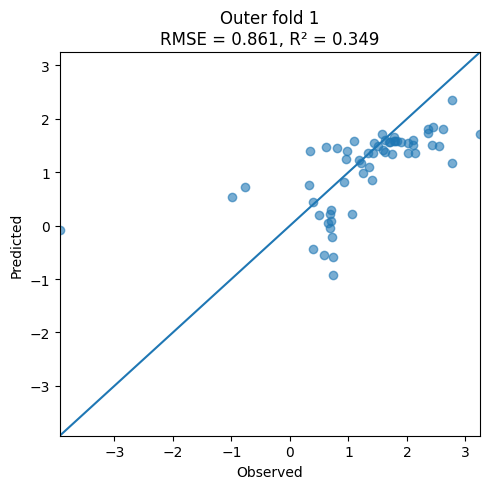

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_29_outerfold_01.json


[I 2026-10-24 00:46:13,990] A new study created in memory with name: no-name-9e417d06-fb8e-428c-b10a-9b9689e1fe96


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_29_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:46:14,502] Trial 0 finished with value: 0.9543017763868382 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9543017763868382.
[I 2026-10-24 00:46:15,052] Trial 1 finished with value: 1.0227424308502981 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9543017763868382.
[I 2026-10-24 00:46:15,422] Trial 2 finished with value: 1.0094417571536785 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9543017763868382.
[I 2026-10-24 00:46:15,886] Trial 3 finished with value: 0.9693822843561052 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9350 R2 = 0.4204


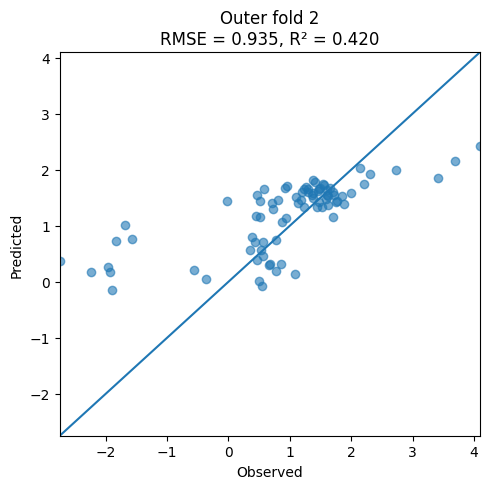

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_29_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_29_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:47:40,069] A new study created in memory with name: no-name-1ae70972-157a-43c9-8eab-5151fff49256
[I 2026-10-24 00:47:40,559] Trial 0 finished with value: 0.9834166815190855 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9834166815190855.
[I 2026-10-24 00:47:41,113] Trial 1 finished with value: 0.9800180401838945 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9800180401838945.
[I 2026-10-24 00:47:41,535] Trial 2 finished with value: 0.9941839989579626 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.98001804

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9850 R2 = 0.2218


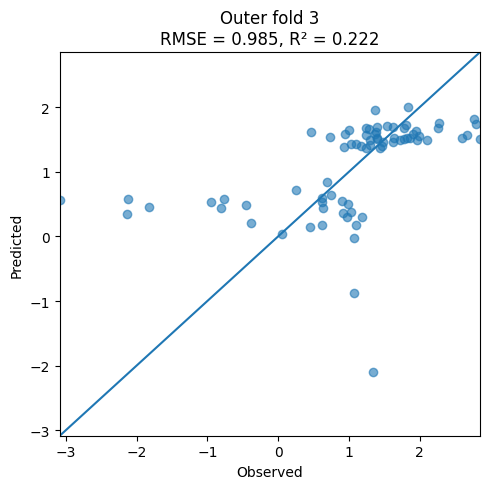

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_29_outerfold_03.json


[I 2026-10-24 00:48:54,699] A new study created in memory with name: no-name-9196a02c-358f-436c-bb8a-547e068b1e93


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_29_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:48:56,610] Trial 0 finished with value: 0.9008513400435603 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9008513400435603.
[I 2026-10-24 00:48:59,117] Trial 1 finished with value: 0.9772349725384151 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9008513400435603.
[I 2026-10-24 00:48:59,511] Trial 2 finished with value: 0.9596824237557889 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9008513400435603.
[I 2026-10-24 00:48:59,971] Trial 3 finished with value: 0.9401663459640943 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9623 R2 = 0.3973


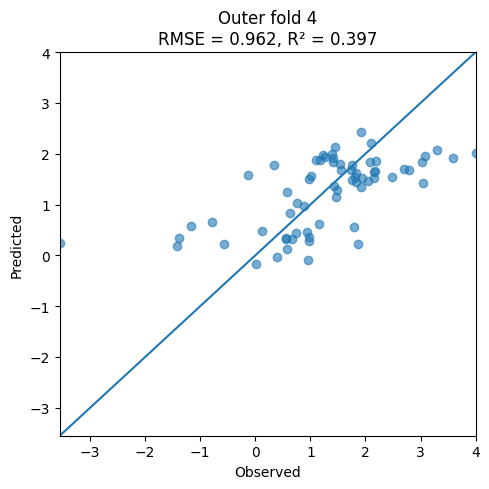

[I 2026-10-24 00:50:31,792] A new study created in memory with name: no-name-6d79b3ad-009d-4872-8621-a85bcec486e5


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_29_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_29_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:50:32,269] Trial 0 finished with value: 0.9565014022918964 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9565014022918964.
[I 2026-10-24 00:50:32,899] Trial 1 finished with value: 1.0206787456338393 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9565014022918964.
[I 2026-10-24 00:50:33,295] Trial 2 finished with value: 0.9908622609863883 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9565014022918964.
[I 2026-10-24 00:50:33,813] Trial 3 finished with value: 0.946452752155886 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8585 R2 = 0.1776


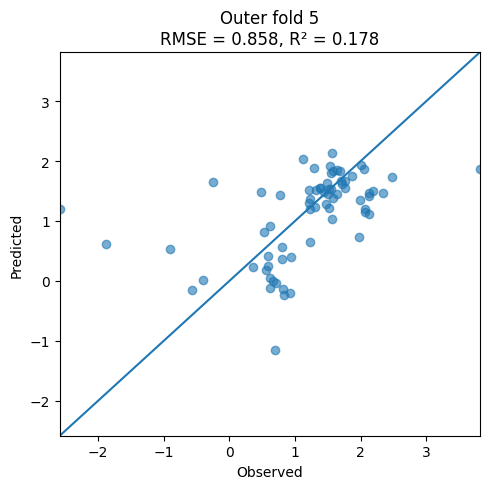

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_29_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_29_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9203 (+/- 0.0520)
Mean R2 (Outer CV): 0.3133 (+/- 0.0966)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 30]


[I 2026-10-24 00:51:47,098] A new study created in memory with name: no-name-20720a6d-d349-40d9-b8e3-39aeca707ad5


Resuming from existing file. Found 534 previous runs.
Running rs=285, targetTW=30
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:51:48,396] Trial 0 finished with value: 0.9694751795825864 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9694751795825864.
[I 2026-10-24 00:51:50,655] Trial 1 finished with value: 1.044658901258281 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9694751795825864.
[I 2026-10-24 00:51:51,043] Trial 2 finished with value: 0.9920086989453969 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9694751795825864.
[I 2026-10-24 00:51:51,571] Trial 3 finished with value: 0.9486963699652408 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.8613 R2 = 0.3486


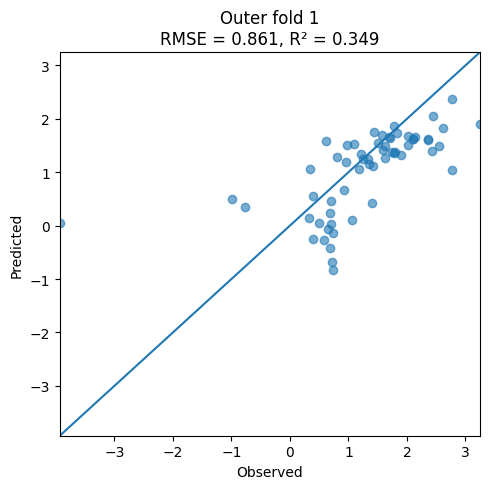

[I 2026-10-24 00:53:15,365] A new study created in memory with name: no-name-616bc5e9-c30e-46e9-965e-f7232835b211


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_30_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_30_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:53:15,808] Trial 0 finished with value: 0.9579025721295457 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9579025721295457.
[I 2026-10-24 00:53:16,376] Trial 1 finished with value: 0.9806102404046778 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9579025721295457.
[I 2026-10-24 00:53:16,743] Trial 2 finished with value: 0.9989655065148122 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9579025721295457.
[I 2026-10-24 00:53:17,197] Trial 3 finished with value: 0.963805960750243 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8974 R2 = 0.4662


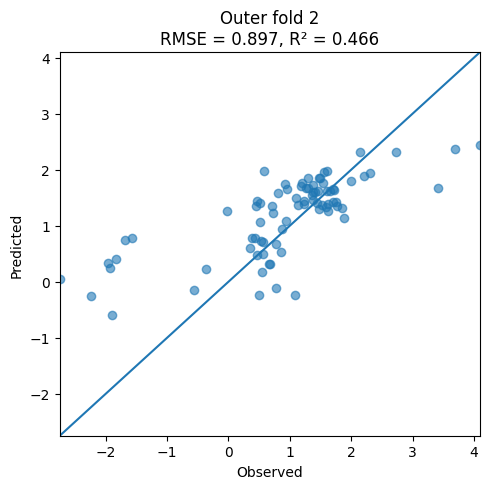

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_30_outerfold_02.json


[I 2026-10-24 00:54:34,254] A new study created in memory with name: no-name-3bae8028-664e-40cd-b3f7-79cd52bec5eb


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_30_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:54:34,824] Trial 0 finished with value: 0.9686336033618248 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9686336033618248.
[I 2026-10-24 00:54:35,409] Trial 1 finished with value: 0.9957543370832256 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9686336033618248.
[I 2026-10-24 00:54:35,792] Trial 2 finished with value: 0.9738583024002877 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9686336033618248.
[I 2026-10-24 00:54:36,303] Trial 3 finished with value: 0.9550957721768785 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.8993 R2 = 0.3513


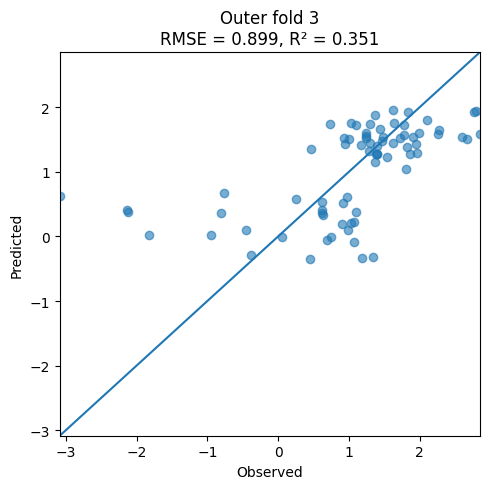

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_30_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_30_outerfold_03_meta.json

=== Outer fold 4/5 ===


[I 2026-10-24 00:55:57,425] A new study created in memory with name: no-name-6de95933-4a5a-4f01-88af-c21532bbef81


Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:55:58,050] Trial 0 finished with value: 0.9152909881064026 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9152909881064026.
[I 2026-10-24 00:55:58,611] Trial 1 finished with value: 0.9662570994948083 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9152909881064026.
[I 2026-10-24 00:55:59,020] Trial 2 finished with value: 0.9432213767381521 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9152909881064026.
[I 2026-10-24 00:55:59,497] Trial 3 finished with value: 0.9078836092561788 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9645 R2 = 0.3946


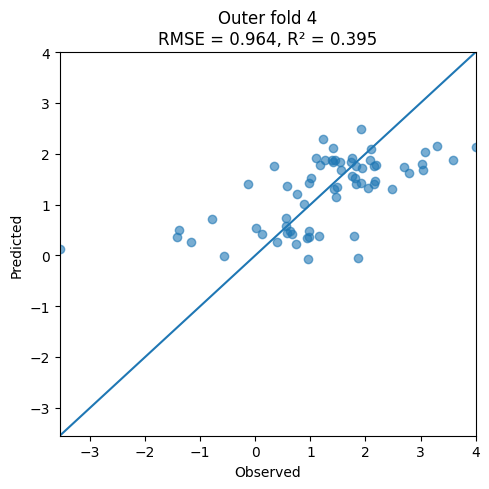

[I 2026-10-24 00:57:34,858] A new study created in memory with name: no-name-5746eaba-73f1-449b-85d4-5e53e09e3d58


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_30_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_30_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:57:35,352] Trial 0 finished with value: 0.9574226175705243 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9574226175705243.
[I 2026-10-24 00:57:35,959] Trial 1 finished with value: 0.9927484431202813 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9574226175705243.
[I 2026-10-24 00:57:36,313] Trial 2 finished with value: 1.0245454490572667 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9574226175705243.
[I 2026-10-24 00:57:36,840] Trial 3 finished with value: 0.9772848772168815 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8070 R2 = 0.2733


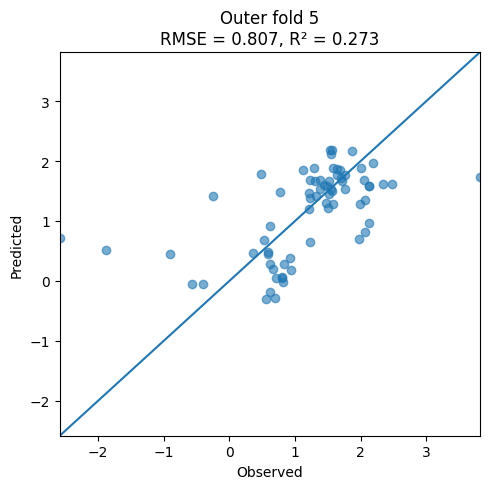

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_30_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_285_TW_30_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8859 (+/- 0.0516)
Mean R2 (Outer CV): 0.3668 (+/- 0.0632)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 1]


[I 2026-10-24 00:58:57,572] A new study created in memory with name: no-name-24f13e5b-36f5-4e1b-ae4a-54a1a0a5c479


Resuming from existing file. Found 540 previous runs.
Running rs=966, targetTW=1
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 00:58:58,054] Trial 0 finished with value: 0.858627482239264 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.858627482239264.
[I 2026-10-24 00:58:58,633] Trial 1 finished with value: 0.9072078696720403 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.858627482239264.
[I 2026-10-24 00:58:59,036] Trial 2 finished with value: 0.9205618147133896 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.858627482239264.
[I 2026-10-24 00:58:59,510] Trial 3 finished with value: 0.8805708188969299 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.1344 R2 = 0.2483


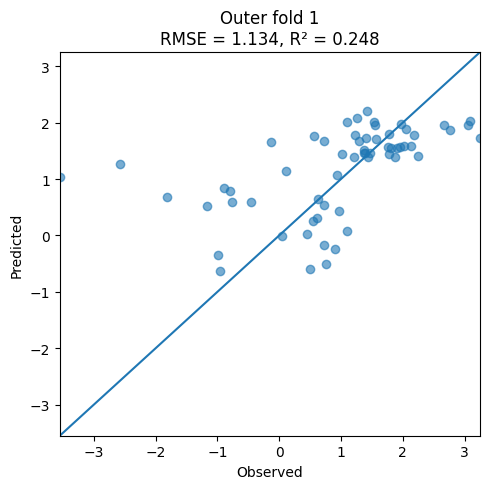

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_01_outerfold_01.json


[I 2026-10-24 01:00:12,256] A new study created in memory with name: no-name-ddc5ce44-2e28-4f99-9655-bd31f8dfd7a7


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_01_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:00:12,838] Trial 0 finished with value: 0.9986793543793537 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9986793543793537.
[I 2026-10-24 01:00:13,452] Trial 1 finished with value: 0.9883361094573375 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9883361094573375.
[I 2026-10-24 01:00:13,825] Trial 2 finished with value: 0.9947596914982985 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9883361094573375.
[I 2026-10-24 01:00:14,342] Trial 3 finished with value: 0.9764145065945656 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9218 R2 = 0.3124


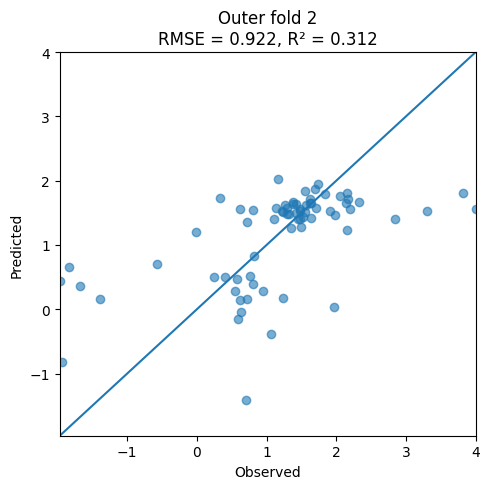

[I 2026-10-24 01:01:21,542] A new study created in memory with name: no-name-0a92c8e2-c18c-4a4f-9e02-0b78600289b8


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_01_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_01_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:01:22,076] Trial 0 finished with value: 0.8856914724969872 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8856914724969872.
[I 2026-10-24 01:01:22,696] Trial 1 finished with value: 0.9202176116374821 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8856914724969872.
[I 2026-10-24 01:01:23,083] Trial 2 finished with value: 0.9843878101841003 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8856914724969872.
[I 2026-10-24 01:01:23,616] Trial 3 finished with value: 0.9166284020553451 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0711 R2 = 0.3220


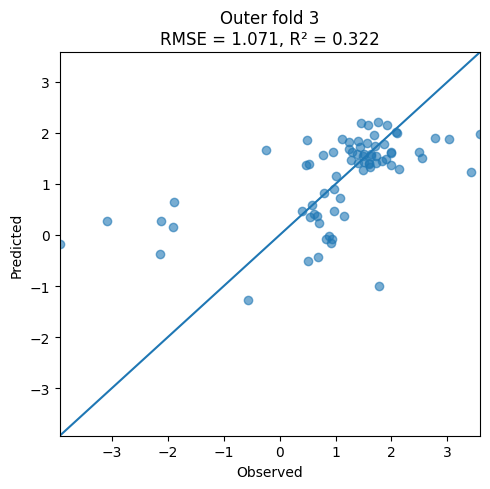

[I 2026-10-24 01:02:56,291] A new study created in memory with name: no-name-06f98a77-98a7-4d9e-a88f-5cc5fa292ffe


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_01_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_01_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:02:57,088] Trial 0 finished with value: 0.9702800046331808 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9702800046331808.
[I 2026-10-24 01:02:57,677] Trial 1 finished with value: 1.0354893569935655 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9702800046331808.
[I 2026-10-24 01:02:58,071] Trial 2 finished with value: 0.990721035179266 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9702800046331808.
[I 2026-10-24 01:02:58,551] Trial 3 finished with value: 0.9933144465697308 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9631 R2 = 0.1733


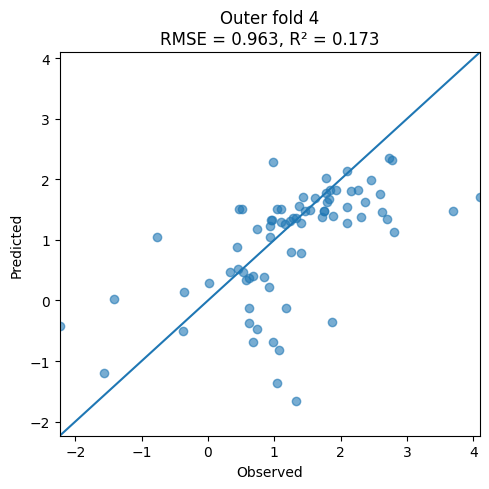

[I 2026-10-24 01:04:13,701] A new study created in memory with name: no-name-bf2702af-8c37-4182-a6ce-59d89d17dacf


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_01_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_01_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:04:14,243] Trial 0 finished with value: 1.048010256456218 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.048010256456218.
[I 2026-10-24 01:04:14,846] Trial 1 finished with value: 1.1166867578317392 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.048010256456218.
[I 2026-10-24 01:04:15,272] Trial 2 finished with value: 1.0341113985256079 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 1.0341113985256079.
[I 2026-10-24 01:04:15,767] Trial 3 finished with value: 1.1029547971298952 and parameters: {'max_depth': 3

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.7385 R2 = 0.2202


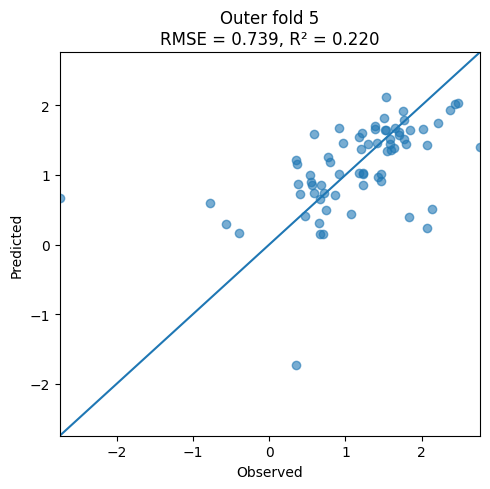

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_01_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_01_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9658 (+/- 0.1365)
Mean R2 (Outer CV): 0.2552 (+/- 0.0560)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 2]


[I 2026-10-24 01:05:28,253] A new study created in memory with name: no-name-660017a5-2162-4f6e-8a11-9cf7aeec530a


Resuming from existing file. Found 546 previous runs.
Running rs=966, targetTW=2
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:05:28,794] Trial 0 finished with value: 0.8979592649498556 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8979592649498556.
[I 2026-10-24 01:05:29,438] Trial 1 finished with value: 0.9039224236626175 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8979592649498556.
[I 2026-10-24 01:05:30,040] Trial 2 finished with value: 0.9371822493072358 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8979592649498556.
[I 2026-10-24 01:05:32,212] Trial 3 finished with value: 0.8844497059097471 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0747 R2 = 0.3255


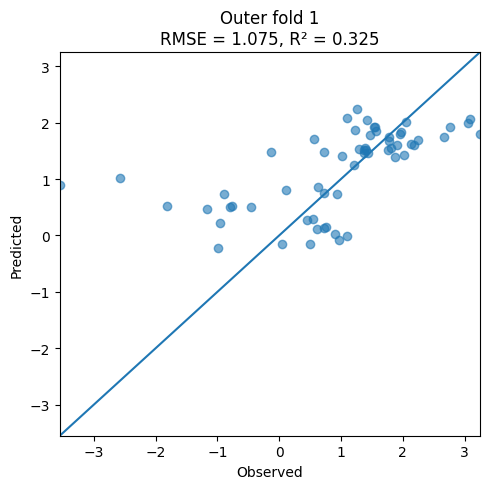

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_02_outerfold_01.json


[I 2026-10-24 01:07:03,513] A new study created in memory with name: no-name-fd49b850-cc9f-453f-a1f7-8bf555a1ae8a


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_02_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:07:04,088] Trial 0 finished with value: 0.938007609927523 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.938007609927523.
[I 2026-10-24 01:07:04,681] Trial 1 finished with value: 0.9709832318761138 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.938007609927523.
[I 2026-10-24 01:07:05,067] Trial 2 finished with value: 0.9846016293508312 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.938007609927523.
[I 2026-10-24 01:07:05,565] Trial 3 finished with value: 0.9275035255930889 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9621 R2 = 0.2508


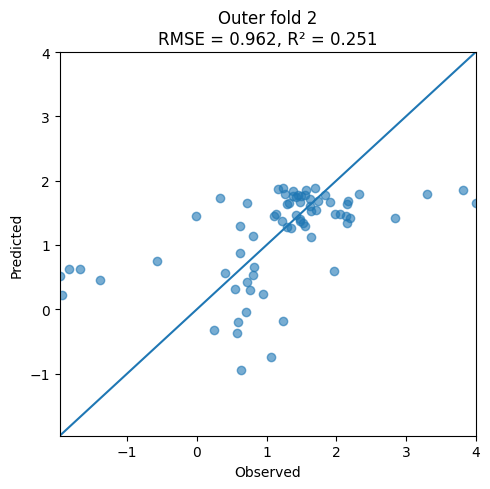

[I 2026-10-24 01:08:29,779] A new study created in memory with name: no-name-7a02285d-fc4c-4ddf-94cb-241da628ebf1


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_02_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_02_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:08:30,293] Trial 0 finished with value: 0.9509802036617905 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9509802036617905.
[I 2026-10-24 01:08:30,876] Trial 1 finished with value: 1.0098528810521312 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9509802036617905.
[I 2026-10-24 01:08:31,227] Trial 2 finished with value: 1.0044169319720946 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9509802036617905.
[I 2026-10-24 01:08:31,741] Trial 3 finished with value: 1.0025934058404204 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0657 R2 = 0.3288


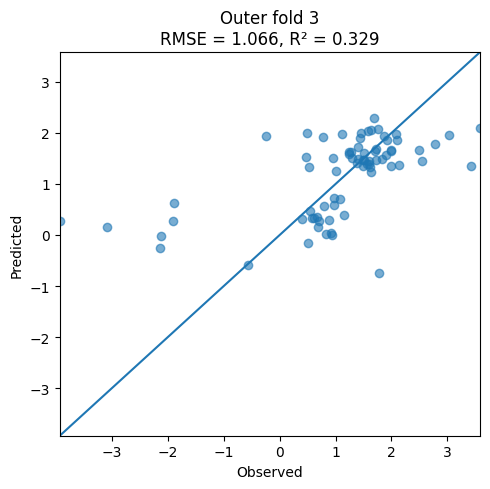

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_02_outerfold_03.json


[I 2026-10-24 01:10:06,376] A new study created in memory with name: no-name-5de83cf4-52ac-490b-a241-b71b45977605


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_02_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:10:06,980] Trial 0 finished with value: 0.9874298248261035 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9874298248261035.
[I 2026-10-24 01:10:07,614] Trial 1 finished with value: 1.0526984183548556 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9874298248261035.
[I 2026-10-24 01:10:07,995] Trial 2 finished with value: 1.0035863540618404 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9874298248261035.
[I 2026-10-24 01:10:08,532] Trial 3 finished with value: 1.0014822155338612 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9284 R2 = 0.2317


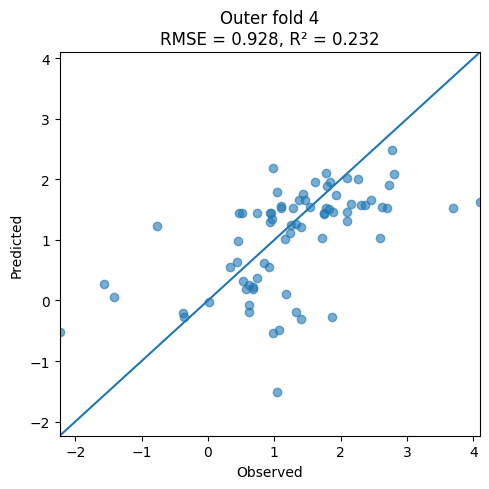

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_02_outerfold_04.json


[I 2026-10-24 01:11:22,441] A new study created in memory with name: no-name-474ff9cb-78ad-44c8-8303-42d18da69f30


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_02_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:11:23,072] Trial 0 finished with value: 1.0645638570996234 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0645638570996234.
[I 2026-10-24 01:11:23,666] Trial 1 finished with value: 1.1536511046631783 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0645638570996234.
[I 2026-10-24 01:11:24,111] Trial 2 finished with value: 1.0755638179079385 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0645638570996234.
[I 2026-10-24 01:11:24,580] Trial 3 finished with value: 1.0854588797555649 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6724 R2 = 0.3535


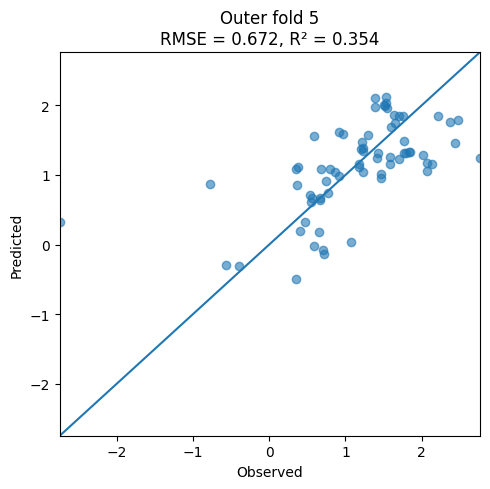

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_02_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_02_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9407 (+/- 0.1457)
Mean R2 (Outer CV): 0.2981 (+/- 0.0478)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 3]


[I 2026-10-24 01:13:03,936] A new study created in memory with name: no-name-654cafe4-8524-4bd1-bbc6-c3bb13c42d8c


Resuming from existing file. Found 552 previous runs.
Running rs=966, targetTW=3
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:13:04,386] Trial 0 finished with value: 0.8967348758340478 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8967348758340478.
[I 2026-10-24 01:13:05,069] Trial 1 finished with value: 0.988989308223632 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8967348758340478.
[I 2026-10-24 01:13:06,225] Trial 2 finished with value: 0.9824561497112394 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8967348758340478.
[I 2026-10-24 01:13:08,901] Trial 3 finished with value: 0.9491571276376696 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0780 R2 = 0.3212


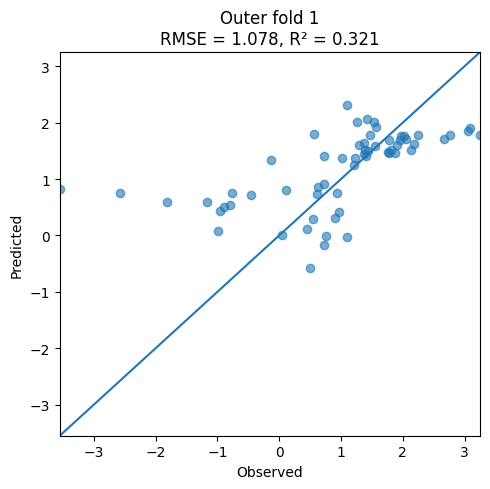

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_03_outerfold_01.json


[I 2026-10-24 01:14:39,091] A new study created in memory with name: no-name-4fb35916-1812-4a30-8ce6-40064f4b69c8


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_03_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:14:39,819] Trial 0 finished with value: 0.9368166336305873 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9368166336305873.
[I 2026-10-24 01:14:40,452] Trial 1 finished with value: 1.0213274854469154 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9368166336305873.
[I 2026-10-24 01:14:40,915] Trial 2 finished with value: 1.0103011002589348 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9368166336305873.
[I 2026-10-24 01:14:41,453] Trial 3 finished with value: 0.9670891591946241 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9558 R2 = 0.2606


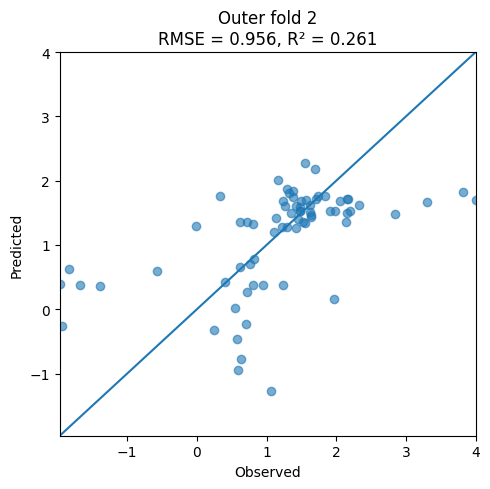

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_03_outerfold_02.json


[I 2026-10-24 01:16:11,570] A new study created in memory with name: no-name-28494fe6-d46f-4a96-b0ac-943b8a77ed6d


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_03_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:16:12,274] Trial 0 finished with value: 0.9192426182637142 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9192426182637142.
[I 2026-10-24 01:16:12,852] Trial 1 finished with value: 1.0480251235434612 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9192426182637142.
[I 2026-10-24 01:16:13,802] Trial 2 finished with value: 1.0203423372999771 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9192426182637142.
[I 2026-10-24 01:16:16,868] Trial 3 finished with value: 0.9660175161786505 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0344 R2 = 0.3677


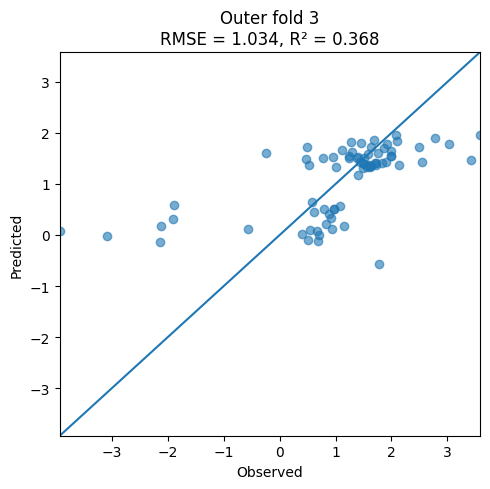

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_03_outerfold_03.json


[I 2026-10-24 01:17:37,158] A new study created in memory with name: no-name-c6c8f286-1778-42a9-add9-a499059d164a


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_03_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:17:37,865] Trial 0 finished with value: 1.003783153449583 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.003783153449583.
[I 2026-10-24 01:17:38,438] Trial 1 finished with value: 1.1076617939977185 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.003783153449583.
[I 2026-10-24 01:17:38,865] Trial 2 finished with value: 1.061221221284474 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.003783153449583.
[I 2026-10-24 01:17:39,336] Trial 3 finished with value: 1.0523218576080957 and parameters: {'max_depth': 3, 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9230 R2 = 0.2407


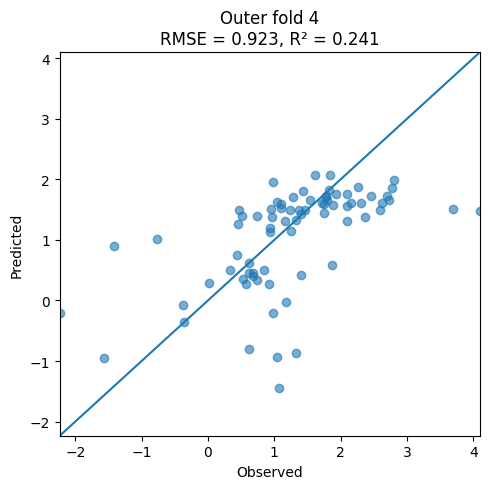

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_03_outerfold_04.json


[I 2026-10-24 01:19:03,002] A new study created in memory with name: no-name-8985a471-a4cc-407c-96cc-b2daa4d419ea


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_03_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:19:03,693] Trial 0 finished with value: 1.0683495786362271 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0683495786362271.
[I 2026-10-24 01:19:04,279] Trial 1 finished with value: 1.0953883080253914 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0683495786362271.
[I 2026-10-24 01:19:04,721] Trial 2 finished with value: 1.070209677674619 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0683495786362271.
[I 2026-10-24 01:19:05,951] Trial 3 finished with value: 1.0914347864242482 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6693 R2 = 0.3596


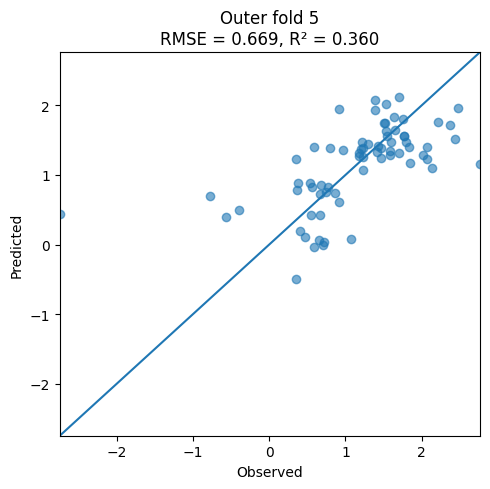

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_03_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_03_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9321 (+/- 0.1425)
Mean R2 (Outer CV): 0.3100 (+/- 0.0513)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 4]


[I 2026-10-24 01:21:05,428] A new study created in memory with name: no-name-1e07ed12-953a-4aff-8fdd-803f212f0acd


Resuming from existing file. Found 558 previous runs.
Running rs=966, targetTW=4
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:21:05,932] Trial 0 finished with value: 0.8821687869031568 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8821687869031568.
[I 2026-10-24 01:21:06,538] Trial 1 finished with value: 0.9332206533400025 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8821687869031568.
[I 2026-10-24 01:21:06,973] Trial 2 finished with value: 0.9019460009747171 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8821687869031568.
[I 2026-10-24 01:21:07,514] Trial 3 finished with value: 0.8877486126606013 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0610 R2 = 0.3425


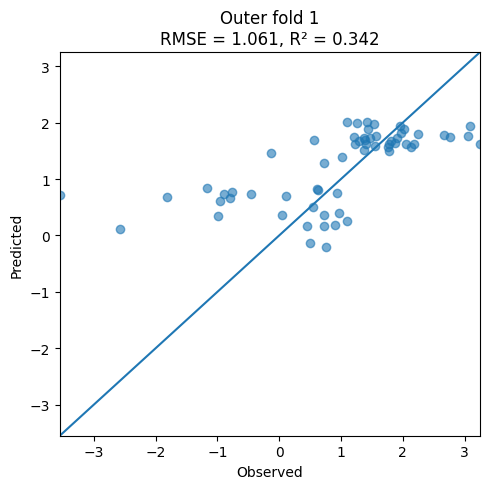

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_04_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_04_outerfold_01_meta.json

=== Outer fold 2/5 ===


[I 2026-10-24 01:22:21,888] A new study created in memory with name: no-name-18421c73-06fd-4c85-bd3d-978d25a59998


Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:22:22,520] Trial 0 finished with value: 0.9362815270498328 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9362815270498328.
[I 2026-10-24 01:22:23,151] Trial 1 finished with value: 1.0132247408513118 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9362815270498328.
[I 2026-10-24 01:22:23,549] Trial 2 finished with value: 0.9940006070712951 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9362815270498328.
[I 2026-10-24 01:22:24,065] Trial 3 finished with value: 0.9444748648498249 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9556 R2 = 0.2610


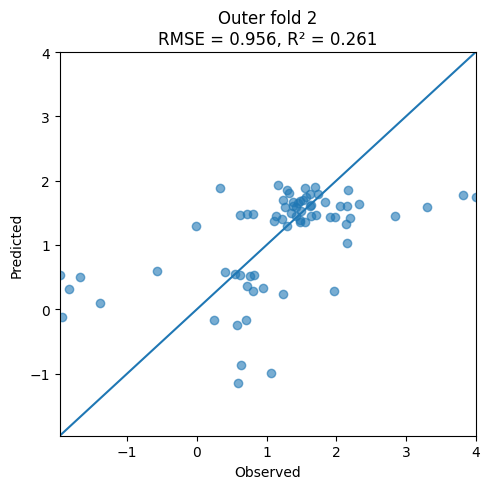

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_04_outerfold_02.json


[I 2026-10-24 01:24:01,599] A new study created in memory with name: no-name-004c8d9d-0510-4ca6-84b5-6c7fba5f9689


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_04_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:24:02,300] Trial 0 finished with value: 0.9309804485070918 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9309804485070918.
[I 2026-10-24 01:24:02,889] Trial 1 finished with value: 1.0257176073393668 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9309804485070918.
[I 2026-10-24 01:24:03,311] Trial 2 finished with value: 0.9568877812885724 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9309804485070918.
[I 2026-10-24 01:24:03,823] Trial 3 finished with value: 0.9507569314203963 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9873 R2 = 0.4239


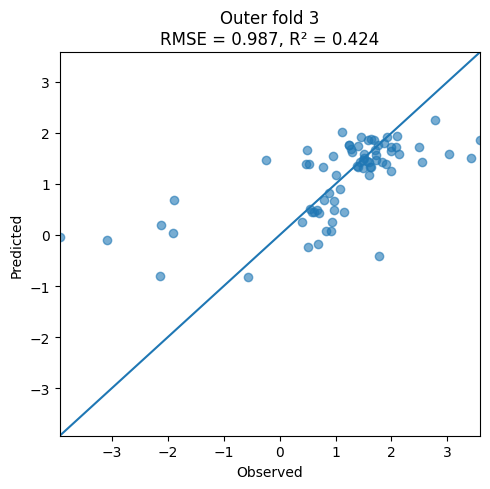

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_04_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_04_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']


[I 2026-10-24 01:25:50,979] A new study created in memory with name: no-name-fd81d53b-12ee-49aa-a1c5-0806eecdcd8b


Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:25:51,666] Trial 0 finished with value: 1.016781273756504 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.016781273756504.
[I 2026-10-24 01:25:52,247] Trial 1 finished with value: 1.074110279126771 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.016781273756504.
[I 2026-10-24 01:25:52,685] Trial 2 finished with value: 1.0032678448269112 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 1.0032678448269112.
[I 2026-10-24 01:25:53,176] Trial 3 finished with value: 1.0433497200587194 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 1.0188 R2 = 0.0749


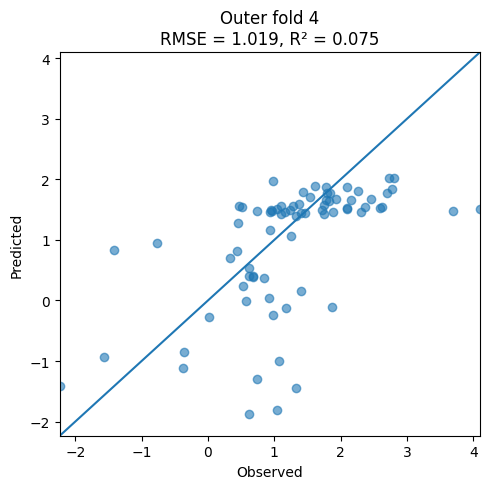

[I 2026-10-24 01:27:07,421] A new study created in memory with name: no-name-aa69b946-29d4-4ecb-979b-ceea31e66495


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_04_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_04_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:27:07,984] Trial 0 finished with value: 1.0213718846111217 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0213718846111217.
[I 2026-10-24 01:27:08,597] Trial 1 finished with value: 1.0709998426996536 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0213718846111217.
[I 2026-10-24 01:27:09,000] Trial 2 finished with value: 1.060715885946862 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0213718846111217.
[I 2026-10-24 01:27:10,806] Trial 3 finished with value: 1.0242237948915667 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6918 R2 = 0.3157


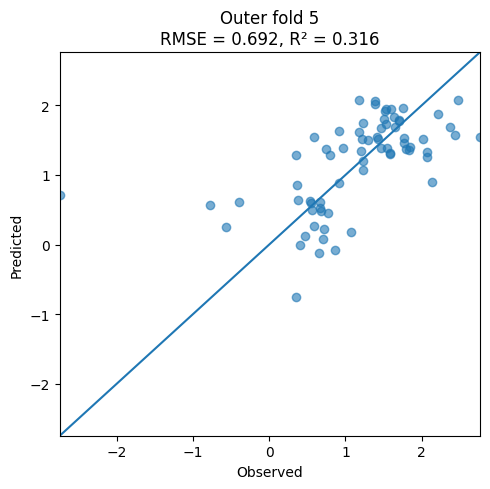

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_04_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_04_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9429 (+/- 0.1303)
Mean R2 (Outer CV): 0.2836 (+/- 0.1168)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 5]


[I 2026-10-24 01:28:56,383] A new study created in memory with name: no-name-2b930773-6ae0-417b-bf79-20fdfdd04aed


Resuming from existing file. Found 564 previous runs.
Running rs=966, targetTW=5
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:28:56,865] Trial 0 finished with value: 0.8880859760848043 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8880859760848043.
[I 2026-10-24 01:28:57,475] Trial 1 finished with value: 0.9203111279243211 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8880859760848043.
[I 2026-10-24 01:28:57,924] Trial 2 finished with value: 0.9223737471327765 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8880859760848043.
[I 2026-10-24 01:28:58,437] Trial 3 finished with value: 0.8735700692085147 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0907 R2 = 0.3052


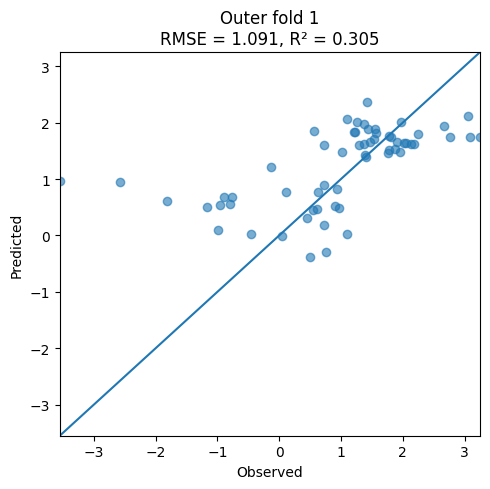

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_05_outerfold_01.json


[I 2026-10-24 01:30:24,389] A new study created in memory with name: no-name-3d161c4a-dabb-42ea-b8fa-bc4d05acabc8


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_05_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:30:25,038] Trial 0 finished with value: 0.9325794576497924 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9325794576497924.
[I 2026-10-24 01:30:25,632] Trial 1 finished with value: 0.9894532770790243 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9325794576497924.
[I 2026-10-24 01:30:26,041] Trial 2 finished with value: 0.9726608713173277 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9325794576497924.
[I 2026-10-24 01:30:26,540] Trial 3 finished with value: 0.9827784796286514 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9024 R2 = 0.3410


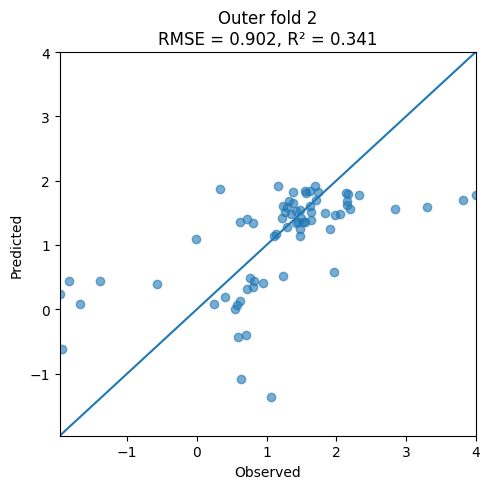

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_05_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_05_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:31:40,685] A new study created in memory with name: no-name-08fc148b-b265-49dc-8f28-6878cd482b08
[I 2026-10-24 01:31:41,665] Trial 0 finished with value: 0.9226258197002563 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9226258197002563.
[I 2026-10-24 01:31:44,625] Trial 1 finished with value: 1.0008505257117148 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9226258197002563.
[I 2026-10-24 01:31:45,446] Trial 2 finished with value: 0.9779147513704611 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.92262581

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0915 R2 = 0.2959


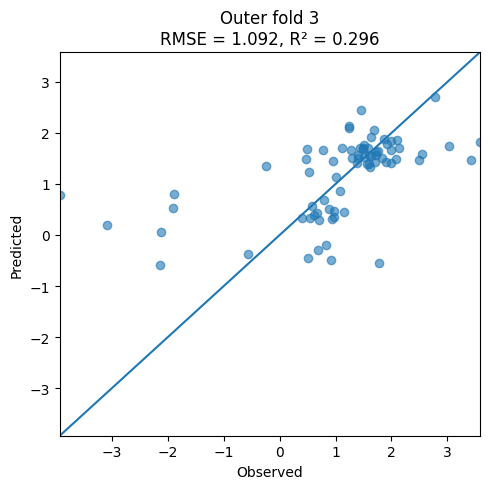

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_05_outerfold_03.json


[I 2026-10-24 01:33:02,792] A new study created in memory with name: no-name-6f2e103b-5eef-4a6f-9ebe-39abf9b75d0d


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_05_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:33:03,554] Trial 0 finished with value: 1.0004202194170067 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0004202194170067.
[I 2026-10-24 01:33:04,127] Trial 1 finished with value: 1.0675496002537965 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0004202194170067.
[I 2026-10-24 01:33:04,564] Trial 2 finished with value: 1.0176353757848102 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0004202194170067.
[I 2026-10-24 01:33:05,056] Trial 3 finished with value: 1.0067917182359463 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9534 R2 = 0.1899


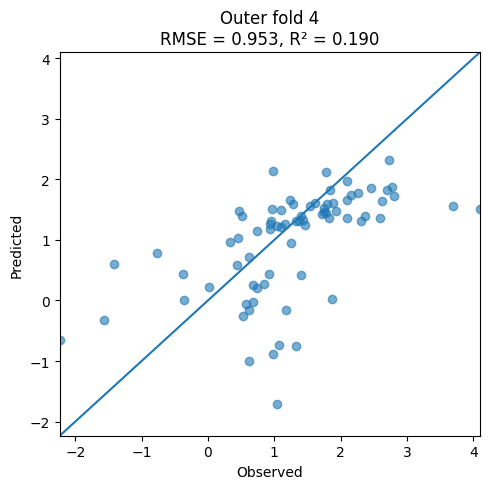

[I 2026-10-24 01:34:28,274] A new study created in memory with name: no-name-1c9775e7-3e4e-4f04-8c36-eafdfc4b77fa


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_05_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_05_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:34:28,920] Trial 0 finished with value: 1.012413918000402 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.012413918000402.
[I 2026-10-24 01:34:29,630] Trial 1 finished with value: 1.1233014563776098 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.012413918000402.
[I 2026-10-24 01:34:30,055] Trial 2 finished with value: 1.1039895987375727 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.012413918000402.
[I 2026-10-24 01:34:30,629] Trial 3 finished with value: 1.0458474134839677 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6611 R2 = 0.3752


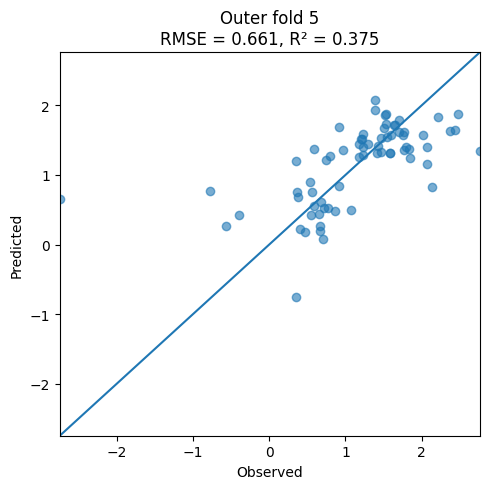

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_05_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_05_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9398 (+/- 0.1581)
Mean R2 (Outer CV): 0.3014 (+/- 0.0624)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 6]


[I 2026-10-24 01:36:25,115] A new study created in memory with name: no-name-80c8970e-4a6d-4a04-a680-6eee3d5ced28


Resuming from existing file. Found 570 previous runs.
Running rs=966, targetTW=6
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:36:25,638] Trial 0 finished with value: 0.8914132116714446 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8914132116714446.
[I 2026-10-24 01:36:26,248] Trial 1 finished with value: 0.9486873019090276 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8914132116714446.
[I 2026-10-24 01:36:26,671] Trial 2 finished with value: 0.9423063399663585 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8914132116714446.
[I 2026-10-24 01:36:27,179] Trial 3 finished with value: 0.8824985972744017 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0789 R2 = 0.3202


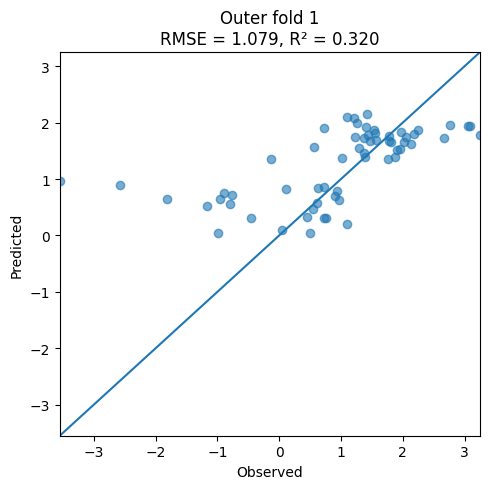

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_06_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_06_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:37:47,998] A new study created in memory with name: no-name-45dd0819-5a81-4d9a-9397-2b6d34ffcbb0
[I 2026-10-24 01:37:48,641] Trial 0 finished with value: 0.9535893754563436 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9535893754563436.
[I 2026-10-24 01:37:49,219] Trial 1 finished with value: 0.9819039280846019 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9535893754563436.
[I 2026-10-24 01:37:49,680] Trial 2 finished with value: 0.9794341211371906 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.95358937

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9307 R2 = 0.2989


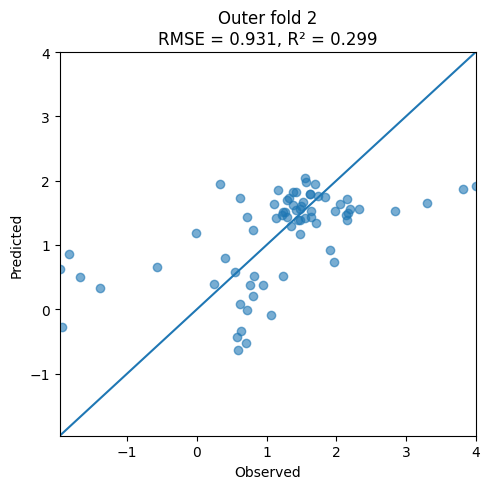

[I 2026-10-24 01:39:09,507] A new study created in memory with name: no-name-d8dd1101-dd26-4429-8512-9310e8c88a3d


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_06_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_06_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:39:10,144] Trial 0 finished with value: 0.9095016315582263 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9095016315582263.
[I 2026-10-24 01:39:10,706] Trial 1 finished with value: 0.9842616981040477 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9095016315582263.
[I 2026-10-24 01:39:11,096] Trial 2 finished with value: 0.9879348624277318 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9095016315582263.
[I 2026-10-24 01:39:11,602] Trial 3 finished with value: 0.967062805439313 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0670 R2 = 0.3272


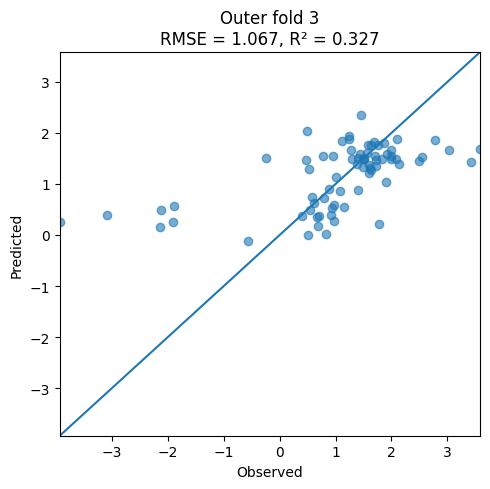

[I 2026-10-24 01:40:48,878] A new study created in memory with name: no-name-e0f792ef-a303-4627-ae63-16eaebbf1151


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_06_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_06_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:40:49,506] Trial 0 finished with value: 1.0188157648690939 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0188157648690939.
[I 2026-10-24 01:40:50,205] Trial 1 finished with value: 1.0754101537439635 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0188157648690939.
[I 2026-10-24 01:40:50,642] Trial 2 finished with value: 1.0554211524039934 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0188157648690939.
[I 2026-10-24 01:40:51,206] Trial 3 finished with value: 1.0463266542592136 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 1.0092 R2 = 0.0922


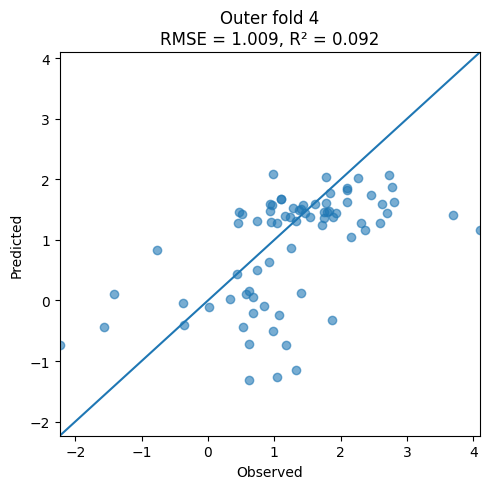

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_06_outerfold_04.json


[I 2026-10-24 01:42:06,450] A new study created in memory with name: no-name-b027f215-2c92-4d65-be41-451d9e04ae75


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_06_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:42:07,181] Trial 0 finished with value: 1.0273954307808375 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0273954307808375.
[I 2026-10-24 01:42:07,797] Trial 1 finished with value: 1.0593877043508442 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0273954307808375.
[I 2026-10-24 01:42:08,213] Trial 2 finished with value: 1.0629610751109524 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0273954307808375.
[I 2026-10-24 01:42:09,476] Trial 3 finished with value: 0.9741457195820408 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.7326 R2 = 0.2326


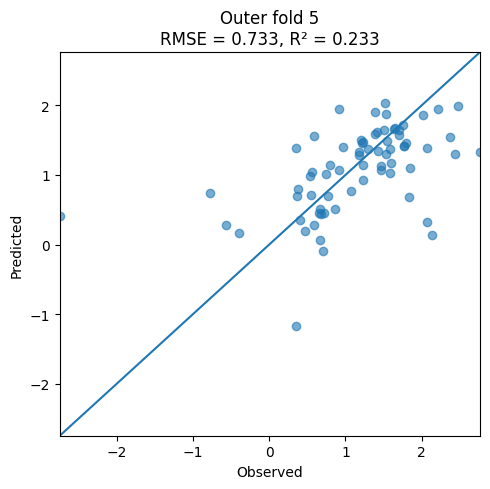

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_06_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_06_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9637 (+/- 0.1269)
Mean R2 (Outer CV): 0.2542 (+/- 0.0876)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 7]


[I 2026-10-24 01:43:46,436] A new study created in memory with name: no-name-9adcf204-cf03-449d-b143-54235e14efb4


Resuming from existing file. Found 576 previous runs.
Running rs=966, targetTW=7
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:43:47,036] Trial 0 finished with value: 0.9078875197481844 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9078875197481844.
[I 2026-10-24 01:43:47,611] Trial 1 finished with value: 0.9706174643533769 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9078875197481844.
[I 2026-10-24 01:43:48,116] Trial 2 finished with value: 0.9551792631953504 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9078875197481844.
[I 2026-10-24 01:43:49,960] Trial 3 finished with value: 0.9061009831552064 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0927 R2 = 0.3026


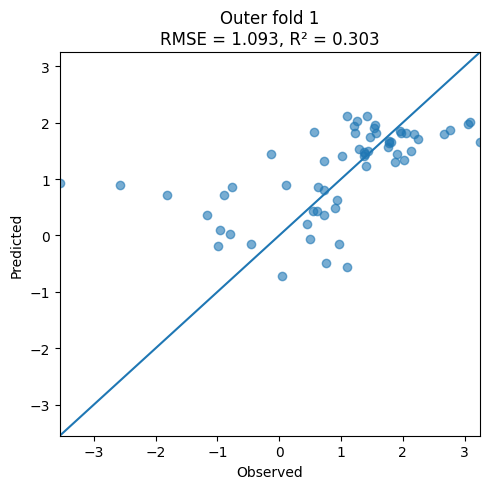

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_07_outerfold_01.json


[I 2026-10-24 01:45:20,748] A new study created in memory with name: no-name-03c44b0d-b902-4b26-8162-2967d6738ea8


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_07_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:45:21,437] Trial 0 finished with value: 0.94705805719611 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.94705805719611.
[I 2026-10-24 01:45:22,046] Trial 1 finished with value: 1.0263383315260606 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.94705805719611.
[I 2026-10-24 01:45:22,449] Trial 2 finished with value: 0.9824692448313399 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.94705805719611.
[I 2026-10-24 01:45:22,985] Trial 3 finished with value: 0.972152617102595 and parameters: {'max_depth': 3, 'gam

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 1.0357 R2 = 0.1319


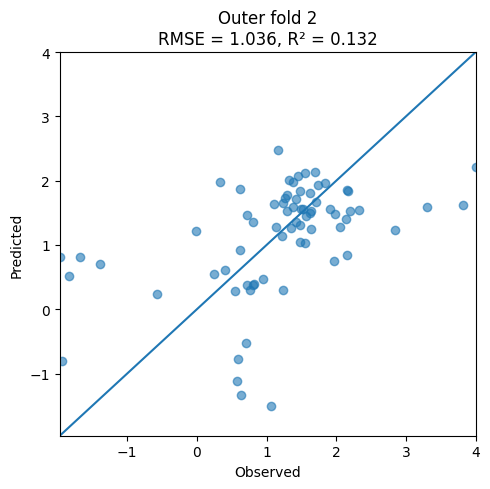

[I 2026-10-24 01:46:32,638] A new study created in memory with name: no-name-3a48d30a-093b-43b9-b45c-067fb315b244


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_07_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_07_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:46:33,275] Trial 0 finished with value: 0.9388068839356267 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9388068839356267.
[I 2026-10-24 01:46:33,923] Trial 1 finished with value: 0.9719958525000079 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9388068839356267.
[I 2026-10-24 01:46:34,352] Trial 2 finished with value: 0.9905935925354447 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9388068839356267.
[I 2026-10-24 01:46:34,870] Trial 3 finished with value: 0.967206353147846 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0999 R2 = 0.2851


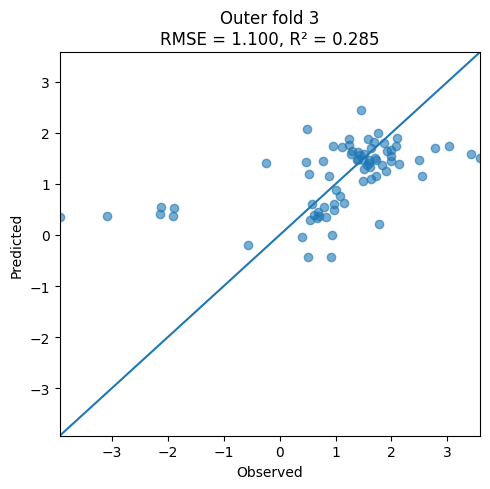

[I 2026-10-24 01:47:50,920] A new study created in memory with name: no-name-b4fcb76b-32ef-49ef-a7b6-25de0640667b


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_07_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_07_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:47:51,605] Trial 0 finished with value: 1.0169885141974953 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0169885141974953.
[I 2026-10-24 01:47:53,568] Trial 1 finished with value: 1.0725678606769309 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0169885141974953.
[I 2026-10-24 01:47:55,863] Trial 2 finished with value: 1.088380713240916 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0169885141974953.
[I 2026-10-24 01:47:56,407] Trial 3 finished with value: 1.0191316430163115 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8855 R2 = 0.3010


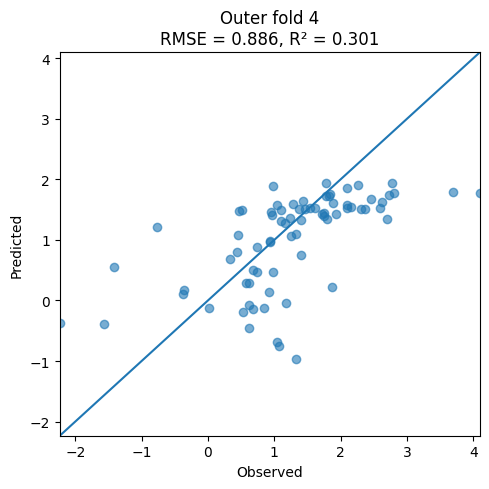

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_07_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_07_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:49:22,567] A new study created in memory with name: no-name-58e8c77b-4b85-446b-8f0d-51d7073db213
[I 2026-10-24 01:49:23,239] Trial 0 finished with value: 1.0684417104398585 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0684417104398585.
[I 2026-10-24 01:49:23,887] Trial 1 finished with value: 1.0874945805197047 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0684417104398585.
[I 2026-10-24 01:49:24,309] Trial 2 finished with value: 1.0117814713762918 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 1.01178147

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6819 R2 = 0.3352


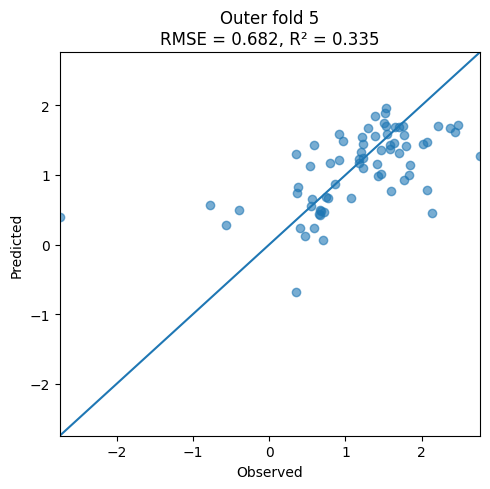

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_07_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_07_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9592 (+/- 0.1586)
Mean R2 (Outer CV): 0.2712 (+/- 0.0715)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 8]


[I 2026-10-24 01:50:57,364] A new study created in memory with name: no-name-d8989f15-b82a-449e-aa56-e3abeb018f4a


Resuming from existing file. Found 582 previous runs.
Running rs=966, targetTW=8
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:50:58,824] Trial 0 finished with value: 0.899518424904152 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.899518424904152.
[I 2026-10-24 01:51:01,167] Trial 1 finished with value: 0.9742551699794109 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.899518424904152.
[I 2026-10-24 01:51:01,579] Trial 2 finished with value: 0.910821957666154 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.899518424904152.
[I 2026-10-24 01:51:02,079] Trial 3 finished with value: 0.9191871644720312 and parameters: {'max_depth': 3, 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0851 R2 = 0.3123


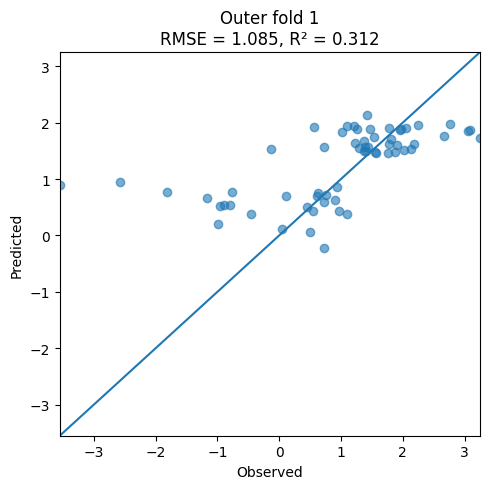

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_08_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_08_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']


[I 2026-10-24 01:52:30,107] A new study created in memory with name: no-name-f959965b-f57c-485a-980d-e553cc84d496


Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:52:30,872] Trial 0 finished with value: 0.959367806026925 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.959367806026925.
[I 2026-10-24 01:52:31,506] Trial 1 finished with value: 0.9705951453783892 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.959367806026925.
[I 2026-10-24 01:52:31,946] Trial 2 finished with value: 0.9894864704249042 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.959367806026925.
[I 2026-10-24 01:52:32,525] Trial 3 finished with value: 0.9825322430536254 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9400 R2 = 0.2849


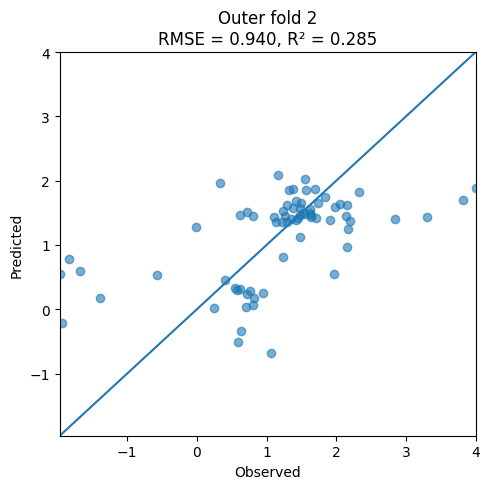

[I 2026-10-24 01:53:50,558] A new study created in memory with name: no-name-32a77941-a34d-4fe4-be3c-07d04f8ccd2c


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_08_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_08_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:53:52,849] Trial 0 finished with value: 0.90852542471053 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.90852542471053.
[I 2026-10-24 01:53:53,427] Trial 1 finished with value: 0.9856997803197374 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.90852542471053.
[I 2026-10-24 01:53:53,882] Trial 2 finished with value: 0.9373666035377362 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.90852542471053.
[I 2026-10-24 01:53:54,353] Trial 3 finished with value: 0.9279449241187642 and parameters: {'max_depth': 3, 'ga

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0797 R2 = 0.3111


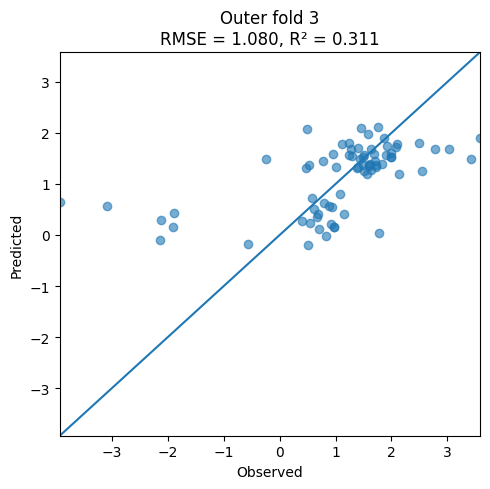

[I 2026-10-24 01:55:28,827] A new study created in memory with name: no-name-7b651a08-b801-4cdb-87b8-349c68be7a17


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_08_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_08_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:55:30,879] Trial 0 finished with value: 1.004282667043565 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.004282667043565.
[I 2026-10-24 01:55:33,424] Trial 1 finished with value: 1.088703360545237 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.004282667043565.
[I 2026-10-24 01:55:33,831] Trial 2 finished with value: 1.0922900377841218 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.004282667043565.
[I 2026-10-24 01:55:34,391] Trial 3 finished with value: 1.0688843443429552 and parameters: {'max_depth': 3, 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9332 R2 = 0.2237


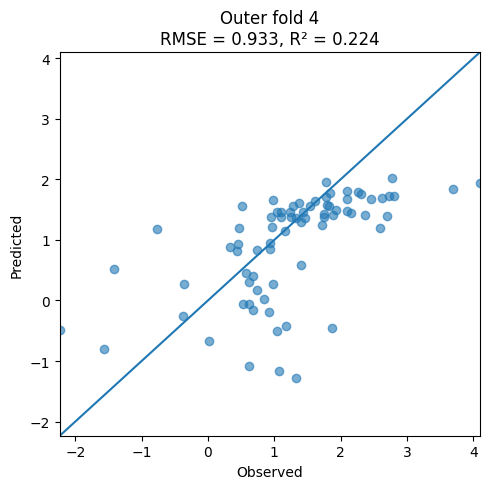

[I 2026-10-24 01:57:10,919] A new study created in memory with name: no-name-fb77c551-056e-4076-b0dc-874cca132cdf


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_08_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_08_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:57:12,301] Trial 0 finished with value: 1.022843158066813 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.022843158066813.
[I 2026-10-24 01:57:14,236] Trial 1 finished with value: 1.0930316889054703 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.022843158066813.
[I 2026-10-24 01:57:14,653] Trial 2 finished with value: 1.0748273705565878 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.022843158066813.
[I 2026-10-24 01:57:15,183] Trial 3 finished with value: 1.0513179094589185 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.7007 R2 = 0.2980


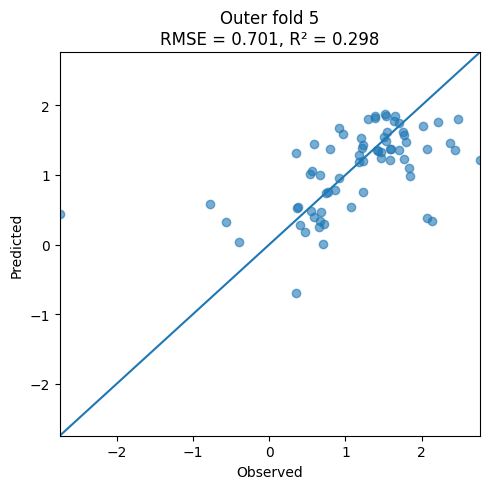

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_08_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_08_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9478 (+/- 0.1397)
Mean R2 (Outer CV): 0.2860 (+/- 0.0327)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 9]


[I 2026-10-24 01:58:38,286] A new study created in memory with name: no-name-9f16bced-8300-4afa-9752-64ec45c25215


Resuming from existing file. Found 588 previous runs.
Running rs=966, targetTW=9
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 01:58:39,775] Trial 0 finished with value: 0.9047164798247906 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9047164798247906.
[I 2026-10-24 01:58:41,022] Trial 1 finished with value: 0.9531304194381157 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9047164798247906.
[I 2026-10-24 01:58:41,494] Trial 2 finished with value: 0.9193847296739052 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9047164798247906.
[I 2026-10-24 01:58:42,059] Trial 3 finished with value: 0.9101528034287256 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0787 R2 = 0.3204


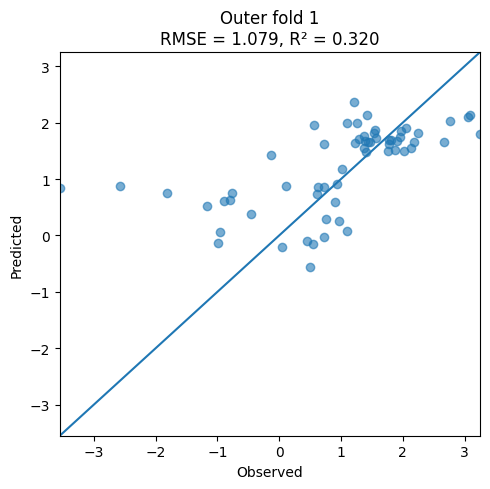

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_09_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_09_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:00:13,934] A new study created in memory with name: no-name-debf75f7-edb4-4989-87fe-3f101f18ac3a
[I 2026-10-24 02:00:14,646] Trial 0 finished with value: 0.9739072845467458 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9739072845467458.
[I 2026-10-24 02:00:15,250] Trial 1 finished with value: 1.0257592005743958 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9739072845467458.
[I 2026-10-24 02:00:15,661] Trial 2 finished with value: 1.0115385258521816 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.97390728

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9252 R2 = 0.3073


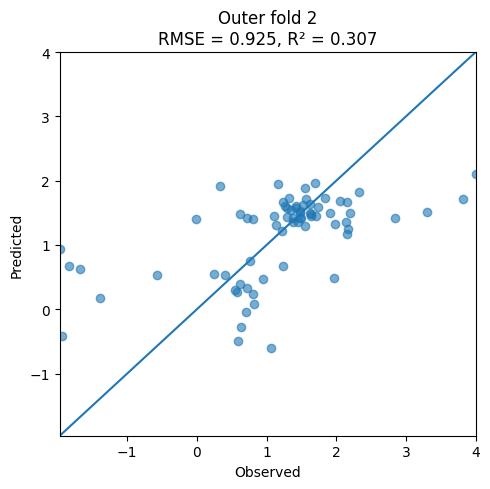

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_09_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_09_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:01:37,439] A new study created in memory with name: no-name-8dc5d216-dc68-4650-8e6b-f0f71b1ddd06
[I 2026-10-24 02:01:38,095] Trial 0 finished with value: 0.9267961855990858 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9267961855990858.
[I 2026-10-24 02:01:38,671] Trial 1 finished with value: 0.9593654171581459 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9267961855990858.
[I 2026-10-24 02:01:39,072] Trial 2 finished with value: 0.9677507593151392 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.92679618

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0608 R2 = 0.3350


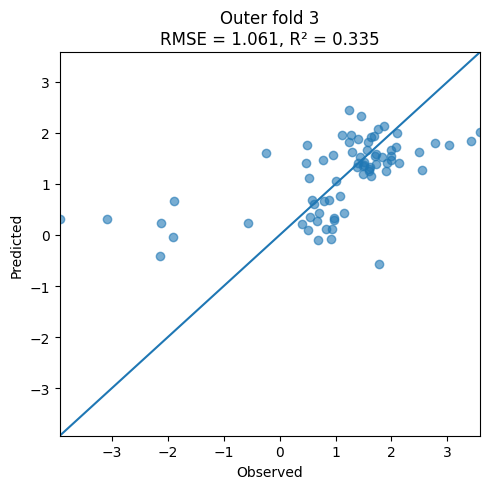

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_09_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_09_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:03:19,340] A new study created in memory with name: no-name-2901b02a-6e3c-4024-a178-3cf6ad865d5b
[I 2026-10-24 02:03:19,982] Trial 0 finished with value: 1.005455588179475 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.005455588179475.
[I 2026-10-24 02:03:20,629] Trial 1 finished with value: 1.0800244234003822 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.005455588179475.
[I 2026-10-24 02:03:21,032] Trial 2 finished with value: 1.0681464181682465 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.00545558817

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9221 R2 = 0.2421


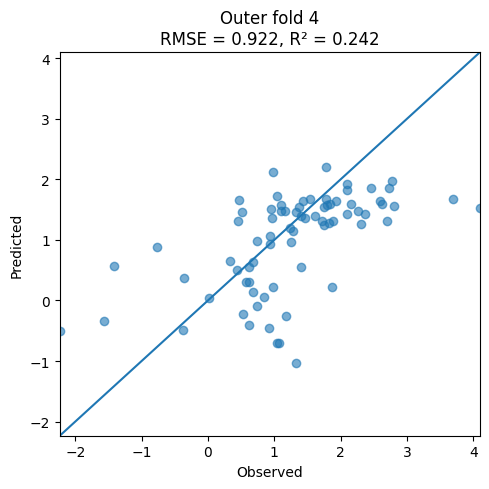

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_09_outerfold_04.json


[I 2026-10-24 02:04:43,189] A new study created in memory with name: no-name-ab4067dd-ebca-4256-a387-9b94965ae24c


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_09_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:04:44,002] Trial 0 finished with value: 1.0509283291321543 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0509283291321543.
[I 2026-10-24 02:04:44,633] Trial 1 finished with value: 1.1104328359620899 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0509283291321543.
[I 2026-10-24 02:04:45,011] Trial 2 finished with value: 1.0603868373726149 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0509283291321543.
[I 2026-10-24 02:04:45,559] Trial 3 finished with value: 1.0348654274942448 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6151 R2 = 0.4591


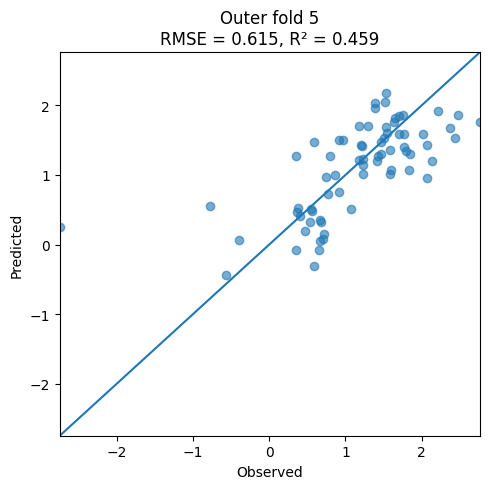

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_09_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_09_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9204 (+/- 0.1661)
Mean R2 (Outer CV): 0.3328 (+/- 0.0707)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 10]


[I 2026-10-24 02:06:24,079] A new study created in memory with name: no-name-8740b16a-9914-4b6f-9cb3-9bb508f36842


Resuming from existing file. Found 594 previous runs.
Running rs=966, targetTW=10
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:06:24,632] Trial 0 finished with value: 0.9008672190959441 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9008672190959441.
[I 2026-10-24 02:06:25,255] Trial 1 finished with value: 0.9465677700437203 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9008672190959441.
[I 2026-10-24 02:06:25,739] Trial 2 finished with value: 0.9611486757099686 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9008672190959441.
[I 2026-10-24 02:06:26,332] Trial 3 finished with value: 0.8996594630078175 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0583 R2 = 0.3458


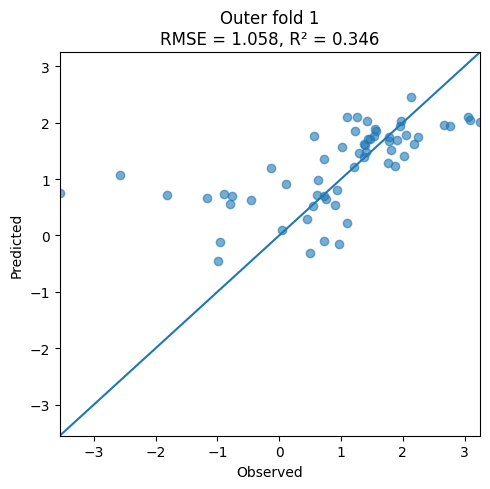

[I 2026-10-24 02:08:29,278] A new study created in memory with name: no-name-6162090e-b94b-4fc6-8226-0b25e6aebd02


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_10_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_10_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:08:30,007] Trial 0 finished with value: 0.9230219098968513 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9230219098968513.
[I 2026-10-24 02:08:30,631] Trial 1 finished with value: 1.0021314621363149 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9230219098968513.
[I 2026-10-24 02:08:31,063] Trial 2 finished with value: 0.9930358320837444 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9230219098968513.
[I 2026-10-24 02:08:31,592] Trial 3 finished with value: 0.9616644238977622 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9821 R2 = 0.2194


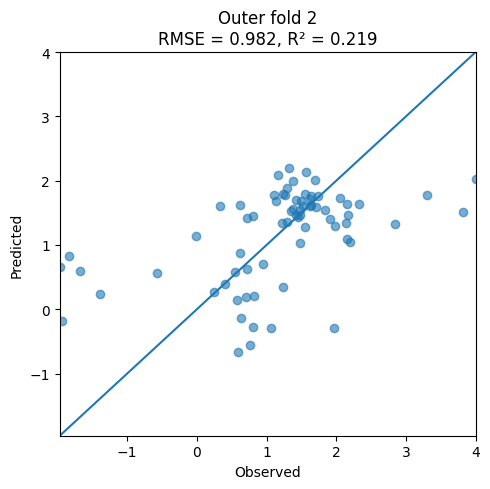

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_10_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_10_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:10:09,889] A new study created in memory with name: no-name-155891ee-b564-48c8-b667-5f3bd02f353c
[I 2026-10-24 02:10:10,572] Trial 0 finished with value: 0.946807706257183 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.946807706257183.
[I 2026-10-24 02:10:11,194] Trial 1 finished with value: 0.9825134410325707 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.946807706257183.
[I 2026-10-24 02:10:11,601] Trial 2 finished with value: 0.942060030879089 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.942060030879

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0479 R2 = 0.3510


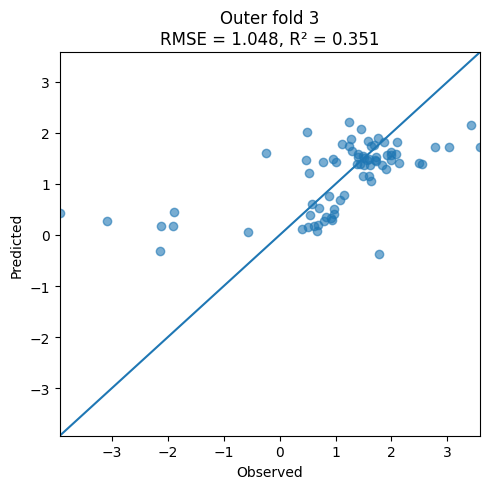

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_10_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_10_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:11:38,505] A new study created in memory with name: no-name-26e9f822-9d50-4633-820a-9824fc2fd9b8
[I 2026-10-24 02:11:39,192] Trial 0 finished with value: 0.9953811715036094 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9953811715036094.
[I 2026-10-24 02:11:41,188] Trial 1 finished with value: 1.057817618565393 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9953811715036094.
[I 2026-10-24 02:11:43,013] Trial 2 finished with value: 1.0760875550128728 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.995381171

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8814 R2 = 0.3075


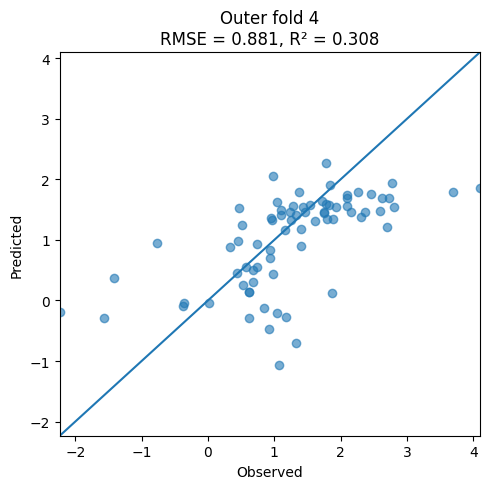

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_10_outerfold_04.json


[I 2026-10-24 02:13:17,025] A new study created in memory with name: no-name-e86971dc-ba6f-476b-a03a-a55cd9561219


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_10_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:13:17,909] Trial 0 finished with value: 1.0446380379098938 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0446380379098938.
[I 2026-10-24 02:13:18,499] Trial 1 finished with value: 1.0953583501945496 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0446380379098938.
[I 2026-10-24 02:13:19,244] Trial 2 finished with value: 1.0490107110078308 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0446380379098938.
[I 2026-10-24 02:13:20,769] Trial 3 finished with value: 1.0653245638760065 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6412 R2 = 0.4122


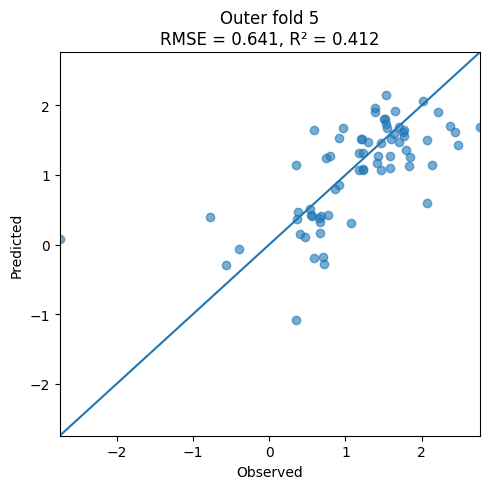

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_10_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_10_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9222 (+/- 0.1540)
Mean R2 (Outer CV): 0.3272 (+/- 0.0635)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 11]


[I 2026-10-24 02:15:00,222] A new study created in memory with name: no-name-08e41efc-0ce7-40f6-879c-96767ca6b304


Resuming from existing file. Found 600 previous runs.
Running rs=966, targetTW=11
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:15:01,009] Trial 0 finished with value: 0.8810159706651599 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8810159706651599.
[I 2026-10-24 02:15:01,945] Trial 1 finished with value: 0.9400122045475576 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8810159706651599.
[I 2026-10-24 02:15:02,998] Trial 2 finished with value: 0.9345157382020224 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8810159706651599.
[I 2026-10-24 02:15:04,759] Trial 3 finished with value: 0.892256627096909 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0660 R2 = 0.3363


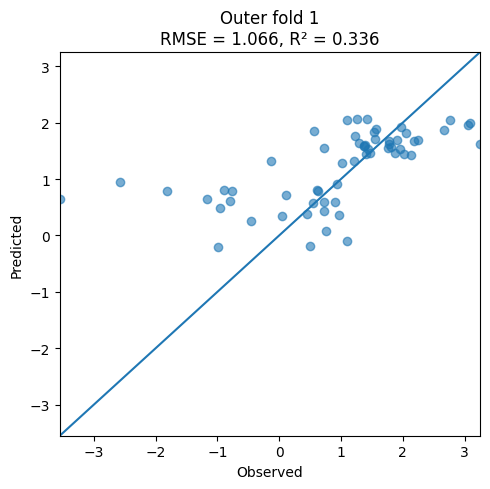

[I 2026-10-24 02:16:44,094] A new study created in memory with name: no-name-0da54910-5cf7-482e-83eb-62c5c30193fa


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_11_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_11_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:16:44,899] Trial 0 finished with value: 0.9377038828288569 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9377038828288569.
[I 2026-10-24 02:16:45,524] Trial 1 finished with value: 1.0007905540806974 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9377038828288569.
[I 2026-10-24 02:16:45,984] Trial 2 finished with value: 0.9874285286780822 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9377038828288569.
[I 2026-10-24 02:16:46,485] Trial 3 finished with value: 0.949894134966573 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9071 R2 = 0.3340


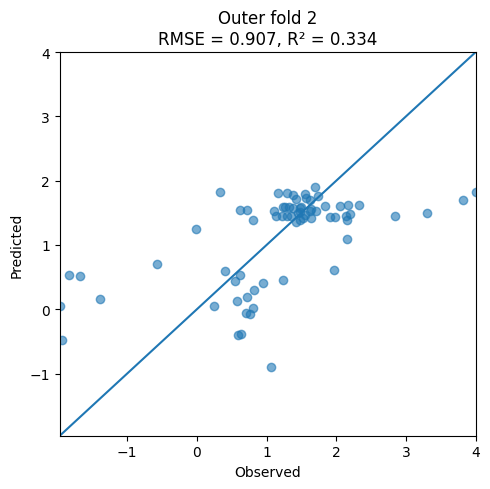

[I 2026-10-24 02:18:27,949] A new study created in memory with name: no-name-b5dd4159-175f-4468-93c6-d75d770960da


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_11_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_11_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:18:28,700] Trial 0 finished with value: 0.9296682894648126 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9296682894648126.
[I 2026-10-24 02:18:29,295] Trial 1 finished with value: 1.0183114190176543 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9296682894648126.
[I 2026-10-24 02:18:29,741] Trial 2 finished with value: 0.9556298274226593 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9296682894648126.
[I 2026-10-24 02:18:30,289] Trial 3 finished with value: 0.9483005681754091 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0190 R2 = 0.3864


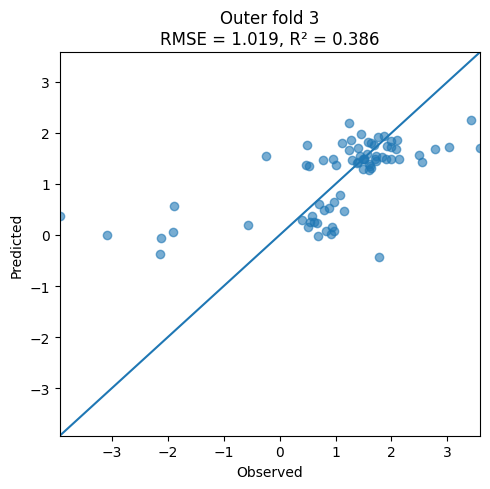

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_11_outerfold_03.json


[I 2026-10-24 02:19:52,182] A new study created in memory with name: no-name-75465baa-f76a-45a8-b440-7d68875f596c


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_11_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:19:53,040] Trial 0 finished with value: 0.9588820713228301 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9588820713228301.
[I 2026-10-24 02:19:53,686] Trial 1 finished with value: 1.0406938285213756 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9588820713228301.
[I 2026-10-24 02:19:54,193] Trial 2 finished with value: 1.0603316189531715 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9588820713228301.
[I 2026-10-24 02:19:54,719] Trial 3 finished with value: 1.044440814196527 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9004 R2 = 0.2774


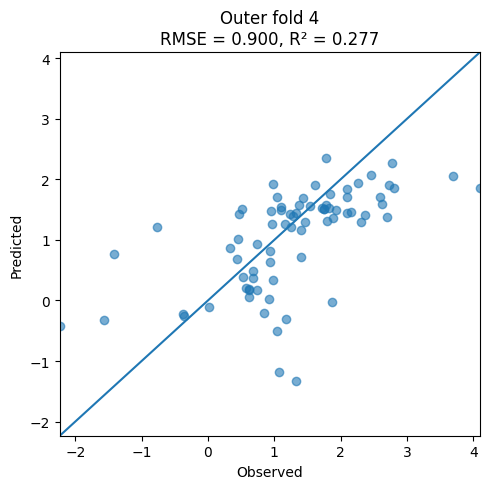

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_11_outerfold_04.json


[I 2026-10-24 02:21:18,360] A new study created in memory with name: no-name-fee39017-f7de-420a-99f1-9de5c19071b8


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_11_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:21:19,253] Trial 0 finished with value: 1.0312200622542922 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0312200622542922.
[I 2026-10-24 02:21:19,916] Trial 1 finished with value: 1.086417345688824 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0312200622542922.
[I 2026-10-24 02:21:20,380] Trial 2 finished with value: 1.0438745536848426 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0312200622542922.
[I 2026-10-24 02:21:20,921] Trial 3 finished with value: 1.0418271300138242 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6687 R2 = 0.3607


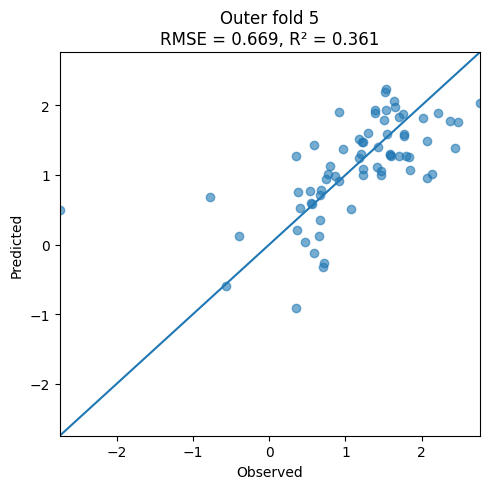

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_11_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_11_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9122 (+/- 0.1375)
Mean R2 (Outer CV): 0.3390 (+/- 0.0362)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 12]


[I 2026-10-24 02:23:02,683] A new study created in memory with name: no-name-a2fff76b-39f0-472b-8231-73be0f3809e2


Resuming from existing file. Found 606 previous runs.
Running rs=966, targetTW=12
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:23:03,318] Trial 0 finished with value: 0.8825033641286638 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8825033641286638.
[I 2026-10-24 02:23:03,973] Trial 1 finished with value: 0.9327129796686399 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8825033641286638.
[I 2026-10-24 02:23:04,462] Trial 2 finished with value: 0.8973311331406448 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8825033641286638.
[I 2026-10-24 02:23:04,981] Trial 3 finished with value: 0.8866303802712234 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0609 R2 = 0.3427


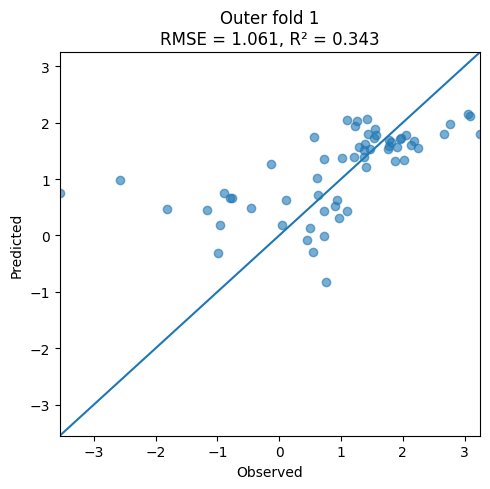

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_12_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_12_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:25:06,031] A new study created in memory with name: no-name-04fd4727-7f9c-4a07-83b0-01f520f8dcfa
[I 2026-10-24 02:25:06,786] Trial 0 finished with value: 0.9210971500039136 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9210971500039136.
[I 2026-10-24 02:25:07,442] Trial 1 finished with value: 0.9925346856206066 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9210971500039136.
[I 2026-10-24 02:25:07,867] Trial 2 finished with value: 0.9446777132587122 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.92109715

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9578 R2 = 0.2575


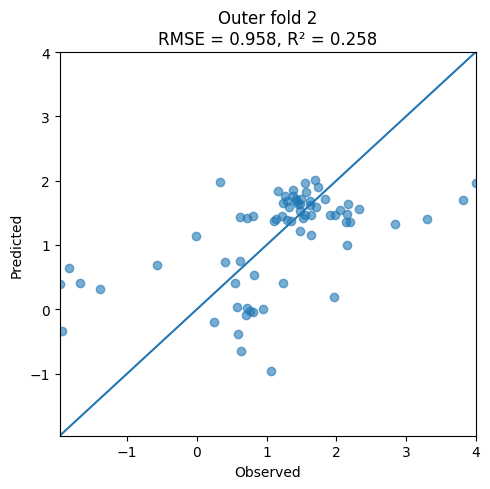

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_12_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_12_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:27:14,304] A new study created in memory with name: no-name-53abebe3-11d3-44c1-893d-f7085527f7db
[I 2026-10-24 02:27:15,029] Trial 0 finished with value: 0.9446130179371122 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9446130179371122.
[I 2026-10-24 02:27:15,657] Trial 1 finished with value: 1.0115789118614258 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9446130179371122.
[I 2026-10-24 02:27:16,098] Trial 2 finished with value: 0.970663256771022 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.944613017

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0706 R2 = 0.3226


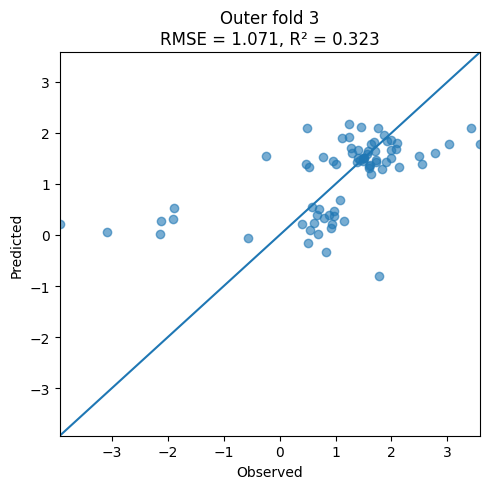

[I 2026-10-24 02:28:52,506] A new study created in memory with name: no-name-b9ff27e3-7b9c-4e51-a773-afd55c6a05a9


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_12_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_12_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:28:53,212] Trial 0 finished with value: 1.0315125595611874 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0315125595611874.
[I 2026-10-24 02:28:53,891] Trial 1 finished with value: 1.0862008096988423 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0315125595611874.
[I 2026-10-24 02:28:54,317] Trial 2 finished with value: 1.0574955183337984 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0315125595611874.
[I 2026-10-24 02:28:54,935] Trial 3 finished with value: 1.018219103184824 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8773 R2 = 0.3140


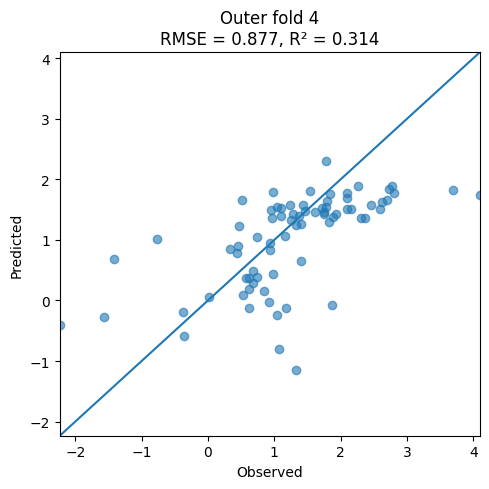

[I 2026-10-24 02:30:29,879] A new study created in memory with name: no-name-8b8c6d57-5cf1-46ea-bd52-223b0f88c173


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_12_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_12_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:30:30,653] Trial 0 finished with value: 1.0359693658611586 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0359693658611586.
[I 2026-10-24 02:30:31,208] Trial 1 finished with value: 1.0887575389114015 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0359693658611586.
[I 2026-10-24 02:30:31,698] Trial 2 finished with value: 1.100039743273534 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0359693658611586.
[I 2026-10-24 02:30:32,310] Trial 3 finished with value: 1.024130288664658 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6485 R2 = 0.3988


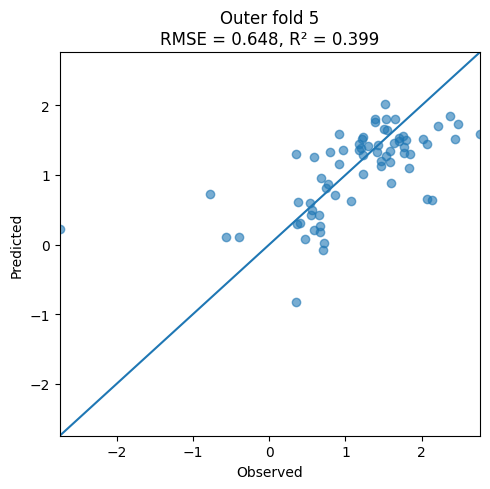

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_12_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_12_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9230 (+/- 0.1546)
Mean R2 (Outer CV): 0.3271 (+/- 0.0456)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 13]


[I 2026-10-24 02:31:57,009] A new study created in memory with name: no-name-5e566fa1-df4d-46e8-bd3f-d9f61f522c62


Resuming from existing file. Found 612 previous runs.
Running rs=966, targetTW=13
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:31:57,636] Trial 0 finished with value: 0.8845320721127539 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8845320721127539.
[I 2026-10-24 02:31:58,324] Trial 1 finished with value: 0.9278146191509359 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8845320721127539.
[I 2026-10-24 02:31:58,735] Trial 2 finished with value: 0.920538636119937 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8845320721127539.
[I 2026-10-24 02:31:59,286] Trial 3 finished with value: 0.8951578031475 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0847 R2 = 0.3128


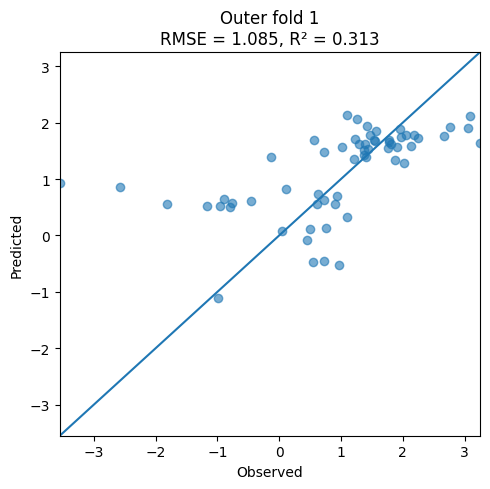

[I 2026-10-24 02:34:00,486] A new study created in memory with name: no-name-c50fa6b9-bbbe-480c-a2f0-9ae54942f299


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_13_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_13_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:34:03,400] Trial 0 finished with value: 0.9387195406965404 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9387195406965404.
[I 2026-10-24 02:34:04,605] Trial 1 finished with value: 0.9893921602987563 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9387195406965404.
[I 2026-10-24 02:34:05,070] Trial 2 finished with value: 0.9882560311633461 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9387195406965404.
[I 2026-10-24 02:34:05,556] Trial 3 finished with value: 0.9707940461955862 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9905 R2 = 0.2060


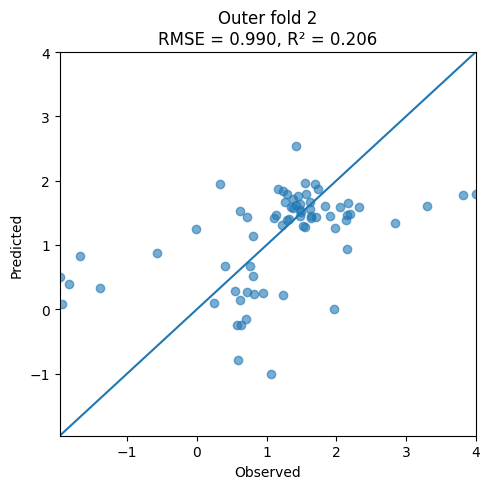

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_13_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_13_outerfold_02_meta.json

=== Outer fold 3/5 ===


[I 2026-10-24 02:35:33,947] A new study created in memory with name: no-name-7ece2be6-a83b-4f30-95a8-f2016eb40863


Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:35:34,863] Trial 0 finished with value: 0.9536393495583515 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9536393495583515.
[I 2026-10-24 02:35:35,504] Trial 1 finished with value: 0.9875644919242721 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9536393495583515.
[I 2026-10-24 02:35:35,946] Trial 2 finished with value: 0.960379870492219 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9536393495583515.
[I 2026-10-24 02:35:36,499] Trial 3 finished with value: 0.9198943545659147 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0289 R2 = 0.3744


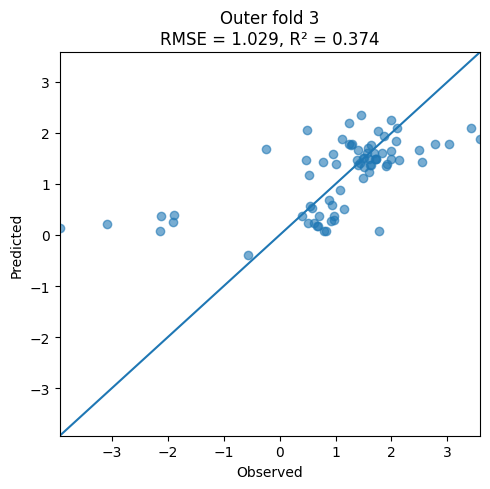

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_13_outerfold_03.json


[I 2026-10-24 02:37:16,847] A new study created in memory with name: no-name-3990c868-2385-4fee-b689-9b1a6693fb07


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_13_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:37:17,720] Trial 0 finished with value: 1.0522130510601972 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0522130510601972.
[I 2026-10-24 02:37:18,356] Trial 1 finished with value: 1.0674964994001885 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0522130510601972.
[I 2026-10-24 02:37:18,837] Trial 2 finished with value: 1.0600462893727811 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0522130510601972.
[I 2026-10-24 02:37:19,347] Trial 3 finished with value: 1.0126550819657565 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9653 R2 = 0.1695


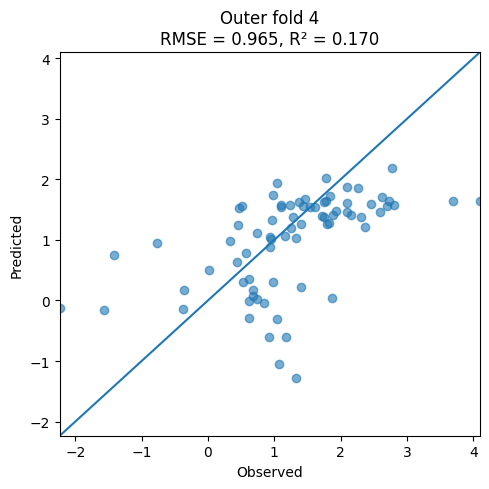

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_13_outerfold_04.json


[I 2026-10-24 02:38:57,031] A new study created in memory with name: no-name-66d9cd47-fafc-4617-b95b-d3d714047a9d


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_13_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:38:57,960] Trial 0 finished with value: 1.0127714011663498 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0127714011663498.
[I 2026-10-24 02:38:58,546] Trial 1 finished with value: 1.0966982132111158 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0127714011663498.
[I 2026-10-24 02:38:59,039] Trial 2 finished with value: 1.0564167060467788 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0127714011663498.
[I 2026-10-24 02:38:59,631] Trial 3 finished with value: 1.0250341577623892 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6539 R2 = 0.3886


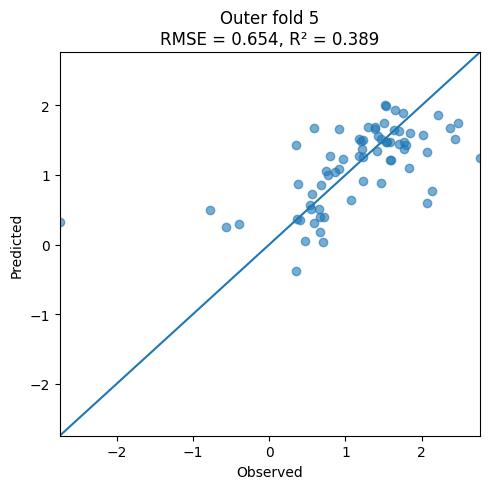

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_13_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_13_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9447 (+/- 0.1508)
Mean R2 (Outer CV): 0.2903 (+/- 0.0882)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 14]


[I 2026-10-24 02:40:34,679] A new study created in memory with name: no-name-40c0cdd0-2590-4c37-ac2d-279a9d605576


Resuming from existing file. Found 618 previous runs.
Running rs=966, targetTW=14
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:40:35,332] Trial 0 finished with value: 0.893160023847007 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.893160023847007.
[I 2026-10-24 02:40:35,981] Trial 1 finished with value: 0.9506050171908667 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.893160023847007.
[I 2026-10-24 02:40:36,454] Trial 2 finished with value: 0.967549610913533 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.893160023847007.
[I 2026-10-24 02:40:36,986] Trial 3 finished with value: 0.8679307553807117 and parameters: {'max_depth': 3, 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0905 R2 = 0.3055


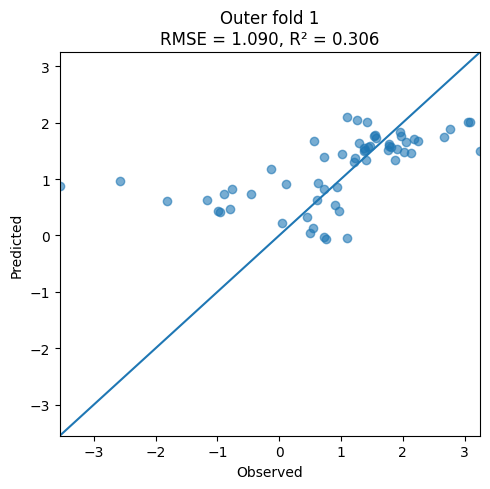

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_14_outerfold_01.json


[I 2026-10-24 02:42:16,809] A new study created in memory with name: no-name-5dc32691-39b9-41c3-96e0-6305c5cb25d3


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_14_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:42:17,718] Trial 0 finished with value: 0.9457210968421739 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9457210968421739.
[I 2026-10-24 02:42:18,350] Trial 1 finished with value: 1.0217837281797255 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9457210968421739.
[I 2026-10-24 02:42:18,812] Trial 2 finished with value: 0.9865584553994691 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9457210968421739.
[I 2026-10-24 02:42:19,391] Trial 3 finished with value: 0.9498947093530127 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9403 R2 = 0.2845


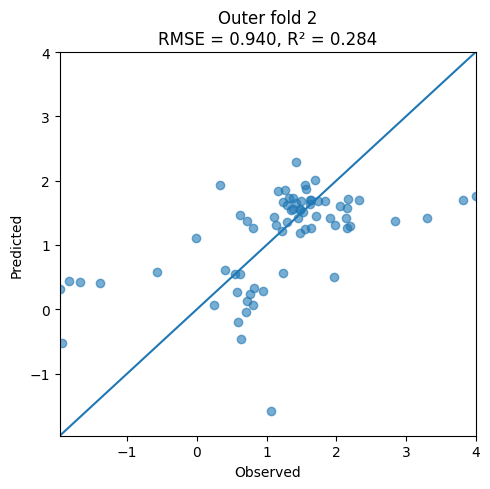

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_14_outerfold_02.json


[I 2026-10-24 02:44:20,199] A new study created in memory with name: no-name-be0e9f3f-4eec-44eb-b9a2-67db6d0e3537


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_14_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:44:21,105] Trial 0 finished with value: 0.9128958088990151 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9128958088990151.
[I 2026-10-24 02:44:21,702] Trial 1 finished with value: 0.9981753464251577 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9128958088990151.
[I 2026-10-24 02:44:22,210] Trial 2 finished with value: 0.9783940339667156 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9128958088990151.
[I 2026-10-24 02:44:22,732] Trial 3 finished with value: 0.926432706522968 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0659 R2 = 0.3286


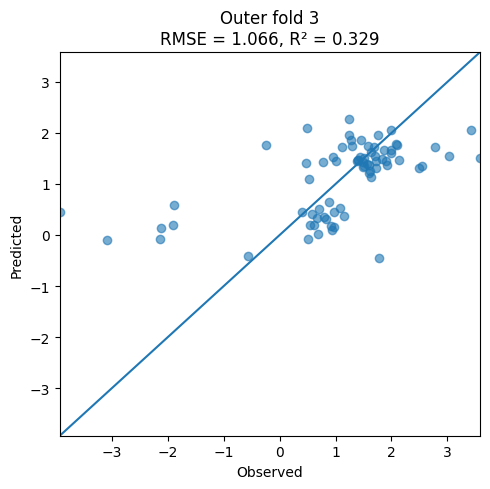

[I 2026-10-24 02:45:53,168] A new study created in memory with name: no-name-1ccbe7ca-4252-4b54-8325-2513ab160e3d


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_14_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_14_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:45:54,339] Trial 0 finished with value: 1.021072967101252 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.021072967101252.
[I 2026-10-24 02:45:57,613] Trial 1 finished with value: 1.0693228870361184 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.021072967101252.
[I 2026-10-24 02:45:58,066] Trial 2 finished with value: 1.0518343021515333 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.021072967101252.
[I 2026-10-24 02:45:58,626] Trial 3 finished with value: 1.009236862761161 and parameters: {'max_depth': 3, 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9087 R2 = 0.2641


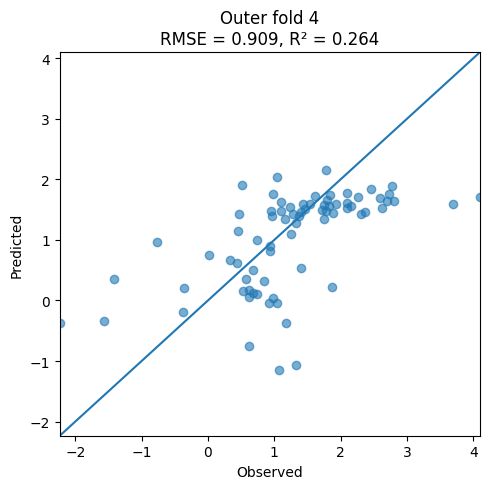

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_14_outerfold_04.json


[I 2026-10-24 02:47:40,563] A new study created in memory with name: no-name-6a300c4e-1a8f-4f1c-a4b2-022d4f0ef073


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_14_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:47:41,484] Trial 0 finished with value: 1.0148008953718315 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0148008953718315.
[I 2026-10-24 02:47:42,140] Trial 1 finished with value: 1.1444346002291184 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0148008953718315.
[I 2026-10-24 02:47:42,576] Trial 2 finished with value: 1.0426314548842939 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0148008953718315.
[I 2026-10-24 02:47:43,156] Trial 3 finished with value: 1.0083669650328542 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6590 R2 = 0.3792


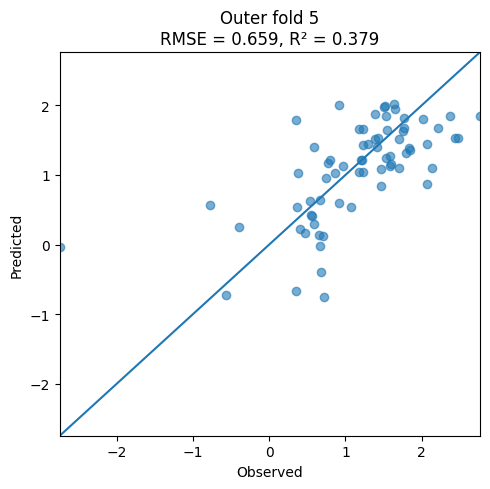

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_14_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_14_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9328 (+/- 0.1537)
Mean R2 (Outer CV): 0.3124 (+/- 0.0397)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 15]


[I 2026-10-24 02:49:25,513] A new study created in memory with name: no-name-9b05a8d9-5916-4d15-bbb5-d2d3308cdd14


Resuming from existing file. Found 624 previous runs.
Running rs=966, targetTW=15
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:49:26,159] Trial 0 finished with value: 0.8575518836273884 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8575518836273884.
[I 2026-10-24 02:49:26,799] Trial 1 finished with value: 0.9207453063539048 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8575518836273884.
[I 2026-10-24 02:49:27,326] Trial 2 finished with value: 0.8948265619454372 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8575518836273884.
[I 2026-10-24 02:49:27,864] Trial 3 finished with value: 0.8729127257987359 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.1029 R2 = 0.2896


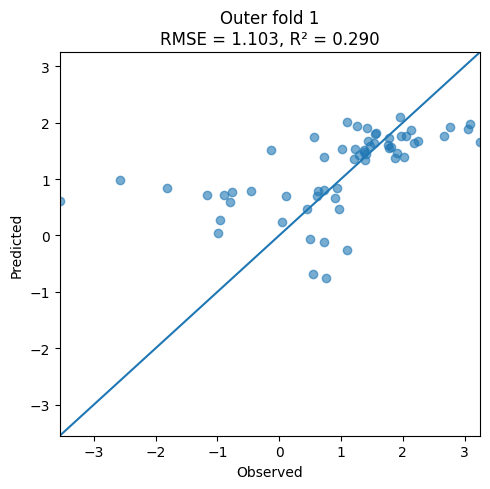

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_15_outerfold_01.json


[I 2026-10-24 02:51:04,979] A new study created in memory with name: no-name-410473a8-6b2e-40a1-9f84-50b1ed8778ce


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_15_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:51:05,959] Trial 0 finished with value: 0.9403561168994117 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9403561168994117.
[I 2026-10-24 02:51:06,615] Trial 1 finished with value: 0.9923817176622384 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9403561168994117.
[I 2026-10-24 02:51:07,060] Trial 2 finished with value: 0.9836318572113149 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9403561168994117.
[I 2026-10-24 02:51:07,633] Trial 3 finished with value: 0.931135261844346 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9059 R2 = 0.3359


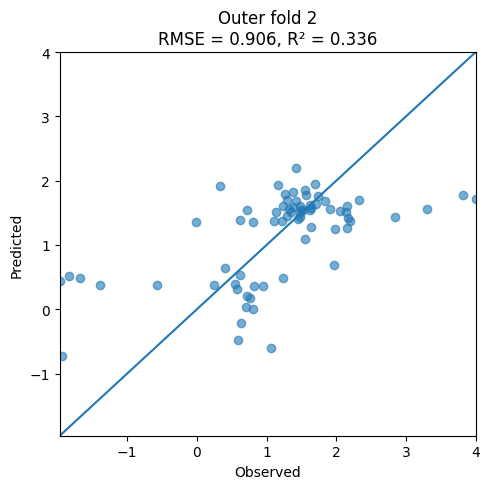

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_15_outerfold_02.json


[I 2026-10-24 02:52:41,848] A new study created in memory with name: no-name-e2c3c7b6-c64e-4215-b970-a3ba0f0f27e0


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_15_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:52:42,795] Trial 0 finished with value: 0.9056967492498968 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9056967492498968.
[I 2026-10-24 02:52:43,404] Trial 1 finished with value: 1.0170055424082869 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9056967492498968.
[I 2026-10-24 02:52:43,895] Trial 2 finished with value: 0.9565091883112131 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9056967492498968.
[I 2026-10-24 02:52:44,429] Trial 3 finished with value: 0.9037590117781784 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0490 R2 = 0.3497


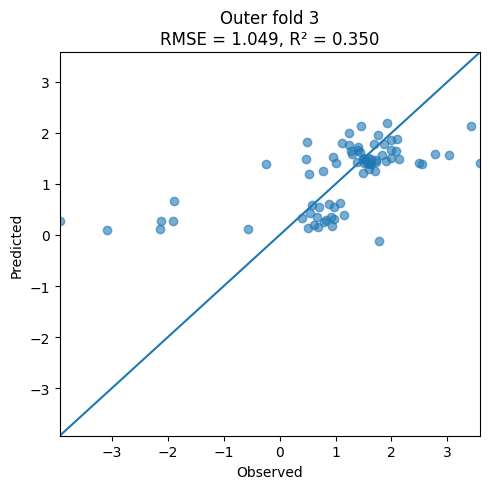

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_15_outerfold_03.json


[I 2026-10-24 02:54:24,770] A new study created in memory with name: no-name-b133eb84-d0be-4bd3-9d70-e5f0c181d56f


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_15_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:54:25,706] Trial 0 finished with value: 0.9926441933478778 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9926441933478778.
[I 2026-10-24 02:54:26,417] Trial 1 finished with value: 1.057485567753379 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9926441933478778.
[I 2026-10-24 02:54:26,890] Trial 2 finished with value: 1.0484261101479924 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9926441933478778.
[I 2026-10-24 02:54:27,483] Trial 3 finished with value: 1.0261084456045078 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8964 R2 = 0.2838


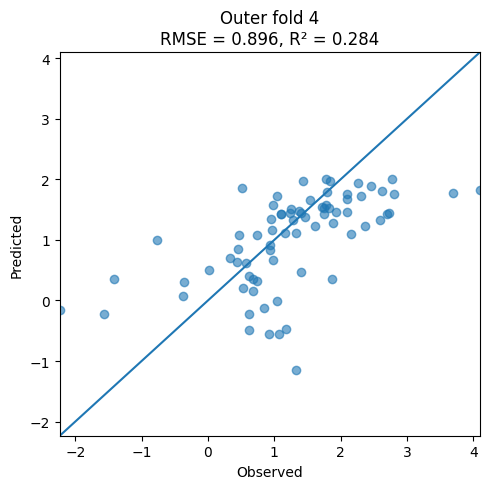

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_15_outerfold_04.json


[I 2026-10-24 02:56:02,839] A new study created in memory with name: no-name-09bac1f3-94c3-47fb-9f35-c728cbd884e6


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_15_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:56:03,851] Trial 0 finished with value: 1.026886776015776 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.026886776015776.
[I 2026-10-24 02:56:04,467] Trial 1 finished with value: 1.107063050765099 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.026886776015776.
[I 2026-10-24 02:56:04,952] Trial 2 finished with value: 1.0642161245772195 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.026886776015776.
[I 2026-10-24 02:56:05,549] Trial 3 finished with value: 1.0700298715111194 and parameters: {'max_depth': 3, 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6406 R2 = 0.4134


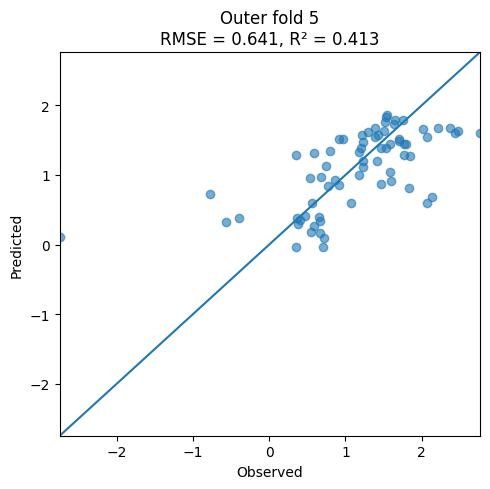

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_15_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_15_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9189 (+/- 0.1606)
Mean R2 (Outer CV): 0.3345 (+/- 0.0470)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 16]


[I 2026-10-24 02:57:34,488] A new study created in memory with name: no-name-fbe5de03-c125-40fd-adf4-e9591d504866


Resuming from existing file. Found 630 previous runs.
Running rs=966, targetTW=16
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:57:35,140] Trial 0 finished with value: 0.8542033368453374 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8542033368453374.
[I 2026-10-24 02:57:35,754] Trial 1 finished with value: 0.8831031189397028 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8542033368453374.
[I 2026-10-24 02:57:36,237] Trial 2 finished with value: 0.9054355682835178 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8542033368453374.
[I 2026-10-24 02:57:36,789] Trial 3 finished with value: 0.8634511498723231 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0641 R2 = 0.3387


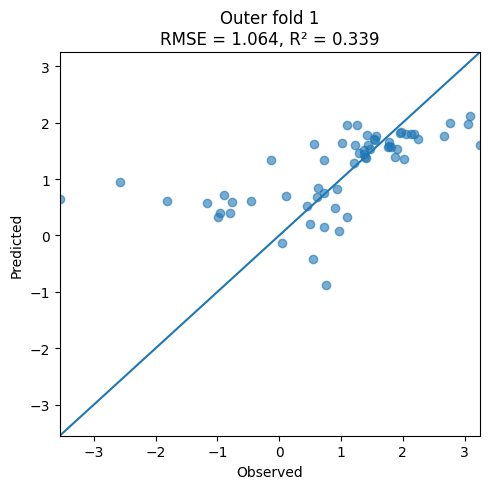

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_16_outerfold_01.json


[I 2026-10-24 02:59:12,580] A new study created in memory with name: no-name-1dacd90f-ce0b-4e83-b1f5-26647a71b6a1


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_16_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 02:59:13,564] Trial 0 finished with value: 0.940563206272496 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.940563206272496.
[I 2026-10-24 02:59:14,190] Trial 1 finished with value: 1.0060211482261154 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.940563206272496.
[I 2026-10-24 02:59:14,703] Trial 2 finished with value: 0.9846163571717107 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.940563206272496.
[I 2026-10-24 02:59:15,256] Trial 3 finished with value: 0.9449018486040146 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9480 R2 = 0.2726


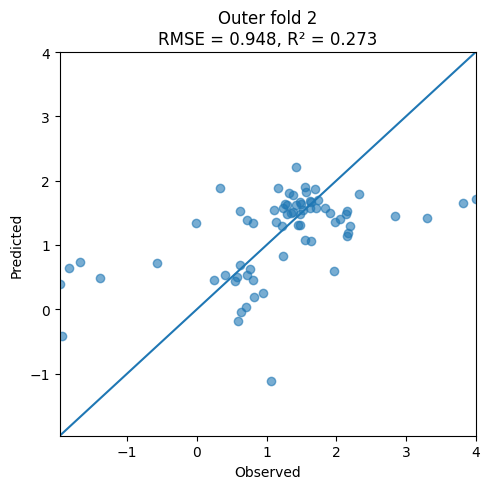

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_16_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_16_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:00:55,389] A new study created in memory with name: no-name-98286101-d1f7-4088-a25e-739a893c71d3
[I 2026-10-24 03:00:56,290] Trial 0 finished with value: 0.9193778286754619 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9193778286754619.
[I 2026-10-24 03:00:56,935] Trial 1 finished with value: 0.9580353346041464 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9193778286754619.
[I 2026-10-24 03:00:57,422] Trial 2 finished with value: 0.9469321309705684 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.91937782

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0647 R2 = 0.3301


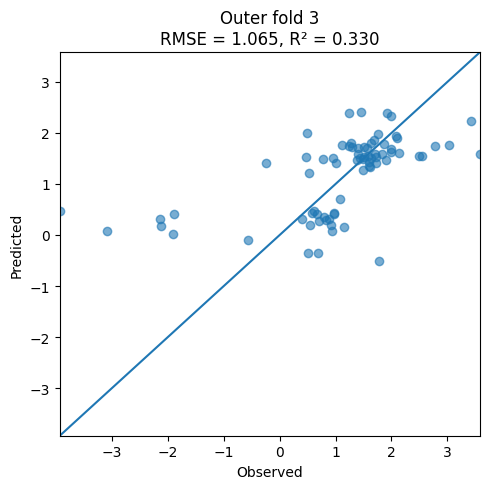

[I 2026-10-24 03:02:23,130] A new study created in memory with name: no-name-c1814183-d7d3-4953-9c7d-3a1aade3ae92


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_16_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_16_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:02:24,694] Trial 0 finished with value: 1.0349685130329709 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0349685130329709.
[I 2026-10-24 03:02:27,340] Trial 1 finished with value: 1.0320924490019472 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 1.0320924490019472.
[I 2026-10-24 03:02:28,250] Trial 2 finished with value: 1.0175312462831516 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 1.0175312462831516.
[I 2026-10-24 03:02:28,816] Trial 3 finished with value: 1.0272572154787365 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9144 R2 = 0.2548


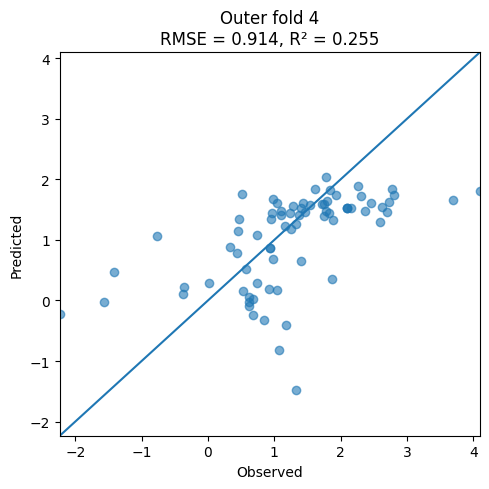

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_16_outerfold_04.json


[I 2026-10-24 03:04:02,554] A new study created in memory with name: no-name-bde839ed-a830-470f-9d61-fc0dded73bb8


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_16_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:04:03,560] Trial 0 finished with value: 1.052129398596148 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.052129398596148.
[I 2026-10-24 03:04:04,362] Trial 1 finished with value: 1.1244887770978966 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.052129398596148.
[I 2026-10-24 03:04:05,973] Trial 2 finished with value: 1.0483953801154209 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 1.0483953801154209.
[I 2026-10-24 03:04:08,306] Trial 3 finished with value: 1.0826773130102296 and parameters: {'max_depth': 3

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6414 R2 = 0.4119


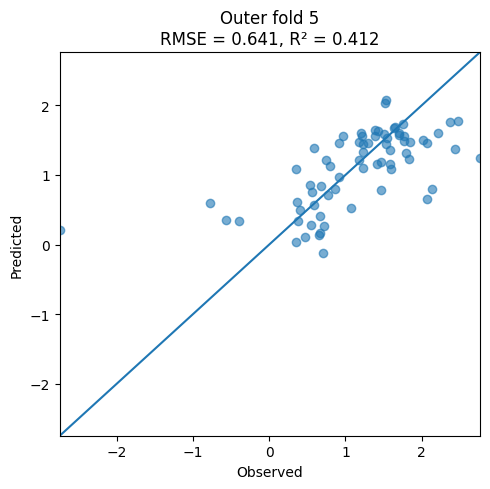

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_16_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_16_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9265 (+/- 0.1549)
Mean R2 (Outer CV): 0.3216 (+/- 0.0555)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 17]


[I 2026-10-24 03:05:45,094] A new study created in memory with name: no-name-c45d8fe6-78f1-4978-97bb-c3853dd33302


Resuming from existing file. Found 636 previous runs.
Running rs=966, targetTW=17
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:05:46,648] Trial 0 finished with value: 0.8936297384541093 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8936297384541093.
[I 2026-10-24 03:05:49,027] Trial 1 finished with value: 0.9236374601932686 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8936297384541093.
[I 2026-10-24 03:05:49,503] Trial 2 finished with value: 0.9071696051047787 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8936297384541093.
[I 2026-10-24 03:05:50,089] Trial 3 finished with value: 0.8645102841313745 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.1108 R2 = 0.2793


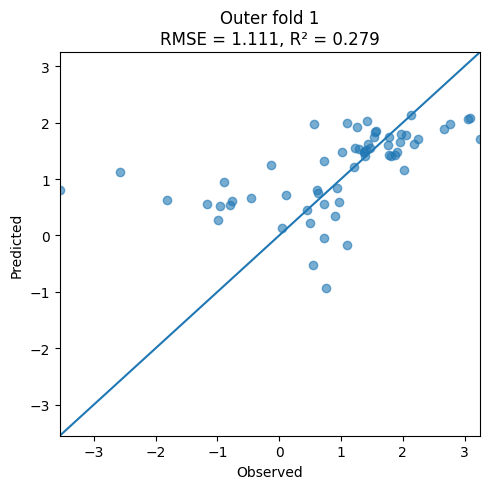

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_17_outerfold_01.json


[I 2026-10-24 03:07:18,944] A new study created in memory with name: no-name-485d932f-109a-4033-8416-e4f42a0719b5


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_17_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:07:19,997] Trial 0 finished with value: 0.9435046061026423 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9435046061026423.
[I 2026-10-24 03:07:20,637] Trial 1 finished with value: 0.9713613116081986 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9435046061026423.
[I 2026-10-24 03:07:21,159] Trial 2 finished with value: 0.9664728069591515 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9435046061026423.
[I 2026-10-24 03:07:21,760] Trial 3 finished with value: 0.9093092411537752 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9579 R2 = 0.2574


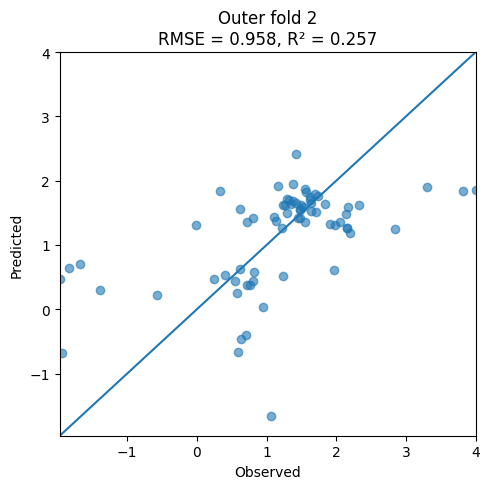

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_17_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_17_outerfold_02_meta.json

=== Outer fold 3/5 ===


[I 2026-10-24 03:09:00,837] A new study created in memory with name: no-name-0d40e719-72ec-4340-ae57-113e350ac4cf


Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:09:01,921] Trial 0 finished with value: 0.9122448795321817 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9122448795321817.
[I 2026-10-24 03:09:02,595] Trial 1 finished with value: 1.0040005352033181 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9122448795321817.
[I 2026-10-24 03:09:03,045] Trial 2 finished with value: 0.9199012974660568 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9122448795321817.
[I 2026-10-24 03:09:03,625] Trial 3 finished with value: 0.9112812591633157 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0729 R2 = 0.3197


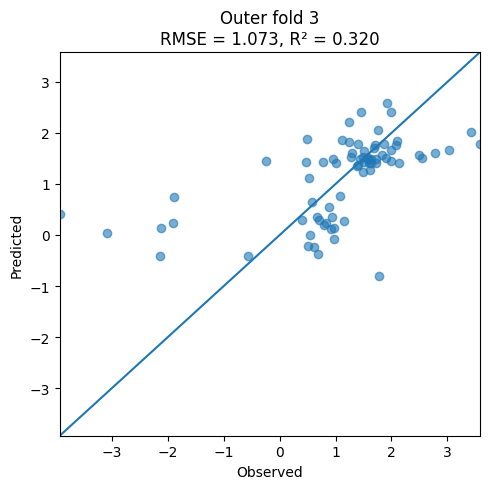

[I 2026-10-24 03:10:40,118] A new study created in memory with name: no-name-82b18b22-5a2f-4223-8fe2-4f41159713fb


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_17_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_17_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:10:41,010] Trial 0 finished with value: 0.9951089433305158 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9951089433305158.
[I 2026-10-24 03:10:41,700] Trial 1 finished with value: 1.0287607195944986 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9951089433305158.
[I 2026-10-24 03:10:42,182] Trial 2 finished with value: 1.0695710483716145 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9951089433305158.
[I 2026-10-24 03:10:42,770] Trial 3 finished with value: 1.023388232200675 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8832 R2 = 0.3047


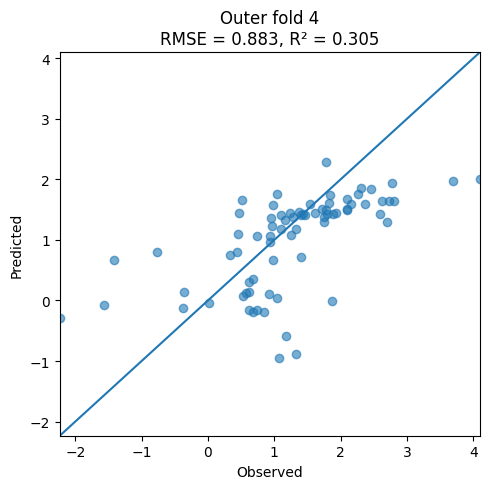

[I 2026-10-24 03:12:23,364] A new study created in memory with name: no-name-40834d7e-f5dd-4b97-a41e-99cf3f7b0e00


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_17_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_17_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:12:24,256] Trial 0 finished with value: 1.041833755783982 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.041833755783982.
[I 2026-10-24 03:12:24,848] Trial 1 finished with value: 1.0695749714246925 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.041833755783982.
[I 2026-10-24 03:12:25,348] Trial 2 finished with value: 1.0807579031575925 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.041833755783982.
[I 2026-10-24 03:12:25,919] Trial 3 finished with value: 1.0562188679061264 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6408 R2 = 0.4130


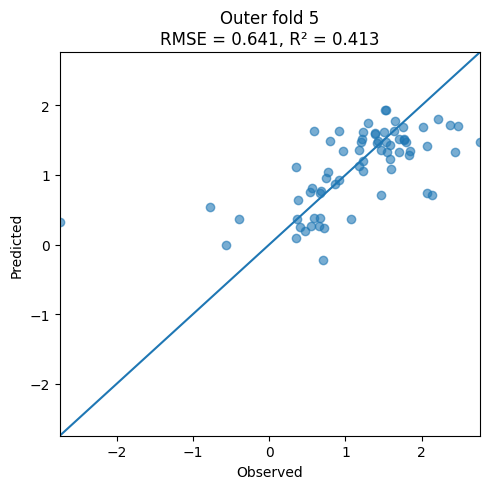

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_17_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_17_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9331 (+/- 0.1671)
Mean R2 (Outer CV): 0.3148 (+/- 0.0535)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 18]


[I 2026-10-24 03:13:59,688] A new study created in memory with name: no-name-18b5852c-62f5-4395-9e1b-65025838bea1


Resuming from existing file. Found 642 previous runs.
Running rs=966, targetTW=18
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:14:00,374] Trial 0 finished with value: 0.8863045026889007 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8863045026889007.
[I 2026-10-24 03:14:01,053] Trial 1 finished with value: 0.8737222257807225 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.8737222257807225.
[I 2026-10-24 03:14:01,581] Trial 2 finished with value: 0.9217806485510737 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.8737222257807225.
[I 2026-10-24 03:14:02,126] Trial 3 finished with value: 0.8878627799889312 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0817 R2 = 0.3166


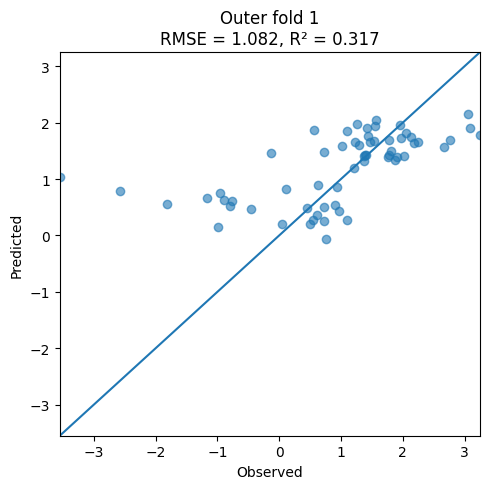

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_18_outerfold_01.json


[I 2026-10-24 03:15:32,910] A new study created in memory with name: no-name-d138591f-456d-4aff-9aae-7738f0892fdb


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_18_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:15:34,230] Trial 0 finished with value: 0.9171363203808613 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9171363203808613.
[I 2026-10-24 03:15:37,422] Trial 1 finished with value: 0.9694042838737701 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9171363203808613.
[I 2026-10-24 03:15:38,060] Trial 2 finished with value: 0.9578026705659095 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9171363203808613.
[I 2026-10-24 03:15:38,615] Trial 3 finished with value: 0.9191404052504506 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9377 R2 = 0.2884


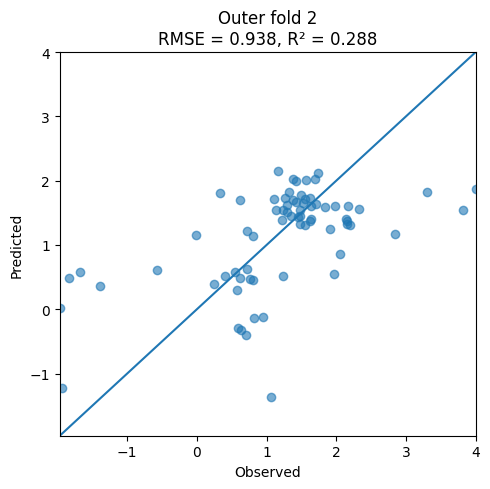

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_18_outerfold_02.json


[I 2026-10-24 03:16:59,828] A new study created in memory with name: no-name-3197eeab-b320-4f64-b4f4-699e4e204256


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_18_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:17:01,399] Trial 0 finished with value: 0.9268671062790574 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9268671062790574.
[I 2026-10-24 03:17:04,075] Trial 1 finished with value: 0.9160047635943154 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9160047635943154.
[I 2026-10-24 03:17:04,932] Trial 2 finished with value: 0.921810357236029 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9160047635943154.
[I 2026-10-24 03:17:05,547] Trial 3 finished with value: 0.8905281666929447 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0116 R2 = 0.3952


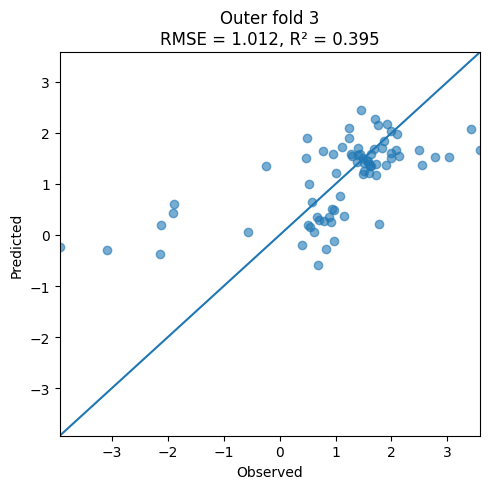

[I 2026-10-24 03:19:15,351] A new study created in memory with name: no-name-d4a9906e-ad52-4c50-8556-639e4c3ea7eb


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_18_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_18_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:19:16,294] Trial 0 finished with value: 0.9842206325517666 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9842206325517666.
[I 2026-10-24 03:19:16,968] Trial 1 finished with value: 1.0763437641014986 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9842206325517666.
[I 2026-10-24 03:19:17,450] Trial 2 finished with value: 1.0729778821075957 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9842206325517666.
[I 2026-10-24 03:19:18,037] Trial 3 finished with value: 1.0263875178027018 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9320 R2 = 0.2258


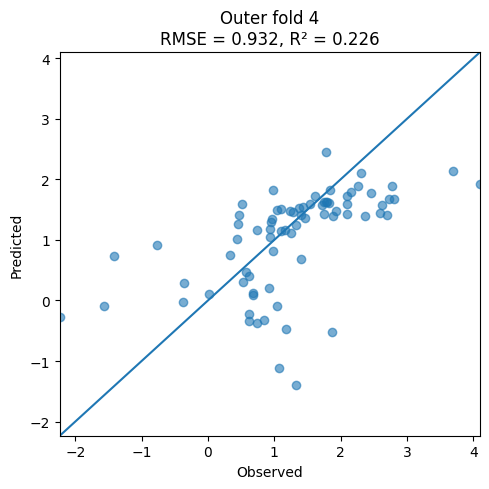

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_18_outerfold_04.json


[I 2026-10-24 03:20:57,780] A new study created in memory with name: no-name-9c18287a-1dd6-4a83-bb97-b1500c5b2380


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_18_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:20:58,845] Trial 0 finished with value: 1.0370071001649395 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0370071001649395.
[I 2026-10-24 03:20:59,531] Trial 1 finished with value: 1.109954449265527 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0370071001649395.
[I 2026-10-24 03:20:59,964] Trial 2 finished with value: 1.0034122229954894 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 1.0034122229954894.
[I 2026-10-24 03:21:00,550] Trial 3 finished with value: 1.0260337543953053 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6210 R2 = 0.4486


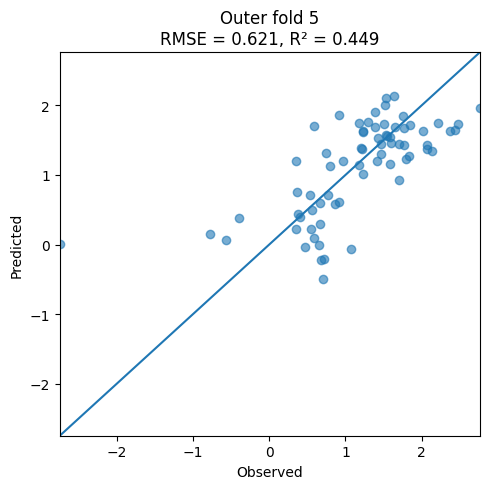

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_18_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_18_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9168 (+/- 0.1577)
Mean R2 (Outer CV): 0.3349 (+/- 0.0787)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 19]


[I 2026-10-24 03:22:53,698] A new study created in memory with name: no-name-44c2ad8b-377a-49ef-b0cc-9df469b34bf0


Resuming from existing file. Found 648 previous runs.
Running rs=966, targetTW=19
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:22:54,338] Trial 0 finished with value: 0.8703908700743765 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8703908700743765.
[I 2026-10-24 03:22:55,020] Trial 1 finished with value: 0.8924797271381888 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8703908700743765.
[I 2026-10-24 03:22:55,533] Trial 2 finished with value: 0.9016733855981749 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8703908700743765.
[I 2026-10-24 03:22:56,118] Trial 3 finished with value: 0.8819069225996116 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0860 R2 = 0.3111


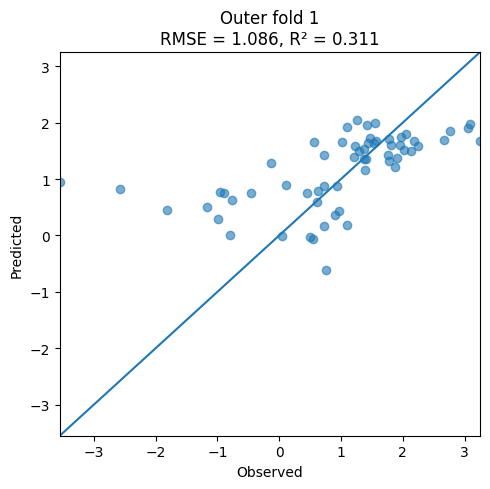

[I 2026-10-24 03:24:31,040] A new study created in memory with name: no-name-c6e83831-4450-4c23-b8b7-3864379541b5


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_19_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_19_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:24:31,900] Trial 0 finished with value: 0.9078601615492791 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9078601615492791.
[I 2026-10-24 03:24:32,597] Trial 1 finished with value: 0.9567103757633204 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9078601615492791.
[I 2026-10-24 03:24:33,122] Trial 2 finished with value: 0.9415958794854763 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9078601615492791.
[I 2026-10-24 03:24:33,734] Trial 3 finished with value: 0.9126485277346509 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9187 R2 = 0.3169


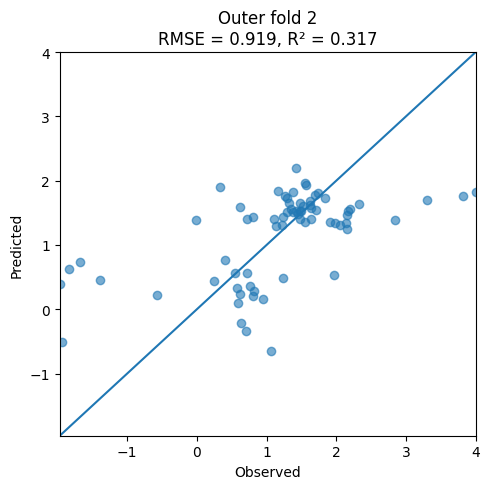

[I 2026-10-24 03:26:25,012] A new study created in memory with name: no-name-377890a6-89f6-4668-ac19-554ae7c1ca06


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_19_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_19_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:26:26,252] Trial 0 finished with value: 0.8623612317692182 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8623612317692182.
[I 2026-10-24 03:26:27,025] Trial 1 finished with value: 0.9545161595646197 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8623612317692182.
[I 2026-10-24 03:26:27,519] Trial 2 finished with value: 0.9040033096397458 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8623612317692182.
[I 2026-10-24 03:26:28,113] Trial 3 finished with value: 0.8998421907412139 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0980 R2 = 0.2875


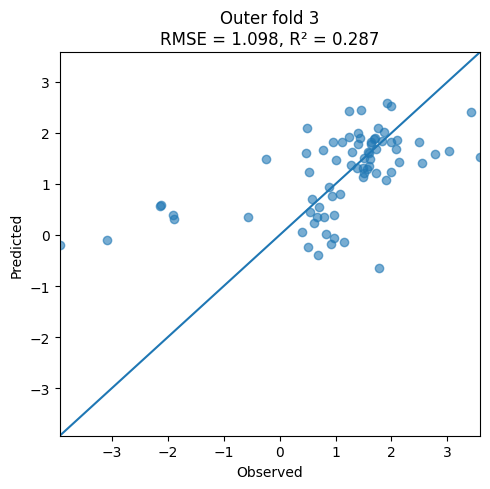

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_19_outerfold_03.json


[I 2026-10-24 03:28:23,372] A new study created in memory with name: no-name-8a19f7dc-4e98-4a53-a8aa-510a45dfe861


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_19_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:28:24,400] Trial 0 finished with value: 0.9858030966194244 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9858030966194244.
[I 2026-10-24 03:28:25,047] Trial 1 finished with value: 1.04361995390694 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9858030966194244.
[I 2026-10-24 03:28:25,542] Trial 2 finished with value: 1.0304784377656666 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9858030966194244.
[I 2026-10-24 03:28:26,132] Trial 3 finished with value: 0.9826894076422013 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8526 R2 = 0.3520


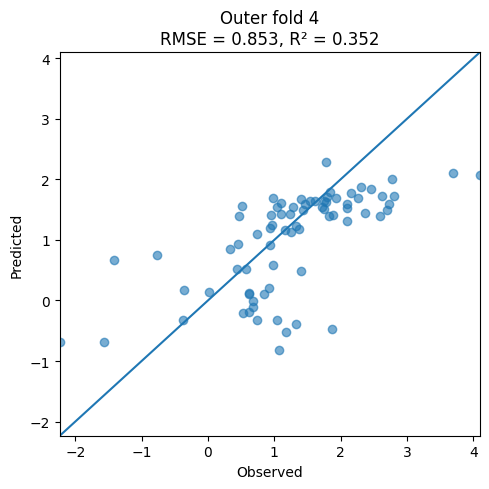

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_19_outerfold_04.json


[I 2026-10-24 03:30:03,735] A new study created in memory with name: no-name-c1c53e5c-a5ae-4ab1-9ba8-183812d5886c


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_19_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:30:04,771] Trial 0 finished with value: 1.0329218365551454 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0329218365551454.
[I 2026-10-24 03:30:05,491] Trial 1 finished with value: 1.1273436605917055 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0329218365551454.
[I 2026-10-24 03:30:06,001] Trial 2 finished with value: 0.9866540436068859 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9866540436068859.
[I 2026-10-24 03:30:06,571] Trial 3 finished with value: 1.0079643711001878 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6229 R2 = 0.4452


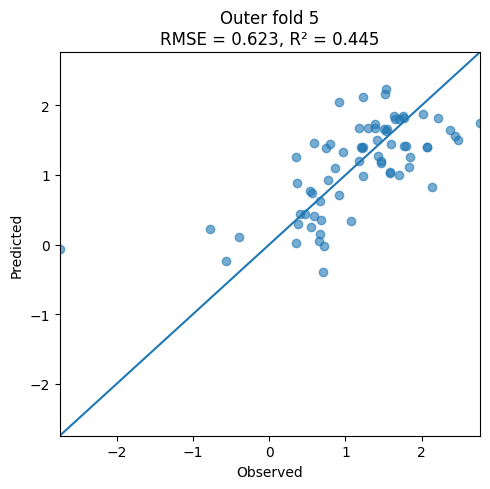

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_19_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_19_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9157 (+/- 0.1743)
Mean R2 (Outer CV): 0.3426 (+/- 0.0553)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 20]


[I 2026-10-24 03:31:41,301] A new study created in memory with name: no-name-06d3a429-9968-4ed8-ac31-c70b90401a83


Resuming from existing file. Found 654 previous runs.
Running rs=966, targetTW=20
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:31:42,228] Trial 0 finished with value: 0.8764183299534288 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8764183299534288.
[I 2026-10-24 03:31:42,905] Trial 1 finished with value: 0.8630145202857773 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.8630145202857773.
[I 2026-10-24 03:31:43,456] Trial 2 finished with value: 0.8754735524680028 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.8630145202857773.
[I 2026-10-24 03:31:43,967] Trial 3 finished with value: 0.8559229028102033 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0629 R2 = 0.3401


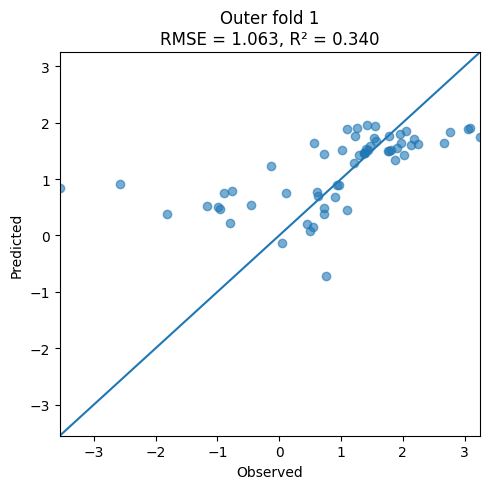

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_20_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_20_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']


[I 2026-10-24 03:33:10,498] A new study created in memory with name: no-name-b61c20b3-9d93-49ea-866e-60b16668d2ec


Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:33:11,563] Trial 0 finished with value: 0.9175217331213714 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9175217331213714.
[I 2026-10-24 03:33:12,281] Trial 1 finished with value: 0.9432650292850588 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9175217331213714.
[I 2026-10-24 03:33:12,773] Trial 2 finished with value: 0.9382262949107395 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9175217331213714.
[I 2026-10-24 03:33:13,387] Trial 3 finished with value: 0.8931516563183242 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9143 R2 = 0.3234


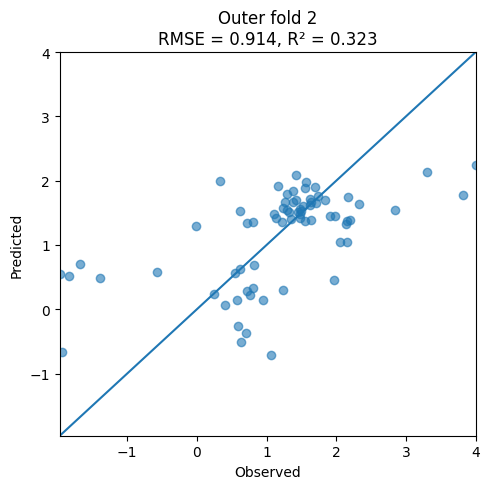

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_20_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_20_outerfold_02_meta.json

=== Outer fold 3/5 ===


[I 2026-10-24 03:34:57,611] A new study created in memory with name: no-name-bfe8ad5b-e7d9-43fc-ae5c-2366d462689c


Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:34:58,649] Trial 0 finished with value: 0.8815844521465404 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8815844521465404.
[I 2026-10-24 03:34:59,307] Trial 1 finished with value: 0.9341557582593837 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8815844521465404.
[I 2026-10-24 03:34:59,841] Trial 2 finished with value: 0.8940911888362695 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8815844521465404.
[I 2026-10-24 03:35:00,487] Trial 3 finished with value: 0.8869001785118664 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0404 R2 = 0.3603


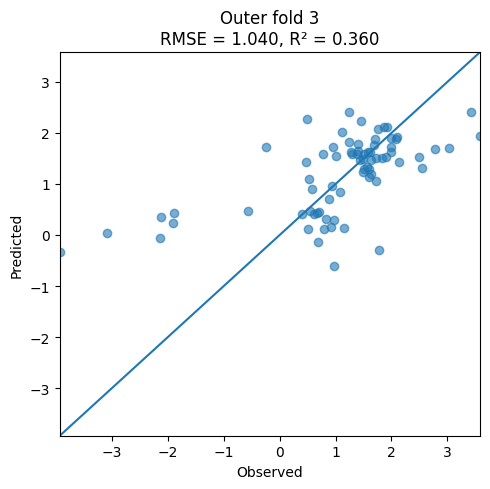

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_20_outerfold_03.json


[I 2026-10-24 03:36:35,544] A new study created in memory with name: no-name-1129b54b-6bb1-47ba-b08c-44602c0f964f


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_20_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:36:36,630] Trial 0 finished with value: 0.9818816117181617 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9818816117181617.
[I 2026-10-24 03:36:37,307] Trial 1 finished with value: 1.0461233913220243 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9818816117181617.
[I 2026-10-24 03:36:37,829] Trial 2 finished with value: 1.0063094788578568 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9818816117181617.
[I 2026-10-24 03:36:38,360] Trial 3 finished with value: 1.0135257861238782 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8564 R2 = 0.3463


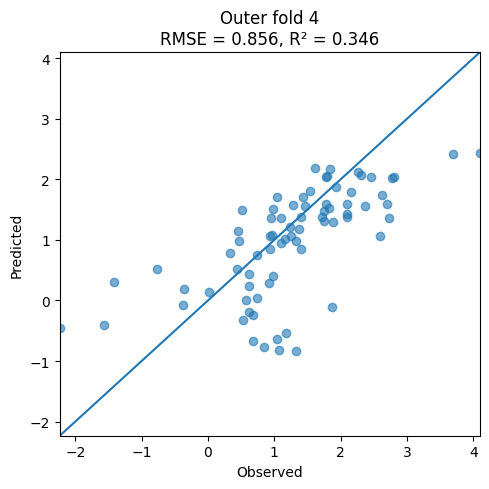

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_20_outerfold_04.json


[I 2026-10-24 03:38:17,311] A new study created in memory with name: no-name-a974096e-744a-4d40-ace7-67eef98ee733


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_20_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:38:18,402] Trial 0 finished with value: 1.0444211715693472 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0444211715693472.
[I 2026-10-24 03:38:19,129] Trial 1 finished with value: 1.0871639686184207 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0444211715693472.
[I 2026-10-24 03:38:19,579] Trial 2 finished with value: 0.9959472833549714 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9959472833549714.
[I 2026-10-24 03:38:20,205] Trial 3 finished with value: 1.0201316763589667 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6309 R2 = 0.4310


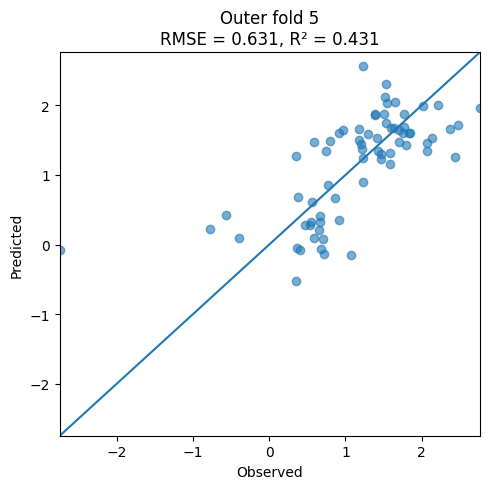

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_20_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_20_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9010 (+/- 0.1554)
Mean R2 (Outer CV): 0.3602 (+/- 0.0373)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 21]


[I 2026-10-24 03:40:15,126] A new study created in memory with name: no-name-cb81140e-9e6d-4935-8e85-9935095e6b76


Resuming from existing file. Found 660 previous runs.
Running rs=966, targetTW=21
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:40:15,794] Trial 0 finished with value: 0.8755494908579724 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8755494908579724.
[I 2026-10-24 03:40:16,481] Trial 1 finished with value: 0.8879912187533457 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8755494908579724.
[I 2026-10-24 03:40:17,765] Trial 2 finished with value: 0.9076187961200648 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8755494908579724.
[I 2026-10-24 03:40:20,466] Trial 3 finished with value: 0.8528190712698809 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0276 R2 = 0.3832


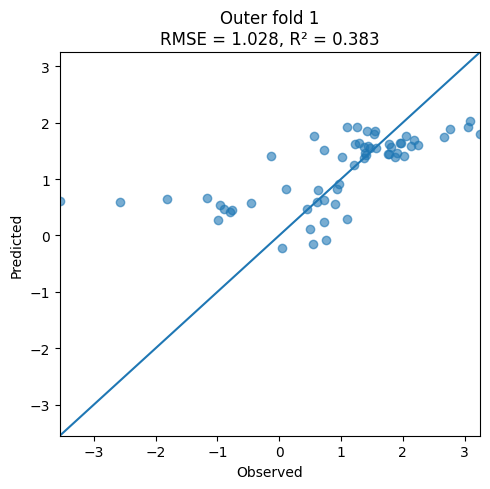

[I 2026-10-24 03:42:06,902] A new study created in memory with name: no-name-b4e2cf97-1f02-4afe-b980-80e490864065


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_21_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_21_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:42:07,817] Trial 0 finished with value: 0.9030518486255632 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9030518486255632.
[I 2026-10-24 03:42:08,536] Trial 1 finished with value: 0.9686824673392457 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9030518486255632.
[I 2026-10-24 03:42:09,046] Trial 2 finished with value: 0.9512790588566509 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9030518486255632.
[I 2026-10-24 03:42:09,736] Trial 3 finished with value: 0.8953502374400701 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8681 R2 = 0.3902


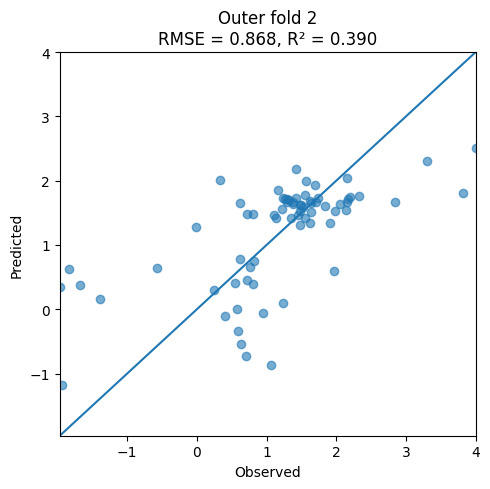

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_21_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_21_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:43:37,092] A new study created in memory with name: no-name-1e423d03-3abf-4ee1-ad8b-3583dc61de50
[I 2026-10-24 03:43:38,028] Trial 0 finished with value: 0.8855644568433169 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8855644568433169.
[I 2026-10-24 03:43:38,702] Trial 1 finished with value: 0.8921184608764313 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8855644568433169.
[I 2026-10-24 03:43:39,148] Trial 2 finished with value: 0.8611660216694346 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.86116602

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0035 R2 = 0.4049


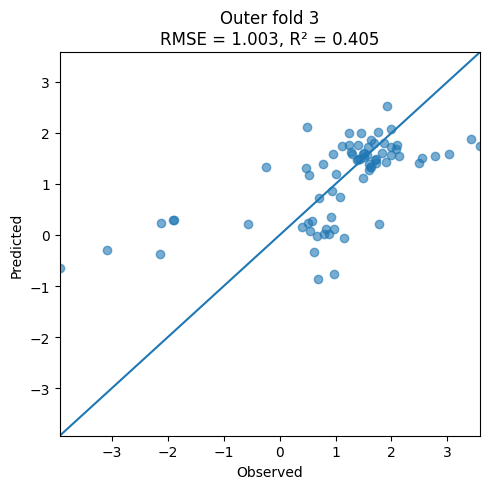

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_21_outerfold_03.json


[I 2026-10-24 03:45:14,989] A new study created in memory with name: no-name-79cb4c8c-5529-45ad-bbc9-c85e252eb4a3


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_21_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:45:16,088] Trial 0 finished with value: 0.979891660678443 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.979891660678443.
[I 2026-10-24 03:45:16,812] Trial 1 finished with value: 0.9910641483059681 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.979891660678443.
[I 2026-10-24 03:45:17,265] Trial 2 finished with value: 0.9691598743343878 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9691598743343878.
[I 2026-10-24 03:45:17,860] Trial 3 finished with value: 0.9808639639758344 and parameters: {'max_depth': 3

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8462 R2 = 0.3617


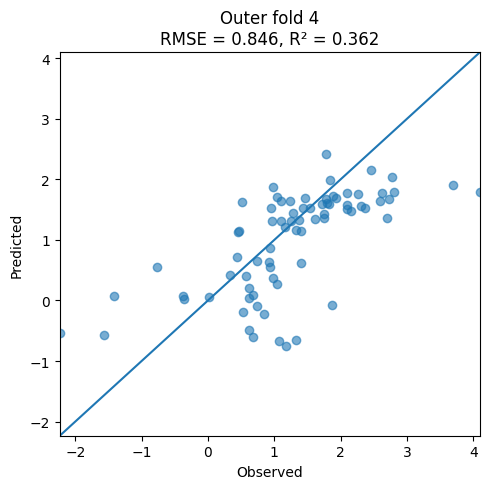

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_21_outerfold_04.json


[I 2026-10-24 03:46:55,162] A new study created in memory with name: no-name-76ed6c2f-a2fb-4497-aa18-f4efcc035b45


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_21_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:46:56,285] Trial 0 finished with value: 1.0008447152907116 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0008447152907116.
[I 2026-10-24 03:46:56,953] Trial 1 finished with value: 1.0238953817705638 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0008447152907116.
[I 2026-10-24 03:46:57,449] Trial 2 finished with value: 1.029069540472963 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0008447152907116.
[I 2026-10-24 03:46:58,024] Trial 3 finished with value: 1.0372050025531037 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6499 R2 = 0.3962


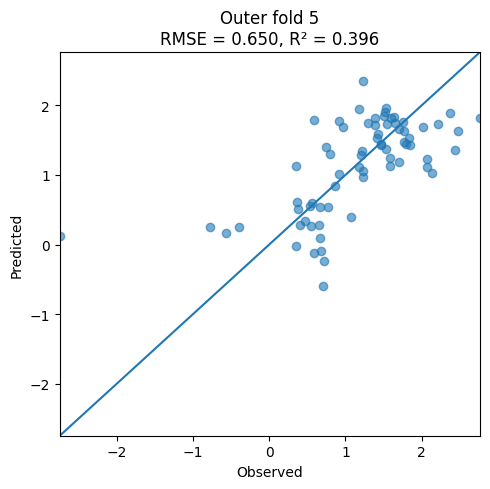

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_21_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_21_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8791 (+/- 0.1351)
Mean R2 (Outer CV): 0.3872 (+/- 0.0146)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 22]


[I 2026-10-24 03:49:02,974] A new study created in memory with name: no-name-34af00d9-164e-4b10-9856-35a828310275


Resuming from existing file. Found 666 previous runs.
Running rs=966, targetTW=22
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:49:03,699] Trial 0 finished with value: 0.8868209700525321 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8868209700525321.
[I 2026-10-24 03:49:04,355] Trial 1 finished with value: 0.8965542105127225 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8868209700525321.
[I 2026-10-24 03:49:04,879] Trial 2 finished with value: 0.8955506165294169 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8868209700525321.
[I 2026-10-24 03:49:05,445] Trial 3 finished with value: 0.8795025796059399 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0858 R2 = 0.3114


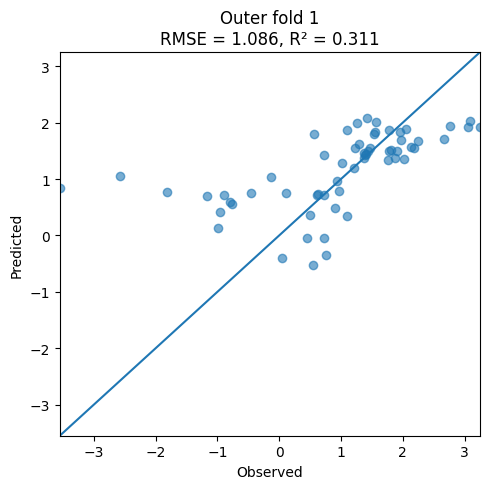

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_22_outerfold_01.json


[I 2026-10-24 03:50:28,454] A new study created in memory with name: no-name-010e7119-2ca9-491f-bb9d-fc0559ff84cc


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_22_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:50:29,634] Trial 0 finished with value: 0.9079027508136815 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9079027508136815.
[I 2026-10-24 03:50:30,306] Trial 1 finished with value: 0.9813847520733129 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9079027508136815.
[I 2026-10-24 03:50:30,833] Trial 2 finished with value: 0.9479662935941965 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9079027508136815.
[I 2026-10-24 03:50:31,395] Trial 3 finished with value: 0.9074929523984534 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8912 R2 = 0.3572


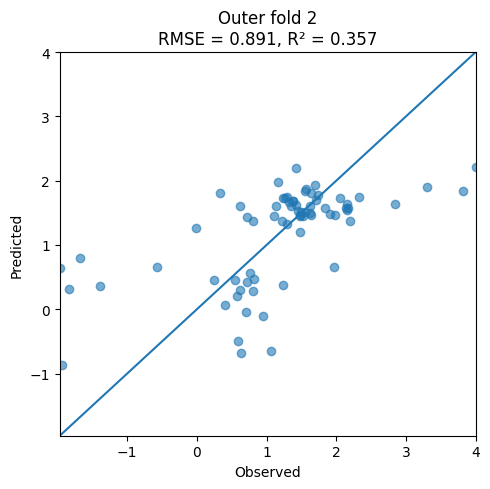

[I 2026-10-24 03:52:13,969] A new study created in memory with name: no-name-05170e60-f729-4226-bcd6-1a5ed394b889


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_22_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_22_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:52:15,454] Trial 0 finished with value: 0.9202755929900448 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9202755929900448.
[I 2026-10-24 03:52:17,673] Trial 1 finished with value: 0.8925576545097871 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.8925576545097871.
[I 2026-10-24 03:52:19,185] Trial 2 finished with value: 0.9422027660750965 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.8925576545097871.
[I 2026-10-24 03:52:19,819] Trial 3 finished with value: 0.9126170668606242 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0003 R2 = 0.4087


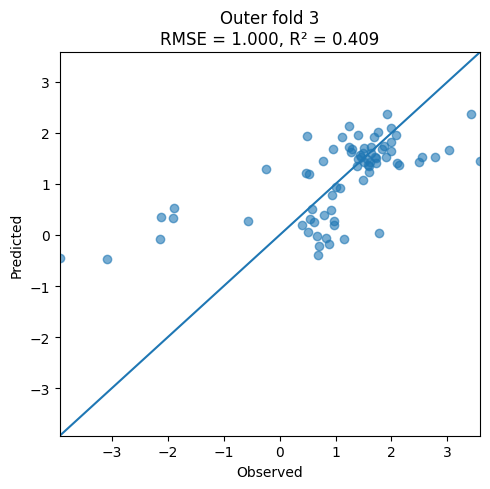

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_22_outerfold_03.json


[I 2026-10-24 03:53:51,937] A new study created in memory with name: no-name-0a9f9a38-0488-4813-b247-6165216f48ec


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_22_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:53:53,075] Trial 0 finished with value: 1.0085313007935908 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0085313007935908.
[I 2026-10-24 03:53:53,805] Trial 1 finished with value: 1.0568390989108545 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0085313007935908.
[I 2026-10-24 03:53:54,231] Trial 2 finished with value: 0.9928686800547892 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9928686800547892.
[I 2026-10-24 03:53:54,852] Trial 3 finished with value: 0.9977579651614744 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8941 R2 = 0.2874


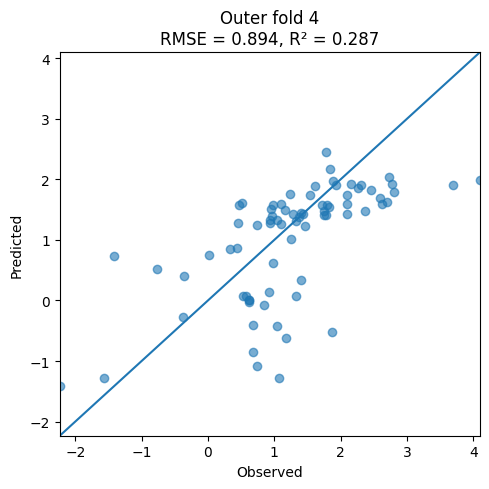

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_22_outerfold_04.json


[I 2026-10-24 03:55:30,779] A new study created in memory with name: no-name-1cbcf3e4-4b82-443e-99b2-5ae31fc19018


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_22_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:55:31,853] Trial 0 finished with value: 1.0217951169955624 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0217951169955624.
[I 2026-10-24 03:55:32,629] Trial 1 finished with value: 1.0465262665365127 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0217951169955624.
[I 2026-10-24 03:55:33,127] Trial 2 finished with value: 1.0186613058715943 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 1.0186613058715943.
[I 2026-10-24 03:55:33,737] Trial 3 finished with value: 1.0248096695778381 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6384 R2 = 0.4173


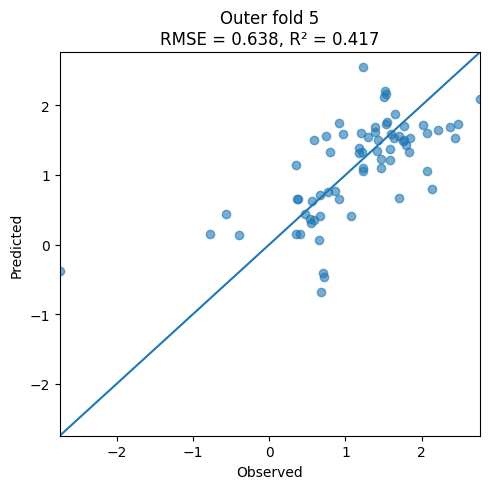

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_22_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_22_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9020 (+/- 0.1504)
Mean R2 (Outer CV): 0.3564 (+/- 0.0515)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 23]


[I 2026-10-24 03:57:30,276] A new study created in memory with name: no-name-c3a09a9a-1a72-4bcc-81f8-168a690e7988


Resuming from existing file. Found 672 previous runs.
Running rs=966, targetTW=23
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:57:30,972] Trial 0 finished with value: 0.873859187063197 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.873859187063197.
[I 2026-10-24 03:57:31,648] Trial 1 finished with value: 0.9026129475374234 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.873859187063197.
[I 2026-10-24 03:57:32,534] Trial 2 finished with value: 0.8948557597888345 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.873859187063197.
[I 2026-10-24 03:57:35,492] Trial 3 finished with value: 0.8719703407254273 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.1037 R2 = 0.2885


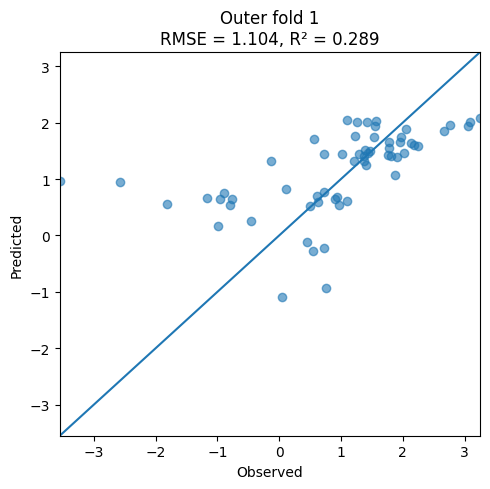

[I 2026-10-24 03:59:24,181] A new study created in memory with name: no-name-c01620c0-d66d-4253-828c-8222d8718a0c


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_23_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_23_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 03:59:25,170] Trial 0 finished with value: 0.9187559197465556 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9187559197465556.
[I 2026-10-24 03:59:25,795] Trial 1 finished with value: 0.9538149756126266 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9187559197465556.
[I 2026-10-24 03:59:26,331] Trial 2 finished with value: 0.9046613718134169 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9046613718134169.
[I 2026-10-24 03:59:26,920] Trial 3 finished with value: 0.9007732001460795 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8396 R2 = 0.4295


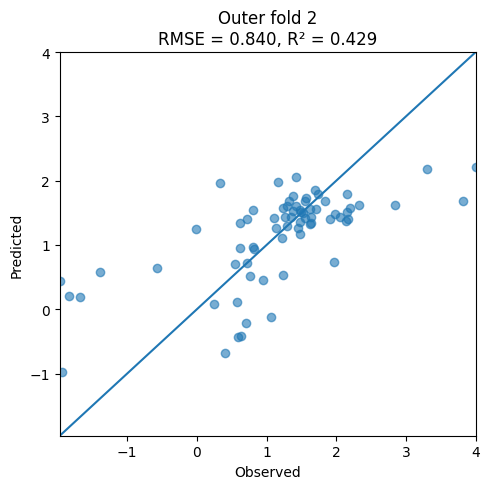

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_23_outerfold_02.json


[I 2026-10-24 04:01:05,634] A new study created in memory with name: no-name-c62b3f3e-c99b-4f8a-817e-a4f482af1181


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_23_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:01:06,878] Trial 0 finished with value: 0.9175208190814851 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9175208190814851.
[I 2026-10-24 04:01:07,582] Trial 1 finished with value: 0.9046341426300617 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9046341426300617.
[I 2026-10-24 04:01:09,023] Trial 2 finished with value: 0.9452356379038656 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9046341426300617.
[I 2026-10-24 04:01:11,678] Trial 3 finished with value: 0.8897640390535884 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0207 R2 = 0.3844


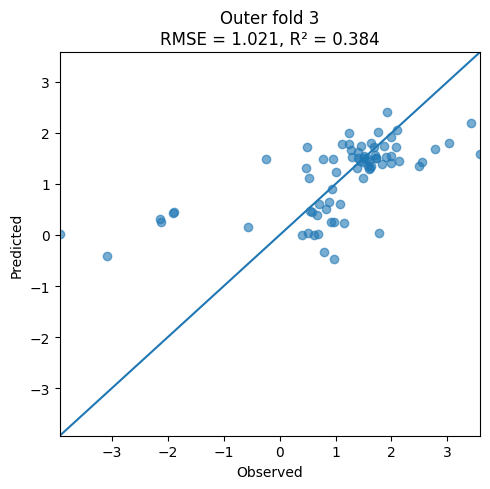

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_23_outerfold_03.json


[I 2026-10-24 04:02:54,828] A new study created in memory with name: no-name-825e304a-30cc-410d-801d-616240fa4dea


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_23_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:02:56,026] Trial 0 finished with value: 0.9581423074618227 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9581423074618227.
[I 2026-10-24 04:02:56,650] Trial 1 finished with value: 1.0104331935833175 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9581423074618227.
[I 2026-10-24 04:02:57,127] Trial 2 finished with value: 0.9887808157451752 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9581423074618227.
[I 2026-10-24 04:02:57,742] Trial 3 finished with value: 0.9949911673928262 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9098 R2 = 0.2623


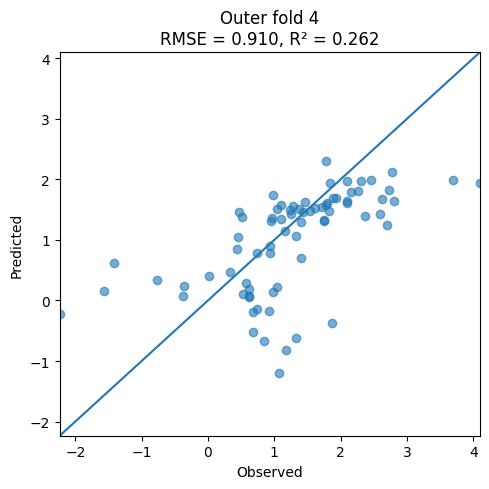

[I 2026-10-24 04:04:45,079] A new study created in memory with name: no-name-449fb35a-d629-4386-aec9-a347b0de2bfa


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_23_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_23_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:04:48,440] Trial 0 finished with value: 1.0144558954517224 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0144558954517224.
[I 2026-10-24 04:04:49,350] Trial 1 finished with value: 1.039153977327231 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0144558954517224.
[I 2026-10-24 04:04:49,872] Trial 2 finished with value: 0.9449101729788145 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9449101729788145.
[I 2026-10-24 04:04:50,543] Trial 3 finished with value: 1.0122448786003972 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6678 R2 = 0.3625


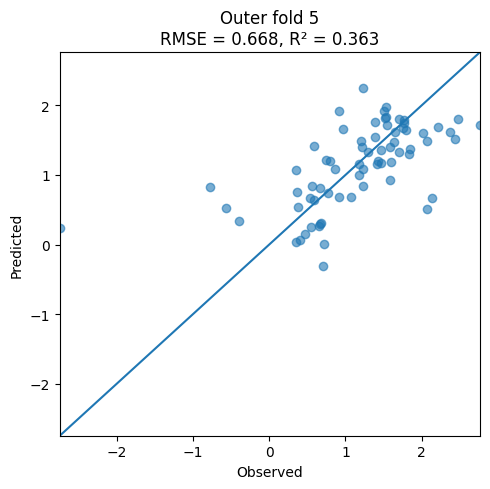

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_23_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_23_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9083 (+/- 0.1506)
Mean R2 (Outer CV): 0.3454 (+/- 0.0617)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 24]


[I 2026-10-24 04:06:22,775] A new study created in memory with name: no-name-bf562b9d-4406-441b-8dc9-5fd14b7eedf2


Resuming from existing file. Found 678 previous runs.
Running rs=966, targetTW=24
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:06:23,576] Trial 0 finished with value: 0.8674073087223054 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8674073087223054.
[I 2026-10-24 04:06:24,260] Trial 1 finished with value: 0.9271137413225157 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8674073087223054.
[I 2026-10-24 04:06:24,802] Trial 2 finished with value: 0.8941824283926896 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8674073087223054.
[I 2026-10-24 04:06:25,311] Trial 3 finished with value: 0.8757463542727789 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.1402 R2 = 0.2407


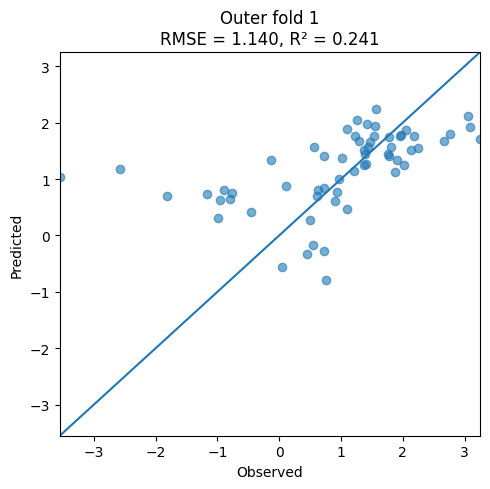

[I 2026-10-24 04:08:06,509] A new study created in memory with name: no-name-f952e8bb-5b07-4d22-aa7a-fb678690c0a0


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_24_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_24_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:08:07,753] Trial 0 finished with value: 0.9291180487841586 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9291180487841586.
[I 2026-10-24 04:08:09,665] Trial 1 finished with value: 0.9675269118045176 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9291180487841586.
[I 2026-10-24 04:08:11,374] Trial 2 finished with value: 0.9506661370013277 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9291180487841586.
[I 2026-10-24 04:08:12,457] Trial 3 finished with value: 0.9248342456540748 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8750 R2 = 0.3804


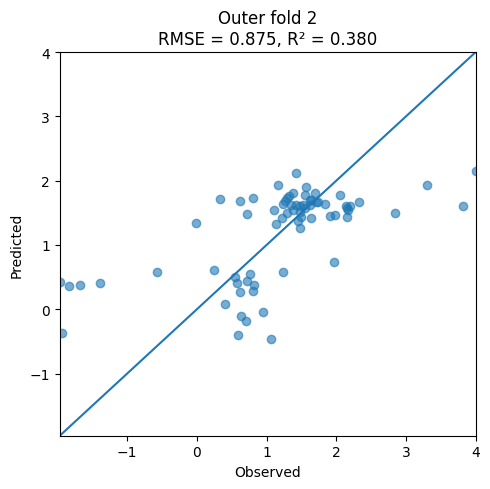

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_24_outerfold_02.json


[I 2026-10-24 04:09:52,841] A new study created in memory with name: no-name-d69bd629-f199-41ea-b831-3c3e13beddd1


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_24_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:09:53,939] Trial 0 finished with value: 0.8752619378621758 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8752619378621758.
[I 2026-10-24 04:09:54,703] Trial 1 finished with value: 0.9186846632006586 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8752619378621758.
[I 2026-10-24 04:09:55,173] Trial 2 finished with value: 0.9391940448688106 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8752619378621758.
[I 2026-10-24 04:09:55,758] Trial 3 finished with value: 0.9144667616756764 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9915 R2 = 0.4190


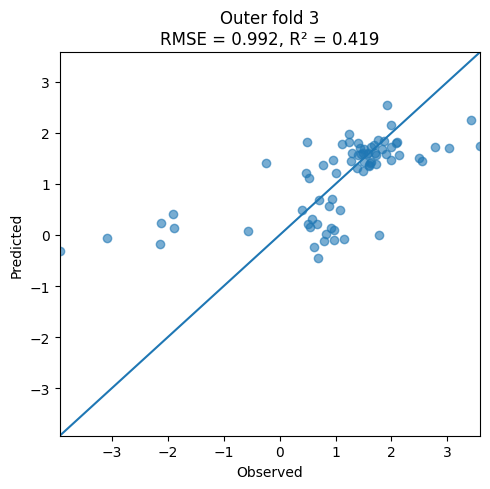

[I 2026-10-24 04:11:30,241] A new study created in memory with name: no-name-e893266f-60ff-4c72-9426-1f2b545d8951


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_24_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_24_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:11:33,331] Trial 0 finished with value: 0.9972103048648273 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9972103048648273.
[I 2026-10-24 04:11:34,682] Trial 1 finished with value: 1.0173069560925332 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9972103048648273.
[I 2026-10-24 04:11:35,189] Trial 2 finished with value: 1.0107107931844772 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9972103048648273.
[I 2026-10-24 04:11:35,793] Trial 3 finished with value: 0.9851272961417551 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9028 R2 = 0.2736


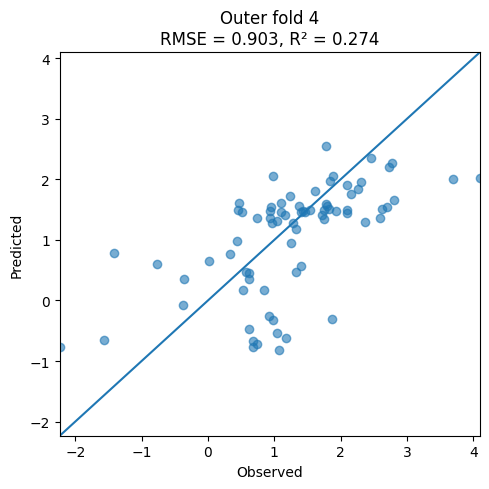

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_24_outerfold_04.json


[I 2026-10-24 04:13:04,938] A new study created in memory with name: no-name-4b22cb78-dca2-4fa9-a034-26623f8ef762


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_24_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:13:06,108] Trial 0 finished with value: 1.0478078118060585 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0478078118060585.
[I 2026-10-24 04:13:06,790] Trial 1 finished with value: 1.0553547673805477 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0478078118060585.
[I 2026-10-24 04:13:07,275] Trial 2 finished with value: 1.0096762501866996 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 1.0096762501866996.
[I 2026-10-24 04:13:07,887] Trial 3 finished with value: 1.0252914174243062 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6250 R2 = 0.4415


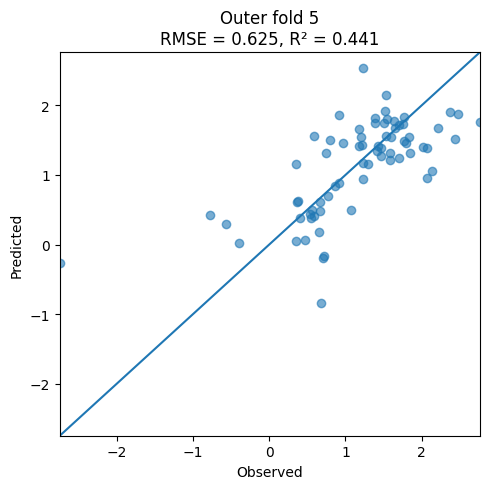

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_24_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_24_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9069 (+/- 0.1686)
Mean R2 (Outer CV): 0.3510 (+/- 0.0798)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 25]


[I 2026-10-24 04:15:03,168] A new study created in memory with name: no-name-93cb8f49-03e2-496e-ae3e-05e180bd4142


Resuming from existing file. Found 684 previous runs.
Running rs=966, targetTW=25
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:15:03,998] Trial 0 finished with value: 0.8627470122685161 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8627470122685161.
[I 2026-10-24 04:15:04,710] Trial 1 finished with value: 0.9057409867790125 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8627470122685161.
[I 2026-10-24 04:15:05,233] Trial 2 finished with value: 0.8872475565183199 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8627470122685161.
[I 2026-10-24 04:15:05,855] Trial 3 finished with value: 0.8744163771067189 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.1036 R2 = 0.2886


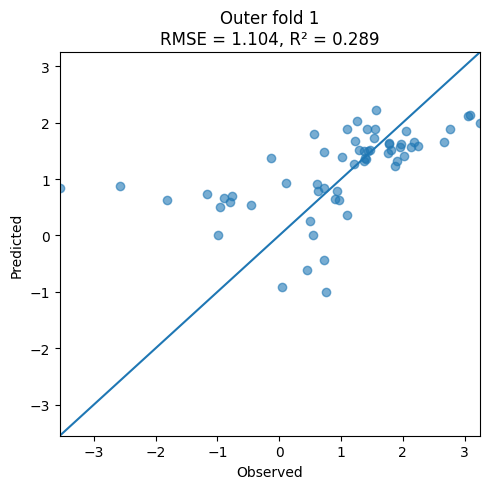

[I 2026-10-24 04:17:02,041] A new study created in memory with name: no-name-4645d453-e0d0-4bd4-b18d-50993ee2133d


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_25_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_25_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:17:05,444] Trial 0 finished with value: 0.9131166027487867 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9131166027487867.
[I 2026-10-24 04:17:06,393] Trial 1 finished with value: 0.9906462565851267 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9131166027487867.
[I 2026-10-24 04:17:06,933] Trial 2 finished with value: 0.9351651308793929 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9131166027487867.
[I 2026-10-24 04:17:07,550] Trial 3 finished with value: 0.9384027960008855 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8612 R2 = 0.3997


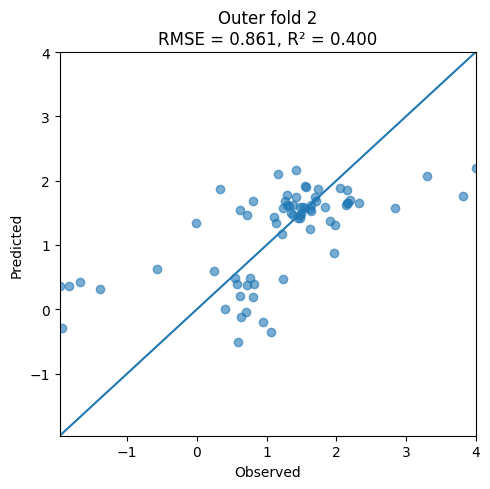

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_25_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_25_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:18:26,502] A new study created in memory with name: no-name-7f0f644f-66fd-4398-afee-036b031d7659
[I 2026-10-24 04:18:27,524] Trial 0 finished with value: 0.9173439559560017 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9173439559560017.
[I 2026-10-24 04:18:28,305] Trial 1 finished with value: 0.9520834290165592 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9173439559560017.
[I 2026-10-24 04:18:28,760] Trial 2 finished with value: 0.9270420629976034 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.91734395

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0773 R2 = 0.3141


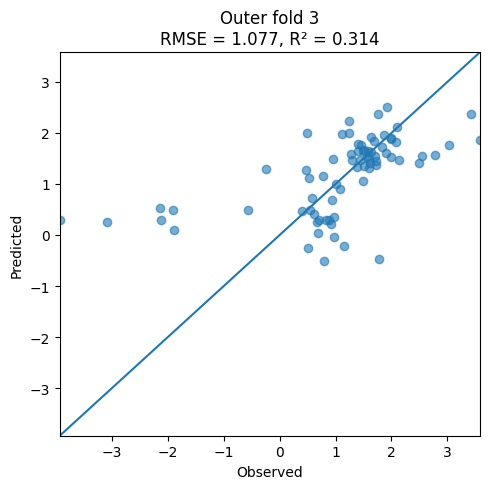

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_25_outerfold_03.json


[I 2026-10-24 04:20:07,901] A new study created in memory with name: no-name-2d9ba297-aefe-4239-8ce4-1937fd199e3a


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_25_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:20:09,061] Trial 0 finished with value: 0.9821226962217834 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9821226962217834.
[I 2026-10-24 04:20:09,742] Trial 1 finished with value: 1.0171363473027075 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9821226962217834.
[I 2026-10-24 04:20:10,549] Trial 2 finished with value: 1.0248097632792146 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9821226962217834.
[I 2026-10-24 04:20:12,305] Trial 3 finished with value: 0.9686680516658647 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9048 R2 = 0.2704


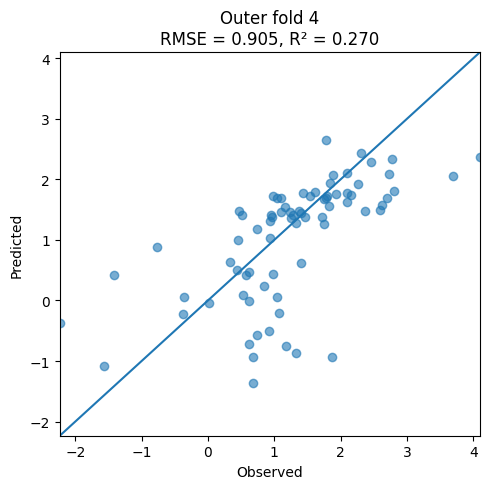

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_25_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_25_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:21:44,880] A new study created in memory with name: no-name-5049a2f2-a7c0-4fea-82f2-4446967419f6
[I 2026-10-24 04:21:45,934] Trial 0 finished with value: 1.0176658782813308 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0176658782813308.
[I 2026-10-24 04:21:46,671] Trial 1 finished with value: 1.035905005286621 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0176658782813308.
[I 2026-10-24 04:21:47,180] Trial 2 finished with value: 0.9659788203376103 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.965978820

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.7138 R2 = 0.2716


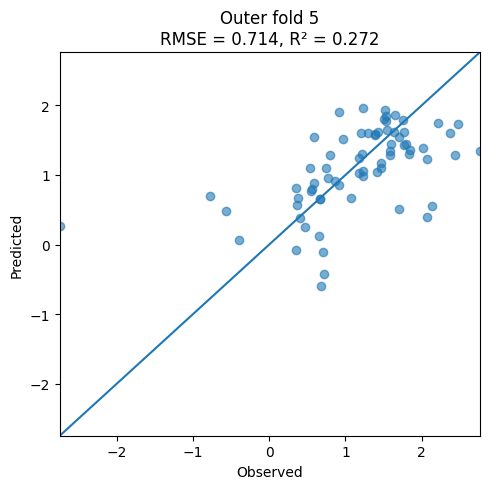

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_25_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_25_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9321 (+/- 0.1442)
Mean R2 (Outer CV): 0.3089 (+/- 0.0481)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 26]


[I 2026-10-24 04:23:37,232] A new study created in memory with name: no-name-ea4cbcf8-f3d2-49fc-9834-12695b9398fd


Resuming from existing file. Found 690 previous runs.
Running rs=966, targetTW=26
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:23:37,992] Trial 0 finished with value: 0.882458491860262 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.882458491860262.
[I 2026-10-24 04:23:38,730] Trial 1 finished with value: 0.9312340172475967 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.882458491860262.
[I 2026-10-24 04:23:39,252] Trial 2 finished with value: 0.8999406236423525 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.882458491860262.
[I 2026-10-24 04:23:39,914] Trial 3 finished with value: 0.8535490133299155 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.1142 R2 = 0.2749


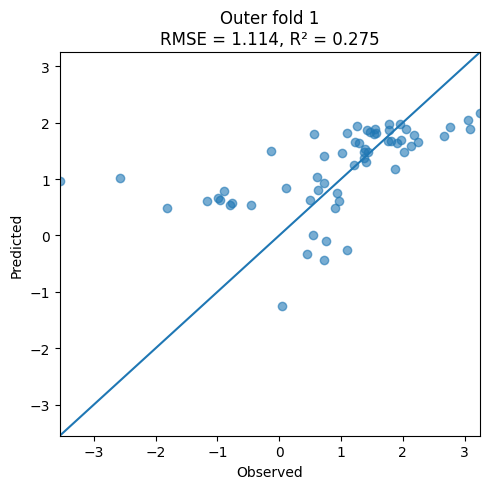

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_26_outerfold_01.json


[I 2026-10-24 04:25:24,714] A new study created in memory with name: no-name-c41f62f3-5cc5-46b7-a491-b8ccf42a5d24


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_26_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:25:25,921] Trial 0 finished with value: 0.9079692959353612 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9079692959353612.
[I 2026-10-24 04:25:27,056] Trial 1 finished with value: 0.98995763594862 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9079692959353612.
[I 2026-10-24 04:25:28,552] Trial 2 finished with value: 0.9490659803259613 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9079692959353612.
[I 2026-10-24 04:25:30,679] Trial 3 finished with value: 0.9304470801217437 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9082 R2 = 0.3324


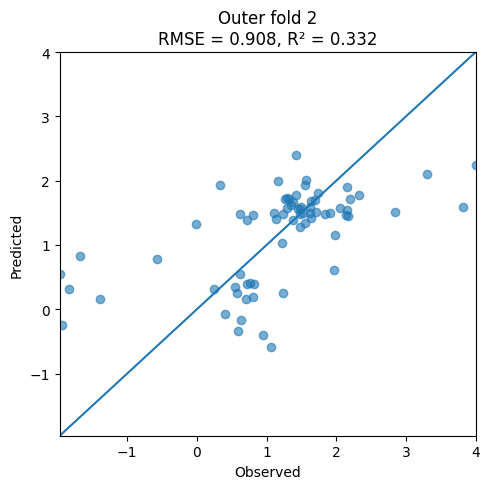

[I 2026-10-24 04:26:59,107] A new study created in memory with name: no-name-fd80d2a4-0006-44a7-b681-56bc4c9e8f8b


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_26_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_26_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:27:00,106] Trial 0 finished with value: 0.9178000960016199 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9178000960016199.
[I 2026-10-24 04:27:00,799] Trial 1 finished with value: 0.8701510256666416 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.8701510256666416.
[I 2026-10-24 04:27:01,361] Trial 2 finished with value: 0.9240157731427179 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.8701510256666416.
[I 2026-10-24 04:27:01,996] Trial 3 finished with value: 0.8891527346918521 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0789 R2 = 0.3121


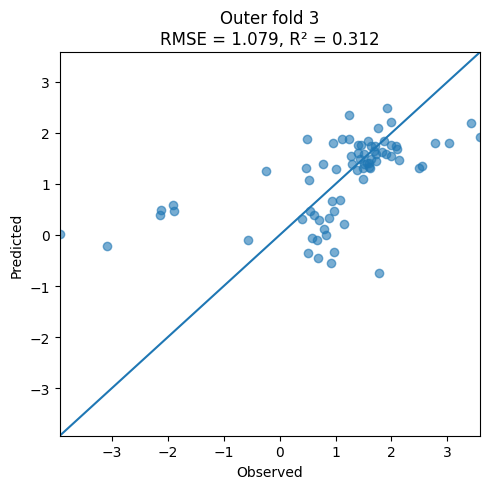

[I 2026-10-24 04:28:37,066] A new study created in memory with name: no-name-4db71f5e-1042-465e-b9f6-0f0e6427ca1c


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_26_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_26_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:28:39,110] Trial 0 finished with value: 0.9683471222977318 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9683471222977318.
[I 2026-10-24 04:28:39,894] Trial 1 finished with value: 1.0298366009934266 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9683471222977318.
[I 2026-10-24 04:28:40,437] Trial 2 finished with value: 1.0067233537614506 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9683471222977318.
[I 2026-10-24 04:28:41,035] Trial 3 finished with value: 0.982364095391447 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9545 R2 = 0.1880


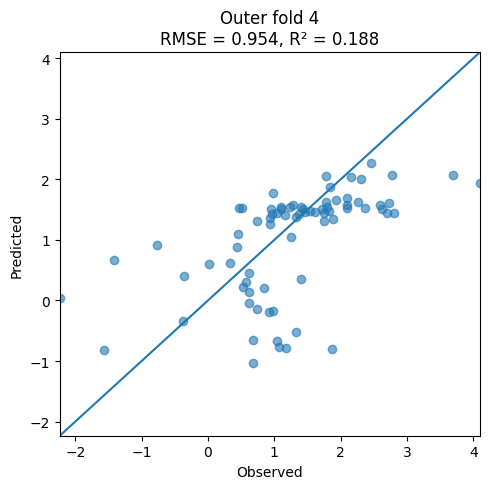

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_26_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_26_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:30:25,943] A new study created in memory with name: no-name-1cb14964-d6c6-4833-8983-4f4b8d0a589f
[I 2026-10-24 04:30:26,958] Trial 0 finished with value: 1.0075117722580593 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0075117722580593.
[I 2026-10-24 04:30:27,687] Trial 1 finished with value: 1.0577634848583402 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0075117722580593.
[I 2026-10-24 04:30:28,253] Trial 2 finished with value: 1.0207853764305757 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.00751177

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6635 R2 = 0.3707


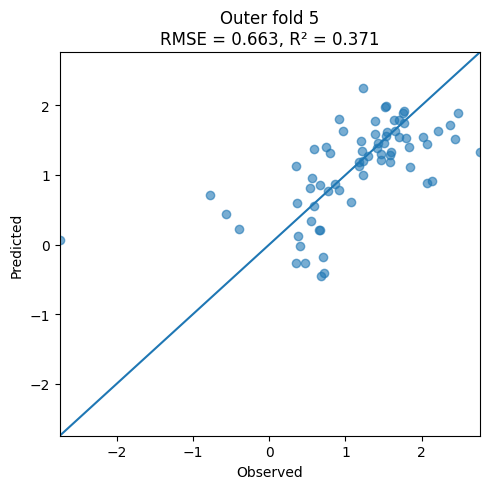

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_26_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_26_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9439 (+/- 0.1595)
Mean R2 (Outer CV): 0.2956 (+/- 0.0621)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 27]


[I 2026-10-24 04:32:10,019] A new study created in memory with name: no-name-adb0d4cd-711b-46c0-b444-48da81b3c6bf


Resuming from existing file. Found 696 previous runs.
Running rs=966, targetTW=27
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:32:10,779] Trial 0 finished with value: 0.8623767617822312 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8623767617822312.
[I 2026-10-24 04:32:11,856] Trial 1 finished with value: 0.9133308145693815 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8623767617822312.
[I 2026-10-24 04:32:13,453] Trial 2 finished with value: 0.92013698035328 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8623767617822312.
[I 2026-10-24 04:32:15,857] Trial 3 finished with value: 0.8908548083678564 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.1090 R2 = 0.2817


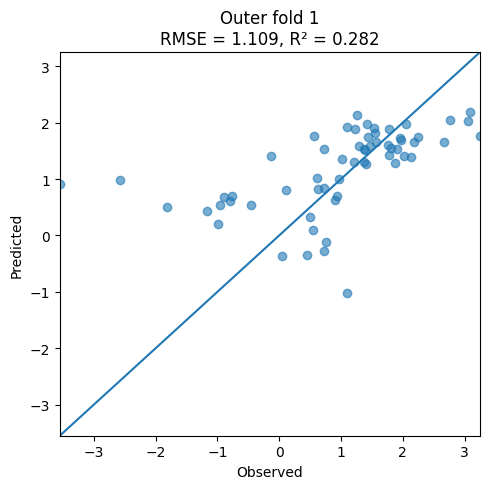

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_27_outerfold_01.json


[I 2026-10-24 04:33:45,780] A new study created in memory with name: no-name-44dbb5bb-1603-49d7-9cb9-8e207061ce07


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_27_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:33:46,970] Trial 0 finished with value: 0.9397750601521089 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9397750601521089.
[I 2026-10-24 04:33:47,699] Trial 1 finished with value: 0.9850065415357631 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9397750601521089.
[I 2026-10-24 04:33:48,231] Trial 2 finished with value: 0.9598216362218448 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9397750601521089.
[I 2026-10-24 04:33:48,827] Trial 3 finished with value: 0.9265501853081187 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8889 R2 = 0.3605


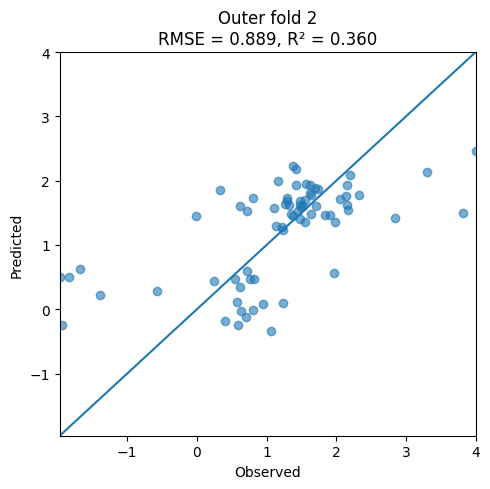

[I 2026-10-24 04:35:08,533] A new study created in memory with name: no-name-806f708b-1459-44ff-8ca2-32625725492e


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_27_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_27_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:35:09,854] Trial 0 finished with value: 0.8838217842815751 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8838217842815751.
[I 2026-10-24 04:35:10,983] Trial 1 finished with value: 0.9266237764235207 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8838217842815751.
[I 2026-10-24 04:35:11,633] Trial 2 finished with value: 0.9235938292532274 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8838217842815751.
[I 2026-10-24 04:35:12,226] Trial 3 finished with value: 0.9175544275905143 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0826 R2 = 0.3074


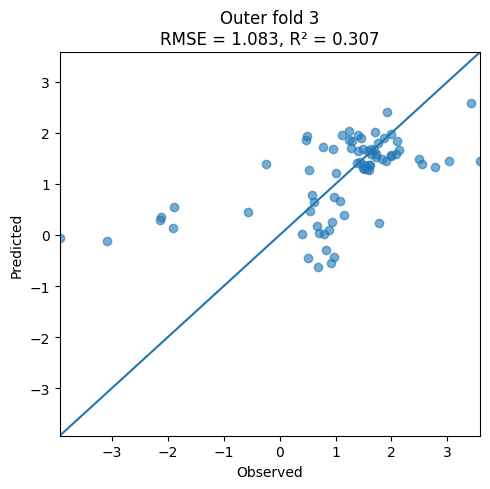

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_27_outerfold_03.json


[I 2026-10-24 04:36:32,709] A new study created in memory with name: no-name-2c464616-227c-46ae-b35a-5a982b3e6f3a


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_27_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:36:33,905] Trial 0 finished with value: 0.9820133039283566 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9820133039283566.
[I 2026-10-24 04:36:35,920] Trial 1 finished with value: 1.0143243642003947 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9820133039283566.
[I 2026-10-24 04:36:37,898] Trial 2 finished with value: 1.0440223187777418 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9820133039283566.
[I 2026-10-24 04:36:38,844] Trial 3 finished with value: 1.0182683158532302 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9256 R2 = 0.2364


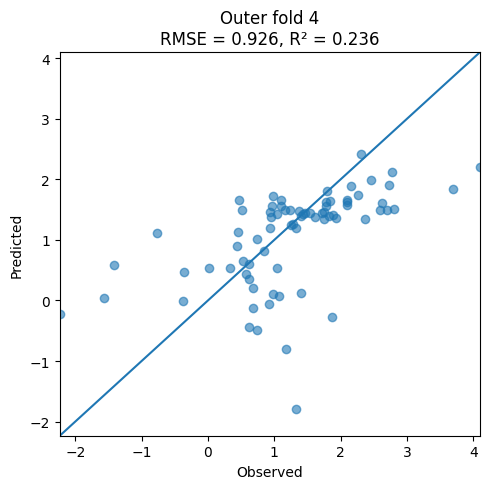

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_27_outerfold_04.json


[I 2026-10-24 04:38:07,263] A new study created in memory with name: no-name-d239ca5d-6e9a-4fea-ac18-37adf4e415be


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_27_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:38:08,632] Trial 0 finished with value: 0.9884158682071078 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9884158682071078.
[I 2026-10-24 04:38:09,343] Trial 1 finished with value: 1.0777387399582168 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9884158682071078.
[I 2026-10-24 04:38:09,870] Trial 2 finished with value: 1.0500590391765805 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9884158682071078.
[I 2026-10-24 04:38:10,512] Trial 3 finished with value: 1.0201580955812668 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6725 R2 = 0.3535


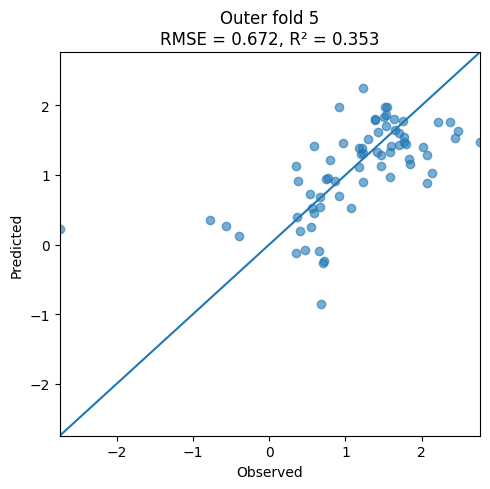

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_27_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_27_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9357 (+/- 0.1569)
Mean R2 (Outer CV): 0.3079 (+/- 0.0461)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 28]


[I 2026-10-24 04:40:44,397] A new study created in memory with name: no-name-ef07131e-23e0-47af-af53-98ed0a18c124


Resuming from existing file. Found 702 previous runs.
Running rs=966, targetTW=28
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:40:45,136] Trial 0 finished with value: 0.8915554176982241 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8915554176982241.
[I 2026-10-24 04:40:45,879] Trial 1 finished with value: 0.9046046772960366 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8915554176982241.
[I 2026-10-24 04:40:46,375] Trial 2 finished with value: 0.885162637451121 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.885162637451121.
[I 2026-10-24 04:40:47,009] Trial 3 finished with value: 0.8868513399724165 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.1127 R2 = 0.2768


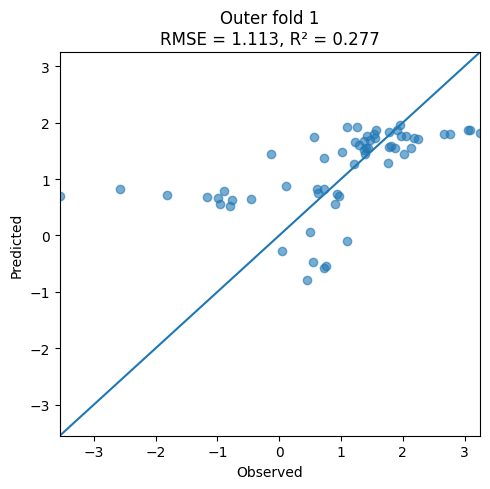

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_28_outerfold_01.json


[I 2026-10-24 04:42:10,812] A new study created in memory with name: no-name-205db161-df3f-4073-a7ee-841c06876d70


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_28_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:42:12,191] Trial 0 finished with value: 0.9098076693833593 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9098076693833593.
[I 2026-10-24 04:42:12,881] Trial 1 finished with value: 0.9852304030021294 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9098076693833593.
[I 2026-10-24 04:42:13,448] Trial 2 finished with value: 0.9655468950740492 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9098076693833593.
[I 2026-10-24 04:42:14,065] Trial 3 finished with value: 0.9395559836785508 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8895 R2 = 0.3596


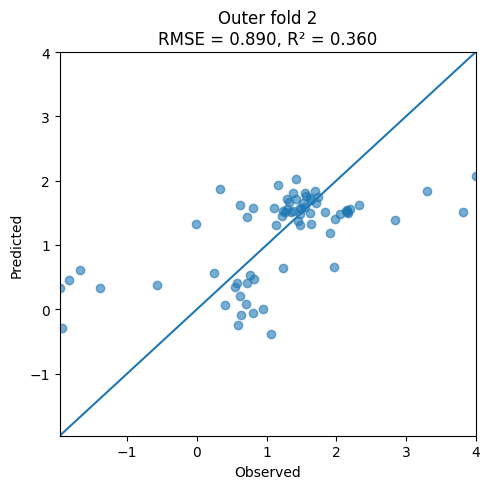

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_28_outerfold_02.json


[I 2026-10-24 04:43:39,822] A new study created in memory with name: no-name-7b106e31-e0e6-46c2-a82f-b3b7987a5872


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_28_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:43:41,104] Trial 0 finished with value: 0.9191675408052502 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9191675408052502.
[I 2026-10-24 04:43:41,738] Trial 1 finished with value: 0.9009970132283823 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9009970132283823.
[I 2026-10-24 04:43:42,306] Trial 2 finished with value: 0.9296255557068874 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9009970132283823.
[I 2026-10-24 04:43:42,941] Trial 3 finished with value: 0.9218825006349894 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0491 R2 = 0.3495


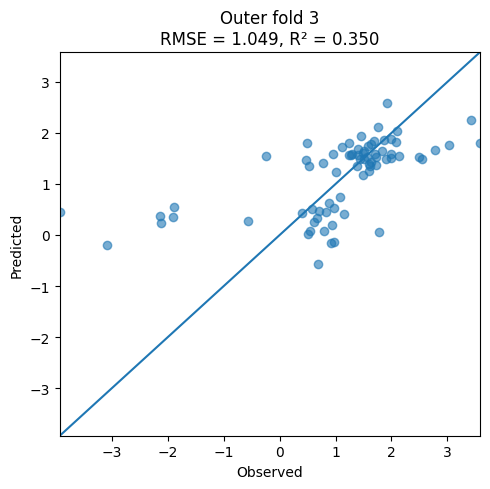

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_28_outerfold_03.json


[I 2026-10-24 04:45:18,425] A new study created in memory with name: no-name-3a0710e0-5478-4d65-ad18-9e0b5f67ffa2


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_28_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:45:19,688] Trial 0 finished with value: 1.0041668828251378 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0041668828251378.
[I 2026-10-24 04:45:20,399] Trial 1 finished with value: 1.066784237968571 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0041668828251378.
[I 2026-10-24 04:45:20,969] Trial 2 finished with value: 1.0231574366865366 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0041668828251378.
[I 2026-10-24 04:45:21,632] Trial 3 finished with value: 1.001898922326031 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8894 R2 = 0.2950


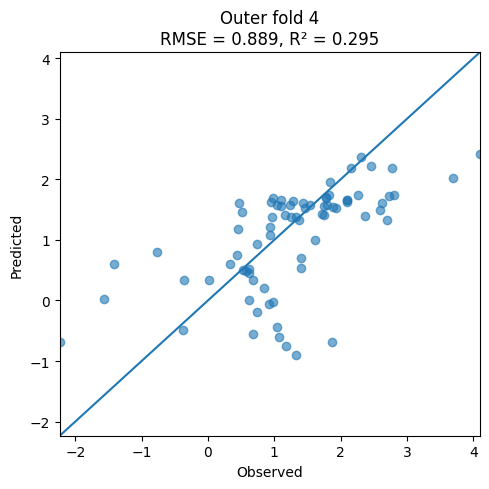

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_28_outerfold_04.json


[I 2026-10-24 04:47:06,294] A new study created in memory with name: no-name-06295d41-95e4-4f3e-990f-c0be62b738e0


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_28_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:47:07,585] Trial 0 finished with value: 1.049112283513459 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.049112283513459.
[I 2026-10-24 04:47:08,303] Trial 1 finished with value: 1.0680327167384038 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.049112283513459.
[I 2026-10-24 04:47:09,181] Trial 2 finished with value: 0.9781670103955791 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9781670103955791.
[I 2026-10-24 04:47:12,642] Trial 3 finished with value: 1.037131082844382 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6539 R2 = 0.3887


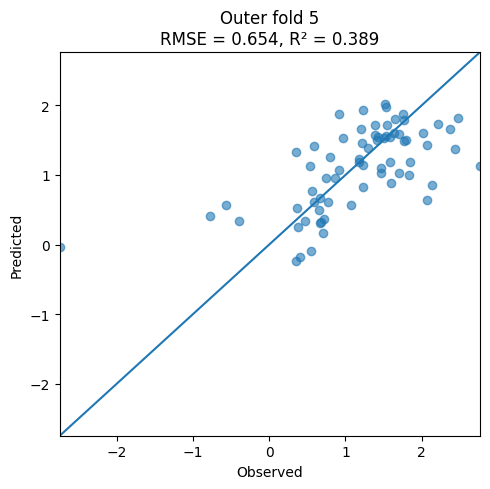

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_28_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_28_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9189 (+/- 0.1591)
Mean R2 (Outer CV): 0.3339 (+/- 0.0417)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 29]


[I 2026-10-24 04:48:50,173] A new study created in memory with name: no-name-33341bc1-cd93-4763-b2a7-3d2b523409ae


Resuming from existing file. Found 708 previous runs.
Running rs=966, targetTW=29
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:48:52,801] Trial 0 finished with value: 0.8888465550907517 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8888465550907517.
[I 2026-10-24 04:48:54,159] Trial 1 finished with value: 0.9475021536955915 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8888465550907517.
[I 2026-10-24 04:48:54,612] Trial 2 finished with value: 0.9183280060414644 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8888465550907517.
[I 2026-10-24 04:48:55,279] Trial 3 finished with value: 0.8972953319300105 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.1089 R2 = 0.2818


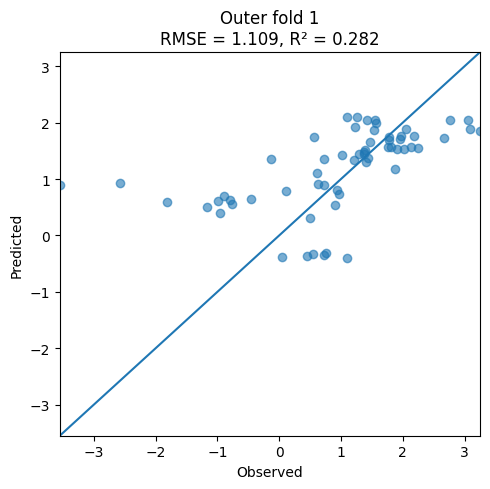

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_29_outerfold_01.json


[I 2026-10-24 04:50:23,830] A new study created in memory with name: no-name-2c482308-d552-435c-8a31-2cb8c25b6ed0


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_29_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:50:24,931] Trial 0 finished with value: 0.9235545557719183 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9235545557719183.
[I 2026-10-24 04:50:25,953] Trial 1 finished with value: 0.9921249154378196 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9235545557719183.
[I 2026-10-24 04:50:26,559] Trial 2 finished with value: 0.9437468740742878 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9235545557719183.
[I 2026-10-24 04:50:27,194] Trial 3 finished with value: 0.9552274335856827 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9043 R2 = 0.3381


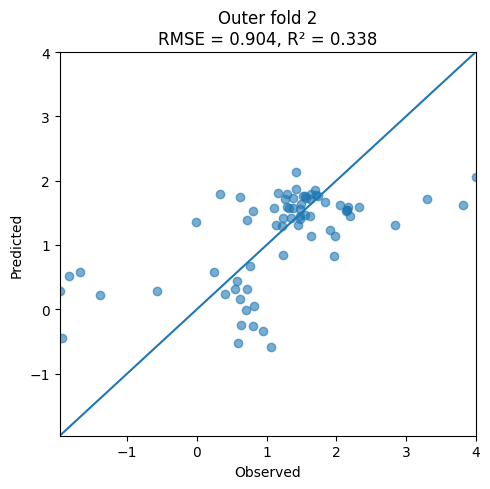

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_29_outerfold_02.json


[I 2026-10-24 04:51:40,383] A new study created in memory with name: no-name-23b38487-59a0-43c8-8a39-4ad5540ddeef


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_29_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:51:41,669] Trial 0 finished with value: 0.9201160902915126 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9201160902915126.
[I 2026-10-24 04:51:42,401] Trial 1 finished with value: 0.909615724645007 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.909615724645007.
[I 2026-10-24 04:51:42,981] Trial 2 finished with value: 0.921968984314761 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.909615724645007.
[I 2026-10-24 04:51:43,603] Trial 3 finished with value: 0.920432960953552 and parameters: {'max_depth': 3, 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0997 R2 = 0.2853


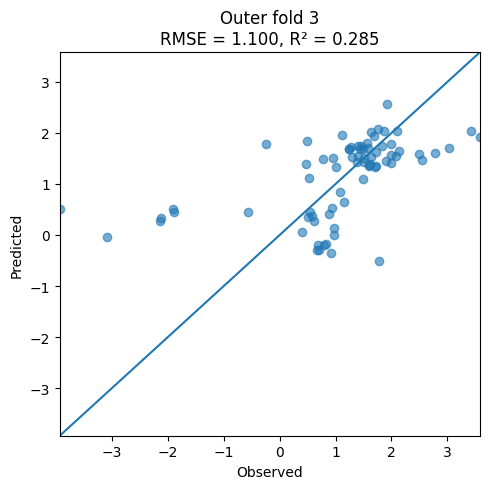

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_29_outerfold_03.json


[I 2026-10-24 04:53:25,040] A new study created in memory with name: no-name-deac3689-08a3-41ff-bc63-c02d01741012


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_29_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:53:26,259] Trial 0 finished with value: 0.9763293223227332 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9763293223227332.
[I 2026-10-24 04:53:27,826] Trial 1 finished with value: 1.0139621809594932 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9763293223227332.
[I 2026-10-24 04:53:28,908] Trial 2 finished with value: 1.0180959069494324 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9763293223227332.
[I 2026-10-24 04:53:30,996] Trial 3 finished with value: 0.9960303899833325 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.9146 R2 = 0.2545


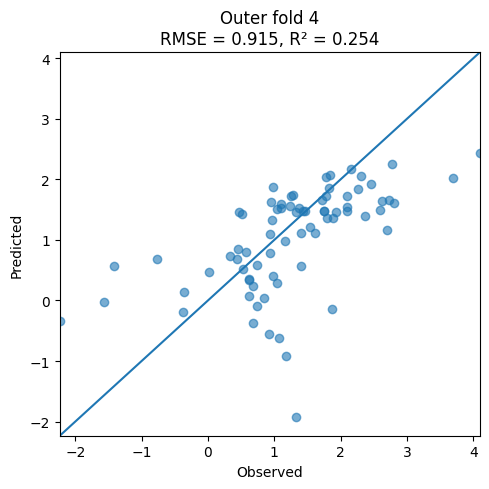

[I 2026-10-24 04:55:08,242] A new study created in memory with name: no-name-f5373220-34ab-4a2d-a143-993008ee2a85


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_29_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_29_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:55:09,569] Trial 0 finished with value: 1.0132639300755824 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0132639300755824.
[I 2026-10-24 04:55:11,451] Trial 1 finished with value: 1.0478870742833823 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0132639300755824.
[I 2026-10-24 04:55:13,398] Trial 2 finished with value: 1.015931988151073 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0132639300755824.
[I 2026-10-24 04:55:14,305] Trial 3 finished with value: 1.0573027028772155 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.6384 R2 = 0.4173


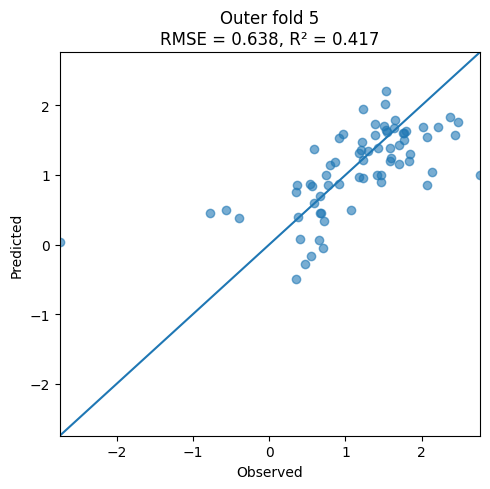

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_29_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_29_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9332 (+/- 0.1713)
Mean R2 (Outer CV): 0.3154 (+/- 0.0577)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 30]


[I 2026-10-24 04:56:58,854] A new study created in memory with name: no-name-5e8ac4e0-dd8d-48fb-892b-38c43e48f1bd


Resuming from existing file. Found 714 previous runs.
Running rs=966, targetTW=30
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:56:59,567] Trial 0 finished with value: 0.9087608676598602 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9087608676598602.
[I 2026-10-24 04:57:00,285] Trial 1 finished with value: 0.9688086894599667 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9087608676598602.
[I 2026-10-24 04:57:00,809] Trial 2 finished with value: 0.9477862820227281 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9087608676598602.
[I 2026-10-24 04:57:01,531] Trial 3 finished with value: 0.8967273360871328 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.1052 R2 = 0.2867


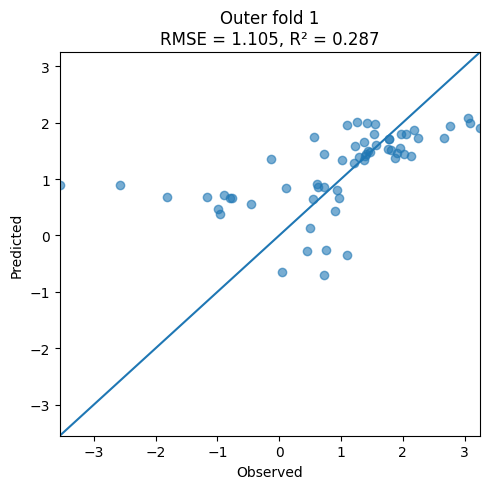

[I 2026-10-24 04:59:21,735] A new study created in memory with name: no-name-9dcef2b3-3754-49ff-a66a-62923e570131


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_30_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_30_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 04:59:22,881] Trial 0 finished with value: 0.9176938262793415 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9176938262793415.
[I 2026-10-24 04:59:23,703] Trial 1 finished with value: 0.9839410181288752 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9176938262793415.
[I 2026-10-24 04:59:24,265] Trial 2 finished with value: 0.9836288960168709 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9176938262793415.
[I 2026-10-24 04:59:24,930] Trial 3 finished with value: 0.9666795278125531 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8798 R2 = 0.3736


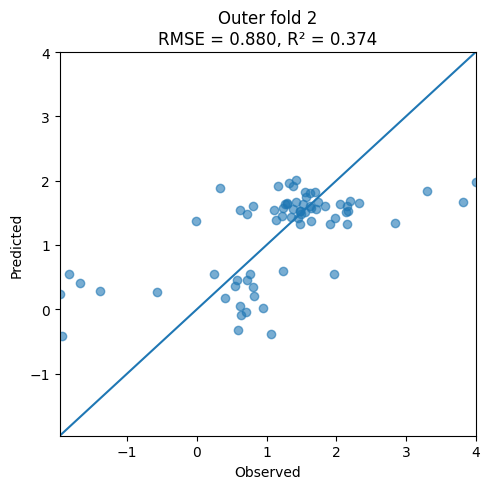

[I 2026-10-24 05:01:01,137] A new study created in memory with name: no-name-6a970835-2b7a-4364-8a4d-a3328908dd7d


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_30_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_30_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:01:02,471] Trial 0 finished with value: 0.9306225476371834 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9306225476371834.
[I 2026-10-24 05:01:03,185] Trial 1 finished with value: 0.8912234972816406 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.8912234972816406.
[I 2026-10-24 05:01:03,744] Trial 2 finished with value: 0.9370631180599074 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.8912234972816406.
[I 2026-10-24 05:01:04,260] Trial 3 finished with value: 0.9045507748640325 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0874 R2 = 0.3013


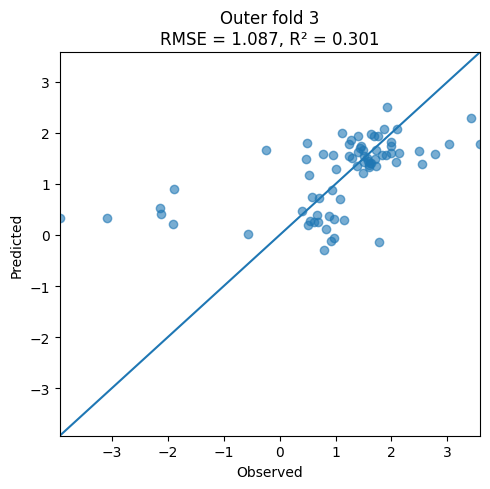

[I 2026-10-24 05:02:51,142] A new study created in memory with name: no-name-00ed452a-390b-43d4-8303-84367a30c206


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_30_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_30_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:02:52,943] Trial 0 finished with value: 1.003003175954928 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.003003175954928.
[I 2026-10-24 05:02:55,109] Trial 1 finished with value: 1.0225365180865655 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.003003175954928.
[I 2026-10-24 05:02:56,617] Trial 2 finished with value: 1.050039449557787 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.003003175954928.
[I 2026-10-24 05:02:57,253] Trial 3 finished with value: 1.0133931787778205 and parameters: {'max_depth': 3, 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8869 R2 = 0.2990


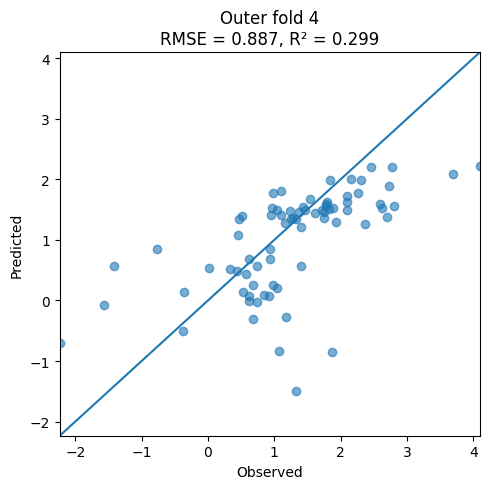

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_30_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_30_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:04:43,024] A new study created in memory with name: no-name-eece8213-a79f-41e5-881a-f75b9f0e87d3
[I 2026-10-24 05:04:44,151] Trial 0 finished with value: 1.0388538769042595 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0388538769042595.
[I 2026-10-24 05:04:44,902] Trial 1 finished with value: 1.0836317496897494 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0388538769042595.
[I 2026-10-24 05:04:45,472] Trial 2 finished with value: 1.0438132203612176 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.03885387

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.7008 R2 = 0.2979


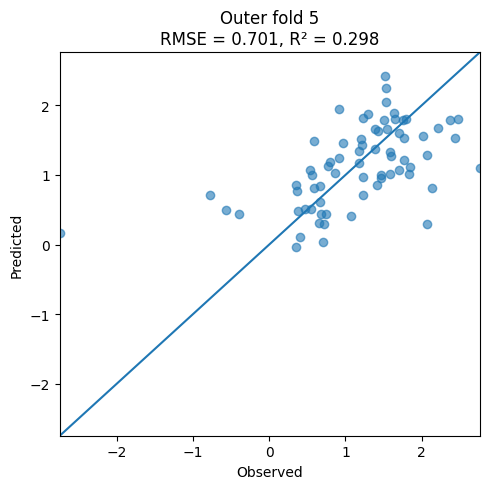

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_30_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_966_TW_30_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9320 (+/- 0.1499)
Mean R2 (Outer CV): 0.3117 (+/- 0.0314)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 1]


[I 2026-10-24 05:06:43,620] A new study created in memory with name: no-name-3e992a7b-0ebc-4c6a-be77-35c7f76d5754


Resuming from existing file. Found 720 previous runs.
Running rs=786, targetTW=1
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:06:45,458] Trial 0 finished with value: 0.8802418511079378 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8802418511079378.
[I 2026-10-24 05:06:47,374] Trial 1 finished with value: 0.9570528805887297 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8802418511079378.
[I 2026-10-24 05:06:47,962] Trial 2 finished with value: 0.9226396445867711 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8802418511079378.
[I 2026-10-24 05:06:48,626] Trial 3 finished with value: 0.9066829644774683 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0405 R2 = 0.3509


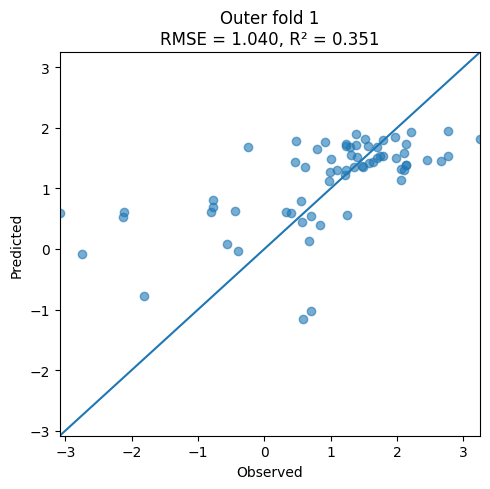

[I 2026-10-24 05:08:31,736] A new study created in memory with name: no-name-64903e4b-c612-4700-986d-167fb9fd83c6


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_01_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_01_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:08:32,971] Trial 0 finished with value: 0.9352792434056538 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9352792434056538.
[I 2026-10-24 05:08:33,668] Trial 1 finished with value: 1.0302170946734965 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9352792434056538.
[I 2026-10-24 05:08:34,257] Trial 2 finished with value: 1.0056670574432371 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9352792434056538.
[I 2026-10-24 05:08:34,908] Trial 3 finished with value: 0.9571825795568831 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8166 R2 = 0.3468


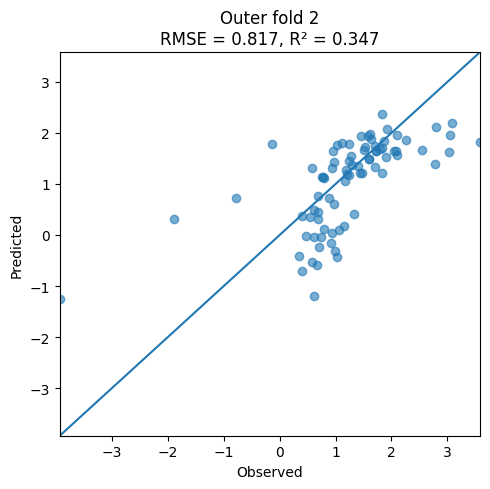

[I 2026-10-24 05:10:04,929] A new study created in memory with name: no-name-ff126dbb-f93b-47a6-b2ee-201144811d1f


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_01_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_01_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:10:06,160] Trial 0 finished with value: 0.96310890471778 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.96310890471778.
[I 2026-10-24 05:10:07,137] Trial 1 finished with value: 0.9810103550643776 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.96310890471778.
[I 2026-10-24 05:10:08,801] Trial 2 finished with value: 0.9419266715473283 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9419266715473283.
[I 2026-10-24 05:10:11,401] Trial 3 finished with value: 0.953588139520635 and parameters: {'max_depth': 3, 'g

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0167 R2 = 0.3995


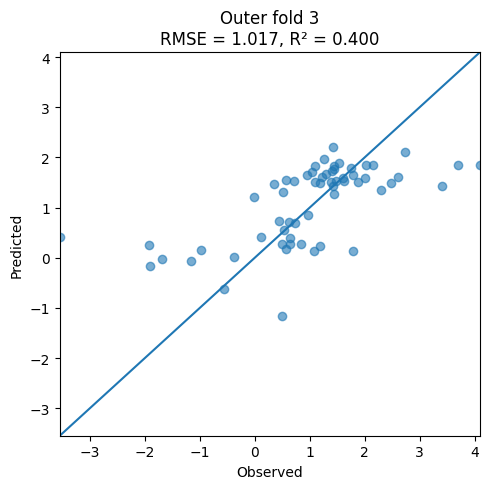

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_01_outerfold_03.json


[I 2026-10-24 05:11:47,033] A new study created in memory with name: no-name-8a0911c6-edd9-4664-ad62-dd516d44724a


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_01_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:11:48,658] Trial 0 finished with value: 0.9827572513227787 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9827572513227787.
[I 2026-10-24 05:11:51,137] Trial 1 finished with value: 1.0501290690391325 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9827572513227787.
[I 2026-10-24 05:11:52,980] Trial 2 finished with value: 1.0295700218235748 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9827572513227787.
[I 2026-10-24 05:11:53,608] Trial 3 finished with value: 0.9854684864780638 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7936 R2 = 0.4362


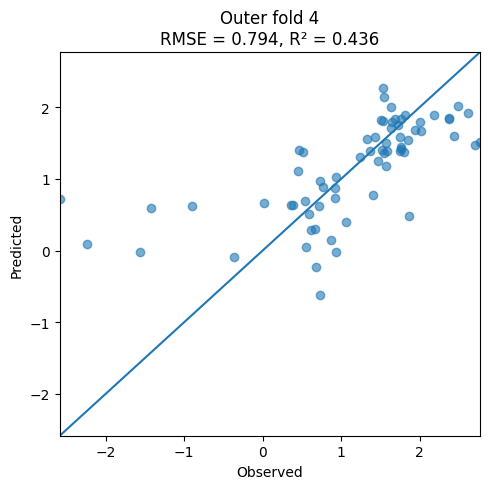

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_01_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_01_outerfold_04_meta.json

=== Outer fold 5/5 ===


[I 2026-10-24 05:13:26,432] A new study created in memory with name: no-name-16ecc795-e33c-4bd4-9276-143390e2767e


Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:13:28,062] Trial 0 finished with value: 0.9644474508543142 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9644474508543142.
[I 2026-10-24 05:13:28,869] Trial 1 finished with value: 1.0068051346320055 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9644474508543142.
[I 2026-10-24 05:13:29,511] Trial 2 finished with value: 0.9761835937428464 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9644474508543142.
[I 2026-10-24 05:13:30,232] Trial 3 finished with value: 0.9611867555920979 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8325 R2 = 0.3013


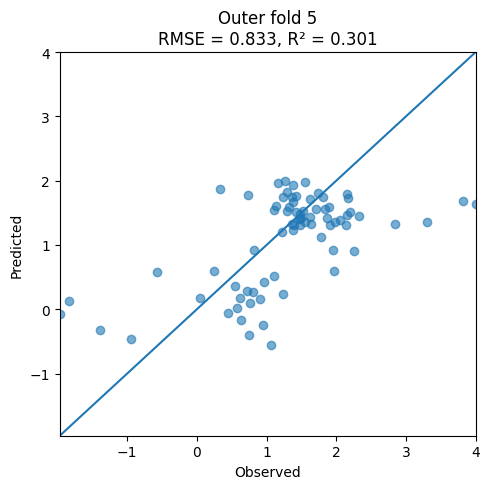

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_01_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_01_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9000 (+/- 0.1060)
Mean R2 (Outer CV): 0.3669 (+/- 0.0465)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 2]


[I 2026-10-24 05:15:29,986] A new study created in memory with name: no-name-eccda9e6-03ce-473a-b3fa-237dda8215f2


Resuming from existing file. Found 726 previous runs.
Running rs=786, targetTW=2
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:15:31,820] Trial 0 finished with value: 0.912189704840735 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.912189704840735.
[I 2026-10-24 05:15:32,644] Trial 1 finished with value: 1.0291408460647937 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.912189704840735.
[I 2026-10-24 05:15:33,260] Trial 2 finished with value: 0.9523871400623849 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.912189704840735.
[I 2026-10-24 05:15:33,981] Trial 3 finished with value: 0.9764857694109528 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.9972 R2 = 0.4037


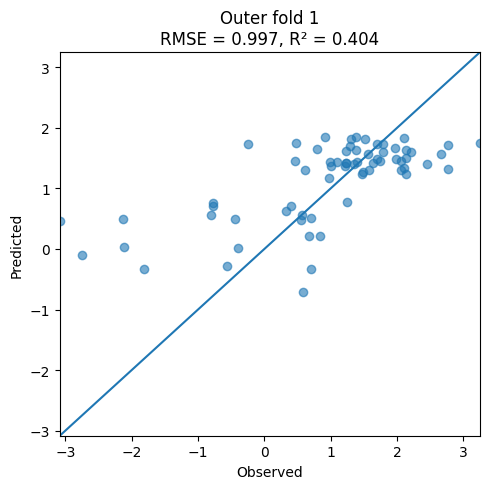

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_02_outerfold_01.json


[I 2026-10-24 05:17:21,898] A new study created in memory with name: no-name-56160305-5e5e-440a-b077-c40a0ee17c33


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_02_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:17:23,555] Trial 0 finished with value: 0.9721340104910723 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9721340104910723.
[I 2026-10-24 05:17:26,752] Trial 1 finished with value: 1.0247417782248767 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9721340104910723.
[I 2026-10-24 05:17:27,752] Trial 2 finished with value: 1.0313324474942798 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9721340104910723.
[I 2026-10-24 05:17:28,477] Trial 3 finished with value: 0.9810351171324465 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8269 R2 = 0.3301


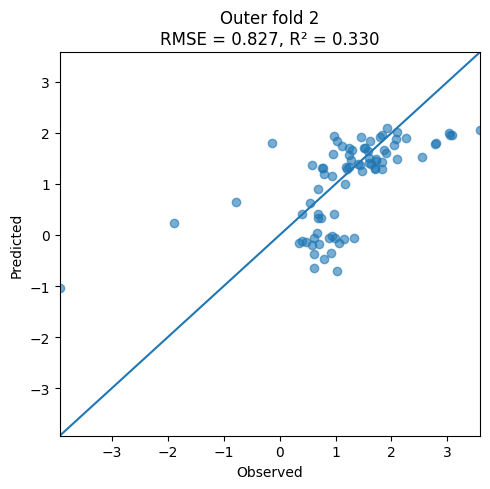

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_02_outerfold_02.json


[I 2026-10-24 05:19:17,129] A new study created in memory with name: no-name-54f26dd6-7f60-4223-8db3-255f3cd852f4


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_02_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:19:18,542] Trial 0 finished with value: 0.9463466095067418 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9463466095067418.
[I 2026-10-24 05:19:19,447] Trial 1 finished with value: 1.006265640721549 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9463466095067418.
[I 2026-10-24 05:19:21,093] Trial 2 finished with value: 0.943061656300888 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.943061656300888.
[I 2026-10-24 05:19:23,857] Trial 3 finished with value: 0.9496177766388222 and parameters: {'max_depth': 3

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0376 R2 = 0.3745


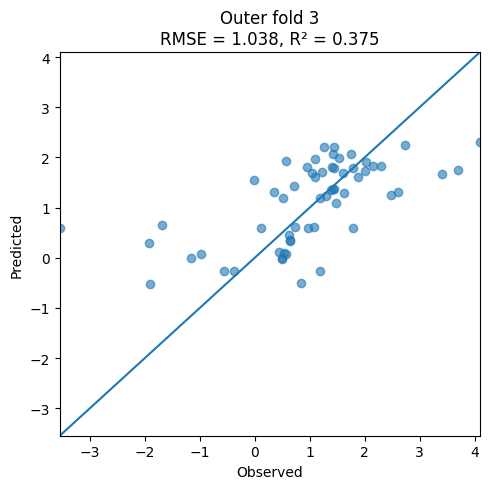

[I 2026-10-24 05:21:12,370] A new study created in memory with name: no-name-02bedb32-bbe7-4a9f-8275-db39cc76ad97


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_02_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_02_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:21:13,595] Trial 0 finished with value: 0.9937079307300104 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9937079307300104.
[I 2026-10-24 05:21:14,276] Trial 1 finished with value: 1.059869380930212 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9937079307300104.
[I 2026-10-24 05:21:14,873] Trial 2 finished with value: 1.0049688515058448 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9937079307300104.
[I 2026-10-24 05:21:16,287] Trial 3 finished with value: 0.9987985187821065 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8594 R2 = 0.3388


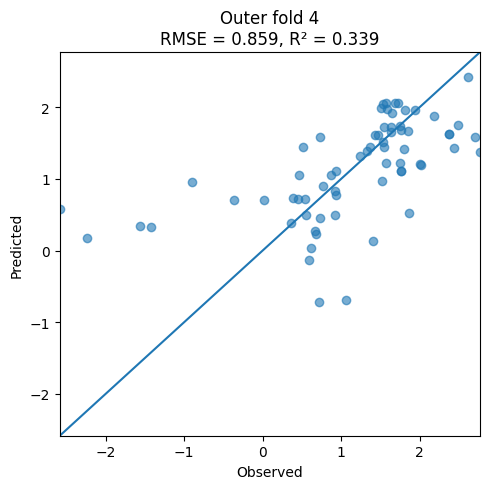

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_02_outerfold_04.json


[I 2026-10-24 05:22:51,564] A new study created in memory with name: no-name-993cdd6d-7dac-44e7-933e-83f7ac19021a


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_02_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:22:53,001] Trial 0 finished with value: 0.9235405478523326 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9235405478523326.
[I 2026-10-24 05:22:53,777] Trial 1 finished with value: 1.0075409773363972 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9235405478523326.
[I 2026-10-24 05:22:54,384] Trial 2 finished with value: 0.9847175867093774 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9235405478523326.
[I 2026-10-24 05:22:54,989] Trial 3 finished with value: 0.9396819642595364 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8640 R2 = 0.2474


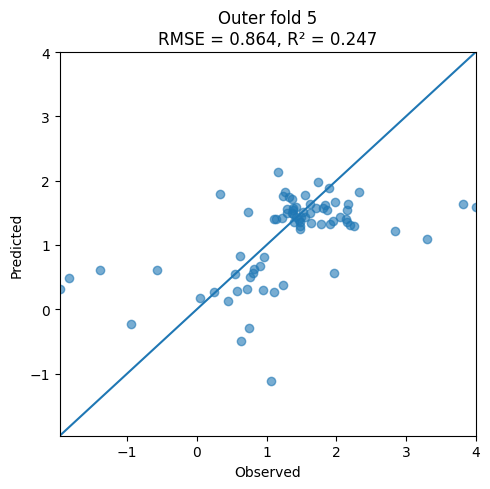

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_02_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_02_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9171 (+/- 0.0839)
Mean R2 (Outer CV): 0.3389 (+/- 0.0528)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 3]


[I 2026-10-24 05:24:42,989] A new study created in memory with name: no-name-1cf1629e-d85c-41ca-8ba2-9958c15eb5e8


Resuming from existing file. Found 732 previous runs.
Running rs=786, targetTW=3
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:24:43,826] Trial 0 finished with value: 0.939158531757052 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.939158531757052.
[I 2026-10-24 05:24:44,555] Trial 1 finished with value: 1.0147332985817856 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.939158531757052.
[I 2026-10-24 05:24:45,090] Trial 2 finished with value: 0.9638056181291494 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.939158531757052.
[I 2026-10-24 05:24:45,735] Trial 3 finished with value: 0.9539807618838702 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0436 R2 = 0.3470


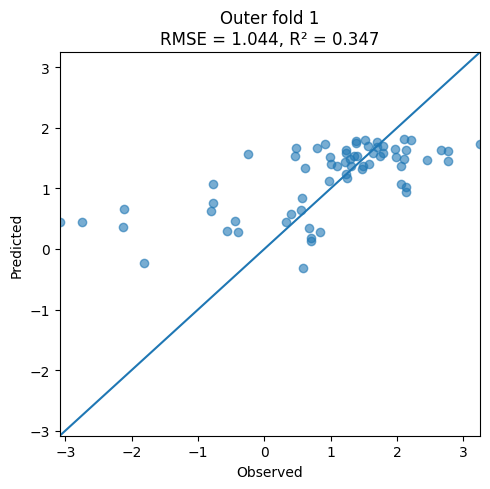

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_03_outerfold_01.json


[I 2026-10-24 05:26:30,406] A new study created in memory with name: no-name-1c0976b0-c8bb-4bef-9563-b82677760afb


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_03_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:26:31,823] Trial 0 finished with value: 0.9786233014614345 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9786233014614345.
[I 2026-10-24 05:26:32,546] Trial 1 finished with value: 1.0355875624318955 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9786233014614345.
[I 2026-10-24 05:26:33,087] Trial 2 finished with value: 1.0754496488891339 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9786233014614345.
[I 2026-10-24 05:26:33,760] Trial 3 finished with value: 1.020235590338552 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8527 R2 = 0.2876


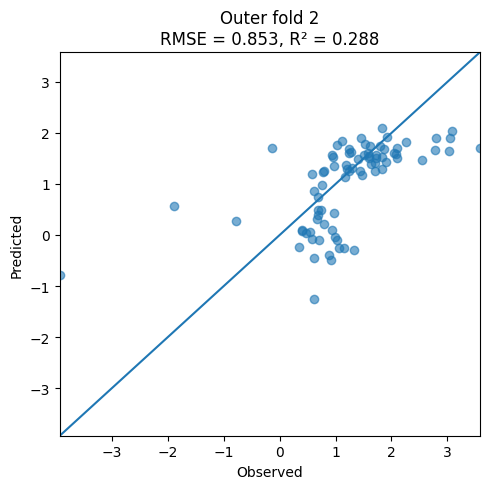

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_03_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_03_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:28:28,581] A new study created in memory with name: no-name-3aca62c6-b80d-4e43-acc9-86b29e05119e
[I 2026-10-24 05:28:32,752] Trial 0 finished with value: 0.9747747736804935 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9747747736804935.
[I 2026-10-24 05:28:33,757] Trial 1 finished with value: 1.0191321009061154 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9747747736804935.
[I 2026-10-24 05:28:34,329] Trial 2 finished with value: 0.9700129041694329 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.97001290

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0249 R2 = 0.3898


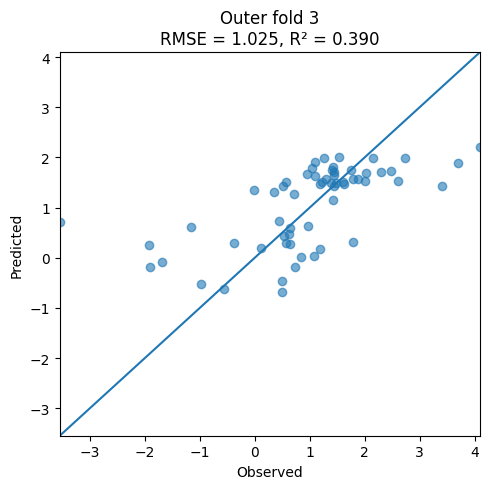

[I 2026-10-24 05:30:21,946] A new study created in memory with name: no-name-41f0aa5a-fcf2-4fca-9595-0cc29eddcade


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_03_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_03_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:30:23,141] Trial 0 finished with value: 1.026906349100651 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.026906349100651.
[I 2026-10-24 05:30:23,921] Trial 1 finished with value: 1.096495304926345 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.026906349100651.
[I 2026-10-24 05:30:24,532] Trial 2 finished with value: 1.0742502895990023 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.026906349100651.
[I 2026-10-24 05:30:25,174] Trial 3 finished with value: 1.0343130251951833 and parameters: {'max_depth': 3, 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8168 R2 = 0.4028


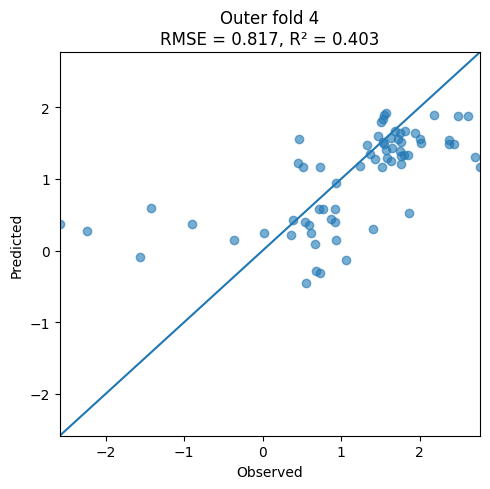

[I 2026-10-24 05:31:53,230] A new study created in memory with name: no-name-b16d3935-acf5-404a-adf2-4bf870e86458


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_03_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_03_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:31:54,410] Trial 0 finished with value: 0.9478867387653105 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9478867387653105.
[I 2026-10-24 05:31:57,851] Trial 1 finished with value: 1.007319419655631 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9478867387653105.
[I 2026-10-24 05:31:58,483] Trial 2 finished with value: 1.0178593839408583 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9478867387653105.
[I 2026-10-24 05:31:59,161] Trial 3 finished with value: 0.9719989082386452 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.9143 R2 = 0.1572


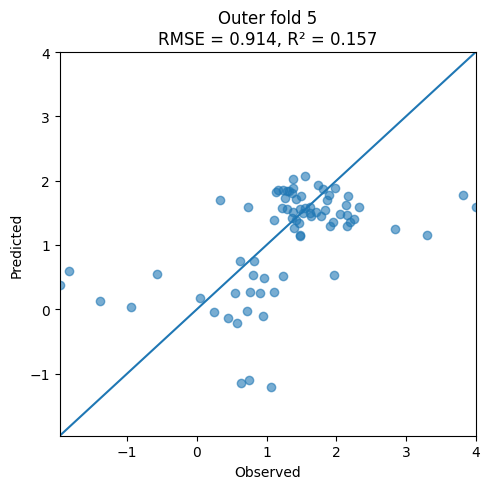

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_03_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_03_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9305 (+/- 0.0905)
Mean R2 (Outer CV): 0.3169 (+/- 0.0894)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 4]


[I 2026-10-24 05:33:44,146] A new study created in memory with name: no-name-7fb08207-f5a2-4be5-b3e7-6896d7b4f486


Resuming from existing file. Found 738 previous runs.
Running rs=786, targetTW=4
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:33:45,000] Trial 0 finished with value: 0.8892010887214608 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8892010887214608.
[I 2026-10-24 05:33:45,782] Trial 1 finished with value: 0.9620633685451292 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8892010887214608.
[I 2026-10-24 05:33:46,368] Trial 2 finished with value: 0.9753520536460305 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8892010887214608.
[I 2026-10-24 05:33:47,022] Trial 3 finished with value: 0.9410735476882963 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0395 R2 = 0.3520


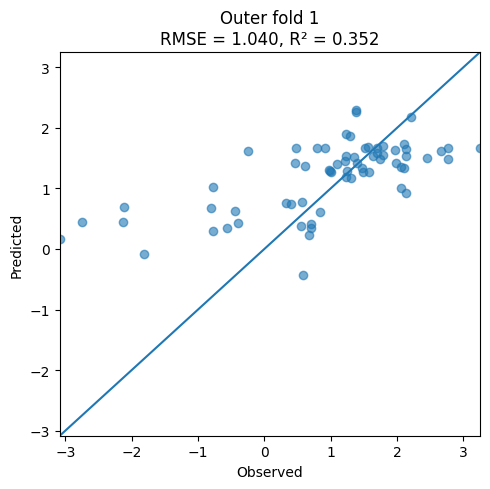

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_04_outerfold_01.json


[I 2026-10-24 05:35:30,012] A new study created in memory with name: no-name-99fc9531-5d34-47e0-a61f-e62f441a0ada


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_04_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:35:31,453] Trial 0 finished with value: 0.9338282167514851 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9338282167514851.
[I 2026-10-24 05:35:33,571] Trial 1 finished with value: 1.0257095655706163 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9338282167514851.
[I 2026-10-24 05:35:35,521] Trial 2 finished with value: 1.0324884265313337 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9338282167514851.
[I 2026-10-24 05:35:36,437] Trial 3 finished with value: 1.024810381947617 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8055 R2 = 0.3645


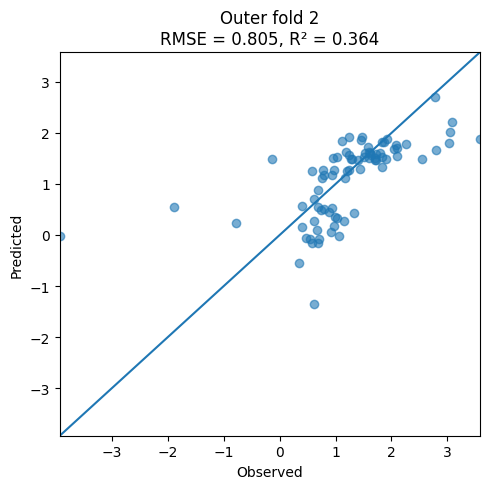

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_04_outerfold_02.json


[I 2026-10-24 05:37:22,479] A new study created in memory with name: no-name-7a673318-24f5-48b6-bf62-674d35e4443a


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_04_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:37:23,975] Trial 0 finished with value: 0.9683911535374352 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9683911535374352.
[I 2026-10-24 05:37:24,774] Trial 1 finished with value: 1.0502001826651464 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9683911535374352.
[I 2026-10-24 05:37:25,267] Trial 2 finished with value: 0.9613677533484108 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9613677533484108.
[I 2026-10-24 05:37:25,950] Trial 3 finished with value: 0.9603788042145618 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9805 R2 = 0.4416


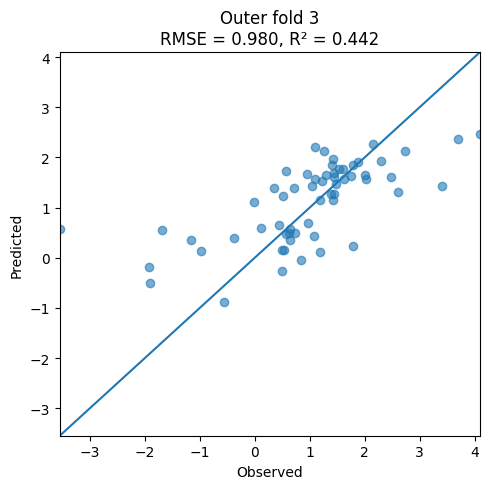

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_04_outerfold_03.json


[I 2026-10-24 05:39:18,306] A new study created in memory with name: no-name-e4a15e35-5d68-4a8f-8cac-16ec813ecf37


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_04_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:39:19,918] Trial 0 finished with value: 0.9989309287091073 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9989309287091073.
[I 2026-10-24 05:39:20,687] Trial 1 finished with value: 1.082013996634722 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9989309287091073.
[I 2026-10-24 05:39:21,304] Trial 2 finished with value: 1.0851796120351143 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9989309287091073.
[I 2026-10-24 05:39:21,986] Trial 3 finished with value: 1.008975510251299 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8359 R2 = 0.3745


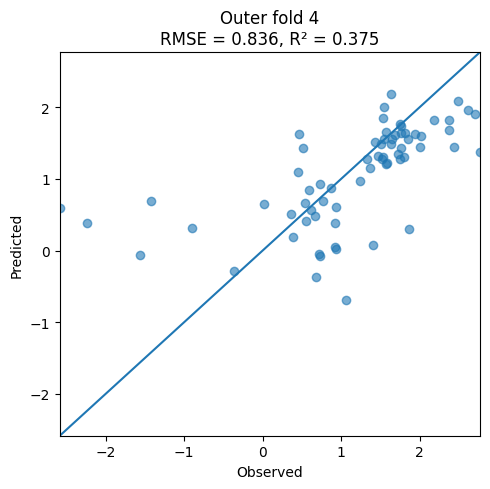

[I 2026-10-24 05:40:52,172] A new study created in memory with name: no-name-7685c380-cdfc-446d-98b2-3552c1d2705b


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_04_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_04_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:40:53,794] Trial 0 finished with value: 0.9719221745674491 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9719221745674491.
[I 2026-10-24 05:40:55,814] Trial 1 finished with value: 1.0268391762159665 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9719221745674491.
[I 2026-10-24 05:40:56,440] Trial 2 finished with value: 0.9645740229452119 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9645740229452119.
[I 2026-10-24 05:40:57,159] Trial 3 finished with value: 0.9620313126622764 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8290 R2 = 0.3072


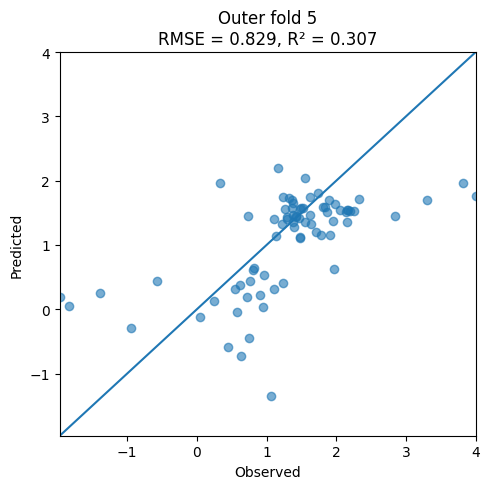

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_04_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_04_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8981 (+/- 0.0938)
Mean R2 (Outer CV): 0.3680 (+/- 0.0434)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 5]


[I 2026-10-24 05:42:46,313] A new study created in memory with name: no-name-a3acb4b0-e7f5-4c1f-8d29-233f1919bf35


Resuming from existing file. Found 744 previous runs.
Running rs=786, targetTW=5
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:42:47,190] Trial 0 finished with value: 0.9321076418114093 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9321076418114093.
[I 2026-10-24 05:42:48,241] Trial 1 finished with value: 0.9999347556254314 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9321076418114093.
[I 2026-10-24 05:42:49,773] Trial 2 finished with value: 1.0158021391832501 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9321076418114093.
[I 2026-10-24 05:42:52,267] Trial 3 finished with value: 0.9411321657281666 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0394 R2 = 0.3522


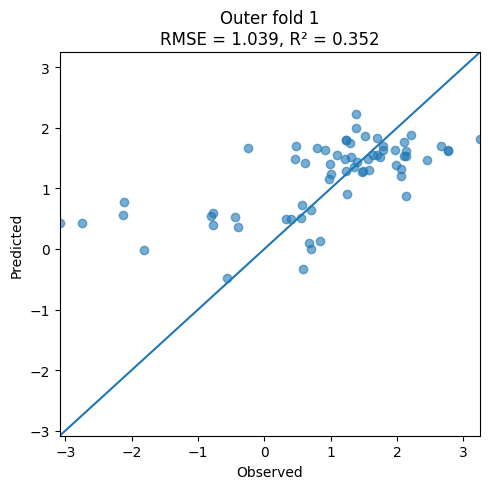

[I 2026-10-24 05:44:26,901] A new study created in memory with name: no-name-fffd7da8-fefe-41dc-bfc6-d5e5c75b49f4


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_05_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_05_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:44:28,155] Trial 0 finished with value: 0.9939480419630395 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9939480419630395.
[I 2026-10-24 05:44:28,933] Trial 1 finished with value: 1.0534912185157141 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9939480419630395.
[I 2026-10-24 05:44:29,398] Trial 2 finished with value: 1.0681561461975821 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9939480419630395.
[I 2026-10-24 05:44:30,021] Trial 3 finished with value: 1.0443958132146447 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8205 R2 = 0.3405


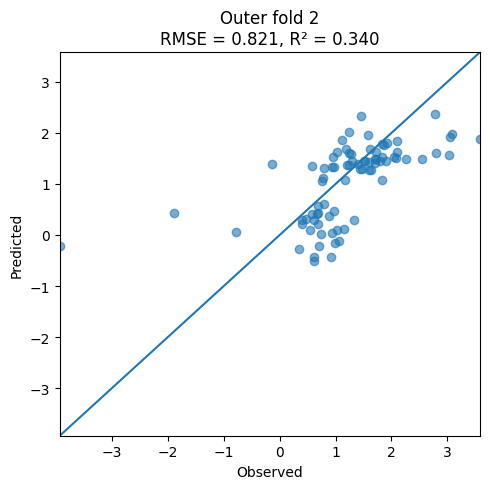

[I 2026-10-24 05:46:04,470] A new study created in memory with name: no-name-0be1ab57-ff71-408d-9028-945a05bb02fa


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_05_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_05_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:46:05,785] Trial 0 finished with value: 0.9449979942798685 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9449979942798685.
[I 2026-10-24 05:46:06,588] Trial 1 finished with value: 0.9735655028147302 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9449979942798685.
[I 2026-10-24 05:46:07,141] Trial 2 finished with value: 0.9864724229017133 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9449979942798685.
[I 2026-10-24 05:46:07,809] Trial 3 finished with value: 0.9287605054548568 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0382 R2 = 0.3738


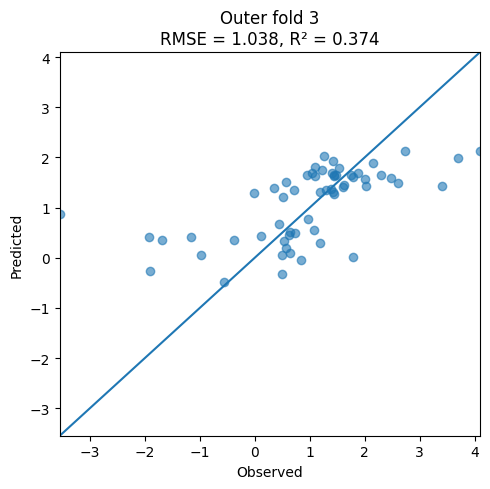

[I 2026-10-24 05:47:52,761] A new study created in memory with name: no-name-4bdcc1fd-68ea-4da1-8cd3-65bc47372605


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_05_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_05_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:47:54,230] Trial 0 finished with value: 0.9962595780446533 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9962595780446533.
[I 2026-10-24 05:47:57,805] Trial 1 finished with value: 1.1202575720182577 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9962595780446533.
[I 2026-10-24 05:47:58,634] Trial 2 finished with value: 1.0395433518424126 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9962595780446533.
[I 2026-10-24 05:47:59,299] Trial 3 finished with value: 0.9887264907374731 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7499 R2 = 0.4966


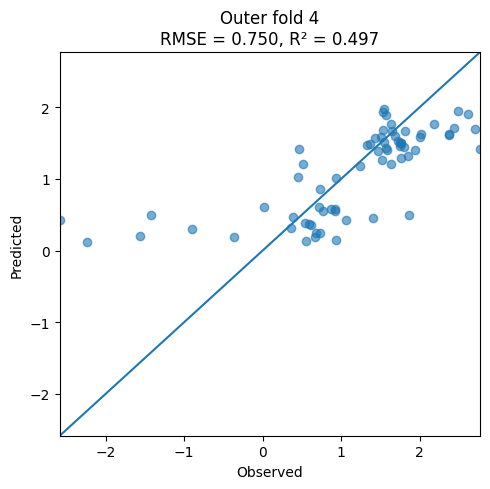

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_05_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_05_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:49:44,800] A new study created in memory with name: no-name-f4e9a99b-9c5f-4043-976d-6ecf9a818df5
[I 2026-10-24 05:49:46,055] Trial 0 finished with value: 0.9645742164443907 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9645742164443907.
[I 2026-10-24 05:49:46,856] Trial 1 finished with value: 1.029841329832268 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9645742164443907.
[I 2026-10-24 05:49:47,468] Trial 2 finished with value: 1.0254299948522396 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.964574216

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.9134 R2 = 0.1590


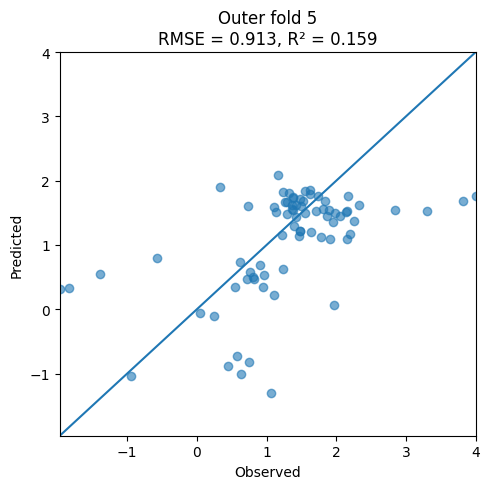

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_05_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_05_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9123 (+/- 0.1156)
Mean R2 (Outer CV): 0.3444 (+/- 0.1082)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 6]


[I 2026-10-24 05:51:40,561] A new study created in memory with name: no-name-ad89e0b5-b7f6-4ceb-a0d7-f5cb194f276e


Resuming from existing file. Found 750 previous runs.
Running rs=786, targetTW=6
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:51:41,431] Trial 0 finished with value: 0.8898047608413385 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8898047608413385.
[I 2026-10-24 05:51:42,182] Trial 1 finished with value: 0.9415950418000378 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8898047608413385.
[I 2026-10-24 05:51:42,761] Trial 2 finished with value: 0.953480076034434 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8898047608413385.
[I 2026-10-24 05:51:43,403] Trial 3 finished with value: 0.9229512358294687 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0298 R2 = 0.3641


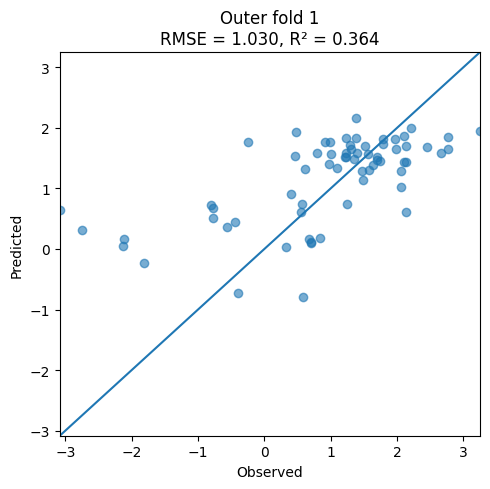

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_06_outerfold_01.json


[I 2026-10-24 05:53:08,948] A new study created in memory with name: no-name-50838dd1-b53a-4ccf-80b1-4091ef5abd80


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_06_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:53:10,516] Trial 0 finished with value: 0.9614747709347797 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9614747709347797.
[I 2026-10-24 05:53:11,357] Trial 1 finished with value: 1.0300232884672762 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9614747709347797.
[I 2026-10-24 05:53:11,959] Trial 2 finished with value: 1.0840660849676218 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9614747709347797.
[I 2026-10-24 05:53:12,633] Trial 3 finished with value: 0.9839577945868753 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8064 R2 = 0.3630


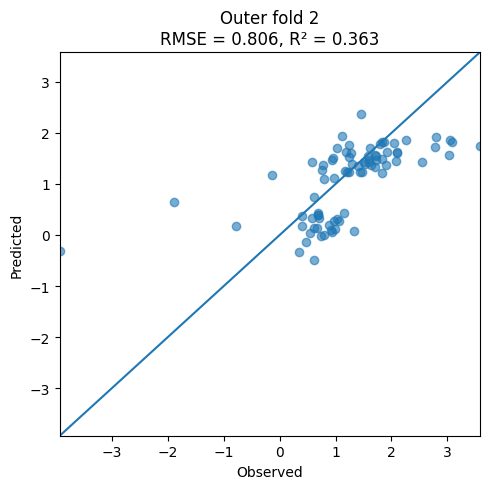

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_06_outerfold_02.json


[I 2026-10-24 05:54:54,169] A new study created in memory with name: no-name-bac4ccc7-f5e7-4e95-a376-c3f8a9f0a8a7


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_06_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:54:55,689] Trial 0 finished with value: 0.9263878469853969 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9263878469853969.
[I 2026-10-24 05:54:56,515] Trial 1 finished with value: 0.94459601770012 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9263878469853969.
[I 2026-10-24 05:54:58,524] Trial 2 finished with value: 0.9925613242317282 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9263878469853969.
[I 2026-10-24 05:55:00,636] Trial 3 finished with value: 0.9473885052605098 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0340 R2 = 0.3789


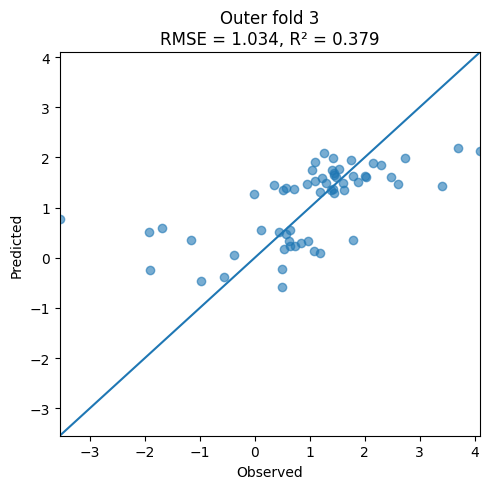

[I 2026-10-24 05:56:55,483] A new study created in memory with name: no-name-04a6d9f0-76a6-4d3e-b57b-037fec240a42


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_06_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_06_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:56:57,877] Trial 0 finished with value: 0.9896406851066183 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9896406851066183.
[I 2026-10-24 05:56:58,614] Trial 1 finished with value: 1.0806814133359366 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9896406851066183.
[I 2026-10-24 05:56:59,230] Trial 2 finished with value: 0.9893906637665268 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9893906637665268.
[I 2026-10-24 05:56:59,876] Trial 3 finished with value: 0.9812465820476232 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7914 R2 = 0.4394


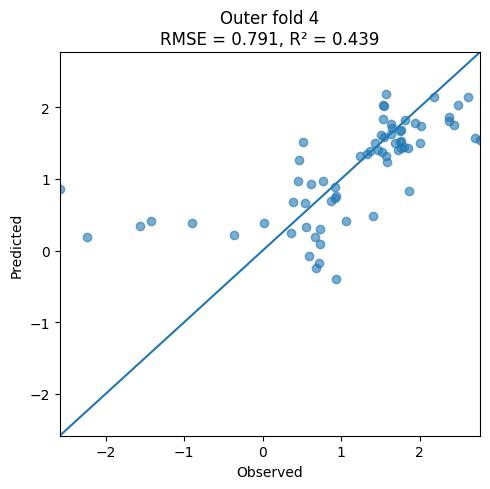

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_06_outerfold_04.json


[I 2026-10-24 05:58:42,370] A new study created in memory with name: no-name-08008a7d-5699-4b9e-8bc9-37d9c60fcb3b


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_06_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 05:58:43,946] Trial 0 finished with value: 0.9717179938904899 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9717179938904899.
[I 2026-10-24 05:58:44,683] Trial 1 finished with value: 1.0371262911849584 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9717179938904899.
[I 2026-10-24 05:58:45,297] Trial 2 finished with value: 1.0325201952368435 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9717179938904899.
[I 2026-10-24 05:58:45,983] Trial 3 finished with value: 0.9611713615968982 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.9212 R2 = 0.1445


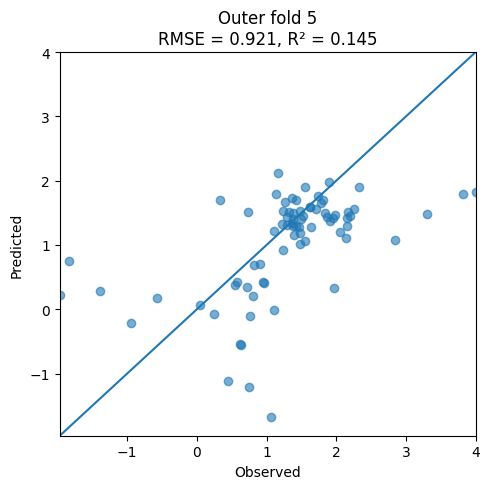

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_06_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_06_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9166 (+/- 0.1043)
Mean R2 (Outer CV): 0.3380 (+/- 0.1007)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 7]


[I 2026-10-24 06:00:42,554] A new study created in memory with name: no-name-6160c630-0cff-4cb0-aad5-eb648691cf3d


Resuming from existing file. Found 756 previous runs.
Running rs=786, targetTW=7
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:00:43,438] Trial 0 finished with value: 0.9093096450724807 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9093096450724807.
[I 2026-10-24 06:00:44,283] Trial 1 finished with value: 0.9412700945168635 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9093096450724807.
[I 2026-10-24 06:00:44,976] Trial 2 finished with value: 0.9823995471935426 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9093096450724807.
[I 2026-10-24 06:00:46,932] Trial 3 finished with value: 0.9258868071624948 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0497 R2 = 0.3393


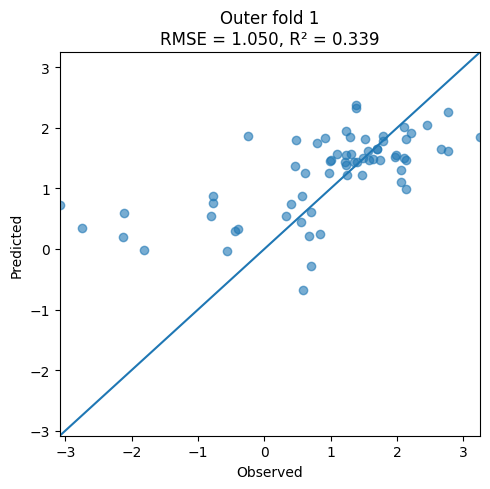

[I 2026-10-24 06:02:25,868] A new study created in memory with name: no-name-bfb410c6-a034-46f0-bd24-f4a99771a2b1


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_07_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_07_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:02:28,648] Trial 0 finished with value: 0.9775589745473159 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9775589745473159.
[I 2026-10-24 06:02:31,011] Trial 1 finished with value: 1.0752454889971343 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9775589745473159.
[I 2026-10-24 06:02:31,598] Trial 2 finished with value: 1.0051193666407867 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9775589745473159.
[I 2026-10-24 06:02:32,316] Trial 3 finished with value: 1.0135614363831678 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8063 R2 = 0.3631


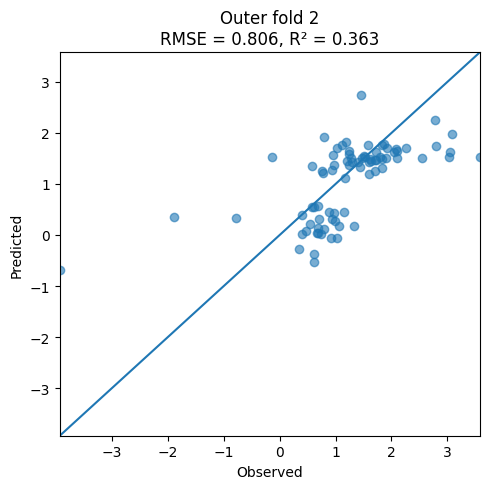

[I 2026-10-24 06:04:31,338] A new study created in memory with name: no-name-5382b2e7-f9ef-4cef-9af9-292671f5fb2a


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_07_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_07_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:04:32,666] Trial 0 finished with value: 0.9631591555208556 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9631591555208556.
[I 2026-10-24 06:04:33,419] Trial 1 finished with value: 0.9790844101179269 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9631591555208556.
[I 2026-10-24 06:04:34,007] Trial 2 finished with value: 0.9770491242952033 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9631591555208556.
[I 2026-10-24 06:04:34,707] Trial 3 finished with value: 0.949907041023314 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0359 R2 = 0.3766


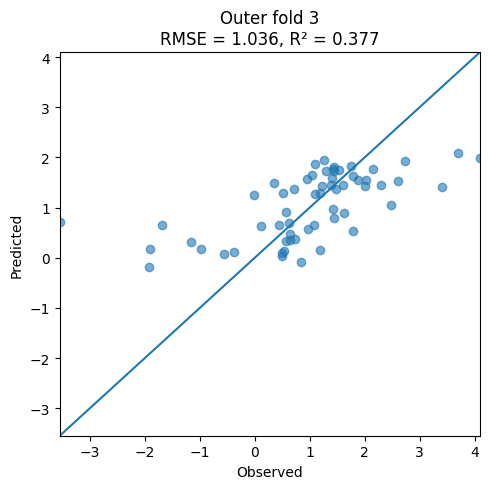

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_07_outerfold_03.json


[I 2026-10-24 06:06:17,330] A new study created in memory with name: no-name-3142346f-cca1-469c-a3f3-b3e37c014bf8


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_07_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:06:18,954] Trial 0 finished with value: 0.9400090516188419 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9400090516188419.
[I 2026-10-24 06:06:19,734] Trial 1 finished with value: 1.0869746135819724 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9400090516188419.
[I 2026-10-24 06:06:20,523] Trial 2 finished with value: 1.0362922976822175 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9400090516188419.
[I 2026-10-24 06:06:22,463] Trial 3 finished with value: 0.9975295621198217 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7288 R2 = 0.5245


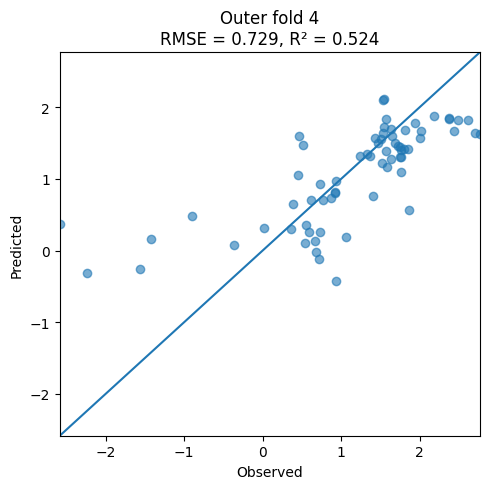

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_07_outerfold_04.json


[I 2026-10-24 06:07:58,166] A new study created in memory with name: no-name-b50eb0bf-5ac7-45ee-b310-20c78dbcb168


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_07_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:07:59,698] Trial 0 finished with value: 0.9609253348937282 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9609253348937282.
[I 2026-10-24 06:08:00,529] Trial 1 finished with value: 1.0320063763583336 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9609253348937282.
[I 2026-10-24 06:08:01,160] Trial 2 finished with value: 1.070821046562889 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9609253348937282.
[I 2026-10-24 06:08:01,941] Trial 3 finished with value: 0.9713624944988092 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8867 R2 = 0.2075


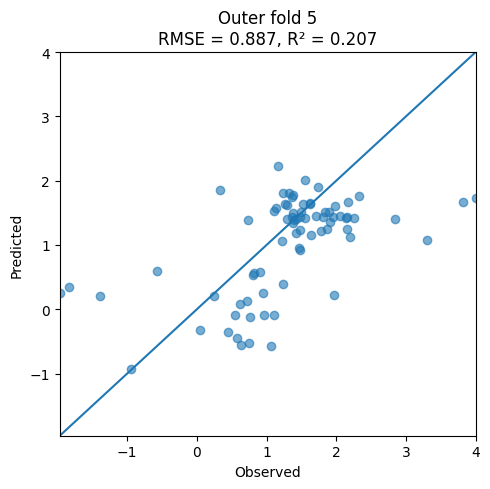

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_07_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_07_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9015 (+/- 0.1258)
Mean R2 (Outer CV): 0.3622 (+/- 0.1010)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 8]


[I 2026-10-24 06:10:15,629] A new study created in memory with name: no-name-8478084d-6722-4bab-9fe2-7beed6e81d54


Resuming from existing file. Found 762 previous runs.
Running rs=786, targetTW=8
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:10:18,367] Trial 0 finished with value: 0.9091412905975289 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9091412905975289.
[I 2026-10-24 06:10:19,122] Trial 1 finished with value: 0.8989690832407773 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.8989690832407773.
[I 2026-10-24 06:10:19,754] Trial 2 finished with value: 0.9575887288823606 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.8989690832407773.
[I 2026-10-24 06:10:20,445] Trial 3 finished with value: 0.9065324884886927 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0306 R2 = 0.3631


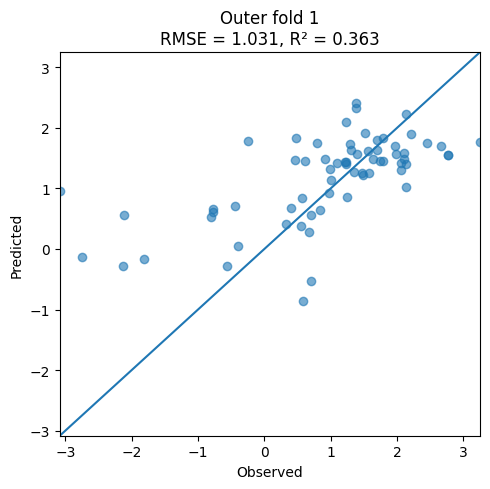

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_08_outerfold_01.json


[I 2026-10-24 06:12:08,030] A new study created in memory with name: no-name-205d7fff-26fe-4ead-9925-4fe04c7eda57


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_08_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:12:09,662] Trial 0 finished with value: 0.9886914222748612 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9886914222748612.
[I 2026-10-24 06:12:10,373] Trial 1 finished with value: 1.0437705503833759 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9886914222748612.
[I 2026-10-24 06:12:11,017] Trial 2 finished with value: 0.9986795598171296 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9886914222748612.
[I 2026-10-24 06:12:12,934] Trial 3 finished with value: 0.9787153345793719 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8161 R2 = 0.3475


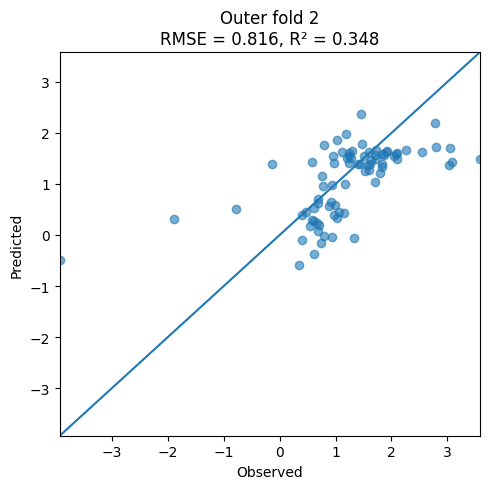

[I 2026-10-24 06:13:45,222] A new study created in memory with name: no-name-705e9f30-47be-4381-b16c-50779a5e3a2a


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_08_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_08_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:13:46,495] Trial 0 finished with value: 0.9179839183842073 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9179839183842073.
[I 2026-10-24 06:13:47,282] Trial 1 finished with value: 0.9673987395756344 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9179839183842073.
[I 2026-10-24 06:13:47,823] Trial 2 finished with value: 0.9791023308937989 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9179839183842073.
[I 2026-10-24 06:13:48,518] Trial 3 finished with value: 0.9208199654529812 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.1066 R2 = 0.2886


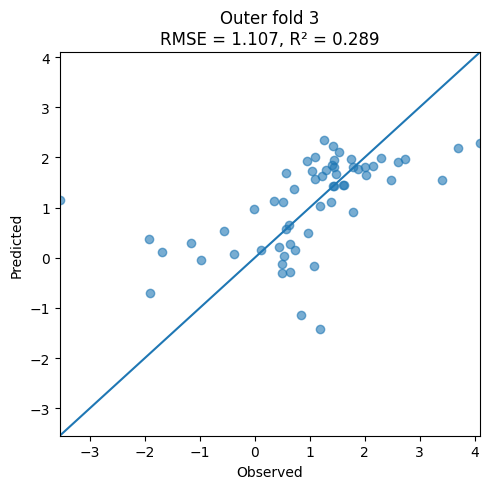

[I 2026-10-24 06:15:27,477] A new study created in memory with name: no-name-b6005f89-81e0-4b83-a8e7-a4d2f4d6a18e


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_08_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_08_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:15:28,721] Trial 0 finished with value: 1.012849218015003 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.012849218015003.
[I 2026-10-24 06:15:29,515] Trial 1 finished with value: 1.0359393298291195 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.012849218015003.
[I 2026-10-24 06:15:30,177] Trial 2 finished with value: 1.0120021043630794 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 1.0120021043630794.
[I 2026-10-24 06:15:30,831] Trial 3 finished with value: 0.9942303376556498 and parameters: {'max_depth': 3

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7571 R2 = 0.4868


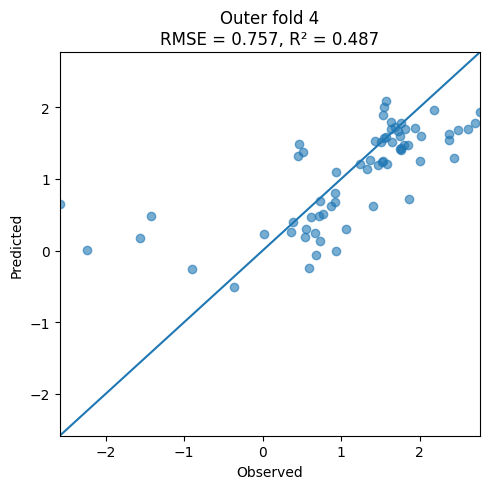

[I 2026-10-24 06:16:58,923] A new study created in memory with name: no-name-4e178c63-d106-4bd1-b7c9-817bcc81738f


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_08_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_08_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:17:00,303] Trial 0 finished with value: 0.9736379893231737 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9736379893231737.
[I 2026-10-24 06:17:01,094] Trial 1 finished with value: 1.0133160852032348 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9736379893231737.
[I 2026-10-24 06:17:01,623] Trial 2 finished with value: 1.038474277525041 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9736379893231737.
[I 2026-10-24 06:17:02,284] Trial 3 finished with value: 0.9808071403962135 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.9003 R2 = 0.1828


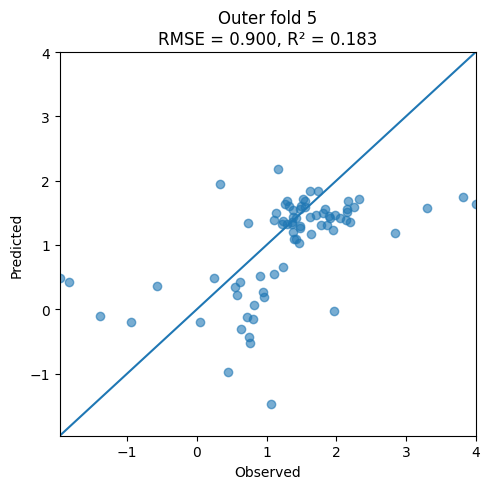

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_08_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_08_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9222 (+/- 0.1302)
Mean R2 (Outer CV): 0.3338 (+/- 0.0993)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 9]


[I 2026-10-24 06:18:57,371] A new study created in memory with name: no-name-0fa16941-2ddc-40df-a7a4-287209d51074


Resuming from existing file. Found 768 previous runs.
Running rs=786, targetTW=9
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:18:58,241] Trial 0 finished with value: 0.899233956376928 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.899233956376928.
[I 2026-10-24 06:18:58,937] Trial 1 finished with value: 0.9241678890876662 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.899233956376928.
[I 2026-10-24 06:18:59,511] Trial 2 finished with value: 0.9598764153954132 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.899233956376928.
[I 2026-10-24 06:19:00,216] Trial 3 finished with value: 0.8739984405996195 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0278 R2 = 0.3666


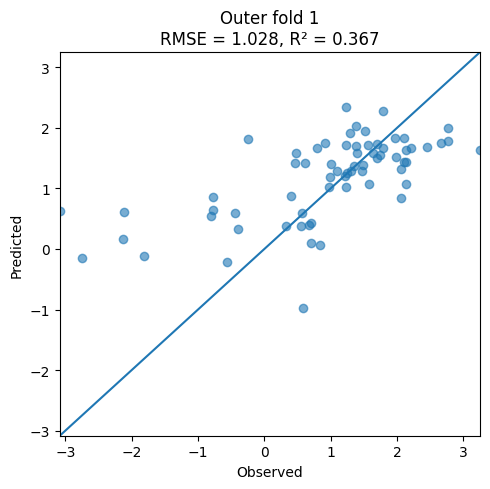

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_09_outerfold_01.json


[I 2026-10-24 06:20:38,562] A new study created in memory with name: no-name-db3a1b21-298c-4a81-8700-ffeefda58776


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_09_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:20:40,074] Trial 0 finished with value: 0.9904564130747993 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9904564130747993.
[I 2026-10-24 06:20:40,891] Trial 1 finished with value: 1.0414040087731156 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9904564130747993.
[I 2026-10-24 06:20:41,468] Trial 2 finished with value: 1.046265761696276 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9904564130747993.
[I 2026-10-24 06:20:42,173] Trial 3 finished with value: 1.006083607002499 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.7862 R2 = 0.3945


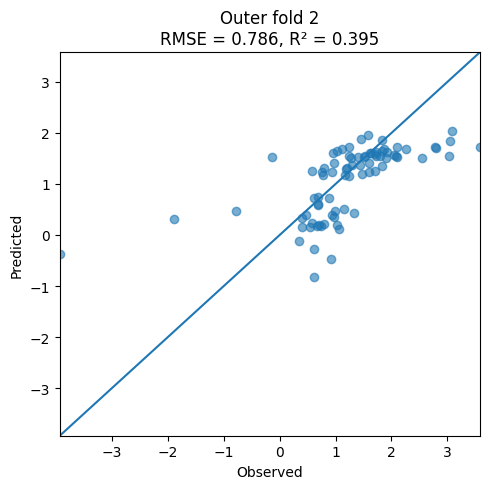

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_09_outerfold_02.json


[I 2026-10-24 06:22:26,199] A new study created in memory with name: no-name-471c0d13-2226-4cc8-83bf-1a93ec5c8c92


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_09_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:22:27,533] Trial 0 finished with value: 0.9278358120024423 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9278358120024423.
[I 2026-10-24 06:22:31,719] Trial 1 finished with value: 0.9612235598720832 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9278358120024423.
[I 2026-10-24 06:22:32,341] Trial 2 finished with value: 0.9598124782083545 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9278358120024423.
[I 2026-10-24 06:22:33,041] Trial 3 finished with value: 0.9123116296989119 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0259 R2 = 0.3886


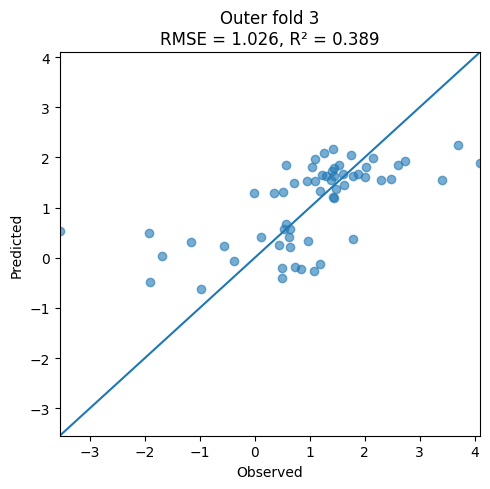

[I 2026-10-24 06:24:08,454] A new study created in memory with name: no-name-a67cf8df-dd44-4c33-862a-6d642347cb0b


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_09_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_09_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:24:09,648] Trial 0 finished with value: 1.0020422336087633 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 1.0020422336087633.
[I 2026-10-24 06:24:13,086] Trial 1 finished with value: 1.0358635808398453 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 1.0020422336087633.
[I 2026-10-24 06:24:14,496] Trial 2 finished with value: 1.0231047927553505 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 1.0020422336087633.
[I 2026-10-24 06:24:15,216] Trial 3 finished with value: 0.9578440636912244 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7844 R2 = 0.4492


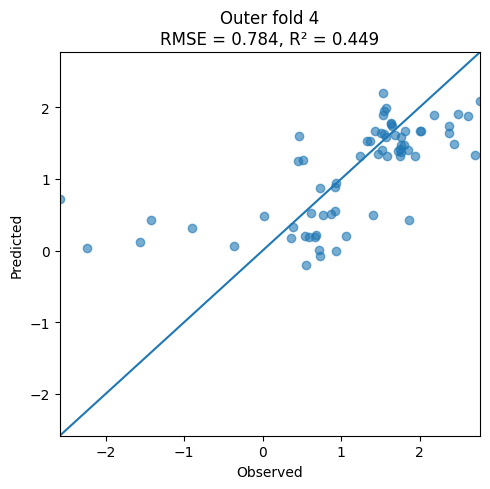

[I 2026-10-24 06:25:47,802] A new study created in memory with name: no-name-f7794d87-ec3d-4d9e-835b-8f47f457d8fb


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_09_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_09_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:25:49,147] Trial 0 finished with value: 0.9731655439824992 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9731655439824992.
[I 2026-10-24 06:25:49,901] Trial 1 finished with value: 1.0121619307408427 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9731655439824992.
[I 2026-10-24 06:25:50,484] Trial 2 finished with value: 1.0211865119271915 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9731655439824992.
[I 2026-10-24 06:25:51,239] Trial 3 finished with value: 1.005992832591133 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8475 R2 = 0.2758


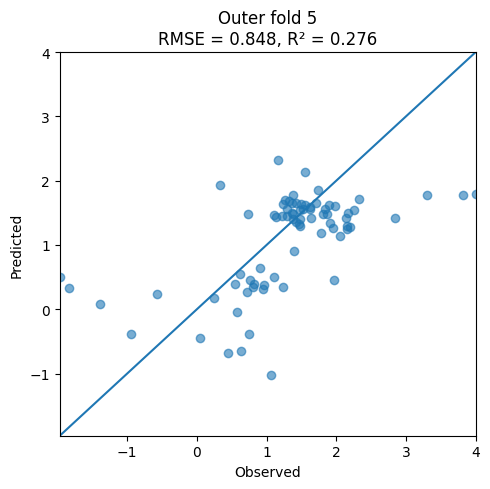

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_09_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_09_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8944 (+/- 0.1105)
Mean R2 (Outer CV): 0.3749 (+/- 0.0565)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 10]


[I 2026-10-24 06:27:53,742] A new study created in memory with name: no-name-5cb63163-1f9f-41e8-9dde-1a664eec2d31


Resuming from existing file. Found 774 previous runs.
Running rs=786, targetTW=10
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:27:54,711] Trial 0 finished with value: 0.9059839941411927 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9059839941411927.
[I 2026-10-24 06:27:55,459] Trial 1 finished with value: 0.9023670106189641 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9023670106189641.
[I 2026-10-24 06:27:56,097] Trial 2 finished with value: 0.9463743643829925 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9023670106189641.
[I 2026-10-24 06:27:56,859] Trial 3 finished with value: 0.8841271771120112 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0643 R2 = 0.3208


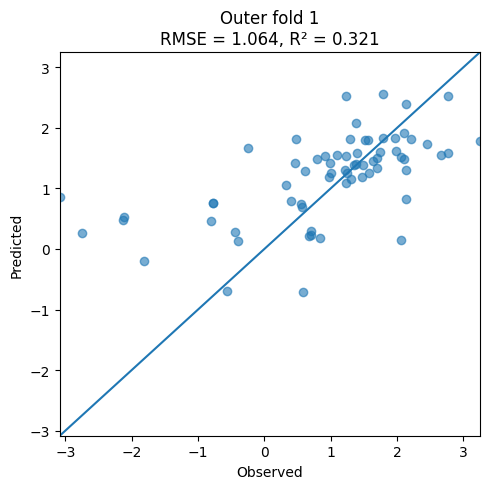

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_10_outerfold_01.json


[I 2026-10-24 06:29:36,923] A new study created in memory with name: no-name-4f2240bd-8db5-432d-8709-6bdafb7ce4e7


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_10_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:29:38,662] Trial 0 finished with value: 0.9710244116796074 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9710244116796074.
[I 2026-10-24 06:29:39,458] Trial 1 finished with value: 1.049151002028755 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9710244116796074.
[I 2026-10-24 06:29:39,954] Trial 2 finished with value: 1.018027518823834 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9710244116796074.
[I 2026-10-24 06:29:40,687] Trial 3 finished with value: 0.978432013589063 and parameters: {'max_depth': 3

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8552 R2 = 0.2835


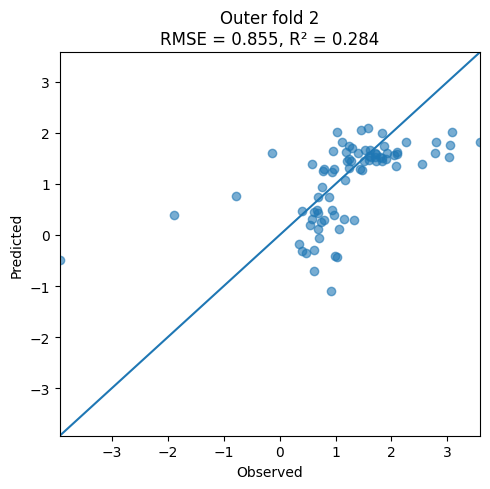

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_10_outerfold_02.json


[I 2026-10-24 06:31:21,983] A new study created in memory with name: no-name-7243d5c0-04c7-4731-a1a9-d81109c506e4


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_10_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:31:23,682] Trial 0 finished with value: 0.9235015481516501 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9235015481516501.
[I 2026-10-24 06:31:24,503] Trial 1 finished with value: 0.9649277059138829 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9235015481516501.
[I 2026-10-24 06:31:25,143] Trial 2 finished with value: 0.9847348619031377 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9235015481516501.
[I 2026-10-24 06:31:25,867] Trial 3 finished with value: 0.935619199737661 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0561 R2 = 0.3520


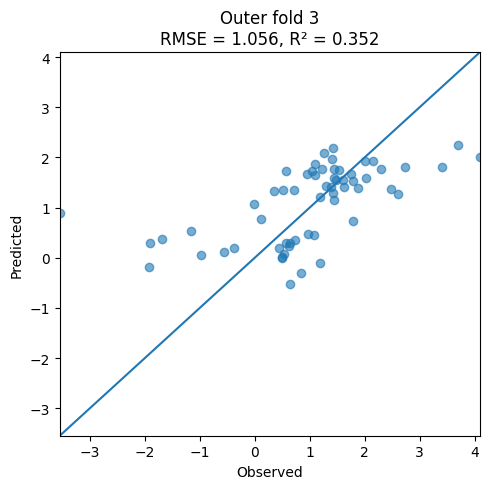

[I 2026-10-24 06:33:16,415] A new study created in memory with name: no-name-86cf49aa-90af-4dce-b1f5-f355b2ff9243


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_10_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_10_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:33:17,784] Trial 0 finished with value: 0.9330613555995051 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9330613555995051.
[I 2026-10-24 06:33:18,612] Trial 1 finished with value: 1.0064397963385407 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9330613555995051.
[I 2026-10-24 06:33:19,203] Trial 2 finished with value: 0.9872632782260589 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9330613555995051.
[I 2026-10-24 06:33:19,922] Trial 3 finished with value: 0.950263869900823 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8577 R2 = 0.3415


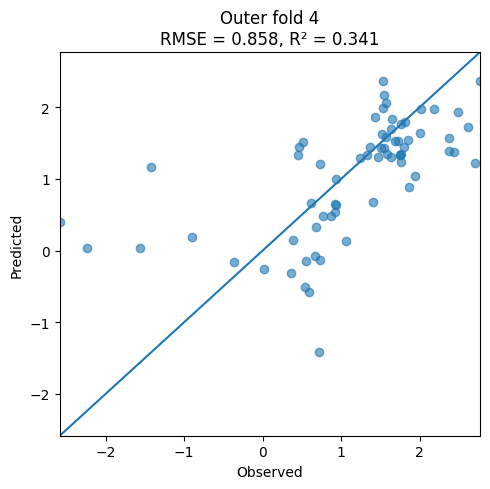

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_10_outerfold_04.json


[I 2026-10-24 06:35:00,557] A new study created in memory with name: no-name-ec541296-75dd-428a-b686-6eb175c9f84c


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_10_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:35:02,220] Trial 0 finished with value: 0.9231560438682106 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9231560438682106.
[I 2026-10-24 06:35:02,996] Trial 1 finished with value: 0.9920388551810002 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9231560438682106.
[I 2026-10-24 06:35:03,723] Trial 2 finished with value: 0.9924828633288594 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9231560438682106.
[I 2026-10-24 06:35:04,405] Trial 3 finished with value: 0.9629441812562044 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8319 R2 = 0.3024


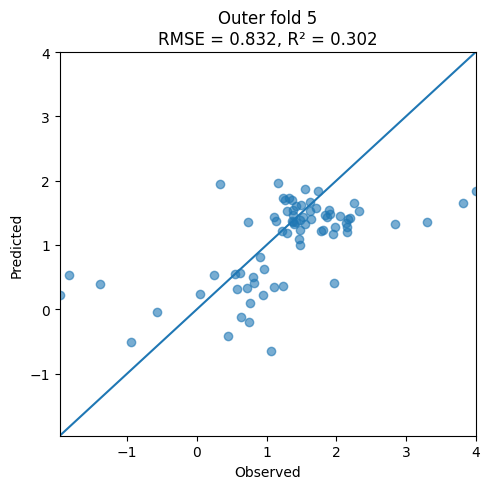

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_10_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_10_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9330 (+/- 0.1043)
Mean R2 (Outer CV): 0.3200 (+/- 0.0250)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 11]


[I 2026-10-24 06:37:32,456] A new study created in memory with name: no-name-cb342e36-2ec8-493e-bba3-a562fb694246


Resuming from existing file. Found 780 previous runs.
Running rs=786, targetTW=11
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:37:33,575] Trial 0 finished with value: 0.8962105889463169 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8962105889463169.
[I 2026-10-24 06:37:35,862] Trial 1 finished with value: 0.8883247758054573 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.8883247758054573.
[I 2026-10-24 06:37:36,503] Trial 2 finished with value: 0.8960316308280611 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.8883247758054573.
[I 2026-10-24 06:37:37,200] Trial 3 finished with value: 0.8746430241913422 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0336 R2 = 0.3594


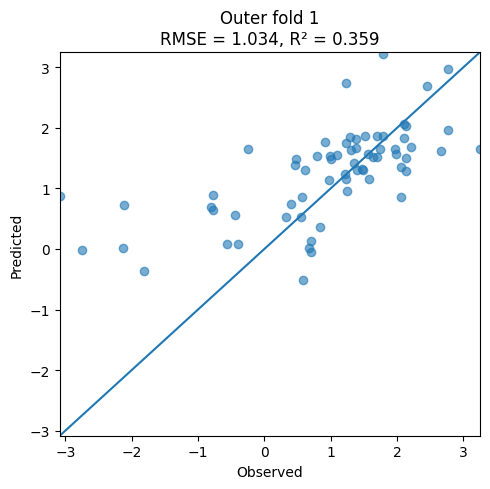

[I 2026-10-24 06:39:27,167] A new study created in memory with name: no-name-77a269c7-fabe-441d-acad-9a4abcb6383a


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_11_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_11_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:39:31,212] Trial 0 finished with value: 0.9637241365797993 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9637241365797993.
[I 2026-10-24 06:39:32,454] Trial 1 finished with value: 1.022978891220621 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9637241365797993.
[I 2026-10-24 06:39:33,059] Trial 2 finished with value: 1.0354671038769168 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9637241365797993.
[I 2026-10-24 06:39:33,757] Trial 3 finished with value: 0.9743711100369339 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.7919 R2 = 0.3856


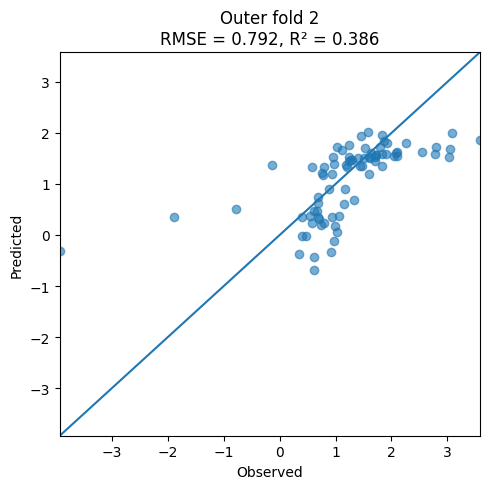

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_11_outerfold_02.json


[I 2026-10-24 06:41:32,142] A new study created in memory with name: no-name-4d50fc5a-3cef-4509-8d5a-2780087418f7


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_11_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:41:33,933] Trial 0 finished with value: 0.9600177785344833 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9600177785344833.
[I 2026-10-24 06:41:34,735] Trial 1 finished with value: 1.0089714943655195 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9600177785344833.
[I 2026-10-24 06:41:35,340] Trial 2 finished with value: 0.9731903132828313 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9600177785344833.
[I 2026-10-24 06:41:36,091] Trial 3 finished with value: 0.9404501188695157 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0798 R2 = 0.3226


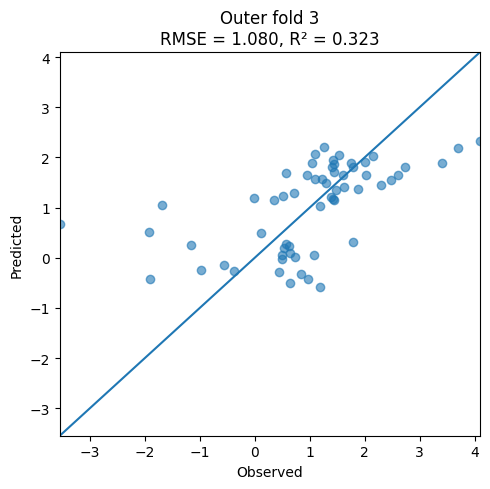

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_11_outerfold_03.json


[I 2026-10-24 06:43:28,973] A new study created in memory with name: no-name-74e2de81-4022-49be-8a07-d22f7bc4bcb4


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_11_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:43:30,782] Trial 0 finished with value: 0.9675661169946547 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9675661169946547.
[I 2026-10-24 06:43:31,559] Trial 1 finished with value: 1.0280712081006176 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9675661169946547.
[I 2026-10-24 06:43:32,177] Trial 2 finished with value: 1.0005621731823313 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9675661169946547.
[I 2026-10-24 06:43:32,829] Trial 3 finished with value: 0.9453616460039593 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7534 R2 = 0.4919


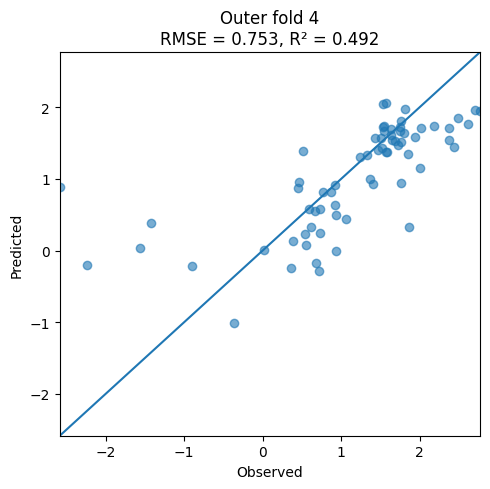

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_11_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_11_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:45:12,176] A new study created in memory with name: no-name-c1ea5810-459b-40d5-a1e7-00fdf786f24d
[I 2026-10-24 06:45:13,566] Trial 0 finished with value: 0.9531060546412867 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9531060546412867.
[I 2026-10-24 06:45:14,391] Trial 1 finished with value: 1.002101056605936 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9531060546412867.
[I 2026-10-24 06:45:15,038] Trial 2 finished with value: 0.995086765744053 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9531060546

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8646 R2 = 0.2464


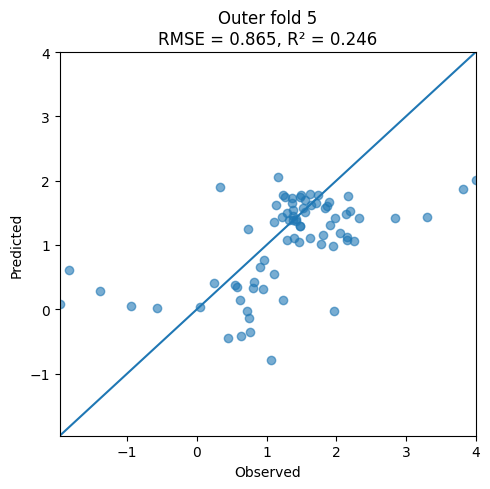

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_11_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_11_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9047 (+/- 0.1300)
Mean R2 (Outer CV): 0.3612 (+/- 0.0804)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 12]


[I 2026-10-24 06:47:05,913] A new study created in memory with name: no-name-d7989545-742c-4e29-bdf6-19f3e7da0233


Resuming from existing file. Found 786 previous runs.
Running rs=786, targetTW=12
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:47:06,841] Trial 0 finished with value: 0.8992586108680001 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8992586108680001.
[I 2026-10-24 06:47:07,657] Trial 1 finished with value: 0.883906275416829 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.883906275416829.
[I 2026-10-24 06:47:08,246] Trial 2 finished with value: 0.8957111771158928 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.883906275416829.
[I 2026-10-24 06:47:08,966] Trial 3 finished with value: 0.8849275890395791 and parameters: {'max_depth': 3

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0088 R2 = 0.3898


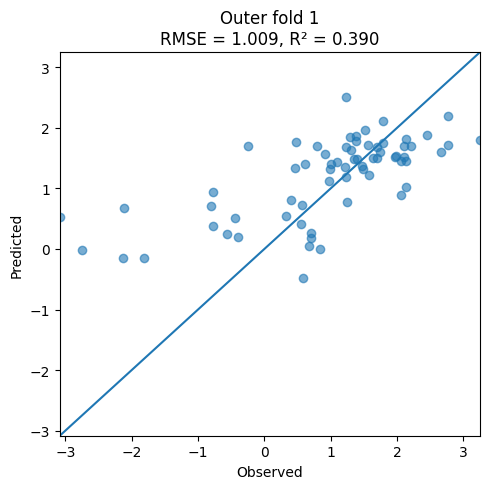

[I 2026-10-24 06:49:03,575] A new study created in memory with name: no-name-b9a98085-7ab2-4b3d-9565-a32488af950a


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_12_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_12_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:49:05,008] Trial 0 finished with value: 0.9890094330972599 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9890094330972599.
[I 2026-10-24 06:49:05,880] Trial 1 finished with value: 0.9801412499838005 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9801412499838005.
[I 2026-10-24 06:49:06,439] Trial 2 finished with value: 1.0228873026903726 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9801412499838005.
[I 2026-10-24 06:49:07,171] Trial 3 finished with value: 0.9807600747911756 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8011 R2 = 0.3713


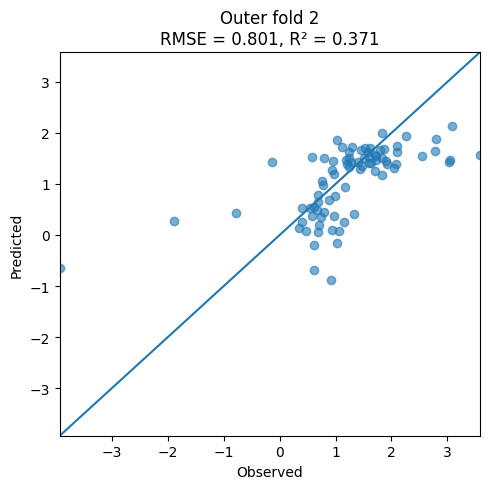

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_12_outerfold_02.json


[I 2026-10-24 06:50:51,711] A new study created in memory with name: no-name-c5eddbca-bf17-4c7c-8ae4-cfb3cc2e88d9


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_12_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:50:53,396] Trial 0 finished with value: 0.9350136523260026 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9350136523260026.
[I 2026-10-24 06:50:55,653] Trial 1 finished with value: 0.9758188208616994 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9350136523260026.
[I 2026-10-24 06:50:56,808] Trial 2 finished with value: 1.009855518050329 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9350136523260026.
[I 2026-10-24 06:50:58,722] Trial 3 finished with value: 0.9503469011588771 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0351 R2 = 0.3776


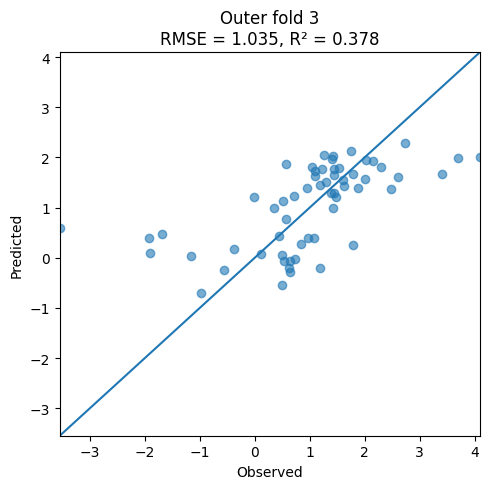

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_12_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_12_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']


[I 2026-10-24 06:52:58,909] A new study created in memory with name: no-name-8093da0c-0c7c-4606-bbae-91c725a2c19a


Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:53:00,645] Trial 0 finished with value: 0.983593997510991 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.983593997510991.
[I 2026-10-24 06:53:01,412] Trial 1 finished with value: 0.9981945881179064 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.983593997510991.
[I 2026-10-24 06:53:02,061] Trial 2 finished with value: 0.9705388027828142 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9705388027828142.
[I 2026-10-24 06:53:02,769] Trial 3 finished with value: 0.9439515867971331 and parameters: {'max_depth': 3

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7699 R2 = 0.4694


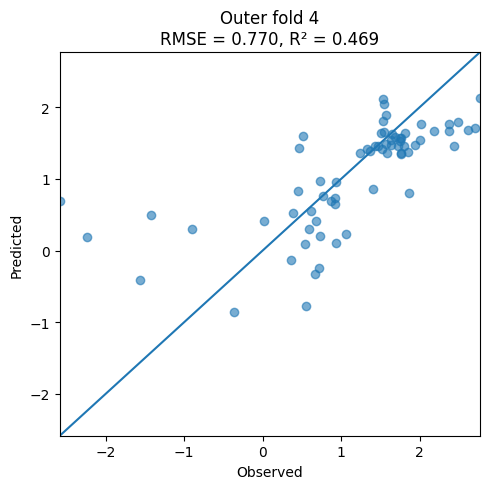

[I 2026-10-24 06:55:08,218] A new study created in memory with name: no-name-252dcc95-ca78-4fa4-998e-2dad9023a527


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_12_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_12_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:55:09,780] Trial 0 finished with value: 0.9318567921617348 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9318567921617348.
[I 2026-10-24 06:55:10,561] Trial 1 finished with value: 0.9491527681983534 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9318567921617348.
[I 2026-10-24 06:55:11,163] Trial 2 finished with value: 1.0010860180160153 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9318567921617348.
[I 2026-10-24 06:55:11,910] Trial 3 finished with value: 0.9216137440079523 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8572 R2 = 0.2592


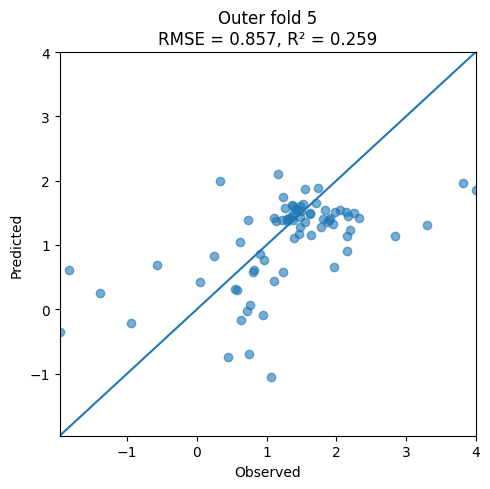

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_12_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_12_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8944 (+/- 0.1081)
Mean R2 (Outer CV): 0.3735 (+/- 0.0672)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 13]


[I 2026-10-24 06:57:19,170] A new study created in memory with name: no-name-55663eeb-a53e-4d48-b382-c33f8f127ff6


Resuming from existing file. Found 792 previous runs.
Running rs=786, targetTW=13
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:57:20,189] Trial 0 finished with value: 0.8803836293981573 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8803836293981573.
[I 2026-10-24 06:57:21,034] Trial 1 finished with value: 0.8775458883853843 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.8775458883853843.
[I 2026-10-24 06:57:21,705] Trial 2 finished with value: 0.9133841413776613 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.8775458883853843.
[I 2026-10-24 06:57:22,417] Trial 3 finished with value: 0.8654483014108479 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0333 R2 = 0.3598


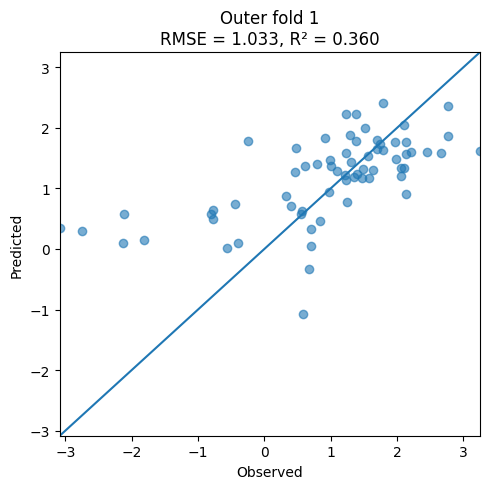

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_13_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_13_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 06:58:59,595] A new study created in memory with name: no-name-ee7038d5-6163-48a5-9873-1778a312bd8d
[I 2026-10-24 06:59:00,991] Trial 0 finished with value: 0.9548974020411936 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9548974020411936.
[I 2026-10-24 06:59:01,788] Trial 1 finished with value: 1.0129325732170869 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9548974020411936.
[I 2026-10-24 06:59:02,386] Trial 2 finished with value: 1.038555877351616 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.954897402

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8147 R2 = 0.3498


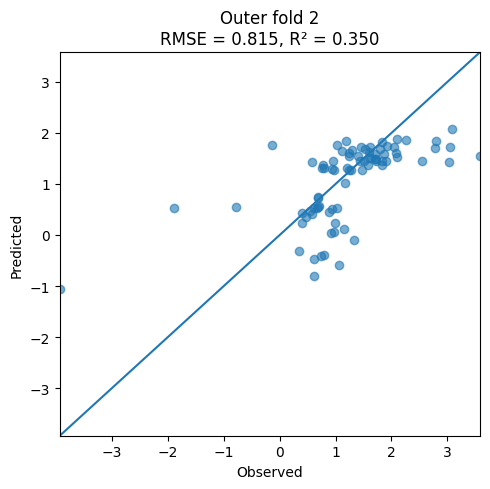

[I 2026-10-24 07:00:41,356] A new study created in memory with name: no-name-fe599549-3011-4a5b-ad84-c28c66529554


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_13_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_13_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:00:42,616] Trial 0 finished with value: 0.9465792642931798 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9465792642931798.
[I 2026-10-24 07:00:43,537] Trial 1 finished with value: 0.9395063904326888 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9395063904326888.
[I 2026-10-24 07:00:44,217] Trial 2 finished with value: 1.0106717708788673 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9395063904326888.
[I 2026-10-24 07:00:44,918] Trial 3 finished with value: 0.9539063318144522 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0338 R2 = 0.3791


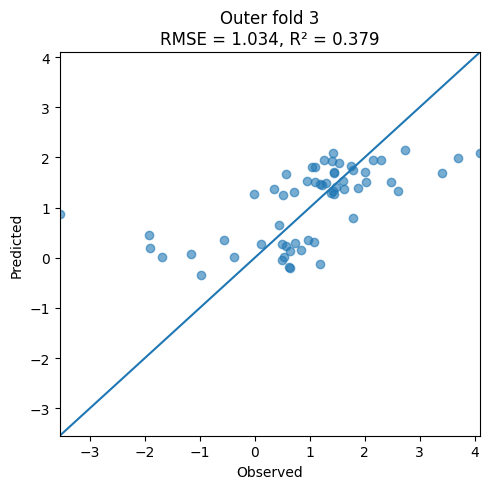

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_13_outerfold_03.json


[I 2026-10-24 07:02:31,773] A new study created in memory with name: no-name-660c85b7-618d-4154-83a5-63419775705c


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_13_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:02:33,378] Trial 0 finished with value: 0.9691214686899285 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9691214686899285.
[I 2026-10-24 07:02:35,814] Trial 1 finished with value: 0.9916657625040745 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9691214686899285.
[I 2026-10-24 07:02:38,126] Trial 2 finished with value: 0.9546751947685956 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9546751947685956.
[I 2026-10-24 07:02:38,881] Trial 3 finished with value: 0.9434833432240088 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7995 R2 = 0.4278


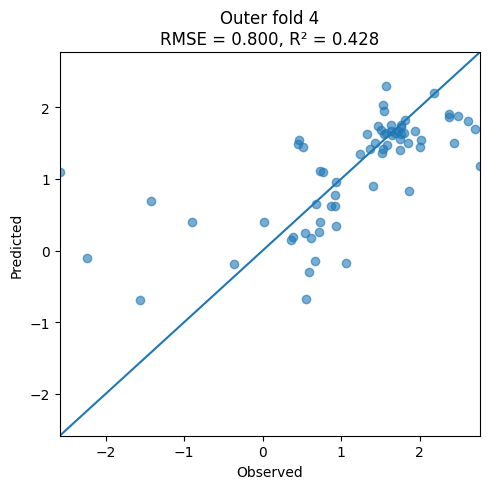

[I 2026-10-24 07:04:14,011] A new study created in memory with name: no-name-03bd1022-ac23-4d40-9d15-8ed48f8738bb


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_13_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_13_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:04:15,459] Trial 0 finished with value: 0.963335447874599 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.963335447874599.
[I 2026-10-24 07:04:16,250] Trial 1 finished with value: 0.9767505253113146 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.963335447874599.
[I 2026-10-24 07:04:18,223] Trial 2 finished with value: 0.9889330973406687 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.963335447874599.
[I 2026-10-24 07:04:20,589] Trial 3 finished with value: 0.9384494136223447 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.9012 R2 = 0.1813


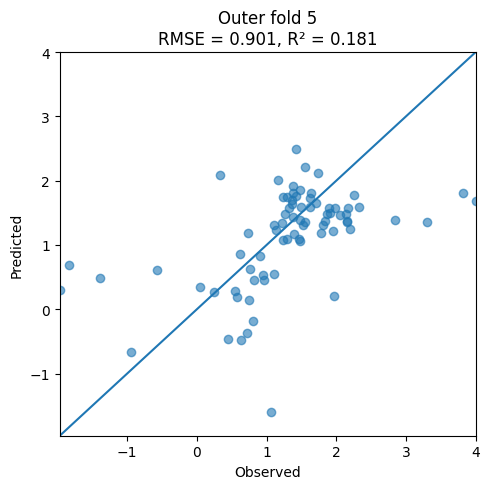

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_13_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_13_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9165 (+/- 0.1017)
Mean R2 (Outer CV): 0.3396 (+/- 0.0836)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 14]


[I 2026-10-24 07:06:15,232] A new study created in memory with name: no-name-7d4fea82-1577-43a1-b881-31b9b7981649


Resuming from existing file. Found 798 previous runs.
Running rs=786, targetTW=14
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:06:16,466] Trial 0 finished with value: 0.9116003144825048 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9116003144825048.
[I 2026-10-24 07:06:17,823] Trial 1 finished with value: 0.8999448047637361 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.8999448047637361.
[I 2026-10-24 07:06:18,514] Trial 2 finished with value: 0.9462022145017792 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.8999448047637361.
[I 2026-10-24 07:06:19,293] Trial 3 finished with value: 0.8972787500251218 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.9807 R2 = 0.4233


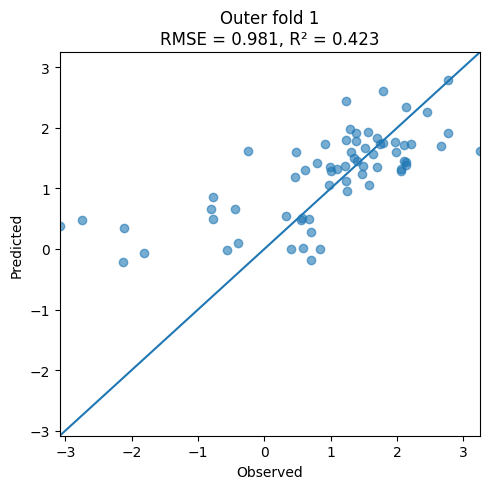

[I 2026-10-24 07:07:56,696] A new study created in memory with name: no-name-04fa3571-3e05-475e-9773-0e5323470325


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_14_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_14_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:07:57,937] Trial 0 finished with value: 0.9741134240136682 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9741134240136682.
[I 2026-10-24 07:08:00,035] Trial 1 finished with value: 1.0450700751233888 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9741134240136682.
[I 2026-10-24 07:08:01,879] Trial 2 finished with value: 1.0605440169130615 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9741134240136682.
[I 2026-10-24 07:08:02,664] Trial 3 finished with value: 0.9824333062376978 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8133 R2 = 0.3521


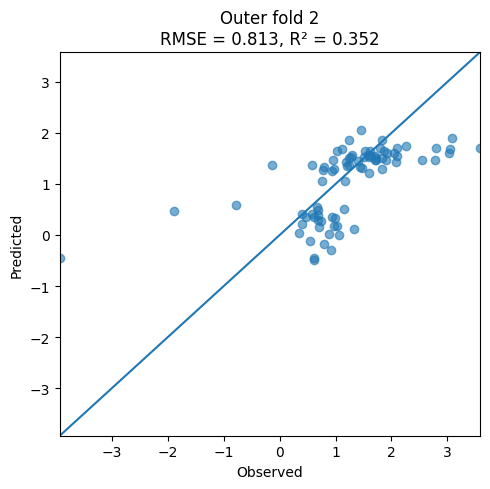

[I 2026-10-24 07:09:59,998] A new study created in memory with name: no-name-2b26bbe5-54d9-450a-b188-5175a8d50e2a


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_14_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_14_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:10:01,285] Trial 0 finished with value: 0.9467888712553894 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9467888712553894.
[I 2026-10-24 07:10:02,328] Trial 1 finished with value: 1.003912696134714 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9467888712553894.
[I 2026-10-24 07:10:03,033] Trial 2 finished with value: 0.9852602700245944 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9467888712553894.
[I 2026-10-24 07:10:03,813] Trial 3 finished with value: 0.9177513801312114 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0482 R2 = 0.3617


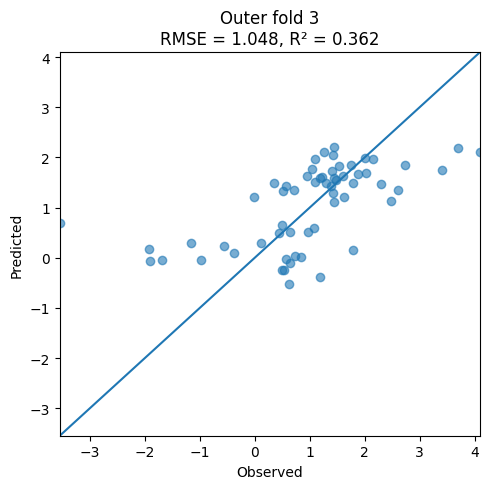

[I 2026-10-24 07:12:01,296] A new study created in memory with name: no-name-8c9e52ce-50a6-41ad-844d-ba0a0f83476f


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_14_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_14_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:12:02,772] Trial 0 finished with value: 0.9632284910862663 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9632284910862663.
[I 2026-10-24 07:12:03,717] Trial 1 finished with value: 1.0330194428805264 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9632284910862663.
[I 2026-10-24 07:12:05,531] Trial 2 finished with value: 1.0116503089939461 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9632284910862663.
[I 2026-10-24 07:12:07,886] Trial 3 finished with value: 0.9567546518269019 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7835 R2 = 0.4505


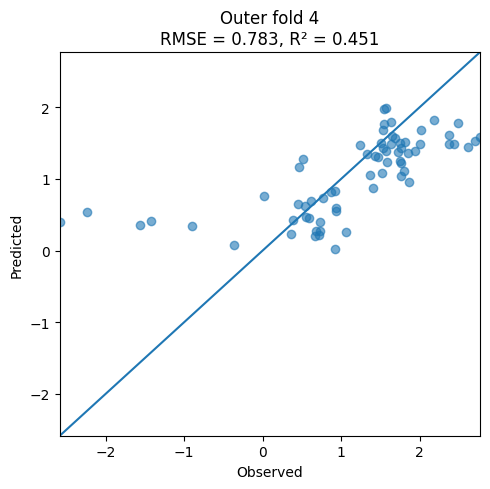

[I 2026-10-24 07:13:46,708] A new study created in memory with name: no-name-beacef18-9e44-4ab0-9d17-268a722d079e


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_14_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_14_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:13:47,850] Trial 0 finished with value: 0.9596822779794364 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9596822779794364.
[I 2026-10-24 07:13:50,879] Trial 1 finished with value: 1.0049475630737452 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9596822779794364.
[I 2026-10-24 07:13:52,178] Trial 2 finished with value: 1.0089034083430677 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9596822779794364.
[I 2026-10-24 07:13:52,845] Trial 3 finished with value: 0.9529875853115428 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.9377 R2 = 0.1136


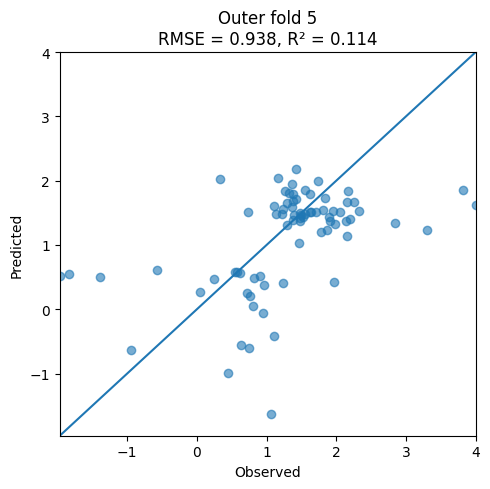

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_14_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_14_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9127 (+/- 0.1002)
Mean R2 (Outer CV): 0.3402 (+/- 0.1192)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 15]


[I 2026-10-24 07:15:39,513] A new study created in memory with name: no-name-1ef7fc29-ed2a-4fc0-b951-65a6657132ff


Resuming from existing file. Found 804 previous runs.
Running rs=786, targetTW=15
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:15:40,460] Trial 0 finished with value: 0.8955814541266502 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8955814541266502.
[I 2026-10-24 07:15:41,289] Trial 1 finished with value: 0.9422787940471016 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8955814541266502.
[I 2026-10-24 07:15:42,022] Trial 2 finished with value: 0.9301296243563527 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8955814541266502.
[I 2026-10-24 07:15:42,753] Trial 3 finished with value: 0.890446771884209 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0003 R2 = 0.4001


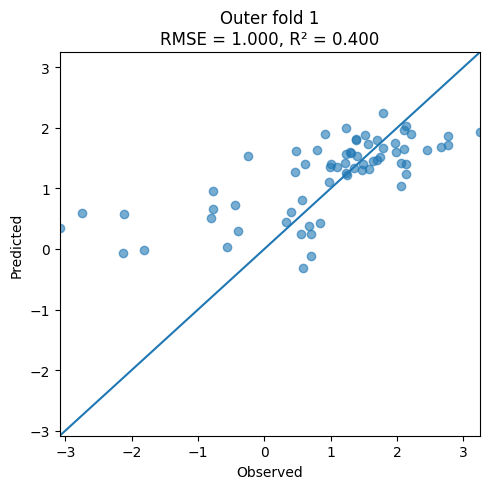

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_15_outerfold_01.json


[I 2026-10-24 07:17:36,182] A new study created in memory with name: no-name-3dcee6f2-1556-4eeb-b730-f491e7fb560b


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_15_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:17:37,949] Trial 0 finished with value: 0.9609612405890835 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9609612405890835.
[I 2026-10-24 07:17:38,778] Trial 1 finished with value: 1.0418572153773398 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9609612405890835.
[I 2026-10-24 07:17:39,370] Trial 2 finished with value: 1.0212047373840667 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9609612405890835.
[I 2026-10-24 07:17:40,424] Trial 3 finished with value: 0.9740693296320443 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8187 R2 = 0.3434


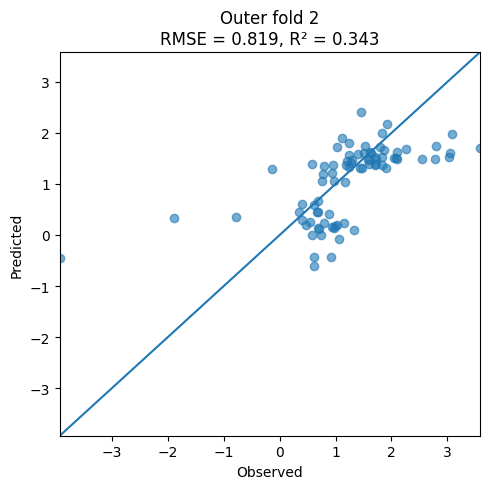

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_15_outerfold_02.json


[I 2026-10-24 07:19:34,261] A new study created in memory with name: no-name-04b47a4c-da24-4f5e-bba3-a1139a4c1f5d


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_15_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:19:36,002] Trial 0 finished with value: 0.9702094787786784 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9702094787786784.
[I 2026-10-24 07:19:36,833] Trial 1 finished with value: 0.9577182020122096 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9577182020122096.
[I 2026-10-24 07:19:38,741] Trial 2 finished with value: 0.9747231273293445 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9577182020122096.
[I 2026-10-24 07:19:41,321] Trial 3 finished with value: 0.9543284504621846 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9909 R2 = 0.4297


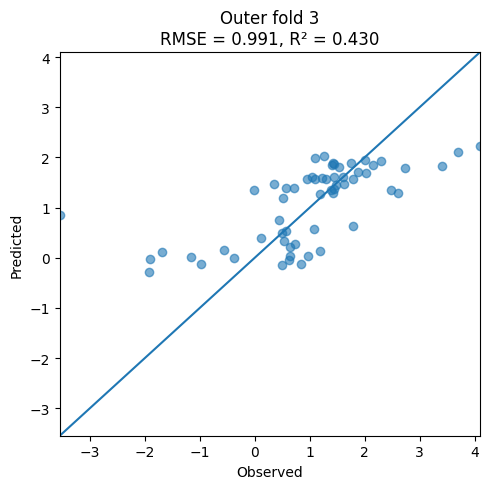

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_15_outerfold_03.json


[I 2026-10-24 07:21:38,800] A new study created in memory with name: no-name-a3237ee6-d4cb-4da2-811a-67b18e857120


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_15_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:21:40,541] Trial 0 finished with value: 0.9623745902397296 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9623745902397296.
[I 2026-10-24 07:21:41,448] Trial 1 finished with value: 1.0015149747757528 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9623745902397296.
[I 2026-10-24 07:21:42,018] Trial 2 finished with value: 0.9985064625618034 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9623745902397296.
[I 2026-10-24 07:21:42,792] Trial 3 finished with value: 0.9901347037702453 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8320 R2 = 0.3804


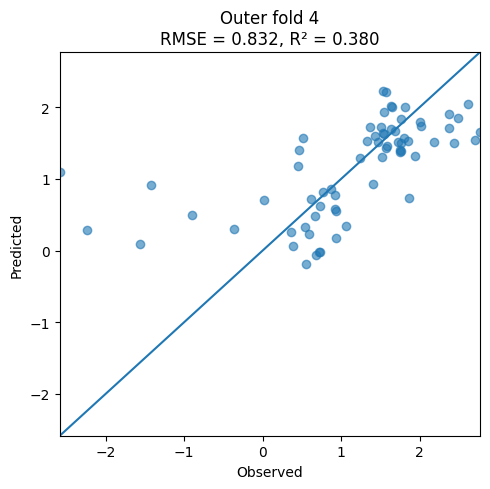

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_15_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_15_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:23:25,003] A new study created in memory with name: no-name-6f1db02a-55e8-487b-bd22-731769d1766d
[I 2026-10-24 07:23:26,518] Trial 0 finished with value: 0.9332057640910509 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9332057640910509.
[I 2026-10-24 07:23:27,356] Trial 1 finished with value: 0.9629666723113076 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9332057640910509.
[I 2026-10-24 07:23:27,987] Trial 2 finished with value: 1.0083262693568875 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.93320576

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.9004 R2 = 0.1827


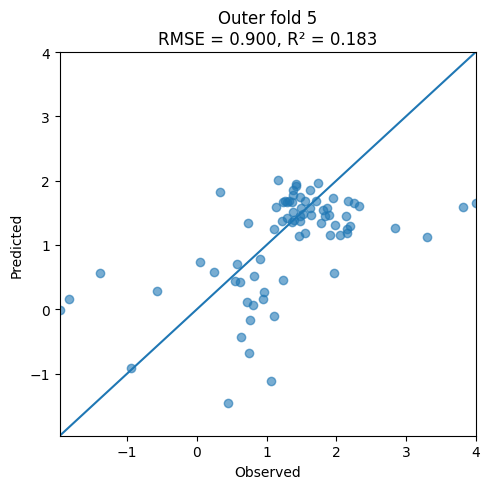

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_15_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_15_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9084 (+/- 0.0764)
Mean R2 (Outer CV): 0.3472 (+/- 0.0869)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 16]


[I 2026-10-24 07:25:19,155] A new study created in memory with name: no-name-7fc2898f-7cc1-496c-88d2-419c57110ba1


Resuming from existing file. Found 810 previous runs.
Running rs=786, targetTW=16
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:25:20,179] Trial 0 finished with value: 0.9188170171977255 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9188170171977255.
[I 2026-10-24 07:25:21,014] Trial 1 finished with value: 0.9098660500936766 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9098660500936766.
[I 2026-10-24 07:25:21,699] Trial 2 finished with value: 0.9412766371930302 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9098660500936766.
[I 2026-10-24 07:25:22,425] Trial 3 finished with value: 0.9039180340600805 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.9534 R2 = 0.4550


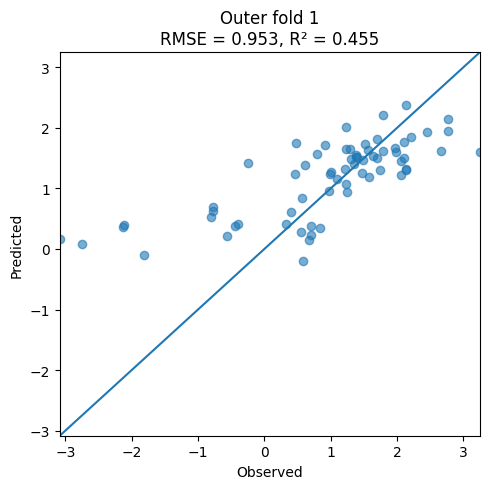

[I 2026-10-24 07:27:16,359] A new study created in memory with name: no-name-86cdb184-e1f0-4348-95aa-e45ced9a9840


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_16_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_16_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:27:17,829] Trial 0 finished with value: 0.9528862243499553 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9528862243499553.
[I 2026-10-24 07:27:18,624] Trial 1 finished with value: 1.0428757700676905 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9528862243499553.
[I 2026-10-24 07:27:19,267] Trial 2 finished with value: 1.0178733996283476 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9528862243499553.
[I 2026-10-24 07:27:20,086] Trial 3 finished with value: 0.9655742616875185 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8686 R2 = 0.2609


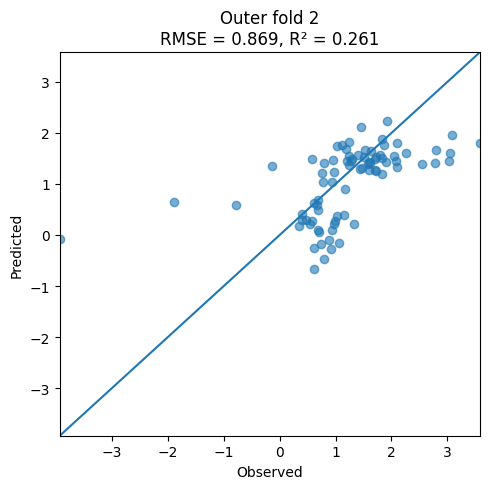

[I 2026-10-24 07:29:22,059] A new study created in memory with name: no-name-c385b2fe-928f-4f5b-b448-fc9376d2a154


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_16_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_16_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:29:23,312] Trial 0 finished with value: 0.9516189971042712 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9516189971042712.
[I 2026-10-24 07:29:27,077] Trial 1 finished with value: 0.9663476426538866 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9516189971042712.
[I 2026-10-24 07:29:27,724] Trial 2 finished with value: 0.9891741248655115 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9516189971042712.
[I 2026-10-24 07:29:28,444] Trial 3 finished with value: 0.9454615982878571 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0525 R2 = 0.3565


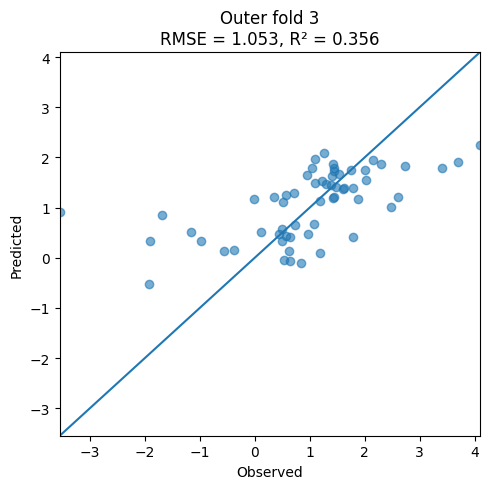

[I 2026-10-24 07:31:28,832] A new study created in memory with name: no-name-38cca399-a20a-4e31-aa3a-54105c9ebcdc


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_16_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_16_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:31:30,312] Trial 0 finished with value: 0.9589317832254336 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9589317832254336.
[I 2026-10-24 07:31:31,111] Trial 1 finished with value: 0.9827243164286306 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9589317832254336.
[I 2026-10-24 07:31:31,696] Trial 2 finished with value: 0.9979796705841959 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9589317832254336.
[I 2026-10-24 07:31:32,411] Trial 3 finished with value: 0.9393387148201773 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8095 R2 = 0.4134


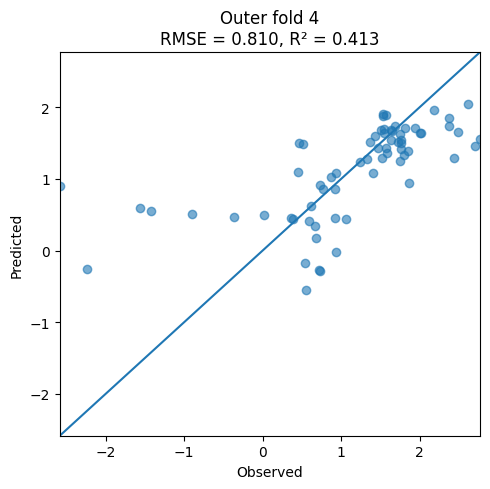

[I 2026-10-24 07:33:16,603] A new study created in memory with name: no-name-7eb3cc51-a0b2-4a5c-a07e-91d48faf8760


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_16_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_16_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:33:20,770] Trial 0 finished with value: 0.9452268155196885 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9452268155196885.
[I 2026-10-24 07:33:21,768] Trial 1 finished with value: 0.9893369175395473 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9452268155196885.
[I 2026-10-24 07:33:22,340] Trial 2 finished with value: 1.0083409965221397 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9452268155196885.
[I 2026-10-24 07:33:23,056] Trial 3 finished with value: 0.931538040345024 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8804 R2 = 0.2185


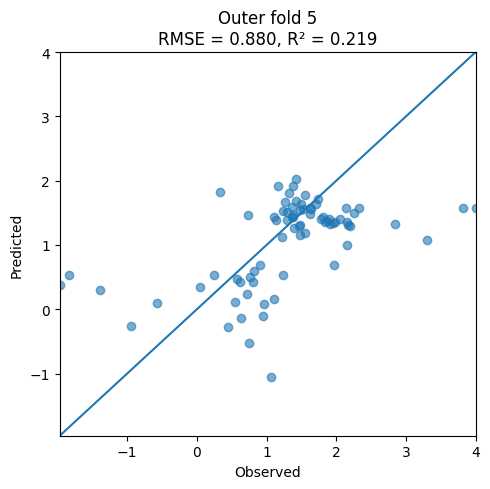

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_16_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_16_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9129 (+/- 0.0835)
Mean R2 (Outer CV): 0.3409 (+/- 0.0893)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 17]


[I 2026-10-24 07:35:18,506] A new study created in memory with name: no-name-aa8f218b-b7d1-47d1-8388-b4b531c95ba5


Resuming from existing file. Found 816 previous runs.
Running rs=786, targetTW=17
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:35:19,447] Trial 0 finished with value: 0.9027764867112386 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9027764867112386.
[I 2026-10-24 07:35:20,329] Trial 1 finished with value: 0.8993722437449372 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.8993722437449372.
[I 2026-10-24 07:35:20,941] Trial 2 finished with value: 0.9270744172954571 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.8993722437449372.
[I 2026-10-24 07:35:21,679] Trial 3 finished with value: 0.8870354981595017 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0041 R2 = 0.3954


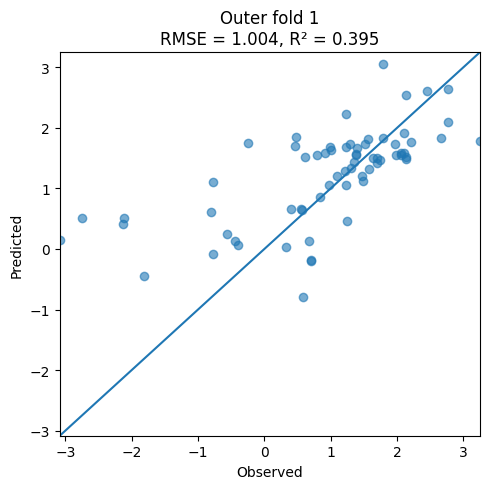

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_17_outerfold_01.json


[I 2026-10-24 07:37:08,805] A new study created in memory with name: no-name-c4c9d605-7d26-439f-a707-cc3371b970b6


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_17_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:37:10,570] Trial 0 finished with value: 0.9767136781556409 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9767136781556409.
[I 2026-10-24 07:37:12,081] Trial 1 finished with value: 1.0241741681555714 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9767136781556409.
[I 2026-10-24 07:37:13,352] Trial 2 finished with value: 0.9937347796617189 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9767136781556409.
[I 2026-10-24 07:37:15,844] Trial 3 finished with value: 0.9961473398651726 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.9608 R2 = 0.0958


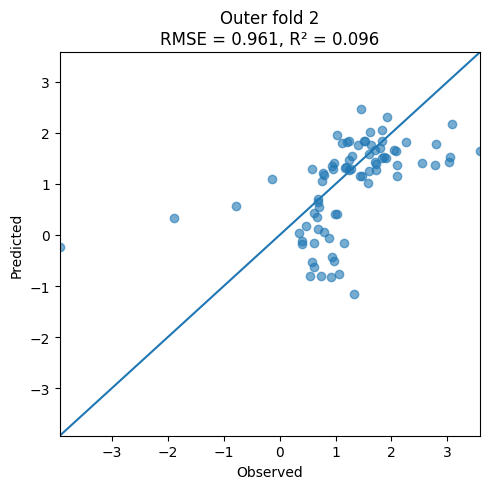

[I 2026-10-24 07:39:11,908] A new study created in memory with name: no-name-677cb6a7-13c2-4f78-a57e-32fbb09495ee


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_17_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_17_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:39:13,623] Trial 0 finished with value: 0.97485378052909 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.97485378052909.
[I 2026-10-24 07:39:14,463] Trial 1 finished with value: 0.9765907890998891 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.97485378052909.
[I 2026-10-24 07:39:15,134] Trial 2 finished with value: 0.9728051692692601 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9728051692692601.
[I 2026-10-24 07:39:15,976] Trial 3 finished with value: 0.9250099619907304 and parameters: {'max_depth': 3, '

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0757 R2 = 0.3278


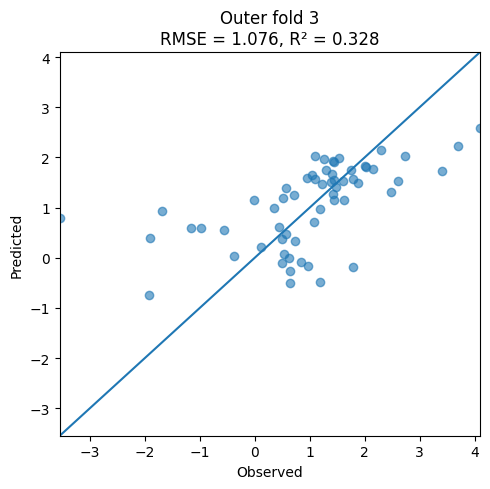

[I 2026-10-24 07:40:57,321] A new study created in memory with name: no-name-b4e5bab9-57bb-4211-9fd9-ae7f68b6eb71


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_17_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_17_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:40:58,710] Trial 0 finished with value: 0.9578735764306314 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9578735764306314.
[I 2026-10-24 07:40:59,706] Trial 1 finished with value: 1.0113362243734958 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9578735764306314.
[I 2026-10-24 07:41:00,394] Trial 2 finished with value: 1.0021187334185868 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9578735764306314.
[I 2026-10-24 07:41:01,243] Trial 3 finished with value: 0.9489644350129356 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7677 R2 = 0.4724


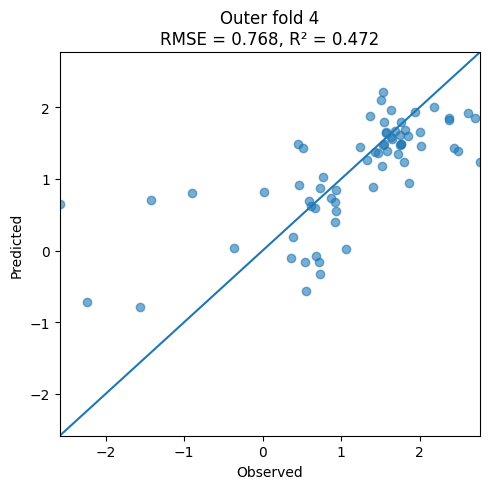

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_17_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_17_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:42:47,315] A new study created in memory with name: no-name-8f6420a1-b75b-453a-9b51-b27fb8a61c56
[I 2026-10-24 07:42:48,859] Trial 0 finished with value: 0.9315209744691813 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9315209744691813.
[I 2026-10-24 07:42:50,144] Trial 1 finished with value: 0.9956916027526836 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9315209744691813.
[I 2026-10-24 07:42:51,847] Trial 2 finished with value: 0.9890434438247817 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.93152097

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.9756 R2 = 0.0404


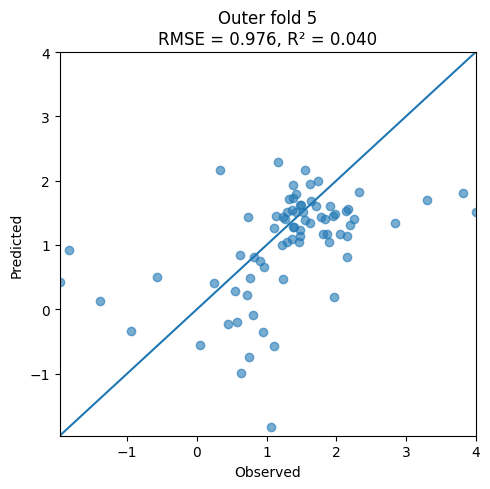

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_17_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_17_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.9568 (+/- 0.1025)
Mean R2 (Outer CV): 0.2663 (+/- 0.1692)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 18]


[I 2026-10-24 07:44:51,426] A new study created in memory with name: no-name-dbc5e07a-0256-4af2-be9e-8cb6c115aa30


Resuming from existing file. Found 822 previous runs.
Running rs=786, targetTW=18
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:44:52,376] Trial 0 finished with value: 0.8920993540016726 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8920993540016726.
[I 2026-10-24 07:44:53,254] Trial 1 finished with value: 0.9017438157977689 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8920993540016726.
[I 2026-10-24 07:44:53,938] Trial 2 finished with value: 0.9414446830395555 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8920993540016726.
[I 2026-10-24 07:44:54,710] Trial 3 finished with value: 0.8984699392273569 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0051 R2 = 0.3942


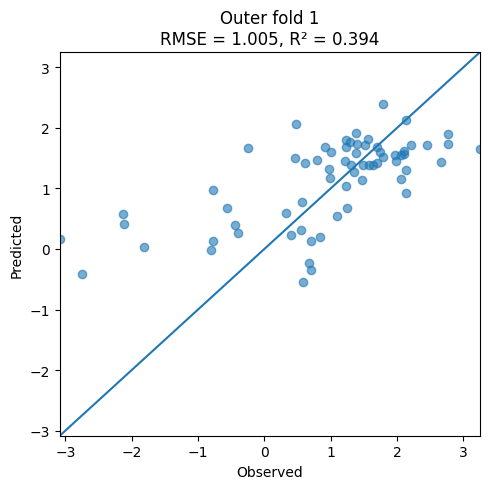

[I 2026-10-24 07:46:34,541] A new study created in memory with name: no-name-953e35b3-f0ae-49f0-80f5-f618116c578d


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_18_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_18_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:46:36,036] Trial 0 finished with value: 0.9441450626547381 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9441450626547381.
[I 2026-10-24 07:46:36,843] Trial 1 finished with value: 0.9602977861790039 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9441450626547381.
[I 2026-10-24 07:46:37,458] Trial 2 finished with value: 0.9929970055609931 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9441450626547381.
[I 2026-10-24 07:46:38,206] Trial 3 finished with value: 0.9763608374577624 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8055 R2 = 0.3643


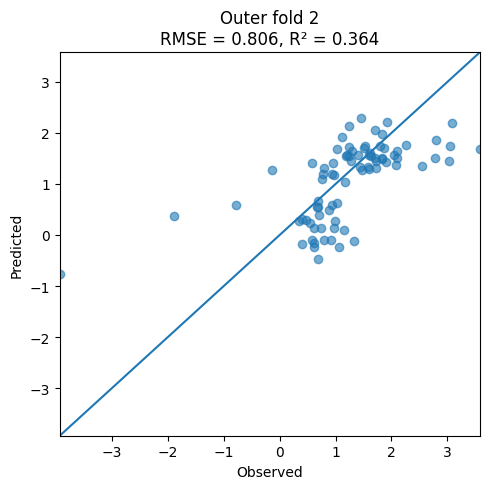

[I 2026-10-24 07:49:03,027] A new study created in memory with name: no-name-7f98ac3b-d3ea-42ec-9153-b44f37813da0


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_18_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_18_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:49:04,673] Trial 0 finished with value: 0.9186047211559946 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9186047211559946.
[I 2026-10-24 07:49:05,519] Trial 1 finished with value: 0.938749570380067 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9186047211559946.
[I 2026-10-24 07:49:06,139] Trial 2 finished with value: 0.9372437257676489 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9186047211559946.
[I 2026-10-24 07:49:06,898] Trial 3 finished with value: 0.9146420121316162 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0467 R2 = 0.3636


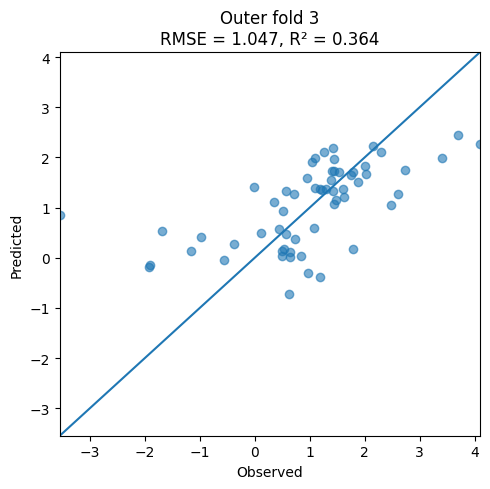

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_18_outerfold_03.json


[I 2026-10-24 07:50:50,895] A new study created in memory with name: no-name-e1872fd3-66ed-4d16-baf8-c36fe113235c


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_18_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:50:52,797] Trial 0 finished with value: 0.9712019910502581 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9712019910502581.
[I 2026-10-24 07:50:54,940] Trial 1 finished with value: 1.008815636488937 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9712019910502581.
[I 2026-10-24 07:50:56,909] Trial 2 finished with value: 1.0019191331902748 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9712019910502581.
[I 2026-10-24 07:50:58,101] Trial 3 finished with value: 0.9441047428042164 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7264 R2 = 0.5277


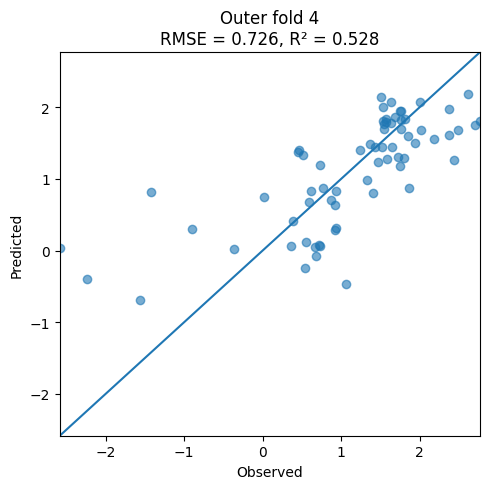

[I 2026-10-24 07:52:43,292] A new study created in memory with name: no-name-bd195798-493e-4ba8-b7f2-c2c6c602e66c


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_18_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_18_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:52:44,913] Trial 0 finished with value: 0.9738233444542801 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9738233444542801.
[I 2026-10-24 07:52:45,863] Trial 1 finished with value: 0.9786793980219427 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9738233444542801.
[I 2026-10-24 07:52:46,552] Trial 2 finished with value: 0.989971904479509 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9738233444542801.
[I 2026-10-24 07:52:47,295] Trial 3 finished with value: 0.9629859550156498 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.9125 R2 = 0.1606


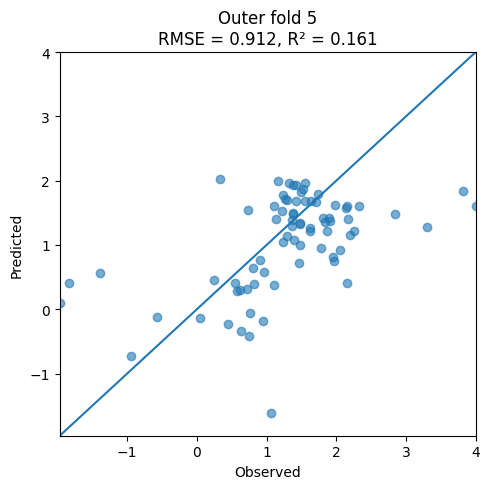

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_18_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_18_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8992 (+/- 0.1198)
Mean R2 (Outer CV): 0.3621 (+/- 0.1175)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 19]


[I 2026-10-24 07:54:45,414] A new study created in memory with name: no-name-281a2f4b-a1f8-42dd-b103-4d600db2d4b4


Resuming from existing file. Found 828 previous runs.
Running rs=786, targetTW=19
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:54:46,442] Trial 0 finished with value: 0.9164126213071173 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9164126213071173.
[I 2026-10-24 07:54:48,529] Trial 1 finished with value: 0.9075375348215925 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9075375348215925.
[I 2026-10-24 07:54:51,031] Trial 2 finished with value: 0.9211797401880197 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9075375348215925.
[I 2026-10-24 07:54:51,892] Trial 3 finished with value: 0.8968556231126804 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0244 R2 = 0.3708


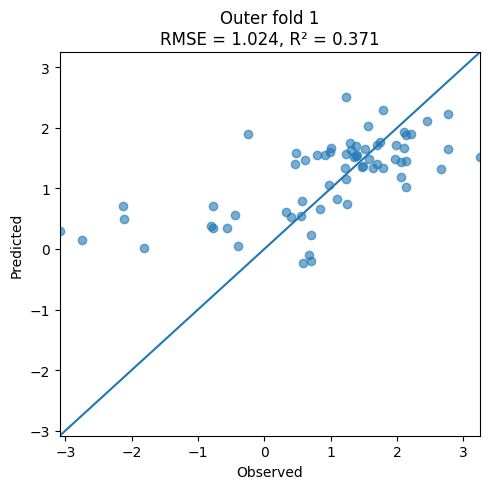

[I 2026-10-24 07:56:32,755] A new study created in memory with name: no-name-c7ddd2f2-7a4d-4a43-b698-8191543bf4aa


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_19_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_19_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:56:34,137] Trial 0 finished with value: 0.9297463556151798 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9297463556151798.
[I 2026-10-24 07:56:35,943] Trial 1 finished with value: 0.9899262795635052 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9297463556151798.
[I 2026-10-24 07:56:36,694] Trial 2 finished with value: 0.9914754689790083 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9297463556151798.
[I 2026-10-24 07:56:37,421] Trial 3 finished with value: 0.9390441761479578 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.7504 R2 = 0.4484


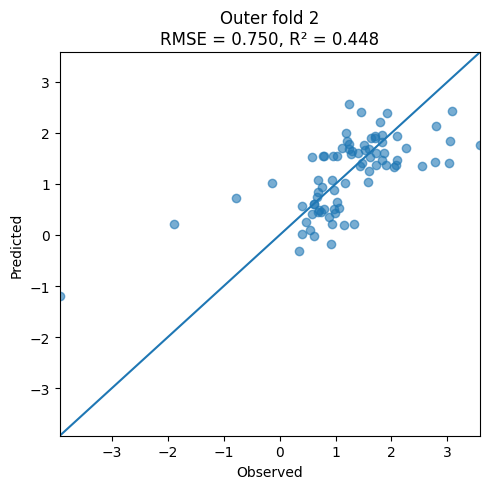

[I 2026-10-24 07:58:18,757] A new study created in memory with name: no-name-d8d6753e-607d-40fe-b51c-32c89939838b


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_19_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_19_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 07:58:20,252] Trial 0 finished with value: 0.9278374936205704 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9278374936205704.
[I 2026-10-24 07:58:21,064] Trial 1 finished with value: 0.93731993364071 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9278374936205704.
[I 2026-10-24 07:58:21,752] Trial 2 finished with value: 0.9610285282457383 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9278374936205704.
[I 2026-10-24 07:58:22,451] Trial 3 finished with value: 0.9452106111099208 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9842 R2 = 0.4373


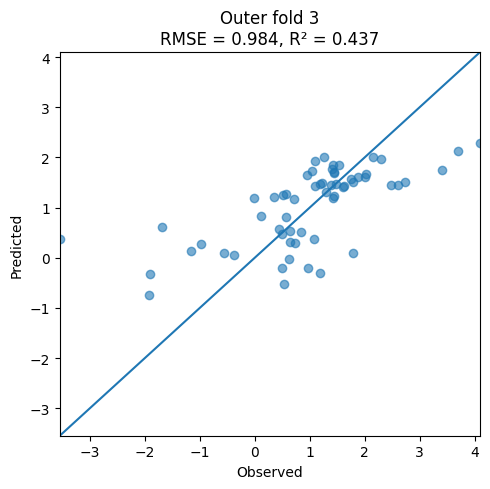

[I 2026-10-24 08:00:18,708] A new study created in memory with name: no-name-45e99d44-4373-40f0-a872-8e839f84bd4a


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_19_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_19_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:00:20,289] Trial 0 finished with value: 0.9684239146473177 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9684239146473177.
[I 2026-10-24 08:00:21,125] Trial 1 finished with value: 1.0295836012771198 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9684239146473177.
[I 2026-10-24 08:00:21,770] Trial 2 finished with value: 0.9659331599805193 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9659331599805193.
[I 2026-10-24 08:00:22,498] Trial 3 finished with value: 0.9466131856287257 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7407 R2 = 0.5088


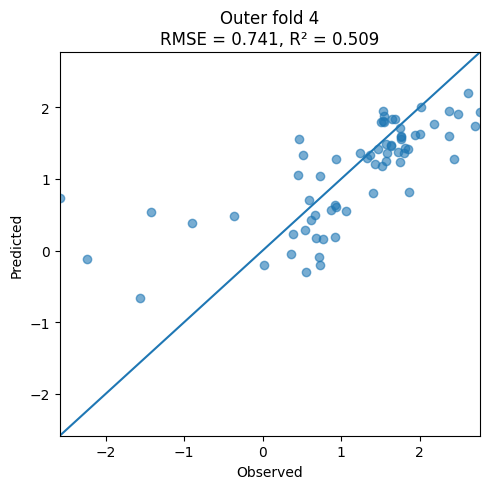

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_19_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_19_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:02:04,293] A new study created in memory with name: no-name-bcd2bf79-0a76-408b-8263-e84c8bbbdbe9
[I 2026-10-24 08:02:05,903] Trial 0 finished with value: 0.9332323896178105 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9332323896178105.
[I 2026-10-24 08:02:06,782] Trial 1 finished with value: 1.0241856241875495 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9332323896178105.
[I 2026-10-24 08:02:07,428] Trial 2 finished with value: 0.9949016887406383 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.93323238

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8545 R2 = 0.2640


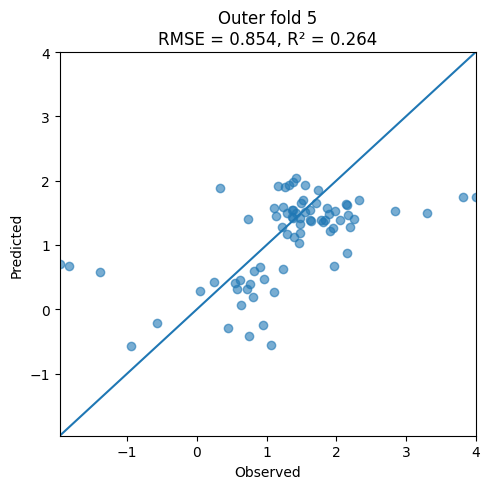

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_19_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_19_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8708 (+/- 0.1167)
Mean R2 (Outer CV): 0.4058 (+/- 0.0834)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 20]


[I 2026-10-24 08:04:21,452] A new study created in memory with name: no-name-cf3ec5fb-59f6-4a9d-a2b2-1b60533889d1


Resuming from existing file. Found 834 previous runs.
Running rs=786, targetTW=20
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:04:24,661] Trial 0 finished with value: 0.8971916340018891 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.8971916340018891.
[I 2026-10-24 08:04:25,551] Trial 1 finished with value: 0.904778065645523 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.8971916340018891.
[I 2026-10-24 08:04:26,166] Trial 2 finished with value: 0.9352148358713732 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.8971916340018891.
[I 2026-10-24 08:04:26,910] Trial 3 finished with value: 0.8907423757304048 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.9697 R2 = 0.4361


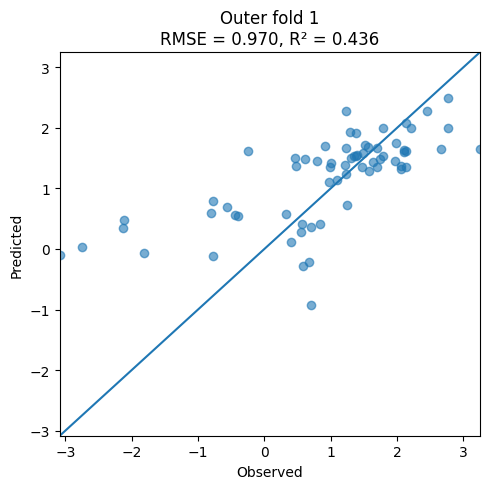

[I 2026-10-24 08:06:21,090] A new study created in memory with name: no-name-e65a638c-d6a9-4c05-b80e-78fd614717a7


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_20_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_20_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:06:22,604] Trial 0 finished with value: 0.9426347788310203 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9426347788310203.
[I 2026-10-24 08:06:23,385] Trial 1 finished with value: 0.9274885273388257 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9274885273388257.
[I 2026-10-24 08:06:24,066] Trial 2 finished with value: 0.9098154960245699 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9098154960245699.
[I 2026-10-24 08:06:24,823] Trial 3 finished with value: 0.9353848447927767 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8260 R2 = 0.3316


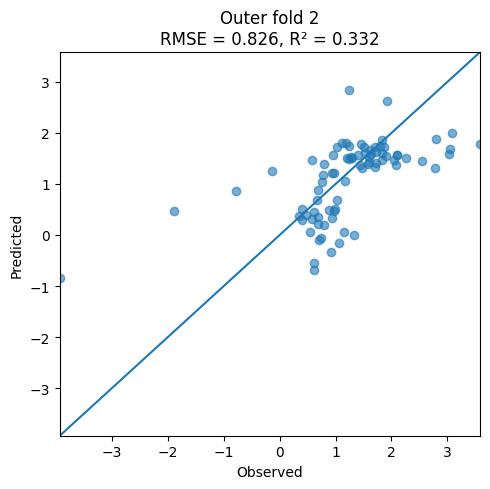

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_20_outerfold_02.json


[I 2026-10-24 08:08:13,347] A new study created in memory with name: no-name-4832545f-d61e-4aa4-9b31-93f16529b27d


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_20_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:08:14,854] Trial 0 finished with value: 0.9400916326072586 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9400916326072586.
[I 2026-10-24 08:08:19,099] Trial 1 finished with value: 0.9399798605221039 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9399798605221039.
[I 2026-10-24 08:08:19,812] Trial 2 finished with value: 0.9385163514289352 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 2 with value: 0.9385163514289352.
[I 2026-10-24 08:08:20,593] Trial 3 finished with value: 0.9364919202982882 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9901 R2 = 0.4305


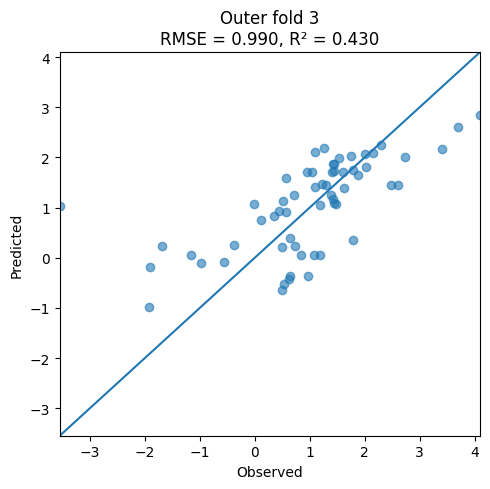

[I 2026-10-24 08:10:07,640] A new study created in memory with name: no-name-9e0923c0-96a2-4e16-88c1-2f6109f5035e


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_20_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_20_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:10:09,275] Trial 0 finished with value: 0.9856807972152493 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9856807972152493.
[I 2026-10-24 08:10:10,130] Trial 1 finished with value: 0.9770405896172946 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9770405896172946.
[I 2026-10-24 08:10:10,827] Trial 2 finished with value: 0.9829742729884898 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9770405896172946.
[I 2026-10-24 08:10:11,756] Trial 3 finished with value: 0.9421750960697803 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8033 R2 = 0.4224


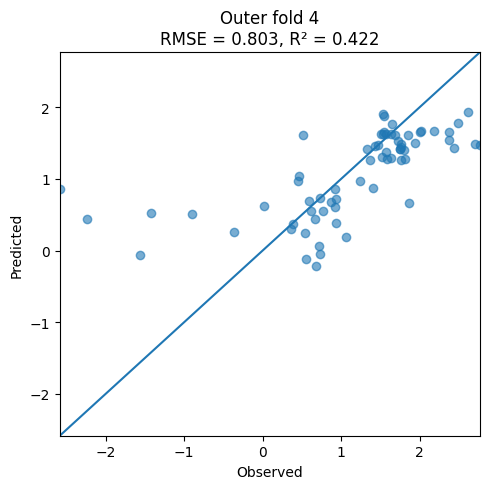

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_20_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_20_outerfold_04_meta.json

=== Outer fold 5/5 ===


[I 2026-10-24 08:12:29,438] A new study created in memory with name: no-name-b673fcdc-e950-4190-a7bd-acf59804b7b7


Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:12:31,527] Trial 0 finished with value: 0.9696042547063757 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9696042547063757.
[I 2026-10-24 08:12:32,431] Trial 1 finished with value: 1.0135483842426682 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9696042547063757.
[I 2026-10-24 08:12:33,151] Trial 2 finished with value: 0.9892984666766083 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9696042547063757.
[I 2026-10-24 08:12:33,933] Trial 3 finished with value: 0.9485841615741479 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8245 R2 = 0.3146


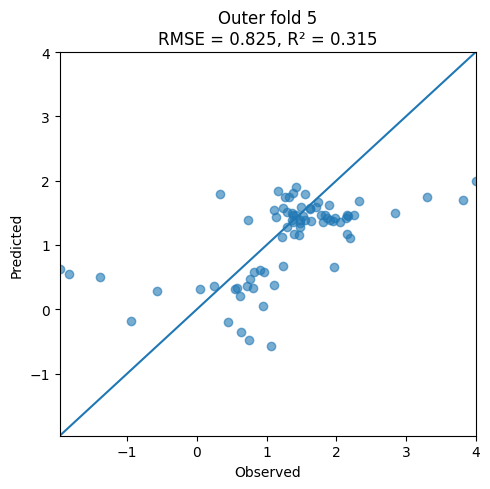

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_20_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_20_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8827 (+/- 0.0800)
Mean R2 (Outer CV): 0.3871 (+/- 0.0527)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 21]


[I 2026-10-24 08:14:52,909] A new study created in memory with name: no-name-c163b745-8785-43d3-b444-df82ee6d163f


Resuming from existing file. Found 840 previous runs.
Running rs=786, targetTW=21
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:14:55,367] Trial 0 finished with value: 0.900836851594635 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.900836851594635.
[I 2026-10-24 08:14:56,316] Trial 1 finished with value: 0.8977892359311609 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.8977892359311609.
[I 2026-10-24 08:14:56,944] Trial 2 finished with value: 0.9176052866402711 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.8977892359311609.
[I 2026-10-24 08:14:57,758] Trial 3 finished with value: 0.8995303075066339 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.9477 R2 = 0.4615


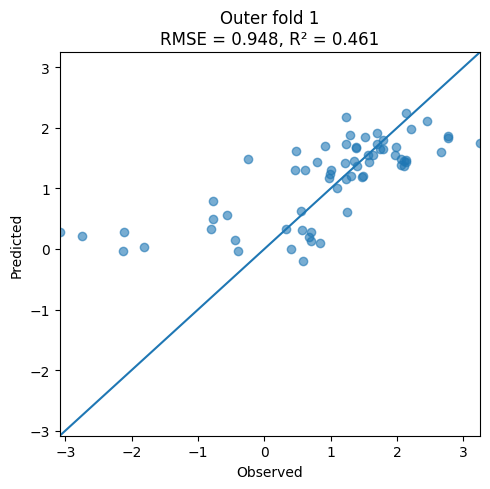

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_21_outerfold_01.json


[I 2026-10-24 08:17:30,254] A new study created in memory with name: no-name-b7c7acd4-45a9-4903-b0f6-914257f2d727


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_21_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:17:31,441] Trial 0 finished with value: 0.9226574241047152 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9226574241047152.
[I 2026-10-24 08:17:33,462] Trial 1 finished with value: 0.9016066309772801 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9016066309772801.
[I 2026-10-24 08:17:34,757] Trial 2 finished with value: 0.9163127347689878 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9016066309772801.
[I 2026-10-24 08:17:36,577] Trial 3 finished with value: 0.9400973629670935 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.7845 R2 = 0.3970


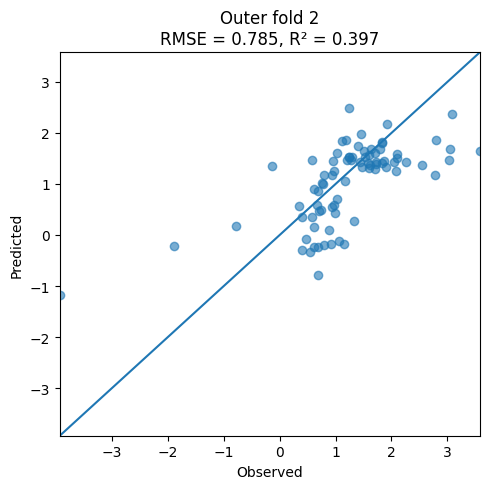

[I 2026-10-24 08:19:24,508] A new study created in memory with name: no-name-69b04722-046e-45b7-aaf3-1893582feea9


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_21_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_21_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:19:26,147] Trial 0 finished with value: 0.9299750035791383 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9299750035791383.
[I 2026-10-24 08:19:27,040] Trial 1 finished with value: 0.9341537131623505 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9299750035791383.
[I 2026-10-24 08:19:27,707] Trial 2 finished with value: 0.9465243623945869 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9299750035791383.
[I 2026-10-24 08:19:28,477] Trial 3 finished with value: 0.8932616577712054 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0228 R2 = 0.3923


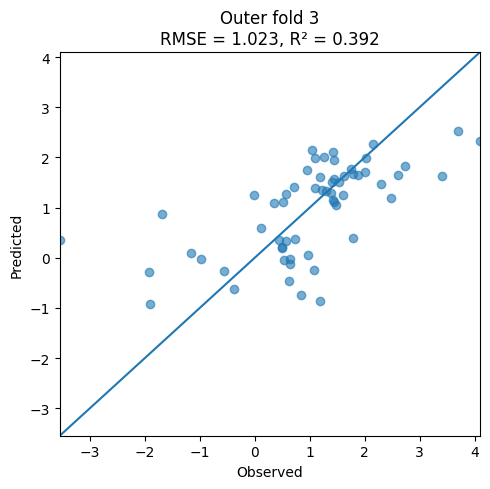

[I 2026-10-24 08:21:11,318] A new study created in memory with name: no-name-42c10a47-056b-4afe-b198-44984be2e30f


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_21_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_21_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:21:12,969] Trial 0 finished with value: 0.9819704729183392 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9819704729183392.
[I 2026-10-24 08:21:14,216] Trial 1 finished with value: 1.0045195314875193 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9819704729183392.
[I 2026-10-24 08:21:16,045] Trial 2 finished with value: 0.99509772512517 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9819704729183392.
[I 2026-10-24 08:21:18,349] Trial 3 finished with value: 0.9294611022347665 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8084 R2 = 0.4150


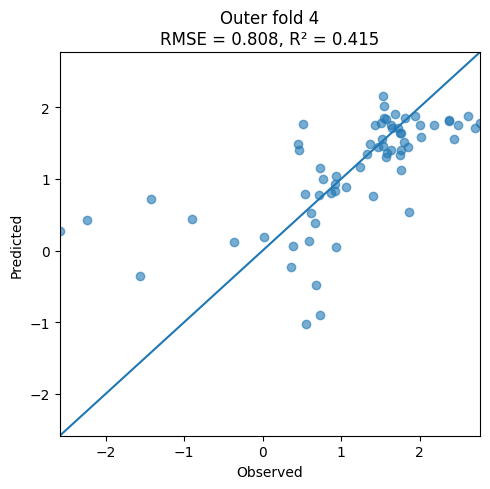

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_21_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_21_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']


[I 2026-10-24 08:23:03,866] A new study created in memory with name: no-name-908566f6-fe81-42e5-bcd3-c2a1e3355c71


Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:23:05,947] Trial 0 finished with value: 0.9332843692787341 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9332843692787341.
[I 2026-10-24 08:23:06,824] Trial 1 finished with value: 0.9532978506817297 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9332843692787341.
[I 2026-10-24 08:23:07,559] Trial 2 finished with value: 0.9980514460983678 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9332843692787341.
[I 2026-10-24 08:23:08,263] Trial 3 finished with value: 0.9569637689103992 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.7939 R2 = 0.3645


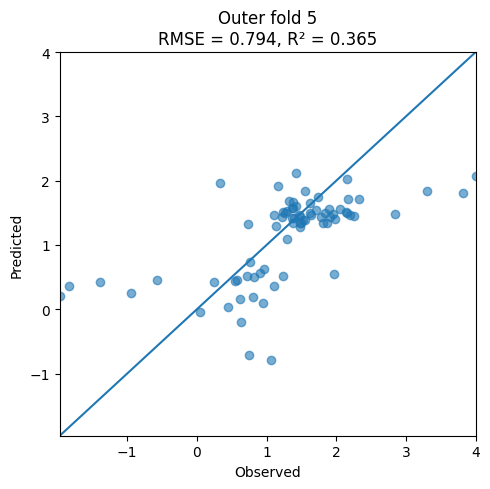

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_21_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_21_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8715 (+/- 0.0962)
Mean R2 (Outer CV): 0.4061 (+/- 0.0321)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 22]


[I 2026-10-24 08:25:09,200] A new study created in memory with name: no-name-0deaeb75-51b3-4405-8cd8-3044ed9755ff


Resuming from existing file. Found 846 previous runs.
Running rs=786, targetTW=22
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:25:10,245] Trial 0 finished with value: 0.9167343699020041 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9167343699020041.
[I 2026-10-24 08:25:12,347] Trial 1 finished with value: 0.9194654218859889 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9167343699020041.
[I 2026-10-24 08:25:13,784] Trial 2 finished with value: 0.9228794356403912 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9167343699020041.
[I 2026-10-24 08:25:15,683] Trial 3 finished with value: 0.899425310587325 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.9926 R2 = 0.4092


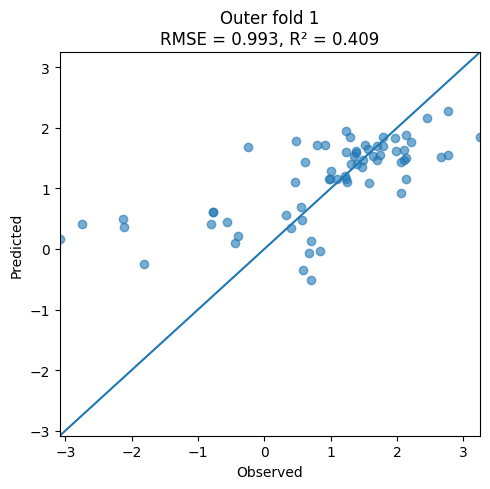

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_22_outerfold_01.json


[I 2026-10-24 08:27:15,196] A new study created in memory with name: no-name-a1112ce9-ebe4-4a1e-a119-ed0f5dc1070f


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_22_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:27:16,611] Trial 0 finished with value: 0.9490943437117988 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9490943437117988.
[I 2026-10-24 08:27:17,980] Trial 1 finished with value: 0.9625534361122794 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9490943437117988.
[I 2026-10-24 08:27:18,680] Trial 2 finished with value: 0.9661210090643628 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9490943437117988.
[I 2026-10-24 08:27:19,440] Trial 3 finished with value: 0.9421414708737313 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8130 R2 = 0.3525


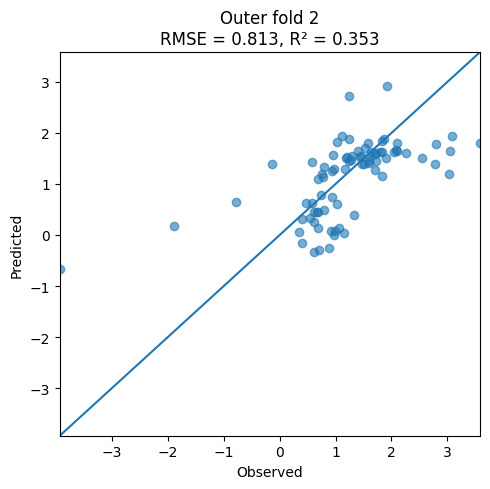

[I 2026-10-24 08:29:10,827] A new study created in memory with name: no-name-09ac080e-bd84-4401-9cd2-7b30b69c00fc


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_22_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_22_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:29:12,574] Trial 0 finished with value: 0.9470433972166307 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9470433972166307.
[I 2026-10-24 08:29:13,481] Trial 1 finished with value: 0.9669266391511344 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9470433972166307.
[I 2026-10-24 08:29:14,128] Trial 2 finished with value: 0.9485959779320015 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9470433972166307.
[I 2026-10-24 08:29:14,898] Trial 3 finished with value: 0.9641712823736686 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9992 R2 = 0.4200


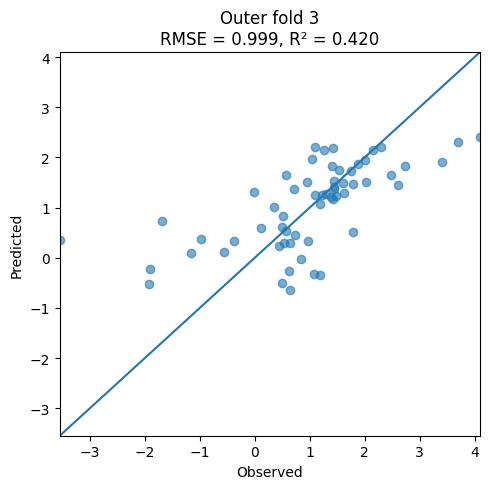

[I 2026-10-24 08:30:57,259] A new study created in memory with name: no-name-d122f2fa-a427-4c15-a020-e35e74542120


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_22_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_22_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:30:58,901] Trial 0 finished with value: 0.9694481202140953 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9694481202140953.
[I 2026-10-24 08:30:59,768] Trial 1 finished with value: 0.9945321761767045 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9694481202140953.
[I 2026-10-24 08:31:00,458] Trial 2 finished with value: 0.9875624986518902 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9694481202140953.
[I 2026-10-24 08:31:01,220] Trial 3 finished with value: 0.9396312075641684 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8275 R2 = 0.3870


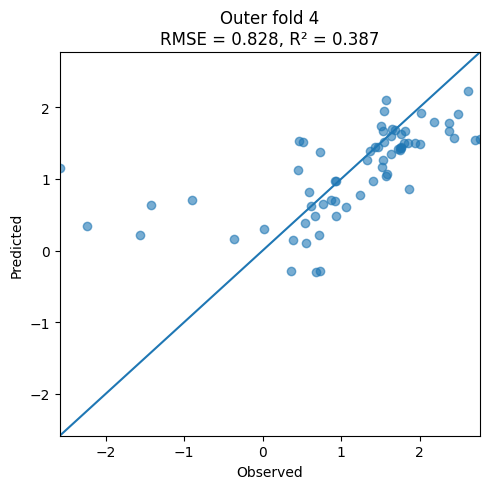

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_22_outerfold_04.json


[I 2026-10-24 08:32:44,385] A new study created in memory with name: no-name-c90dbaf3-712f-433b-bc18-7f6bb86cb213


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_22_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:32:46,518] Trial 0 finished with value: 0.9336457764412668 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9336457764412668.
[I 2026-10-24 08:32:48,563] Trial 1 finished with value: 0.9585956767488524 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9336457764412668.
[I 2026-10-24 08:32:50,728] Trial 2 finished with value: 0.9925400729021603 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9336457764412668.
[I 2026-10-24 08:32:51,432] Trial 3 finished with value: 0.9663386222230115 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8375 R2 = 0.2928


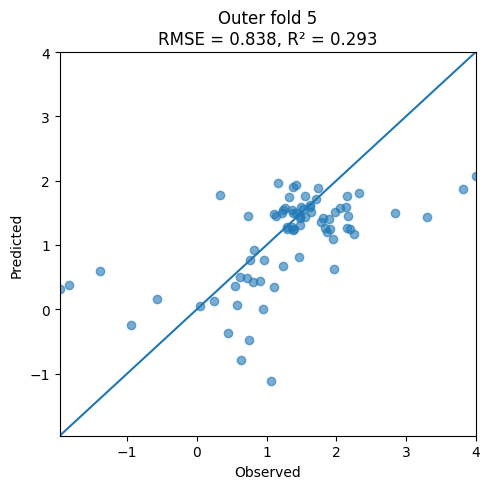

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_22_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_22_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8940 (+/- 0.0836)
Mean R2 (Outer CV): 0.3723 (+/- 0.0460)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 23]


[I 2026-10-24 08:34:56,022] A new study created in memory with name: no-name-879cf405-7ad8-46d7-af21-2b49ba84916f


Resuming from existing file. Found 852 previous runs.
Running rs=786, targetTW=23
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:34:57,046] Trial 0 finished with value: 0.922678710914966 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.922678710914966.
[I 2026-10-24 08:34:57,941] Trial 1 finished with value: 0.900509652842464 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.900509652842464.
[I 2026-10-24 08:34:58,577] Trial 2 finished with value: 0.9296188709403692 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.900509652842464.
[I 2026-10-24 08:34:59,316] Trial 3 finished with value: 0.8995955739085495 and parameters: {'max_depth': 3, 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.9591 R2 = 0.4484


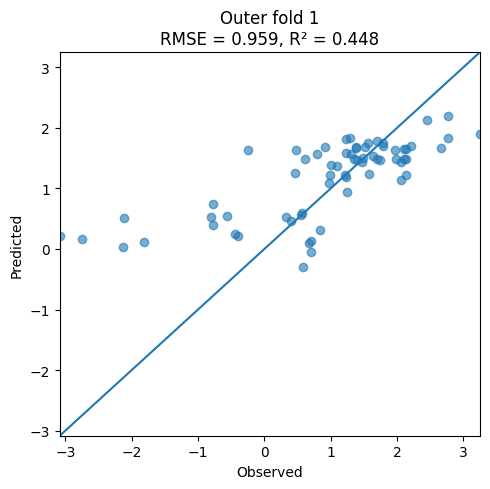

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_23_outerfold_01.json


[I 2026-10-24 08:37:18,706] A new study created in memory with name: no-name-a29ae22e-7b80-45c8-a189-2c4f99375ffa


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_23_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:37:20,765] Trial 0 finished with value: 0.9529311168573675 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9529311168573675.
[I 2026-10-24 08:37:21,596] Trial 1 finished with value: 0.9414814599338247 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9414814599338247.
[I 2026-10-24 08:37:22,283] Trial 2 finished with value: 0.9888373992512647 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9414814599338247.
[I 2026-10-24 08:37:23,042] Trial 3 finished with value: 0.9463197677226953 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8472 R2 = 0.2969


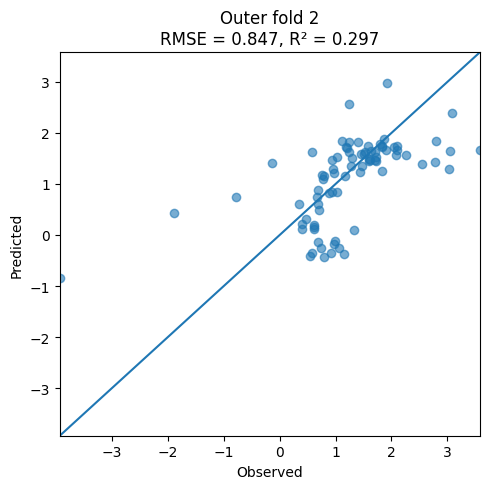

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_23_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_23_outerfold_02_meta.json

=== Outer fold 3/5 ===


[I 2026-10-24 08:39:24,566] A new study created in memory with name: no-name-18a1c6a7-19ad-4fae-a27d-cbda2a7c5ef9


Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:39:28,308] Trial 0 finished with value: 0.897879035102487 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.897879035102487.
[I 2026-10-24 08:39:30,566] Trial 1 finished with value: 0.9683169623772243 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.897879035102487.
[I 2026-10-24 08:39:31,342] Trial 2 finished with value: 0.9328379446065116 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.897879035102487.
[I 2026-10-24 08:39:32,129] Trial 3 finished with value: 0.9212524206305719 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9924 R2 = 0.4279


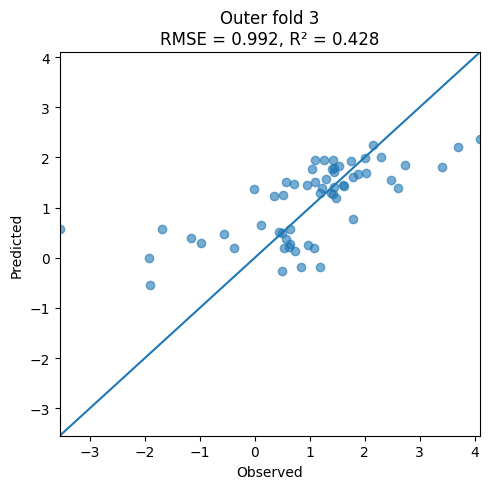

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_23_outerfold_03.json


[I 2026-10-24 08:41:34,873] A new study created in memory with name: no-name-6bbba04b-00f7-4586-b382-9b0c9ccb86a2


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_23_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:41:36,849] Trial 0 finished with value: 0.9768680602350397 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9768680602350397.
[I 2026-10-24 08:41:39,020] Trial 1 finished with value: 1.01082223565172 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9768680602350397.
[I 2026-10-24 08:41:40,961] Trial 2 finished with value: 0.9975529379813556 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9768680602350397.
[I 2026-10-24 08:41:42,248] Trial 3 finished with value: 0.9842322859080522 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7339 R2 = 0.5178


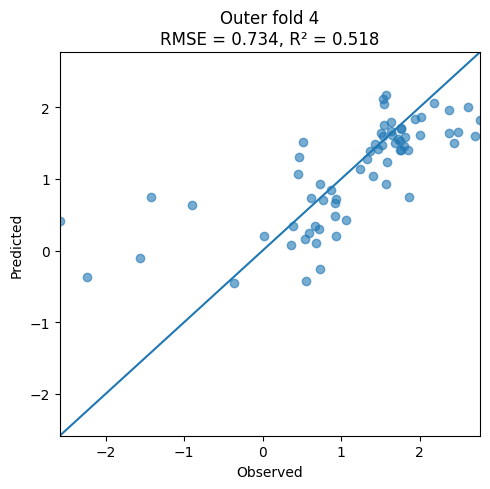

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_23_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_23_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:43:43,788] A new study created in memory with name: no-name-1474c7e5-8caa-4ea0-bf7d-77cd11188e0b
[I 2026-10-24 08:43:45,525] Trial 0 finished with value: 0.9241847278457153 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9241847278457153.
[I 2026-10-24 08:43:46,382] Trial 1 finished with value: 0.946623709221953 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9241847278457153.
[I 2026-10-24 08:43:47,005] Trial 2 finished with value: 0.965265830778337 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9241847278

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8086 R2 = 0.3408


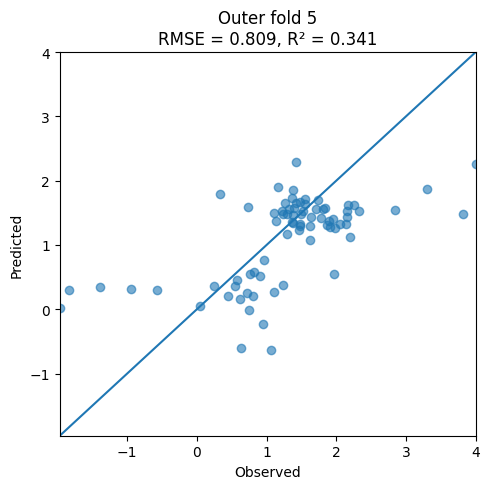

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_23_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_23_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8682 (+/- 0.0956)
Mean R2 (Outer CV): 0.4064 (+/- 0.0786)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 24]


[I 2026-10-24 08:45:27,816] A new study created in memory with name: no-name-66784716-434f-4207-b6c0-013bed8c0749


Resuming from existing file. Found 858 previous runs.
Running rs=786, targetTW=24
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:45:28,851] Trial 0 finished with value: 0.9014088535293538 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9014088535293538.
[I 2026-10-24 08:45:29,745] Trial 1 finished with value: 0.9215766872934668 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9014088535293538.
[I 2026-10-24 08:45:30,368] Trial 2 finished with value: 0.9279849826776858 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9014088535293538.
[I 2026-10-24 08:45:31,193] Trial 3 finished with value: 0.9166588739345733 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.9883 R2 = 0.4144


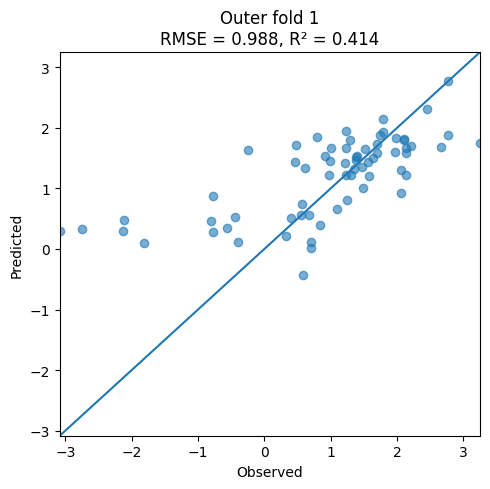

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_24_outerfold_01.json


[I 2026-10-24 08:47:12,574] A new study created in memory with name: no-name-6e86ce0e-9682-4865-847a-3988694a6c9d


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_24_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:47:14,753] Trial 0 finished with value: 0.9380632067224941 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9380632067224941.
[I 2026-10-24 08:47:15,625] Trial 1 finished with value: 0.953858939388482 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9380632067224941.
[I 2026-10-24 08:47:16,343] Trial 2 finished with value: 0.9722411184827352 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9380632067224941.
[I 2026-10-24 08:47:17,392] Trial 3 finished with value: 0.9613892026943153 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.7788 R2 = 0.4058


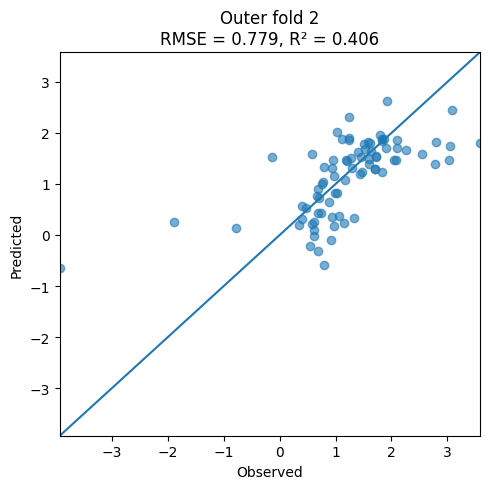

[I 2026-10-24 08:49:12,044] A new study created in memory with name: no-name-adf60311-89df-4972-a874-5ffda4812bb3


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_24_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_24_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:49:13,731] Trial 0 finished with value: 0.9256864198133905 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9256864198133905.
[I 2026-10-24 08:49:14,606] Trial 1 finished with value: 0.95370477433702 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9256864198133905.
[I 2026-10-24 08:49:16,702] Trial 2 finished with value: 0.9451088411275275 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9256864198133905.
[I 2026-10-24 08:49:19,538] Trial 3 finished with value: 0.9132724190828866 and parameters: {'max_depth': 

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9742 R2 = 0.4487


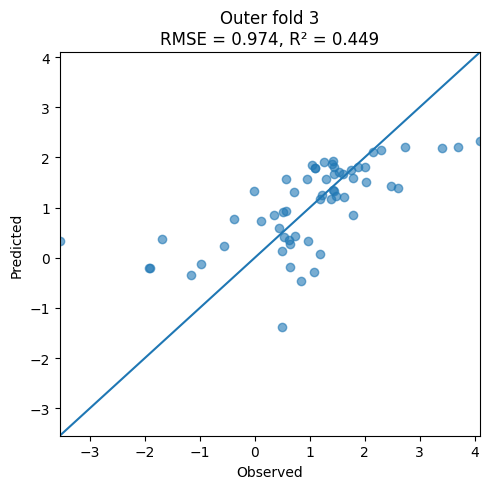

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_24_outerfold_03.json


[I 2026-10-24 08:51:09,077] A new study created in memory with name: no-name-22c5baed-466a-4c76-960c-ce82d6450eff


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_24_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:51:11,112] Trial 0 finished with value: 0.9413067789299707 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9413067789299707.
[I 2026-10-24 08:51:12,018] Trial 1 finished with value: 1.0084721827689065 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9413067789299707.
[I 2026-10-24 08:51:12,667] Trial 2 finished with value: 0.9689178448018878 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9413067789299707.
[I 2026-10-24 08:51:13,714] Trial 3 finished with value: 0.9495219567115741 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.8092 R2 = 0.4138


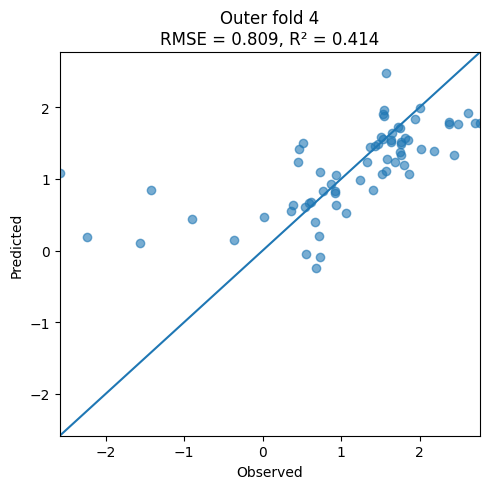

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_24_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_24_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:52:52,113] A new study created in memory with name: no-name-e44ca29a-71ae-4570-b066-cb6acb3c7789
[I 2026-10-24 08:52:53,849] Trial 0 finished with value: 0.9305277306107159 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9305277306107159.
[I 2026-10-24 08:52:54,732] Trial 1 finished with value: 0.9584867964421427 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9305277306107159.
[I 2026-10-24 08:52:55,437] Trial 2 finished with value: 0.9881672119142331 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.93052773

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8009 R2 = 0.3533


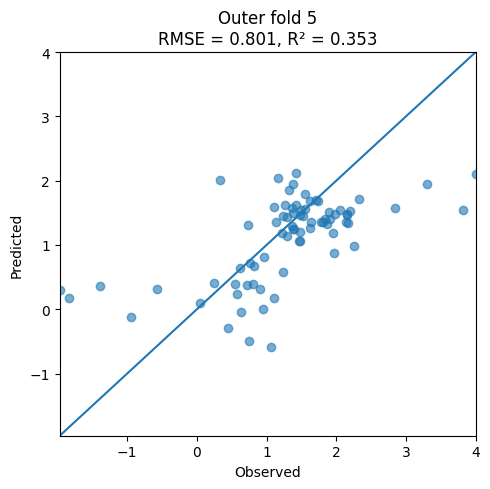

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_24_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_24_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8703 (+/- 0.0912)
Mean R2 (Outer CV): 0.4072 (+/- 0.0307)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 25]


[I 2026-10-24 08:54:57,994] A new study created in memory with name: no-name-d8cd7cd1-ec68-4ed6-95cb-cf406e8a8976


Resuming from existing file. Found 864 previous runs.
Running rs=786, targetTW=25
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:55:00,166] Trial 0 finished with value: 0.9183068393725932 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9183068393725932.
[I 2026-10-24 08:55:01,132] Trial 1 finished with value: 0.9077422238482095 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9077422238482095.
[I 2026-10-24 08:55:01,793] Trial 2 finished with value: 0.9483468843894782 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9077422238482095.
[I 2026-10-24 08:55:02,611] Trial 3 finished with value: 0.925658368888131 and parameters: {'max_depth':

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 0.9857 R2 = 0.4174


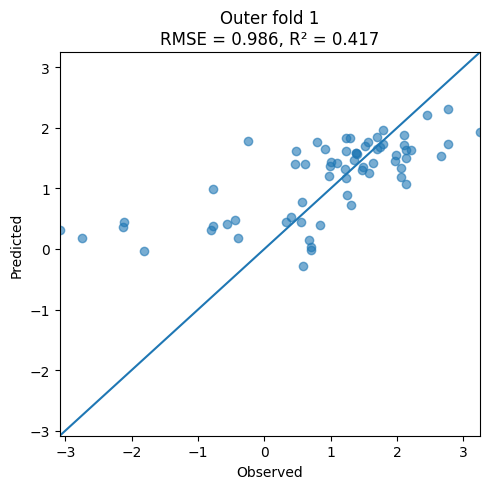

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_25_outerfold_01.json


[I 2026-10-24 08:56:46,410] A new study created in memory with name: no-name-87014f81-9364-4b5f-b1b8-d7ded0e9980b


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_25_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:56:48,466] Trial 0 finished with value: 0.9415541917324695 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9415541917324695.
[I 2026-10-24 08:56:49,413] Trial 1 finished with value: 0.9284100540906189 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.9284100540906189.
[I 2026-10-24 08:56:50,148] Trial 2 finished with value: 0.9738745964793325 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.9284100540906189.
[I 2026-10-24 08:56:50,925] Trial 3 finished with value: 0.9186039300922404 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.7977 R2 = 0.3766


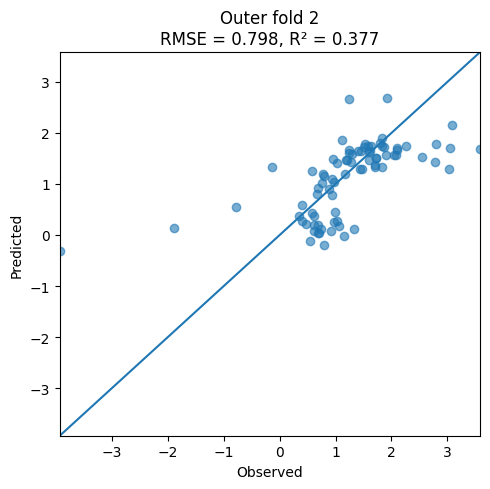

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_25_outerfold_02.json


[I 2026-10-24 08:58:50,268] A new study created in memory with name: no-name-302e8ce2-687c-4184-821f-8286fdb4eb24


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_25_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 08:58:53,828] Trial 0 finished with value: 0.9209535160343593 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9209535160343593.
[I 2026-10-24 08:58:56,347] Trial 1 finished with value: 0.9714322732709298 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9209535160343593.
[I 2026-10-24 08:58:57,146] Trial 2 finished with value: 0.9635655038010483 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9209535160343593.
[I 2026-10-24 08:58:57,928] Trial 3 finished with value: 0.9334343738147659 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 1.0050 R2 = 0.4132


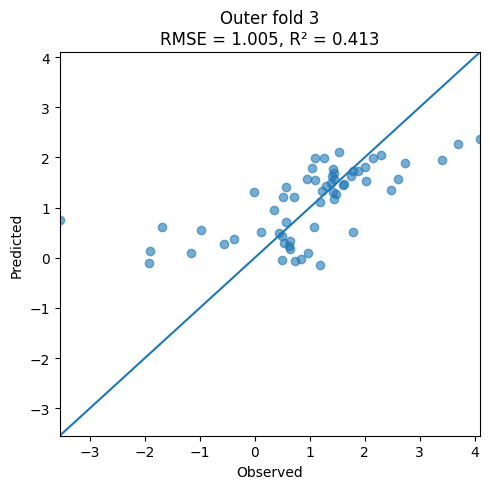

[I 2026-10-24 09:00:55,635] A new study created in memory with name: no-name-e75248c9-72e3-437f-951d-e006192ac13c


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_25_outerfold_03.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_25_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 09:00:57,395] Trial 0 finished with value: 0.9597212932460374 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9597212932460374.
[I 2026-10-24 09:00:58,329] Trial 1 finished with value: 1.0009754768360575 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9597212932460374.
[I 2026-10-24 09:00:59,074] Trial 2 finished with value: 1.0181722108482267 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9597212932460374.
[I 2026-10-24 09:00:59,858] Trial 3 finished with value: 0.9527805684180548 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 4/5 RMSE = 0.7691 R2 = 0.4705


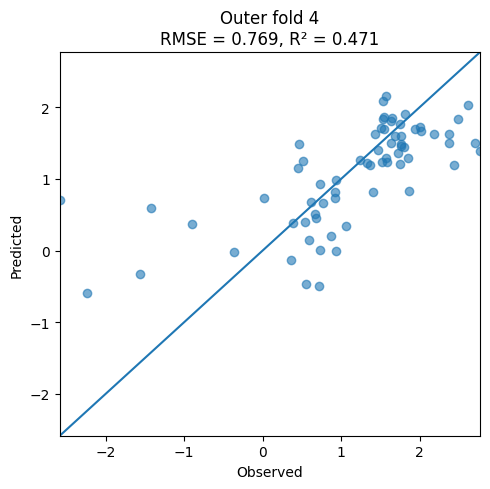

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_25_outerfold_04.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_25_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_LEFT_VRU' 'EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 09:02:57,624] A new study created in memory with name: no-name-2c2a366a-6f89-40c6-b676-ce468b18c888
[I 2026-10-24 09:02:59,009] Trial 0 finished with value: 0.950465144867118 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.950465144867118.
[I 2026-10-24 09:03:00,279] Trial 1 finished with value: 0.9900792312071374 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.950465144867118.
[I 2026-10-24 09:03:00,987] Trial 2 finished with value: 0.9688168064041194 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.95046514486

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 5/5 RMSE = 0.8019 R2 = 0.3517


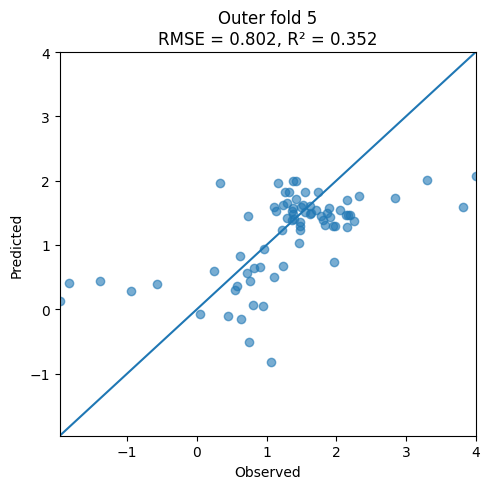

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_25_outerfold_05.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_25_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8719 (+/- 0.1016)
Mean R2 (Outer CV): 0.4059 (+/- 0.0404)
Updated results: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGBR_combineTW_rate.xlsx
[0, 26]


[I 2026-10-24 09:05:07,435] A new study created in memory with name: no-name-33a35a07-b9d8-43a3-bd9f-619af5145a9d


Resuming from existing file. Found 870 previous runs.
Running rs=786, targetTW=26
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 09:05:08,600] Trial 0 finished with value: 0.9232970311730333 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9232970311730333.
[I 2026-10-24 09:05:09,510] Trial 1 finished with value: 0.917359205913223 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 1 with value: 0.917359205913223.
[I 2026-10-24 09:05:10,292] Trial 2 finished with value: 0.9418372577175653 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 1 with value: 0.917359205913223.
[I 2026-10-24 09:05:11,060] Trial 3 finished with value: 0.9152636610557343 and parameters: {'max_depth': 3

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 1/5 RMSE = 1.0074 R2 = 0.3915


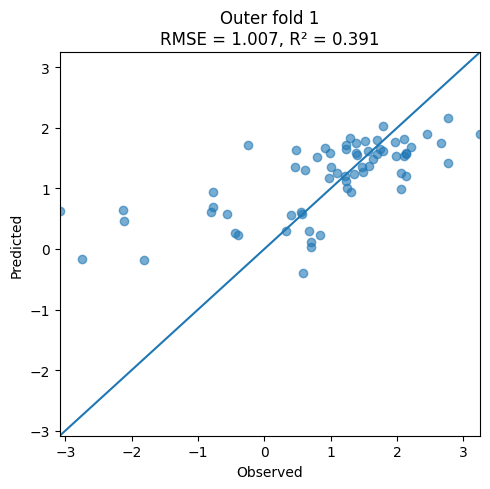

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_26_outerfold_01.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_26_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['F' 'M']
Fold 2 - automation levels in train: [1 2]


[I 2026-10-24 09:07:11,160] A new study created in memory with name: no-name-9ca05bc3-51b7-4d62-9b13-6ed0e3b7bdd4


Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 09:07:13,363] Trial 0 finished with value: 0.9216192661615208 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9216192661615208.
[I 2026-10-24 09:07:14,689] Trial 1 finished with value: 0.9633733018712956 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9216192661615208.
[I 2026-10-24 09:07:16,978] Trial 2 finished with value: 0.9639496312049058 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9216192661615208.
[I 2026-10-24 09:07:18,943] Trial 3 finished with value: 0.9583962609975967 and parameters: {'max_depth'

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 2/5 RMSE = 0.8112 R2 = 0.3554


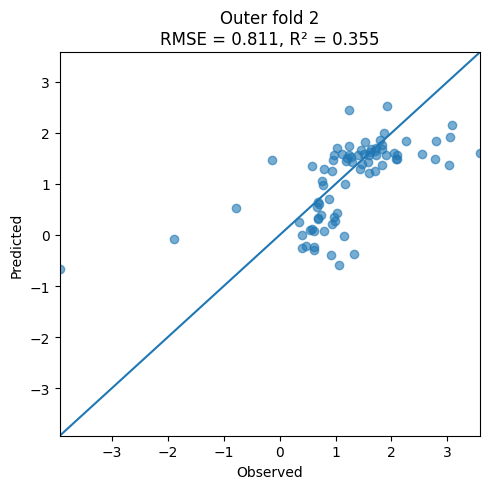

[I 2026-10-24 09:09:13,894] A new study created in memory with name: no-name-f355b9c0-801d-4292-91ff-f949d85d7345


Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_26_outerfold_02.json
Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_26_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 09:09:17,520] Trial 0 finished with value: 0.930573418650958 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.930573418650958.
[I 2026-10-24 09:09:18,543] Trial 1 finished with value: 0.9921014945082716 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.930573418650958.
[I 2026-10-24 09:09:19,246] Trial 2 finished with value: 0.9495289316720752 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.930573418650958.
[I 2026-10-24 09:09:20,011] Trial 3 finished with value: 0.9299232354282794 and parameters: {'max_depth': 3,

/content/drive/MyDrive/Colab_Backups/Revision1/Data.xlsx | Outer fold 3/5 RMSE = 0.9651 R2 = 0.4589


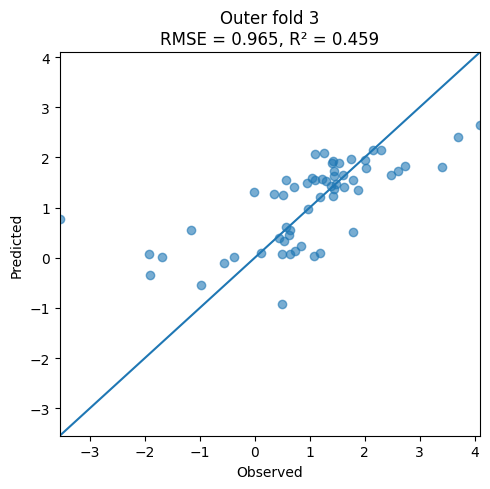

Saved model: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_26_outerfold_03.json


[I 2026-10-24 09:11:29,669] A new study created in memory with name: no-name-9ae8a29f-9086-4056-bfa1-cde61e49fb16


Saved metadata: /content/drive/MyDrive/Colab_Backups/Revision1/results/XGBR/XGB_model_combineTW_rate/xgb_seed_786_TW_26_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-10-24 09:11:31,835] Trial 0 finished with value: 0.9310658771771296 and parameters: {'max_depth': 4, 'gamma': 1.9014286128198323, 'learning_rate': 0.22629833399813637, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.3670139803318274}. Best is trial 0 with value: 0.9310658771771296.
[I 2026-10-24 09:11:32,752] Trial 1 finished with value: 1.020762000790089 and parameters: {'max_depth': 2, 'gamma': 0.11616722433639892, 'learning_rate': 0.26319844008810717, 'subsample': 0.8005575058716043, 'colsample_bytree': 0.7810544333470342}. Best is trial 0 with value: 0.9310658771771296.
[I 2026-10-24 09:11:33,446] Trial 2 finished with value: 1.0036159556404352 and parameters: {'max_depth': 2, 'gamma': 1.9398197043239886, 'learning_rate': 0.25392172622011594, 'subsample': 0.6061695553391381, 'colsample_bytree': 0.38636872540532546}. Best is trial 0 with value: 0.9310658771771296.
[I 2026-10-24 09:11:34,275] Trial 3 finished with value: 0.9404571039238977 and parameters: {'max_depth':

In [ ]:
import json
import os
import re
import hashlib
import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

def save_results(rows, path):
    df_res = pd.DataFrame(rows)

    df_res = df_res.drop_duplicates(
        subset=["dataName", "seed","TW", "outer_fold"],
        keep="last"
    )
    df_res.to_excel(path, index=False)

def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df = test_df.copy()

    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col] = test_df[col].astype(dtype)

    return train_df, test_df


def add_rate_features(df, tws):
    """Express count features per second: fixRate_{TW}, blinkRate_{TW}.
    TW 0 (hazard-visibility window) varies in length -> divide by its measured duration.
    TW 1-30 (pre-visibility windows) last exactly TW seconds -> divide by TW."""
    for tw in tws:
        if tw == 0:
            dur = pd.to_numeric(df[DUR_COL_TW0], errors="coerce")
            dur = dur.where(dur > 0)
        else:
            dur = float(tw)
        for count_col, rate_col in [("fixNumber", "fixRate"), ("blinkNumber", "blinkRate")]:
            df[f"{rate_col}_{tw}"] = pd.to_numeric(df[f"{count_col}_{tw}"], errors="coerce") / dur
    return df


# ---- Paths----
REV_DIR = ".."
dataName   = os.path.join(REV_DIR, "data", "Data.xlsx")
DUR_COL_TW0 = "epochDuration_0_x"

for rs in [
    # 261,452,
    285,966,786,
    # 1423,3789, 5602, 8741, 11905
    ]:

    twType = "combineTW"
    TW_comb = [[0,x] for x in range(1,31)]

    # twType = "singleTW"
    # TW_comb = [[x] for x in range(1,31)]

    for TWs in TW_comb:
      print(TWs)
      if len(TWs)>1:
        targetTW = TWs[1]
      else:
        targetTW = TWs[0]

      # Data Setup
      df = pd.read_excel(dataName)
      df = add_rate_features(df, TWs)
      BASE_DIR = os.path.join(REV_DIR, "results", "XGBR")
      os.makedirs(BASE_DIR, exist_ok=True)
      results_path = os.path.join(BASE_DIR, f"XGBR_{twType}_rate.xlsx")
      modelDirectory = f"XGB_model_{twType}_rate"

      if os.path.exists(results_path):
            results_df = pd.read_excel(results_path)
            results_rows = results_df.to_dict('records')
            print(f"Resuming from existing file. Found {len(results_rows)} previous runs.")
      else:
            results_df = pd.DataFrame(columns=["seed", "TW"])
            results_rows = []

      if not results_df.empty:
            existing = (
                (results_df["seed"] == rs) &
                (results_df["TW"] == targetTW)
            )

            if existing.any():
                print(f"Skipping rs={rs}, targetTW={targetTW} because it already exists.")
                continue

      print(f"Running rs={rs}, targetTW={targetTW}")

      outer_splits, inner_splits, n_trials = 5, 4, 100
      target_col = "RT"
      cat_names = ["Gender", "automation", "eventType"]

      TW_list = TWs

      feature_templates = [
          "Age",
          "License",
          "Mileage",
          "Gender",
          "automation", "eventType",
          "visibleSpeed",

          "pdMean_{TW}", "pdSd_{TW}",
          "blinkRate_{TW}",
          "avgBlinkDuration_{TW}",

          "fixRate_{TW}",
          "avgFixDuration_{TW}",


          "fixTE_{TW}", "fixSE_{TW}",
          "FixDisperX_{TW}", "FixDisperY_{TW}",
          "FixDisperE_{TW}",
          "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",

      ]

      feature_cols = []
      for c in feature_templates:
          feature_cols.extend([c.format(TW=tw) for tw in TW_list] if "{TW}" in c else [c])

      cont_names = [c for c in feature_cols if c not in cat_names]

      tww_cols = [f"perValid_{i}" for i in range(31)]

      pervalid_mean = df[tww_cols].mean(axis=1)

      abandon_mask = pervalid_mean < 74.5
      keep_mask = ~abandon_mask

      df = df[keep_mask].copy()

      X = df[feature_cols].copy()
      y = pd.to_numeric(df[target_col], errors="coerce").values.astype(float)
      groups = df["subNumber"].values

      outer_cv = GroupKFold(
          n_splits=outer_splits,
          shuffle=True,
          random_state=rs
      )

      outer_scores = []
      outer_RMSE = []
      oof_pred = np.full_like(y, fill_value=-1)
      oof_fold = np.full(len(y), -1, dtype=int)

      all_fold_best_vars = []

      outer_best_params = []
      outer_R2 = []
      fold_rows = []

      print(f'len(df)={len(df)}')

      for outer_fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y, groups), start=1):


          print(f"\n=== Outer fold {outer_fold}/{outer_splits} ===")

          X_out_train = X.iloc[train_idx].copy()
          y_out_train = y[train_idx]
          groups_out_tr = groups[train_idx]

          X_out_test = X.iloc[test_idx].copy()
          y_out_test = y[test_idx]

          to_drop_fold = []

          for col in cat_names:
              if col in X_out_train.columns:
                  print(f"Fold {outer_fold} - {col} levels in train:",
                        X_out_train[col].unique())


          fold_vars = [c for c in feature_cols if c not in to_drop_fold]
          fold_cont = [c for c in fold_vars if c in cont_names]
          fold_cat = [c for c in fold_vars if c in cat_names]

          print(f"  > [TW-Filter] Dropped {len(to_drop_fold)} smaller windows. {len(fold_vars)} variables remain.")

          current_vars = fold_vars[:]
          best_vars = current_vars

          X_out_train_oh, X_out_test_oh = ensure_categorical_dtype_from_train(
                X_out_train[best_vars],
                X_out_test[best_vars],
                cat_names
            )

          def objective(trial):

              p = {
                  "n_estimators":  200,
                  "max_depth": trial.suggest_int("max_depth", 2, 7),
                  "gamma": trial.suggest_float("gamma", 0.0, 2.0),
                  "learning_rate": trial.suggest_float("learning_rate", 0.025, 0.3),
                  "subsample": trial.suggest_float("subsample", 0.5, 1.0),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.25, 1.0),
                  "tree_method": "hist",
                  "random_state": 42,
                  "n_jobs": -1,
                  "enable_categorical": True,
                  "objective": "reg:squarederror",
              }


              cv_opt = GroupKFold(
                  n_splits=inner_splits,
                  shuffle=True,
                  random_state=123
              )
              scores = []

              for t_i, v_i in cv_opt.split(X_out_train_oh, y_out_train, groups_out_tr):

                  X_tr_opt = X_out_train_oh.iloc[t_i].copy()
                  X_val_opt = X_out_train_oh.iloc[v_i].copy()

                  y_tr = y_out_train[t_i]
                  y_val = y_out_train[v_i]

                  m = XGBRegressor(**p)
                  m.fit(X_tr_opt, y_tr, verbose=False)

                  y_pred = m.predict(X_val_opt)

                  scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))

              return float(np.mean(scores))


          sampler = optuna.samplers.TPESampler(seed=42)
          study = optuna.create_study(direction="minimize", sampler=sampler)
          study.optimize(objective, n_trials=n_trials)

          best_trial = study.best_trial

          final_p = {
              **study.best_params,
              "n_estimators": 200,
              "tree_method": "hist",
              "random_state": 42,
              "n_jobs": -1,
              "enable_categorical": True,
              "objective": "reg:squarederror",
          }

          final_model = XGBRegressor(**final_p)
          outer_best_params.append(final_p)

          final_model.fit(X_out_train_oh, y_out_train)
          y_pred = final_model.predict(X_out_test_oh)


          outer_rmse = np.sqrt(mean_squared_error(y_out_test, y_pred))

          r2   = r2_score(y_out_test, y_pred)

          fold_rows.append({
              "dataName": dataName,
              "seed": rs,
              "TW": float(targetTW),
              "outer_fold": int(outer_fold),
              "RMSE": float(outer_rmse),
              "R2": float(r2),
          })

          plt.figure(figsize=(5, 5))
          plt.scatter(y_out_test, y_pred, alpha=0.6)
          outer_R2.append(r2)

          outer_scores.append(outer_rmse)

          print(f"{dataName} | Outer fold {outer_fold}/5 RMSE = {outer_rmse:.4f} R2 = {r2:.4f}")

          lims = [
              min(y_out_test.min(), y_pred.min()),
              max(y_out_test.max(), y_pred.max())
          ]
          plt.plot(lims, lims)
          plt.xlim(lims)
          plt.ylim(lims)

          plt.xlabel("Observed")
          plt.ylabel("Predicted")
          plt.title(
              f"Outer fold {outer_fold}\n"
              f"RMSE = {outer_rmse:.3f}, R² = {r2:.3f}"
          )

          plt.tight_layout()
          plt.show()

          MODEL_DIR = os.path.join(BASE_DIR, modelDirectory)
          os.makedirs(MODEL_DIR, exist_ok=True)

          model_path = os.path.join(MODEL_DIR, f"xgb_seed_{rs:02d}_TW_{targetTW:02d}_outerfold_{outer_fold:02d}.json")
          final_model.get_booster().save_model(model_path)
          print("Saved model:", model_path)


          meta = {
              "seed": rs,
              "TW": targetTW,
              "outer_fold": outer_fold,
              "best_params": final_p,
              "best_score_inner_cv": study.best_value,
              "selected_features": best_vars
          }

          meta_path = model_path.replace(".json", "_meta.json")

          with open(meta_path, "w") as f:
              json.dump(meta, f, indent=4)

          print("Saved metadata:", meta_path)


      print(f"\n===== FINAL RESULTS SUMMARY =====")
      print(f"Mean RMSE (Outer CV): {np.mean(outer_scores):.4f} (+/- {np.std(outer_scores):.4f})")
      print(f"Mean R2 (Outer CV): {np.mean(outer_R2):.4f} (+/- {np.std(outer_R2):.4f})")


      results_rows.extend(fold_rows)


      summary_row = {
          "dataName": dataName,
          "seed": rs,
          "TW": float(targetTW),
          "outer_fold": "SUMMARY",
          "RMSE": float(np.mean(outer_scores)),
          "R2": float(np.mean(outer_R2)),
          "std_RMSE": float(np.std(outer_scores)),
          "std_R2": float(np.std(outer_R2)),
      }
      results_rows.append(summary_row)

      save_results(results_rows, results_path)
      print(f"Updated results: {results_path}")

# Classification with TTC-based label

## LRC

In [ ]:
import json
import os
import numpy as np
import pandas as pd
import optuna
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import  roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import joblib

def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()

    use_cat = [c for c in cat_cols if c in X_train_raw.columns]

    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)

    X_train_oh = pd.get_dummies(
        X_train_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = pd.get_dummies(
        X_test_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)

    X_train_oh = X_train_oh.astype(np.float32)
    X_test_oh = X_test_oh.astype(np.float32)

    return X_train_oh, X_test_oh


def save_results(rows, path):
    df_res = pd.DataFrame(rows)

    df_res = df_res.drop_duplicates(
        subset=["dataName", "seed","TW", "outer_fold"],
        keep="last"
    )
    df_res.to_excel(path, index=False)


def add_rate_features(df, tws):
    """Express count features per second: fixRate_{TW}, blinkRate_{TW}.
    TW 0 (hazard-visibility window) varies in length -> divide by its measured duration.
    TW 1-30 (pre-visibility windows) last exactly TW seconds -> divide by TW."""
    for tw in tws:
        if tw == 0:
            dur = pd.to_numeric(df[DUR_COL_TW0], errors="coerce")
            dur = dur.where(dur > 0)
        else:
            dur = float(tw)
        for count_col, rate_col in [("fixNumber", "fixRate"), ("blinkNumber", "blinkRate")]:
            df[f"{rate_col}_{tw}"] = pd.to_numeric(df[f"{count_col}_{tw}"], errors="coerce") / dur
    return df


# ---- Paths ----
from google.colab import drive
drive.mount('/content/drive')

REV_DIR = ".."
dataName   = os.path.join(REV_DIR, "data", "Data.xlsx")
SEEDS_PATH = os.path.join(REV_DIR, "analysis", "seeds.xlsx")
DUR_COL_TW0 = "epochDuration_0_x"

TTC_COL = "RT_TTCnew"
TTC_THRESHOLD = 1.31
LABEL_COL = "TTC_cls"

inner_seeds = pd.read_excel(SEEDS_PATH)

for rs in [
        3558,
        6687,
          6836,
          7862, 11033,
          13285, 22075, 22163, 23858,
        30690
          ]:

  # TW_comb = [[0,x] for x in range(1,31)]
  # twType = "combineTW"

  TW_comb = [[x] for x in range(1,31)]
  twType = "singleTW"


  for TWs in TW_comb:

    print(TWs)

    if len(TWs)>1:

      targetTW = TWs[1]

    else:
      targetTW = TWs[0]

    df = pd.read_excel(dataName)
    df = add_rate_features(df, TWs)

    BASE_DIR = os.path.join(REV_DIR, "results_TTC", "LRC")
    os.makedirs(BASE_DIR, exist_ok=True)

    results_path = os.path.join(BASE_DIR, f"LRC_{twType}_rate.xlsx")
    modelDirectory = f"LRC_model_{twType}_rate"
    oof_path = os.path.join(BASE_DIR, f"LRC_{twType}_rate_oof.xlsx")

    if os.path.exists(results_path):
        results_df = pd.read_excel(results_path)
        results_rows = results_df.to_dict('records')
        print(f"Resuming from existing file. Found {len(results_rows)} previous runs.")
    else:
        results_df = pd.DataFrame(columns=["seed", "TW"])
        results_rows = []

    if not results_df.empty:
        existing = (
            (results_df["seed"] == rs) &
            (results_df["TW"] == targetTW)
        )

        if existing.any():
            print(f"Skipping rs={rs}, targetTW={targetTW} because it already exists.")
            continue


    print(f"Running rs={rs}, targetTW={targetTW}")


    outer_splits, inner_splits, n_trials = 5, 4, 100

    target_col = "RT"

    cat_names = ["Gender", "automation", "eventType"]

    TW_list = TWs

    feature_templates = [
        "Age",
        "License",
        "Mileage",
        "Gender",
        "automation", "eventType",
        "visibleSpeed",

        "pdMean_{TW}", "pdSd_{TW}",
        "blinkRate_{TW}",
        "avgBlinkDuration_{TW}",

        "fixRate_{TW}",
        "avgFixDuration_{TW}",

        "fixTE_{TW}", "fixSE_{TW}",
        "FixDisperX_{TW}", "FixDisperY_{TW}",
        "FixDisperE_{TW}",
        "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",

    ]

    feature_cols = []
    for c in feature_templates:
        feature_cols.extend([c.format(TW=tw) for tw in TW_list] if "{TW}" in c else [c])

    cont_names = [c for c in feature_cols if c not in cat_names]


    print(f'len(df)={len(df)}')

    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
    df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

    df[TTC_COL] = pd.to_numeric(df[TTC_COL], errors="coerce")
    n_ttc_missing = df[TTC_COL].isna().sum()
    df = df.dropna(subset=[TTC_COL]).copy()
    print(f"Dropped {n_ttc_missing} trials with missing {TTC_COL}")
    df[LABEL_COL] = (df[TTC_COL].round(2) < TTC_THRESHOLD).astype(int)

    tww_cols = [f"perValid_{i}" for i in range(31)]

    pervalid_mean = df[tww_cols].mean(axis=1)

    abandon_mask = pervalid_mean < 74.5
    keep_mask = ~abandon_mask

    df = df[keep_mask].copy()

    print("Positive trials (TTC_cls = 1) per event type after gaze filter:")
    print(df.groupby("eventType")[LABEL_COL].agg(["sum", "count"]))

    X = df[feature_cols].copy()
    y = df[LABEL_COL].values.astype(int)

    groups = df["subNumber"].values

    y_strat = y.copy()


    outer_cv = StratifiedGroupKFold(
        n_splits=outer_splits,
        shuffle=True,
        random_state=rs
    )

    outer_AUC = []
    outer_best_params = []

    oof_fold = np.full(len(y), -1, dtype=int)
    oof_proba = np.full(len(y), np.nan)

    fold_rows = []

    for outer_fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y_strat, groups), start=1):


        X_out_train = X.iloc[train_idx].copy()
        y_out_train = y[train_idx]
        groups_out_tr = groups[train_idx]

        X_out_test = X.iloc[test_idx].copy()
        y_out_test = y[test_idx]

        print(f"\n=== Outer fold {outer_fold}/{outer_splits} ===")

        print("Class counts:")
        print(pd.Series(y_out_test).value_counts().sort_index())
        print("Class proportions:")
        print(pd.Series(y_out_test).value_counts(normalize=True).sort_index())

        to_drop_fold = []

        for col in cat_names:
            if col in X_out_train.columns:
                print(f"Fold {outer_fold} - {col} levels in train:",
                      X_out_train[col].unique())


        fold_vars = [c for c in feature_cols if c not in to_drop_fold]

        print(f"  > [TW-Filter] Dropped {len(to_drop_fold)} smaller windows. {len(fold_vars)} variables remain.")

        current_vars = fold_vars[:]
        best_vars = current_vars

        print(f"\nOuter fold {outer_fold}")
        print("Inner class counts:")
        print(pd.Series(y_out_train.copy()).value_counts().sort_index())
        print("Inner class proportions:")
        print(pd.Series(y_out_train.copy()).value_counts(normalize=True).sort_index())

        X_out_train_oh, X_out_test_oh = fit_outer_onehot(
            X_out_train[best_vars],
            X_out_test[best_vars],
            cat_names
        )
        lookup = inner_seeds[
            (inner_seeds["outer_seed"] == rs) &
            (inner_seeds["outer_fold_idx"] == (outer_fold - 1))
        ]

        if lookup.empty:
            raise ValueError(
                f"No accepted inner seed found for outer_seed={rs}, outer_fold_idx={outer_fold - 1}"
            )

        if len(lookup) > 1:
            raise ValueError(
                f"Multiple matching inner seeds found for outer_seed={rs}, outer_fold_idx={outer_fold - 1}"
            )

        selected_inner_seed = int(lookup["inner_seed"].iloc[0])

        print(
            f"Using accepted_inner_seed={selected_inner_seed} "
            f"for outer_seed={rs}, outer_fold={outer_fold}"
        )

        print("\nSelected inner seed:")
        print(selected_inner_seed)


        def objective(trial):

            C = trial.suggest_float("C", 1e-4, 10.0, log=True)

            cv_opt = StratifiedGroupKFold(
                n_splits=inner_splits,
                shuffle=True,
                random_state=selected_inner_seed
            )

            inner_scores = []

            for t_i, v_i in cv_opt.split(X_out_train_oh, y_out_train, groups_out_tr):


              X_tr = X_out_train_oh.iloc[t_i].copy()
              X_val = X_out_train_oh.iloc[v_i].copy()
              y_tr = y_out_train[t_i]
              y_val = y_out_train[v_i]

              imputer = SimpleImputer(strategy="median")
              X_tr = pd.DataFrame(
                  imputer.fit_transform(X_tr),
                  columns=X_tr.columns,
                  index=X_tr.index
              )
              X_val = pd.DataFrame(
                  imputer.transform(X_val),
                  columns=X_val.columns,
                  index=X_val.index
              )

              scaler = StandardScaler()
              X_tr = pd.DataFrame(
                  scaler.fit_transform(X_tr),
                  columns=X_tr.columns,
                  index=X_tr.index
              )
              X_val = pd.DataFrame(
                  scaler.transform(X_val),
                  columns=X_val.columns,
                  index=X_val.index
              )

              model = LogisticRegression(
                  penalty="l1",
                  solver="liblinear",
                  C=C,
                  max_iter=1000,
                  class_weight="balanced",
                  random_state=42,
              )

              model.fit(X_tr, y_tr)

              y_prob = model.predict_proba(X_val)[:, 1]
              inner_scores.append(roc_auc_score(y_val, y_prob))

            return float(np.mean(inner_scores))


        sampler = optuna.samplers.TPESampler(seed=42)
        study = optuna.create_study(direction="maximize", sampler=sampler)
        study.optimize(objective, n_trials=n_trials)

        imputer = SimpleImputer(strategy="median")
        X_out_train_oh = pd.DataFrame(
            imputer.fit_transform(X_out_train_oh),
            columns=X_out_train_oh.columns,
            index=X_out_train_oh.index
        )
        X_out_test_oh = pd.DataFrame(
            imputer.transform(X_out_test_oh),
            columns=X_out_test_oh.columns,
            index=X_out_test_oh.index
        )

        scaler = StandardScaler()
        X_out_train_oh = pd.DataFrame(
            scaler.fit_transform(X_out_train_oh),
            columns=X_out_train_oh.columns,
            index=X_out_train_oh.index
        )
        X_out_test_oh = pd.DataFrame(
            scaler.transform(X_out_test_oh),
            columns=X_out_test_oh.columns,
            index=X_out_test_oh.index
        )
        final_p = {
            "penalty": "l1",
            "solver": "liblinear",
            "C": study.best_params["C"],
            "max_iter": 1000,
            "class_weight": "balanced",
            "random_state": 42,
        }

        final_model = LogisticRegression(
            **final_p
        )

        final_model.fit(X_out_train_oh, y_out_train)
        outer_best_params.append(final_p)


        y_prob = final_model.predict_proba(X_out_test_oh)[:, 1]

        oof_fold[test_idx] = outer_fold
        oof_proba[test_idx] = y_prob


        if np.unique(y_out_test).size == 2:
            outer_auc = roc_auc_score(y_out_test, y_prob)
        else:
            outer_auc = np.nan


        outer_AUC.append(outer_auc)
        event_auc_dict = {}
        event_test = df.iloc[test_idx]["eventType"].values

        for ev in np.unique(event_test):
            mask = event_test == ev

            y_true_ev = y_out_test[mask]
            y_prob_ev = y_prob[mask]

            if np.unique(y_true_ev).size == 2:
                ev_auc = roc_auc_score(y_true_ev, y_prob_ev)
            else:
                ev_auc = np.nan

            event_auc_dict[ev] = ev_auc


        fold_row = {
            "dataName": dataName,
            "seed": rs,
            "TW": float(targetTW),
            "outer_fold": int(outer_fold),
            "AUC": float(outer_auc),
            "n_test": int(len(test_idx)),
            "n_pos_test": int(np.sum(y_out_test == 1)),
            "n_neg_test": int(np.sum(y_out_test == 0)),
        }

        for ev, ev_auc in event_auc_dict.items():
            fold_row[f"AUC_event_{ev}"] = ev_auc

        fold_rows.append(fold_row)


        print(f"{dataName} | Outer fold {outer_fold}/5 AUC = {outer_auc:.4f}")


        MODEL_DIR = os.path.join(BASE_DIR, modelDirectory)
        os.makedirs(MODEL_DIR, exist_ok=True)

        model_path = os.path.join(MODEL_DIR, f"lr_seed_{rs:02d}_TW_{targetTW:02d}_outerfold_{outer_fold:02d}.joblib")
        joblib.dump(
            {
                "model": final_model,
                "imputer": imputer,
                "scaler": scaler,
                "feature_names": list(X_out_train_oh.columns)
            },
            model_path
        )
        print("Saved model:", model_path)


        meta = {
            "seed": rs,
            "TW": targetTW,
            "outer_fold": outer_fold,
            "best_params": final_p,
            "best_score_inner_cv": study.best_value,
            "selected_features": best_vars
        }

        meta_path = model_path.replace(".joblib", "_meta.json")

        with open(meta_path, "w") as f:
            json.dump(meta, f, indent=4)

        print("Saved metadata:", meta_path)


    print(f"\n===== FINAL RESULTS SUMMARY =====")
    print(f"Mean AUC (Outer CV): {np.mean(outer_AUC):.4f} (+/- {np.std(outer_AUC):.4f})")

    results_rows.extend(fold_rows)

    summary_row = {
        "dataName": dataName,
        "seed": rs,
        "TW": float(targetTW),
        "outer_fold": "SUMMARY",
        "AUC": float(np.mean(outer_AUC)),
        "std_AUC": float(np.std(outer_AUC)),
    }

    results_rows.append(summary_row)

    save_results(results_rows, results_path)
    print(f"Updated results: {results_path}")

    id_cols = [c for c in ["subNumber", "runNumber", "section", "eventType", "automation"] if c in df.columns]
    oof_df = df[id_cols].copy()
    oof_df["seed"] = rs
    oof_df["TW"] = targetTW
    oof_df["y_true"] = y
    oof_df["outer_fold"] = oof_fold
    oof_df["oof_proba"] = oof_proba
    if os.path.exists(oof_path):
        prev = pd.read_excel(oof_path)
        prev = prev[~((prev["seed"] == rs) & (prev["TW"] == targetTW))]
        oof_df = pd.concat([prev, oof_df], ignore_index=True)
    oof_df.to_excel(oof_path, index=False)
    print(f"Updated OOF predictions: {oof_path}")

## XGBC

In [ ]:
import json
import os
import numpy as np
import pandas as pd
import optuna
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

def save_results(rows, path):
    df_res = pd.DataFrame(rows)
    df_res = df_res.drop_duplicates(
        subset=["dataName", "seed", "TW", "outer_fold"],
        keep="last"
    )
    df_res.to_excel(path, index=False)

def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df = test_df.copy()

    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col] = test_df[col].astype(dtype)

    return train_df, test_df


def add_rate_features(df, tws):
    """Express count features per second: fixRate_{TW}, blinkRate_{TW}.
    TW 0 (hazard-visibility window) varies in length -> divide by its measured duration.
    TW 1-30 (pre-visibility windows) last exactly TW seconds -> divide by TW."""
    for tw in tws:
        if tw == 0:
            dur = pd.to_numeric(df[DUR_COL_TW0], errors="coerce")
            dur = dur.where(dur > 0)
        else:
            dur = float(tw)
        for count_col, rate_col in [("fixNumber", "fixRate"), ("blinkNumber", "blinkRate")]:
            df[f"{rate_col}_{tw}"] = pd.to_numeric(df[f"{count_col}_{tw}"], errors="coerce") / dur
    return df


# ---- Paths ----
from google.colab import drive
drive.mount('/content/drive')

REV_DIR = ".."
dataName   = os.path.join(REV_DIR, "data", "Data.xlsx")
SEEDS_PATH = os.path.join(REV_DIR, "analysis", "seeds.xlsx")
DUR_COL_TW0 = "epochDuration_0_x"

TTC_COL = "RT_TTCnew"
TTC_THRESHOLD = 1.31
LABEL_COL = "TTC_cls"

inner_seeds = pd.read_excel(SEEDS_PATH)


for rs in [
            3558,6687,6836,
            7862,
            11033,
            13285,
            22075,
            22163,
            23858, 30690
            ]:

    # TW_comb = [[0,x] for x in range(1,31)]
    # twType = "combineTW"

    twType = "singleTW"
    TW_comb = [[x] for x in range(1,31)]

    for TWs in TW_comb:

      print(TWs)

      if len(TWs)>1:

        targetTW = TWs[1]

      else:
        targetTW = TWs[0]


      df = pd.read_excel(dataName)
      df = add_rate_features(df, TWs)

      BASE_DIR = os.path.join(REV_DIR, "results_TTC", "XGBC")
      os.makedirs(BASE_DIR, exist_ok=True)

      results_path = os.path.join(BASE_DIR, f"XGBC_{twType}_rate.xlsx")
      modelDirectory = f"XGB_model_{twType}_rate"
      oof_path = os.path.join(BASE_DIR, f"XGBC_{twType}_rate_oof.xlsx")

      if os.path.exists(results_path):
          results_df = pd.read_excel(results_path)
          results_rows = results_df.to_dict('records')
          print(f"Resuming from existing file. Found {len(results_rows)} previous runs.")
      else:
          results_df = pd.DataFrame(columns=["seed", "TW"])
          results_rows = []

      if not results_df.empty:
          existing = (
              (results_df["seed"] == rs) &
              (results_df["TW"] == targetTW)
          )

          if existing.any():
              print(f"Skipping rs={rs}, targetTW={targetTW} because it already exists.")
              continue

      print(f"Running rs={rs}, targetTW={targetTW}")

      outer_splits, inner_splits, n_trials = 5, 4, 100
      target_col = "RT"
      cat_names = ["Gender", "automation", "eventType"]
      TW_list = TWs
      feature_templates = [
          "Age",
          "License",
          "Mileage",
          "Gender",
          "automation", "eventType",
          "visibleSpeed",

          "pdMean_{TW}", "pdSd_{TW}",
          "blinkRate_{TW}",
          "avgBlinkDuration_{TW}",

          "fixRate_{TW}",
          "avgFixDuration_{TW}",

          "fixTE_{TW}", "fixSE_{TW}",
          "FixDisperX_{TW}", "FixDisperY_{TW}",
          "FixDisperE_{TW}",
          "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",

      ]

      feature_cols = []
      for c in feature_templates:
          feature_cols.extend([c.format(TW=tw) for tw in TW_list] if "{TW}" in c else [c])

      cont_names = [c for c in feature_cols if c not in cat_names]


      print(f'len(df)={len(df)}')

      df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
      df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

      df[TTC_COL] = pd.to_numeric(df[TTC_COL], errors="coerce")
      n_ttc_missing = df[TTC_COL].isna().sum()
      df = df.dropna(subset=[TTC_COL]).copy()
      print(f"Dropped {n_ttc_missing} trials with missing {TTC_COL}")
      df[LABEL_COL] = (df[TTC_COL].round(2) < TTC_THRESHOLD).astype(int)

      tww_cols = [f"perValid_{i}" for i in range(31)]

      pervalid_mean = df[tww_cols].mean(axis=1)

      abandon_mask = pervalid_mean < 74.5
      keep_mask = ~abandon_mask

      df = df[keep_mask].copy()

      X = df[feature_cols].copy()
      print("Positive trials (TTC_cls = 1) per event type after gaze filter:")
      print(df.groupby("eventType")[LABEL_COL].agg(["sum", "count"]))

      y = df[LABEL_COL].values.astype(int)

      groups = df["subNumber"].values

      y_strat = y.copy()


      outer_cv = StratifiedGroupKFold(
          n_splits=outer_splits,
          shuffle=True,
          random_state=rs
      )

      outer_AUC = []
      outer_best_params = []
      fold_rows = []
      oof_fold = np.full(len(y), -1, dtype=int)
      oof_proba = np.full(len(y), np.nan)

      for outer_fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y_strat, groups), start=1):


          X_out_train = X.iloc[train_idx].copy()
          y_out_train = y[train_idx]
          groups_out_tr = groups[train_idx]

          X_out_test = X.iloc[test_idx].copy()
          y_out_test = y[test_idx]

          print(f"\n=== Outer fold {outer_fold}/{outer_splits} ===")

          print("Class counts:")
          print(pd.Series(y_out_test).value_counts().sort_index())
          print("Class proportions:")
          print(pd.Series(y_out_test).value_counts(normalize=True).sort_index())

          to_drop_fold = []

          for col in cat_names:
              if col in X_out_train.columns:
                  print(f"Fold {outer_fold} - {col} levels in train:",
                        X_out_train[col].unique())


          fold_vars = [c for c in feature_cols if c not in to_drop_fold]

          print(f"  > [TW-Filter] Dropped {len(to_drop_fold)} smaller windows. {len(fold_vars)} variables remain.")

          current_vars = fold_vars[:]
          best_vars = current_vars

          n_pos = np.sum(y_out_train == 1)
          n_neg = np.sum(y_out_train == 0)
          scale_pos_weight = n_neg / n_pos if n_pos > 0 else 1.0

          print(f"Scale pos weight: {scale_pos_weight}")

          print(f"\nOuter fold {outer_fold}")
          print("Inner class counts:")
          print(pd.Series(y_out_train.copy()).value_counts().sort_index())
          print("Inner class proportions:")
          print(pd.Series(y_out_train.copy()).value_counts(normalize=True).sort_index())

          X_out_train_oh, X_out_test_oh = ensure_categorical_dtype_from_train(
              X_out_train[best_vars],
              X_out_test[best_vars],
              cat_names
          )

          lookup = inner_seeds[
              (inner_seeds["outer_seed"] == rs) &
              (inner_seeds["outer_fold_idx"] == (outer_fold - 1))
          ]

          if lookup.empty:
              raise ValueError(
                  f"No accepted inner seed found for outer_seed={rs}, outer_fold_idx={outer_fold - 1}"
              )

          if len(lookup) > 1:
              raise ValueError(
                  f"Multiple matching inner seeds found for outer_seed={rs}, outer_fold_idx={outer_fold - 1}"
              )

          seed_col = "accepted_inner_seed" if "accepted_inner_seed" in lookup.columns else "inner_seed"
          selected_inner_seed = int(lookup[seed_col].iloc[0])

          print(
              f"Using accepted_inner_seed={selected_inner_seed} "
              f"for outer_seed={rs}, outer_fold={outer_fold}"
          )

          print("\nSelected inner seed:")
          print(selected_inner_seed)

          def objective(trial):

              p = {
                  "n_estimators": 200,

                  "max_depth": trial.suggest_int("max_depth", 2, 7),
                  "learning_rate": trial.suggest_float("learning_rate", 0.025, 0.3),

                  "gamma": trial.suggest_float("gamma", 0.0, 2.0),
                  "subsample": trial.suggest_float("subsample", 0.5, 1.0),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.25, 1.0),
                  "tree_method": "hist",
                  "random_state": 42,
                  "n_jobs": -1,
                  "enable_categorical": True,
                  "scale_pos_weight": scale_pos_weight,
                  "objective": "binary:logistic",
              }


              cv_opt = StratifiedGroupKFold(
                  n_splits=inner_splits,
                  shuffle=True,
                  random_state=selected_inner_seed
              )

              inner_scores=[]

              for t_i, v_i in cv_opt.split(X_out_train_oh, y_out_train, groups_out_tr):


                  X_tr_opt = X_out_train_oh.iloc[t_i].copy()
                  X_val_opt = X_out_train_oh.iloc[v_i].copy()

                  y_tr = y_out_train[t_i]
                  y_val = y_out_train[v_i]

                  m = XGBClassifier(**p)
                  m.fit(X_tr_opt, y_tr, verbose=False)

                  y_prob = m.predict_proba(X_val_opt)[:, 1]
                  inner_scores.append(roc_auc_score(y_val, y_prob))

              best_score = np.mean(inner_scores)

              return float(best_score)


          sampler = optuna.samplers.TPESampler(seed=42)
          study = optuna.create_study(direction="maximize", sampler=sampler)
          study.optimize(objective, n_trials=n_trials)

          final_p = {
              **study.best_params,
              "n_estimators": 200,
              "tree_method": "hist",
              "random_state": 42,
              "n_jobs": -1,
              "scale_pos_weight": scale_pos_weight,
              "objective": "binary:logistic",
              "enable_categorical": True,

          }

          final_model = XGBClassifier(**final_p)
          outer_best_params.append(final_p)

          final_model.fit(X_out_train_oh, y_out_train)

          y_prob = final_model.predict_proba(X_out_test_oh)[:, 1]

          oof_fold[test_idx] = outer_fold
          oof_proba[test_idx] = y_prob


          if np.unique(y_out_test).size == 2:
              outer_auc = roc_auc_score(y_out_test, y_prob)
          else:
              outer_auc = np.nan


          outer_AUC.append(outer_auc)

          event_auc_dict = {}
          event_test = df.iloc[test_idx]["eventType"].values

          for ev in np.unique(event_test):
              mask = event_test == ev

              y_true_ev = y_out_test[mask]
              y_prob_ev = y_prob[mask]

              # AUC
              if np.unique(y_true_ev).size == 2:
                  ev_auc = roc_auc_score(y_true_ev, y_prob_ev)
              else:
                  ev_auc = np.nan

              event_auc_dict[ev] = ev_auc

          fold_row = {
              "dataName": dataName,
              "seed": rs,
              "TW": float(targetTW),
              "outer_fold": int(outer_fold),
              "AUC": float(outer_auc),
              "n_test": int(len(test_idx)),
              "n_pos_test": int(np.sum(y_out_test == 1)),
              "n_neg_test": int(np.sum(y_out_test == 0)),
          }
          for ev, ev_auc in event_auc_dict.items():
              fold_row[f"AUC_event_{ev}"] = ev_auc
          fold_rows.append(fold_row)


          print(f"{dataName} | Outer fold {outer_fold}/5 AUC = {outer_auc:.4f}")


          MODEL_DIR = os.path.join(BASE_DIR, modelDirectory)
          os.makedirs(MODEL_DIR, exist_ok=True)

          model_path = os.path.join(MODEL_DIR, f"xgb_seed_{rs:02d}_TW_{targetTW:02d}_outerfold_{outer_fold:02d}.json")
          final_model.get_booster().save_model(model_path)
          print("Saved model:", model_path)


          meta = {
              "seed": rs,
              "TW": targetTW,
              "outer_fold": outer_fold,
              "best_params": final_p,
              "best_score_inner_cv": study.best_value,
              "selected_features": best_vars
          }

          meta_path = model_path.replace(".json", "_meta.json")

          with open(meta_path, "w") as f:
              json.dump(meta, f, indent=4)

          print("Saved metadata:", meta_path)


      print(f"\n===== FINAL RESULTS SUMMARY =====")
      print(f"Mean AUC (Outer CV): {np.mean(outer_AUC):.4f} (+/- {np.std(outer_AUC):.4f})")

      results_rows.extend(fold_rows)

      fold_df = pd.DataFrame(fold_rows)

      event_auc_cols = [c for c in fold_df.columns if c.startswith("AUC_event_")]
      event_auc_summary = {f"mean_{c}": fold_df[c].mean(skipna=True) for c in event_auc_cols}
      event_auc_summary.update({f"std_{c}": fold_df[c].std(skipna=True) for c in event_auc_cols})


      summary_row = {
          "dataName": dataName,
          "seed": rs,
          "TW": float(targetTW),
          "outer_fold": "SUMMARY",
          "AUC": float(np.mean(outer_AUC)),
          "std_AUC": float(np.std(outer_AUC)),
      }

      results_rows.append(summary_row)

      save_results(results_rows, results_path)
      print(f"Updated results: {results_path}")

      id_cols = [c for c in ["subNumber", "runNumber", "section", "eventType", "automation"] if c in df.columns]
      oof_df = df[id_cols].copy()
      oof_df["seed"] = rs
      oof_df["TW"] = targetTW
      oof_df["y_true"] = y
      oof_df["outer_fold"] = oof_fold
      oof_df["oof_proba"] = oof_proba
      if os.path.exists(oof_path):
          prev = pd.read_excel(oof_path)
          prev = prev[~((prev["seed"] == rs) & (prev["TW"] == targetTW))]
          oof_df = pd.concat([prev, oof_df], ignore_index=True)
      oof_df.to_excel(oof_path, index=False)
      print(f"Updated OOF predictions: {oof_path}")